
# Clasificación de OSNR Haciendo Nested Cross-Validation 5×5 + predicciones outer-fold (OOF) + SHAP + tiempo de inferencia (IQ Histograms)
## Primero para monitoreo asistido

## RDF 32GBd para clasificar OSNR CON CHANNEL SPACING

INFORMACIÓN DEL DATASET
Dataset: matriz32GBd_clasifi_correct.csv
Muestras: 9330
Características: 31
NORMAL: 5804
ALARMA: 3526
Umbral OSNR: 23.0 dB

Monitoreo asistido: channel_sp se utiliza como característica de entrada.

Combinaciones de hiperparámetros: 162

INICIANDO NESTED CV 5x5 - RANDOM FOREST

OUTER FOLD 1/5
Outer Train: 7464 muestras
Outer Test:  1866 muestras

Buscando mejores hiperparámetros...

Mejores hiperparámetros:
{'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 2, 'min_samples_split': 10, 'n_estimators': 400}
Inner CV Best F1: 0.8552

MÉTRICAS OUTER FOLD:
Accuracy:    0.8880
Precision:   0.8875
Recall:      0.8057
F1:          0.8446
Specificity: 0.9380
Inference Mean: 23.613 µs/muestra
Inference Std:  0.236 µs/muestra

OUTER FOLD 2/5
Outer Train: 7464 muestras
Outer Test:  1866 muestras

Buscando mejores hiperparámetros...

Mejores hiperparámetros:
{'max_depth': 20, 'max_features': 'sqrt', 'min_samples_leaf': 2, 'min_samples_split': 2, 'n_estimators': 

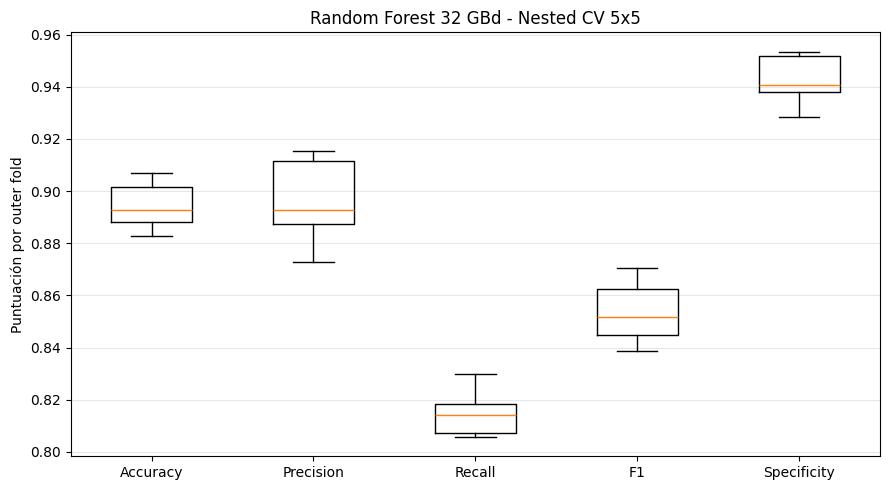


MÉTRICAS GLOBALES OUT-OF-FOLD (OOF)
OOF Accuracy:    0.8943
OOF Precision:   0.8959
OOF Recall:      0.8151
OOF F1:          0.8536
OOF Specificity: 0.9425

CLASSIFICATION REPORT OOF:
              precision    recall  f1-score   support

      NORMAL       0.89      0.94      0.92      5804
      ALARMA       0.90      0.82      0.85      3526

    accuracy                           0.89      9330
   macro avg       0.89      0.88      0.89      9330
weighted avg       0.89      0.89      0.89      9330


Matriz de confusión OOF:
[[5470  334]
 [ 652 2874]]


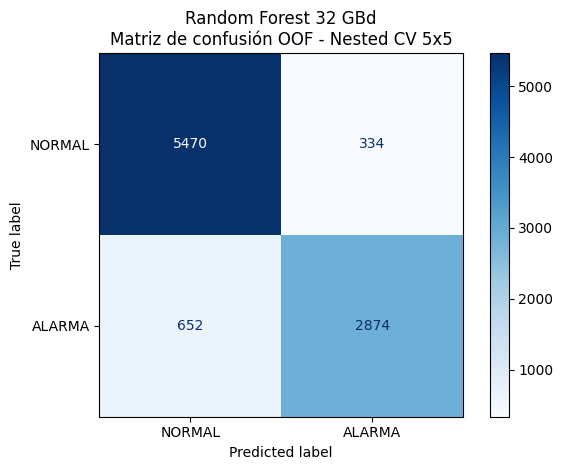


Predicciones OOF guardadas.

HIPERPARÁMETROS POR OUTER FOLD
 fold  max_depth max_features  min_samples_leaf  min_samples_split  n_estimators  inner_cv_best_f1
    1        NaN         sqrt                 2                 10           400          0.855221
    2       20.0         sqrt                 2                  2           100          0.851276
    3       20.0         sqrt                 1                  5           400          0.856367
    4        NaN         sqrt                 1                  5           400          0.853531
    5       20.0         sqrt                 1                  5           400          0.859778

TIEMPO DE INFERENCIA - OUTER CV
Inference Mean: 21.537 µs/muestra
Inference Std:  7.708 µs/muestra
Mediciones totales: 500
Tiempo por muestra dentro de un batch. No es latencia individual.

ENTRENANDO MODELO FINAL - RANDOM FOREST

Mejores parámetros modelo final:
{'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 2, 'min_samples_

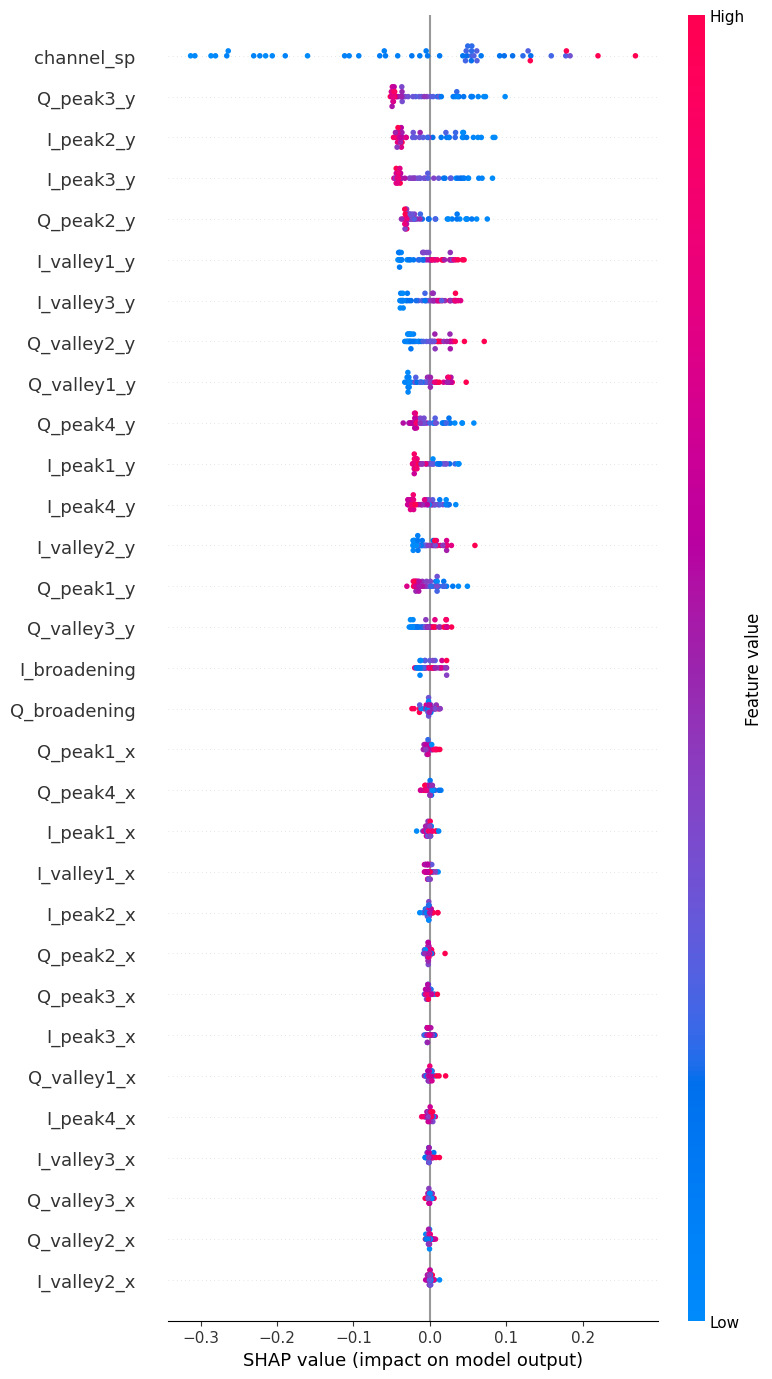

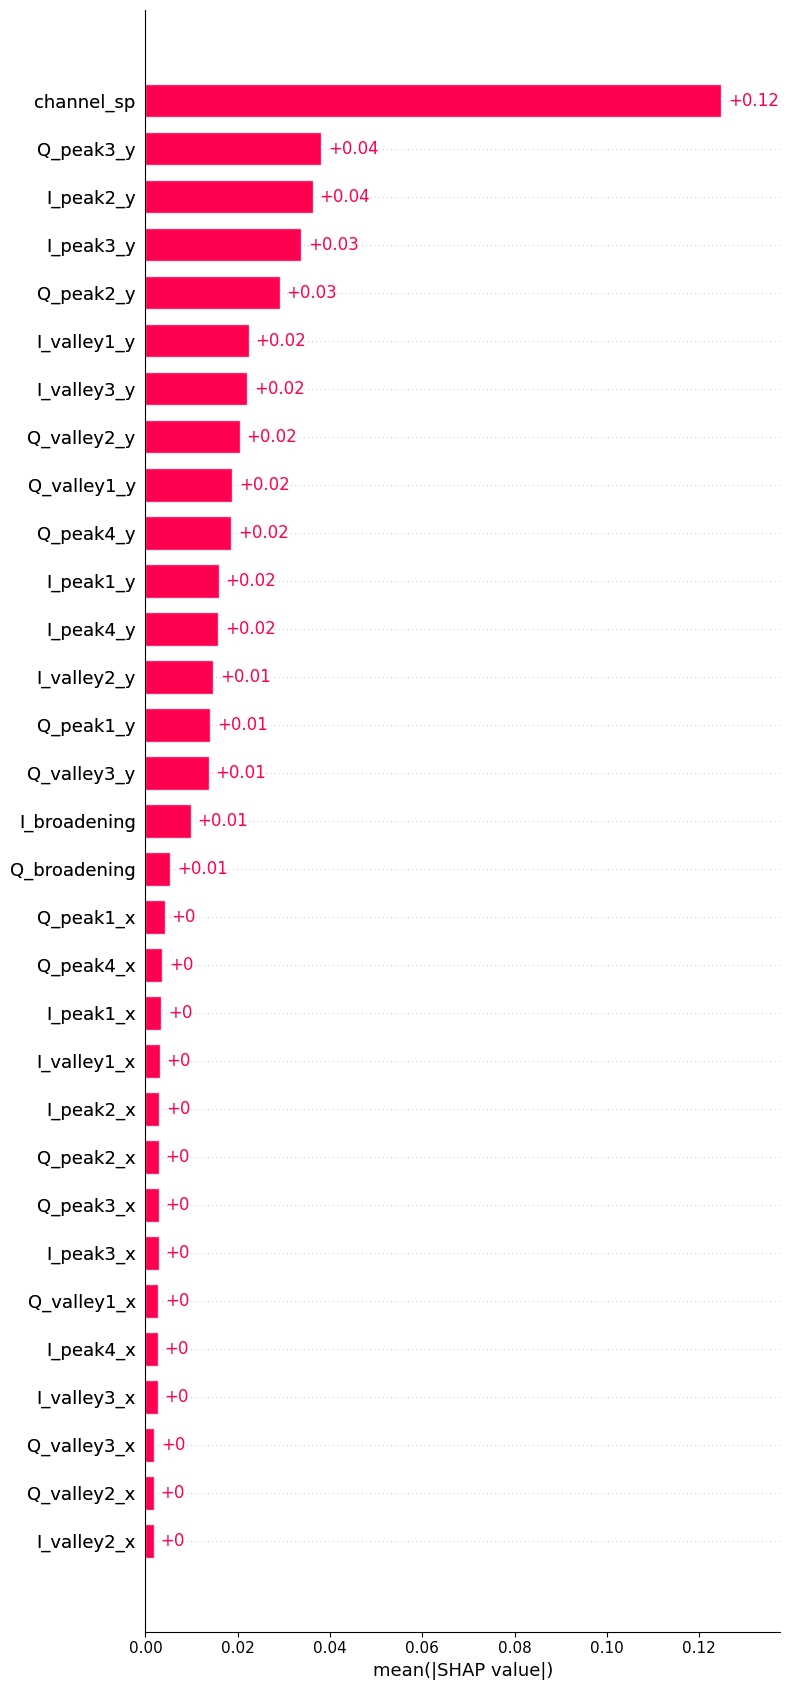

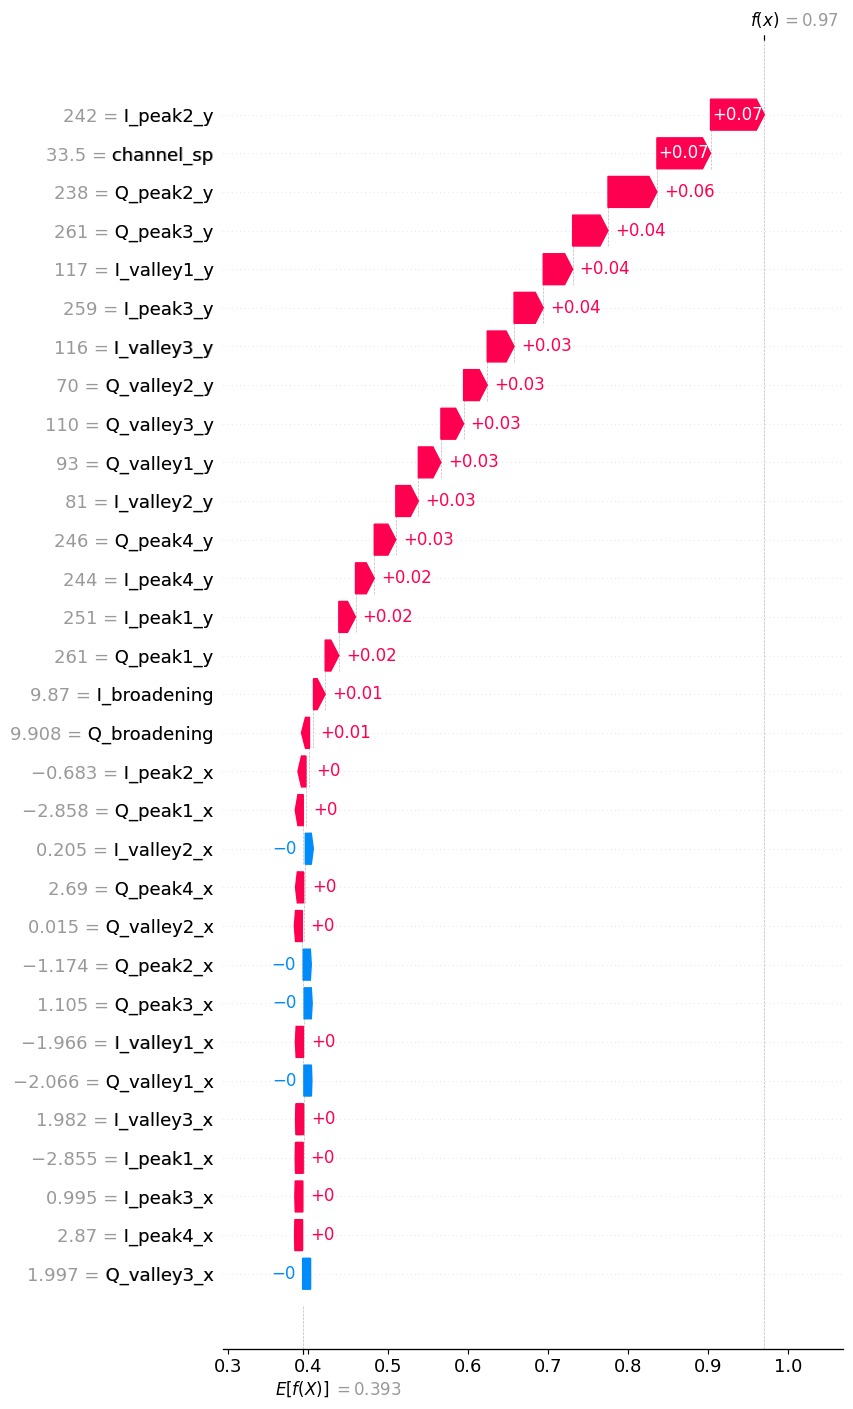


RESUMEN FINAL - RF 32 GBd NESTED CV 5x5
Outer CV Accuracy: 0.8943 ± 0.0088
Outer CV Precision: 0.8960 ± 0.0157
Outer CV Recall: 0.8151 ± 0.0087
Outer CV F1: 0.8536 ± 0.0116
Outer CV Specificity: 0.9425 ± 0.0093
OOF Accuracy: 0.8943
OOF Precision: 0.8959
OOF Recall: 0.8151
OOF F1: 0.8536
OOF Specificity: 0.9425
Inference Mean: 21.537 µs/muestra
Inference Std: 7.708 µs/muestra

Archivos generados:
1. rf_osnr_32GBd_nested_outer_folds.csv
2. rf_osnr_32GBd_nested_oof_predictions.csv
3. rf_osnr_32GBd_nested_best_params.csv
4. rf_osnr_32GBd_nested_importancia_shap.csv

PROCESO COMPLETADO.


In [ ]:

"""
===============================================================
CLASIFICACIÓN OSNR 32 GBd - RANDOM FOREST
NESTED CROSS-VALIDATION 5x5 + PREDICCIONES OUTER-FOLD
MÉTRICAS, SHAP Y TIEMPO DE INFERENCIA
===============================================================

CLASES:
    0 = NORMAL: OSNR > 23 dB
    1 = ALARMA: OSNR <= 23 dB

DATASET:
    30 características I/Q
    1 característica channel_sp
    1 columna OSNR (target continuo original)

METODOLOGÍA:
    - Outer CV: 5 folds estratificados
    - Inner CV: 5 folds estratificados
    - GridSearchCV dentro de cada outer train
    - Predicciones OOF sobre todas las muestras
    - Métricas por fold y métricas OOF globales
    - Tiempos de inferencia por outer fold
    - Modelo final entrenado con todo el dataset
    - SHAP para interpretar el modelo final

IMPORTANTE:
    La CV es estratificada por filas, no por escenario.
    Si hay muestras dependientes del mismo experimento,
    considerar validación agrupada.
"""

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap

from sklearn.model_selection import (
    StratifiedKFold,
    GridSearchCV
)

from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

# =============================================================
# 1. CONFIGURACIÓN GENERAL
# =============================================================

CSV_PATH = "matriz32GBd_clasifi_correct.csv"

THRESHOLD_DB = 23.0

SEED = 42

N_OUTER_FOLDS = 5
N_INNER_FOLDS = 5

N_REPETITIONS = 100

SHAP_BACKGROUND = 50
SHAP_EXPLAIN = 50

# =============================================================
# 2. NOMBRES DE LAS 31 CARACTERÍSTICAS
# =============================================================

feature_names = (
    [f"I_peak{k}_x" for k in range(1, 5)] +
    [f"I_peak{k}_y" for k in range(1, 5)] +
    [f"Q_peak{k}_x" for k in range(1, 5)] +
    [f"Q_peak{k}_y" for k in range(1, 5)] +
    [f"I_valley{k}_x" for k in range(1, 4)] +
    [f"I_valley{k}_y" for k in range(1, 4)] +
    [f"Q_valley{k}_x" for k in range(1, 4)] +
    [f"Q_valley{k}_y" for k in range(1, 4)] +
    ["I_broadening", "Q_broadening", "channel_sp"]
)

assert len(feature_names) == 31

# =============================================================
# 3. CARGAR Y VALIDAR DATASET
# =============================================================

matriz = pd.read_csv(
    CSV_PATH,
    header=None
)

if matriz.shape[1] != 32:
    raise ValueError(
        f"Se esperaban 32 columnas; "
        f"se encontraron {matriz.shape[1]}"
    )

matriz = matriz.apply(
    pd.to_numeric,
    errors="raise"
)

if not np.isfinite(matriz.to_numpy()).all():
    raise ValueError(
        "El dataset contiene NaN o infinitos."
    )

# Las primeras 31 columnas son las características.
X = matriz.iloc[:, :31].copy()
X.columns = feature_names

# La columna 32 contiene el OSNR continuo.
y_osnr = matriz.iloc[:, 31].to_numpy()

# Convertir OSNR a clasificación binaria.
y = (y_osnr <= THRESHOLD_DB).astype(int)

n_samples = len(y)

class_counts = np.bincount(
    y,
    minlength=2
)

if class_counts.min() < N_OUTER_FOLDS:
    raise ValueError(
        "No hay suficientes muestras por clase "
        "para realizar los outer folds."
    )

print("=" * 65)
print("INFORMACIÓN DEL DATASET")
print("=" * 65)

print(f"Dataset: {CSV_PATH}")
print(f"Muestras: {n_samples}")
print(f"Características: {X.shape[1]}")
print(f"NORMAL: {class_counts[0]}")
print(f"ALARMA: {class_counts[1]}")
print(f"Umbral OSNR: {THRESHOLD_DB} dB")

print(
    "\nMonitoreo asistido: channel_sp "
    "se utiliza como característica de entrada."
)

# =============================================================
# 4. MODELO Y GRID DE HIPERPARÁMETROS
# =============================================================

def build_rf():
    """
    Crea una instancia nueva de Random Forest.

    n_jobs=1 evita paralelismo anidado:
    GridSearchCV utiliza n_jobs=-1.
    """
    return RandomForestClassifier(
        random_state=SEED,
        n_jobs=1
    )


# Se conserva el mismo grid del código original.
param_grid = {
    "n_estimators": [100, 200, 400],
    "max_depth": [None, 10, 20],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4],
    "max_features": ["sqrt", "log2"]
}

n_combinations = (
    len(param_grid["n_estimators"]) *
    len(param_grid["max_depth"]) *
    len(param_grid["min_samples_split"]) *
    len(param_grid["min_samples_leaf"]) *
    len(param_grid["max_features"])
)

print("\nCombinaciones de hiperparámetros:", n_combinations)

# =============================================================
# 5. CONFIGURAR OUTER CROSS-VALIDATION
# =============================================================

outer_cv = StratifiedKFold(
    n_splits=N_OUTER_FOLDS,
    shuffle=True,
    random_state=SEED
)

# Cada posición corresponde a una fila del dataset.
# Se rellena únicamente cuando esa muestra está
# en el outer test de un fold.

oof_predictions = np.full(
    n_samples,
    -1,
    dtype=int
)

# Probabilidad de ALARMA para cada muestra OOF.
oof_probabilities = np.full(
    n_samples,
    np.nan,
    dtype=float
)

# Número de fold donde se evaluó cada muestra.
oof_fold = np.full(
    n_samples,
    -1,
    dtype=int
)

outer_results = []
outer_best_params = []
outer_inference_times = []

print("\n" + "=" * 65)
print("INICIANDO NESTED CV 5x5 - RANDOM FOREST")
print("=" * 65)

# =============================================================
# 6. BUCLE PRINCIPAL: OUTER CV
# =============================================================

for fold, (train_idx, test_idx) in enumerate(
    outer_cv.split(X, y),
    start=1
):

    print("\n" + "=" * 65)
    print(f"OUTER FOLD {fold}/{N_OUTER_FOLDS}")
    print("=" * 65)

    # ---------------------------------------------------------
    # 6.1 DATOS DE ENTRENAMIENTO Y TEST EXTERNOS
    # ---------------------------------------------------------

    X_outer_train = X.iloc[train_idx]
    X_outer_test = X.iloc[test_idx]

    y_outer_train = y[train_idx]
    y_outer_test = y[test_idx]

    print(
        f"Outer Train: {len(X_outer_train)} muestras"
    )

    print(
        f"Outer Test:  {len(X_outer_test)} muestras"
    )

    # ---------------------------------------------------------
    # 6.2 INNER CV: GRIDSEARCHCV
    # ---------------------------------------------------------

    inner_cv = StratifiedKFold(
        n_splits=N_INNER_FOLDS,
        shuffle=True,
        random_state=SEED + fold
    )

    search = GridSearchCV(
        estimator=build_rf(),
        param_grid=param_grid,
        scoring="f1",
        cv=inner_cv,
        n_jobs=-1,
        refit=True,
        return_train_score=False
    )

    print("\nBuscando mejores hiperparámetros...")

    # IMPORTANTE:
    # GridSearchCV solo recibe el outer train.
    # El outer test permanece completamente separado.
    search.fit(
        X_outer_train,
        y_outer_train
    )

    best_rf = search.best_estimator_

    print("\nMejores hiperparámetros:")
    print(search.best_params_)

    print(
        f"Inner CV Best F1: "
        f"{search.best_score_:.4f}"
    )

    outer_best_params.append({
        "fold": fold,
        **search.best_params_,
        "inner_cv_best_f1": search.best_score_
    })

    # ---------------------------------------------------------
    # 6.3 PREDICCIONES OUTER-FOLD
    # ---------------------------------------------------------

    y_outer_pred = best_rf.predict(
        X_outer_test
    )

    # Probabilidad de pertenecer a ALARMA (clase 1).
    y_outer_proba = best_rf.predict_proba(
        X_outer_test
    )[:, 1]

    # Guardar en las posiciones originales.
    oof_predictions[test_idx] = y_outer_pred

    oof_probabilities[test_idx] = y_outer_proba

    oof_fold[test_idx] = fold

    # ---------------------------------------------------------
    # 6.4 MÉTRICAS DEL OUTER FOLD
    # ---------------------------------------------------------

    tn, fp, fn, tp = confusion_matrix(
        y_outer_test,
        y_outer_pred,
        labels=[0, 1]
    ).ravel()

    accuracy = accuracy_score(
        y_outer_test,
        y_outer_pred
    )

    precision = precision_score(
        y_outer_test,
        y_outer_pred,
        zero_division=0
    )

    recall = recall_score(
        y_outer_test,
        y_outer_pred,
        zero_division=0
    )

    f1 = f1_score(
        y_outer_test,
        y_outer_pred,
        zero_division=0
    )

    specificity = (
        tn / (tn + fp)
        if (tn + fp) > 0
        else np.nan
    )

    # ---------------------------------------------------------
    # 6.5 TIEMPO DE INFERENCIA
    # ---------------------------------------------------------

    # Warm-up antes de medir.
    _ = best_rf.predict(
        X_outer_test.iloc[
            :min(10, len(X_outer_test))
        ]
    )

    inference_times = np.empty(
        N_REPETITIONS
    )

    for rep in range(N_REPETITIONS):

        start = time.perf_counter()

        _ = best_rf.predict(X_outer_test)

        elapsed = (
            time.perf_counter() - start
        )

        inference_times[rep] = (
            elapsed / len(X_outer_test)
        )

    inference_mean_us = (
        inference_times.mean() * 1e6
    )

    inference_std_us = (
        inference_times.std() * 1e6
    )

    outer_inference_times.append(
        inference_times * 1e6
    )

    # ---------------------------------------------------------
    # 6.6 GUARDAR RESULTADOS
    # ---------------------------------------------------------

    outer_results.append({
        "fold": fold,
        "n_train": len(train_idx),
        "n_test": len(test_idx),
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "specificity": specificity,
        "inference_mean_us": inference_mean_us,
        "inference_std_us": inference_std_us
    })

    print("\nMÉTRICAS OUTER FOLD:")

    print(f"Accuracy:    {accuracy:.4f}")
    print(f"Precision:   {precision:.4f}")
    print(f"Recall:      {recall:.4f}")
    print(f"F1:          {f1:.4f}")
    print(f"Specificity: {specificity:.4f}")

    print(
        f"Inference Mean: "
        f"{inference_mean_us:.3f} µs/muestra"
    )

    print(
        f"Inference Std:  "
        f"{inference_std_us:.3f} µs/muestra"
    )

# =============================================================
# 7. VERIFICAR PREDICCIONES OOF
# =============================================================

if np.any(oof_predictions == -1):
    raise RuntimeError(
        "Existen muestras sin predicción OOF."
    )

if np.any(oof_fold == -1):
    raise RuntimeError(
        "Existen muestras sin outer fold asignado."
    )

if not np.isfinite(oof_probabilities).all():
    raise RuntimeError(
        "Existen probabilidades OOF inválidas."
    )

print("\nTodas las muestras tienen predicción OOF.")

# =============================================================
# 8. RESULTADOS POR OUTER FOLD
# =============================================================

results_df = pd.DataFrame(
    outer_results
)

print("\n" + "=" * 65)
print("RESULTADOS DE LOS 5 OUTER FOLDS")
print("=" * 65)

print(
    results_df.to_string(index=False)
)

results_df.to_csv(
    "rf_osnr_32GBd_nested_outer_folds.csv",
    index=False
)

# =============================================================
# 9. PROMEDIO Y DESVIACIÓN ESTÁNDAR OUTER CV
# =============================================================

print("\n" + "=" * 65)
print("OUTER CV - PROMEDIO ± DESVIACIÓN ESTÁNDAR")
print("=" * 65)

metrics = [
    "accuracy",
    "precision",
    "recall",
    "f1",
    "specificity"
]

for metric in metrics:

    values = results_df[
        metric
    ].to_numpy()

    print(
        f"{metric.upper():12s}: "
        f"{np.nanmean(values):.4f} ± "
        f"{np.nanstd(values):.4f}"
    )

# =============================================================
# 10. GRÁFICA DE MÉTRICAS OUTER CV
# =============================================================

plt.figure(figsize=(9, 5))

plt.boxplot(
    [
        results_df[m].values
        for m in metrics
    ],
    tick_labels=[
        "Accuracy",
        "Precision",
        "Recall",
        "F1",
        "Specificity"
    ]
)

plt.ylabel("Puntuación por outer fold")

plt.title(
    "Random Forest 32 GBd - Nested CV 5x5"
)

plt.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()
plt.show()
plt.close()

# =============================================================
# 11. MÉTRICAS GLOBALES OOF
# =============================================================

print("\n" + "=" * 65)
print("MÉTRICAS GLOBALES OUT-OF-FOLD (OOF)")
print("=" * 65)

tn, fp, fn, tp = confusion_matrix(
    y,
    oof_predictions,
    labels=[0, 1]
).ravel()

oof_accuracy = accuracy_score(
    y,
    oof_predictions
)

oof_precision = precision_score(
    y,
    oof_predictions,
    zero_division=0
)

oof_recall = recall_score(
    y,
    oof_predictions,
    zero_division=0
)

oof_f1 = f1_score(
    y,
    oof_predictions,
    zero_division=0
)

oof_specificity = (
    tn / (tn + fp)
    if (tn + fp) > 0
    else np.nan
)

print(
    f"OOF Accuracy:    {oof_accuracy:.4f}"
)

print(
    f"OOF Precision:   {oof_precision:.4f}"
)

print(
    f"OOF Recall:      {oof_recall:.4f}"
)

print(
    f"OOF F1:          {oof_f1:.4f}"
)

print(
    f"OOF Specificity: {oof_specificity:.4f}"
)

print("\nCLASSIFICATION REPORT OOF:")

print(
    classification_report(
        y,
        oof_predictions,
        labels=[0, 1],
        target_names=[
            "NORMAL",
            "ALARMA"
        ],
        zero_division=0
    )
)

# =============================================================
# 12. MATRIZ DE CONFUSIÓN OOF
# =============================================================

cm_oof = confusion_matrix(
    y,
    oof_predictions,
    labels=[0, 1]
)

print("\nMatriz de confusión OOF:")

print(cm_oof)

ConfusionMatrixDisplay(
    confusion_matrix=cm_oof,
    display_labels=[
        "NORMAL",
        "ALARMA"
    ]
).plot(
    cmap="Blues",
    values_format="d"
)

plt.title(
    "Random Forest 32 GBd\n"
    "Matriz de confusión OOF - Nested CV 5x5"
)

plt.tight_layout()
plt.show()
plt.close()

# =============================================================
# 13. GUARDAR PREDICCIONES OOF
# =============================================================

oof_df = pd.DataFrame({
    "sample_index": np.arange(n_samples),
    "outer_fold": oof_fold,
    "OSNR_dB": y_osnr,
    "true_class": y,
    "predicted_class": oof_predictions,
    "probability_alarm": oof_probabilities,
    "correct": (
        y == oof_predictions
    )
})

oof_df.to_csv(
    "rf_osnr_32GBd_nested_oof_predictions.csv",
    index=False
)

print("\nPredicciones OOF guardadas.")

# =============================================================
# 14. HIPERPARÁMETROS POR OUTER FOLD
# =============================================================

params_df = pd.DataFrame(
    outer_best_params
)

print("\n" + "=" * 65)
print("HIPERPARÁMETROS POR OUTER FOLD")
print("=" * 65)

print(
    params_df.to_string(index=False)
)

params_df.to_csv(
    "rf_osnr_32GBd_nested_best_params.csv",
    index=False
)

# =============================================================
# 15. TIEMPO DE INFERENCIA OUTER CV
# =============================================================

all_inference_times = np.concatenate(
    outer_inference_times
)

print("\n" + "=" * 65)
print("TIEMPO DE INFERENCIA - OUTER CV")
print("=" * 65)

print(
    f"Inference Mean: "
    f"{all_inference_times.mean():.3f} µs/muestra"
)

print(
    f"Inference Std:  "
    f"{all_inference_times.std():.3f} µs/muestra"
)

print(
    f"Mediciones totales: "
    f"{len(all_inference_times)}"
)

print(
    "Tiempo por muestra dentro de un batch. "
    "No es latencia individual."
)

# =============================================================
# 16. ENTRENAR MODELO FINAL CON TODOS LOS DATOS
# =============================================================

# Este modelo se utiliza para SHAP.
# NO se utiliza para las métricas OOF.
#
# Se seleccionan nuevamente los hiperparámetros
# mediante GridSearchCV sobre todo el dataset.

print("\n" + "=" * 65)
print("ENTRENANDO MODELO FINAL - RANDOM FOREST")
print("=" * 65)

final_inner_cv = StratifiedKFold(
    n_splits=N_INNER_FOLDS,
    shuffle=True,
    random_state=SEED
)

final_search = GridSearchCV(
    estimator=build_rf(),
    param_grid=param_grid,
    scoring="f1",
    cv=final_inner_cv,
    n_jobs=-1,
    refit=True
)

final_search.fit(X, y)

final_rf = final_search.best_estimator_

print("\nMejores parámetros modelo final:")
print(final_search.best_params_)

print(
    f"F1 GridSearch final: "
    f"{final_search.best_score_:.4f}"
)

# =============================================================
# 17. SHAP - TREEEXPLAINER
# =============================================================

# Explicamos P(ALARMA) = P(clase 1).
#
# SHAP positivo:
#    aumenta la probabilidad de ALARMA.
#
# SHAP negativo:
#    reduce la probabilidad de ALARMA.
#
# Las muestras explicadas fueron utilizadas
# para entrenar el modelo final.
# Por eso este SHAP es descriptivo y NO OOF.

print("\n" + "=" * 65)
print("CALCULANDO SHAP DEL MODELO FINAL")
print("=" * 65)

background = X.sample(
    n=min(SHAP_BACKGROUND, len(X)),
    random_state=SEED
)

explained = X.sample(
    n=min(SHAP_EXPLAIN, len(X)),
    random_state=SEED + 1
)

print(
    f"Background: {len(background)} muestras"
)

print(
    f"Muestras explicadas: {len(explained)}"
)

explainer = shap.TreeExplainer(
    final_rf,
    data=background,
    feature_perturbation="interventional",
    model_output="probability"
)

raw = explainer.shap_values(
    explained,
    check_additivity=False
)

# Diferentes versiones de SHAP devuelven:
#
# Versión antigua:
#   lista [SHAP clase 0, SHAP clase 1]
#
# Versión reciente:
#   array (n_muestras, n_features, n_clases)

if isinstance(raw, list):

    shap_values = np.asarray(
        raw[1]
    )

else:

    arr = np.asarray(raw)

    if arr.ndim == 3 and arr.shape[2] == 2:

        shap_values = arr[:, :, 1]

    else:

        shap_values = arr

if shap_values.shape != explained.shape:
    raise ValueError(
        f"Forma SHAP inesperada: "
        f"{shap_values.shape}. "
        f"Se esperaba {explained.shape}."
    )

# Valor base de probabilidad ALARMA.
base = np.asarray(
    explainer.expected_value
)

base_alarm = float(
    base[1]
    if base.size == 2
    else base.item()
)

# =============================================================
# 18. IMPORTANCIA GLOBAL SHAP
# =============================================================

mean_abs = np.mean(
    np.abs(shap_values),
    axis=0
)

imp_df = pd.DataFrame({
    "feature": feature_names,
    "mean_abs_shap": mean_abs
})

imp_df = imp_df.sort_values(
    "mean_abs_shap",
    ascending=False
).reset_index(drop=True)

total = imp_df[
    "mean_abs_shap"
].sum()

if total > 0:

    imp_df["importance_percent"] = (
        100 *
        imp_df["mean_abs_shap"] /
        total
    )

else:

    imp_df["importance_percent"] = 0.0

print("\n31 CARACTERÍSTICAS ORDENADAS POR SHAP:")

print(
    imp_df.to_string(
        index=False,
        formatters={
            "mean_abs_shap": "{:.6f}".format,
            "importance_percent": "{:.2f}%".format
        }
    )
)

print(
    f"\nSuma de porcentajes: "
    f"{imp_df['importance_percent'].sum():.2f}%"
)

print("\nTOP 5 SHAP:")

print(
    imp_df.head(5).to_string(
        index=False
    )
)

imp_df.to_csv(
    "rf_osnr_32GBd_nested_importancia_shap.csv",
    index=False
)

# =============================================================
# 19. CREAR OBJETO SHAP EXPLANATION
# =============================================================

explanation = shap.Explanation(
    values=shap_values,
    base_values=np.full(
        len(explained),
        base_alarm
    ),
    data=explained.to_numpy(),
    feature_names=feature_names
)

# =============================================================
# 20. GRÁFICAS SHAP
# =============================================================

# Beeswarm
shap.plots.beeswarm(
    explanation,
    max_display=31,
    show=False
)

plt.tight_layout()
plt.show()
plt.close()

# Bar plot
shap.plots.bar(
    explanation,
    max_display=31,
    show=False
)

plt.tight_layout()
plt.show()
plt.close()

# Waterfall: primera muestra explicada.
shap.plots.waterfall(
    explanation[0],
    max_display=31,
    show=False
)

plt.show()
plt.close()

# =============================================================
# 21. RESUMEN FINAL
# =============================================================

print("\n" + "=" * 65)
print("RESUMEN FINAL - RF 32 GBd NESTED CV 5x5")
print("=" * 65)

print(
    f"Outer CV Accuracy: "
    f"{results_df['accuracy'].mean():.4f} ± "
    f"{results_df['accuracy'].std(ddof=0):.4f}"
)

print(
    f"Outer CV Precision: "
    f"{results_df['precision'].mean():.4f} ± "
    f"{results_df['precision'].std(ddof=0):.4f}"
)

print(
    f"Outer CV Recall: "
    f"{results_df['recall'].mean():.4f} ± "
    f"{results_df['recall'].std(ddof=0):.4f}"
)

print(
    f"Outer CV F1: "
    f"{results_df['f1'].mean():.4f} ± "
    f"{results_df['f1'].std(ddof=0):.4f}"
)

print(
    f"Outer CV Specificity: "
    f"{results_df['specificity'].mean():.4f} ± "
    f"{results_df['specificity'].std(ddof=0):.4f}"
)

print(
    f"OOF Accuracy: "
    f"{oof_accuracy:.4f}"
)

print(
    f"OOF Precision: "
    f"{oof_precision:.4f}"
)

print(
    f"OOF Recall: "
    f"{oof_recall:.4f}"
)

print(
    f"OOF F1: "
    f"{oof_f1:.4f}"
)

print(
    f"OOF Specificity: "
    f"{oof_specificity:.4f}"
)

print(
    f"Inference Mean: "
    f"{all_inference_times.mean():.3f} µs/muestra"
)

print(
    f"Inference Std: "
    f"{all_inference_times.std():.3f} µs/muestra"
)

print("\nArchivos generados:")

print("1. rf_osnr_32GBd_nested_outer_folds.csv")
print("2. rf_osnr_32GBd_nested_oof_predictions.csv")
print("3. rf_osnr_32GBd_nested_best_params.csv")
print("4. rf_osnr_32GBd_nested_importancia_shap.csv")

print("\nPROCESO COMPLETADO.")


## SVM 32GBd para clasificar OSNR CON CHANNEL SPACING

INFORMACIÓN DEL DATASET
Dataset: matriz32GBd_clasifi_correct.csv
Muestras: 9330
Características: 31
NORMAL: 5804
ALARMA: 3526
Umbral OSNR: 23.0 dB

Monitoreo asistido: channel_sp se utiliza como entrada.

INICIANDO NESTED CV 5x5 - SVM 32 GBd

OUTER FOLD 1/5
Outer Train: 7464 muestras
Outer Test:  1866 muestras

Buscando mejores hiperparámetros...

Mejores hiperparámetros:
{'svm__C': 10, 'svm__class_weight': 'balanced', 'svm__gamma': 0.01}
Inner CV Best F1: 0.8501

MÉTRICAS OUTER FOLD:
Accuracy:    0.8783
Precision:   0.8256
Recall:      0.8596
F1:          0.8423
Specificity: 0.8898
Inference Mean: 104.825 µs/muestra
Inference Std:  0.462 µs/muestra

OUTER FOLD 2/5
Outer Train: 7464 muestras
Outer Test:  1866 muestras

Buscando mejores hiperparámetros...

Mejores hiperparámetros:
{'svm__C': 10, 'svm__class_weight': 'balanced', 'svm__gamma': 0.01}
Inner CV Best F1: 0.8494

MÉTRICAS OUTER FOLD:
Accuracy:    0.8901
Precision:   0.8501
Recall:      0.8610
F1:          0.8555
Specificity: 0

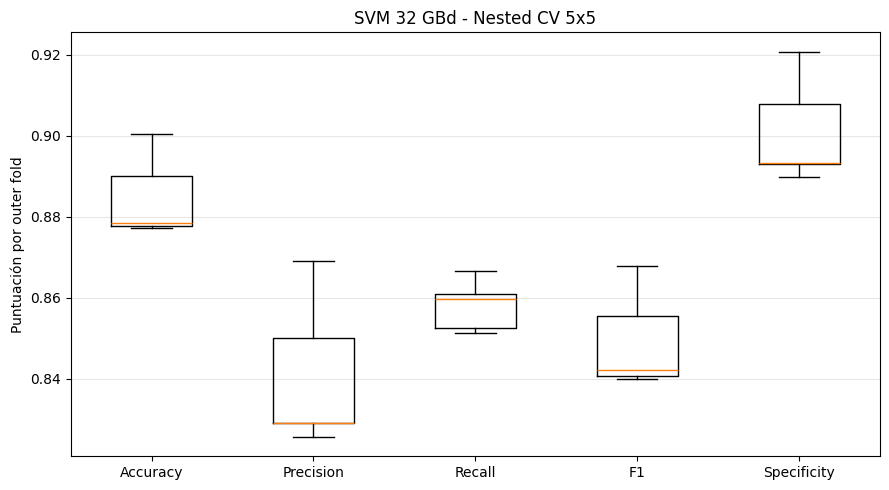


MÉTRICAS GLOBALES OUT-OF-FOLD (OOF)
OOF Accuracy:    0.8848
OOF Precision:   0.8403
OOF Recall:      0.8582
OOF F1:          0.8492
OOF Specificity: 0.9009

CLASSIFICATION REPORT OOF:
              precision    recall  f1-score   support

      NORMAL       0.91      0.90      0.91      5804
      ALARMA       0.84      0.86      0.85      3526

    accuracy                           0.88      9330
   macro avg       0.88      0.88      0.88      9330
weighted avg       0.89      0.88      0.89      9330


Matriz de confusión OOF:
[[5229  575]
 [ 500 3026]]


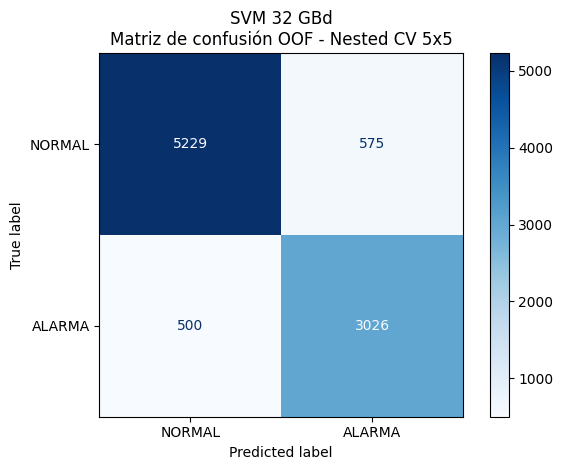


Predicciones OOF guardadas.

HIPERPARÁMETROS POR OUTER FOLD
 fold  svm__C svm__class_weight  svm__gamma  inner_cv_best_f1
    1      10          balanced        0.01          0.850079
    2      10          balanced        0.01          0.849372
    3      10          balanced        0.01          0.848624
    4      10          balanced        0.01          0.847401
    5      10          balanced        0.01          0.851256

TIEMPO DE INFERENCIA - OUTER CV
Inference Mean: 104.293 µs/muestra
Inference Std:  1.238 µs/muestra
Mediciones totales: 500
Tiempo por muestra dentro de un batch. Incluye StandardScaler y SVM.predict().

ENTRENANDO MODELO FINAL - SVM

Mejores parámetros modelo final:
{'svm__C': 10, 'svm__class_weight': 'balanced', 'svm__gamma': 0.01}
F1 GridSearch final: 0.8492

CALCULANDO SHAP DEL MODELO FINAL
Background: 50 muestras
Muestras explicadas: 50


  0%|          | 0/50 [00:00<?, ?it/s]


31 CARACTERÍSTICAS ORDENADAS POR SHAP:
     feature mean_abs_shap importance_percent
  channel_sp      1.210462             35.35%
 I_valley1_y      0.331715              9.69%
 I_valley3_y      0.226226              6.61%
   I_peak3_y      0.223327              6.52%
   I_peak2_y      0.218698              6.39%
   Q_peak4_y      0.156741              4.58%
I_broadening      0.156284              4.56%
Q_broadening      0.126156              3.68%
 Q_valley2_y      0.119381              3.49%
 Q_valley1_y      0.118288              3.45%
   Q_peak3_y      0.111638              3.26%
   Q_peak1_y      0.077366              2.26%
   I_peak4_y      0.056079              1.64%
   Q_peak2_y      0.052955              1.55%
   I_peak2_x      0.039248              1.15%
 I_valley3_x      0.030405              0.89%
   I_peak3_x      0.022041              0.64%
   Q_peak4_x      0.020041              0.59%
   I_peak1_x      0.016540              0.48%
   Q_peak2_x      0.013126              

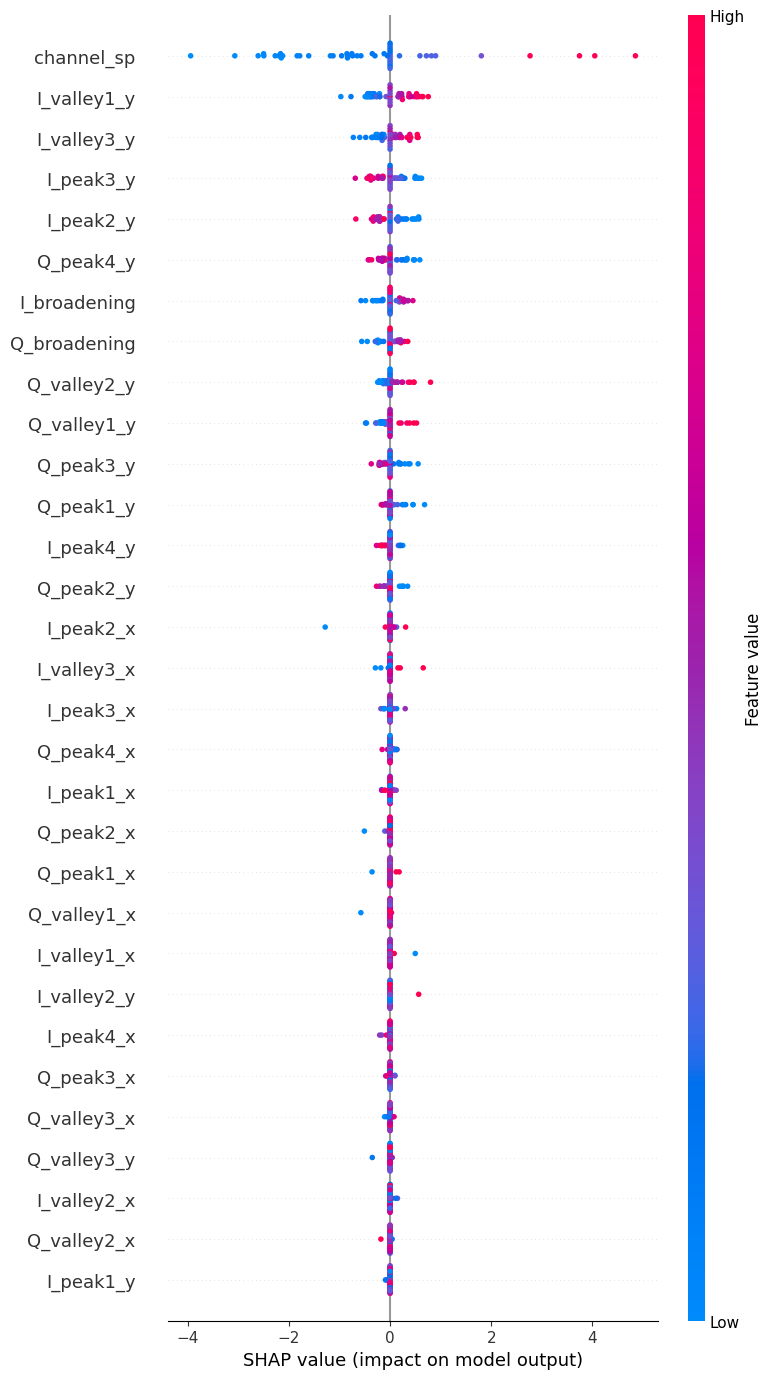

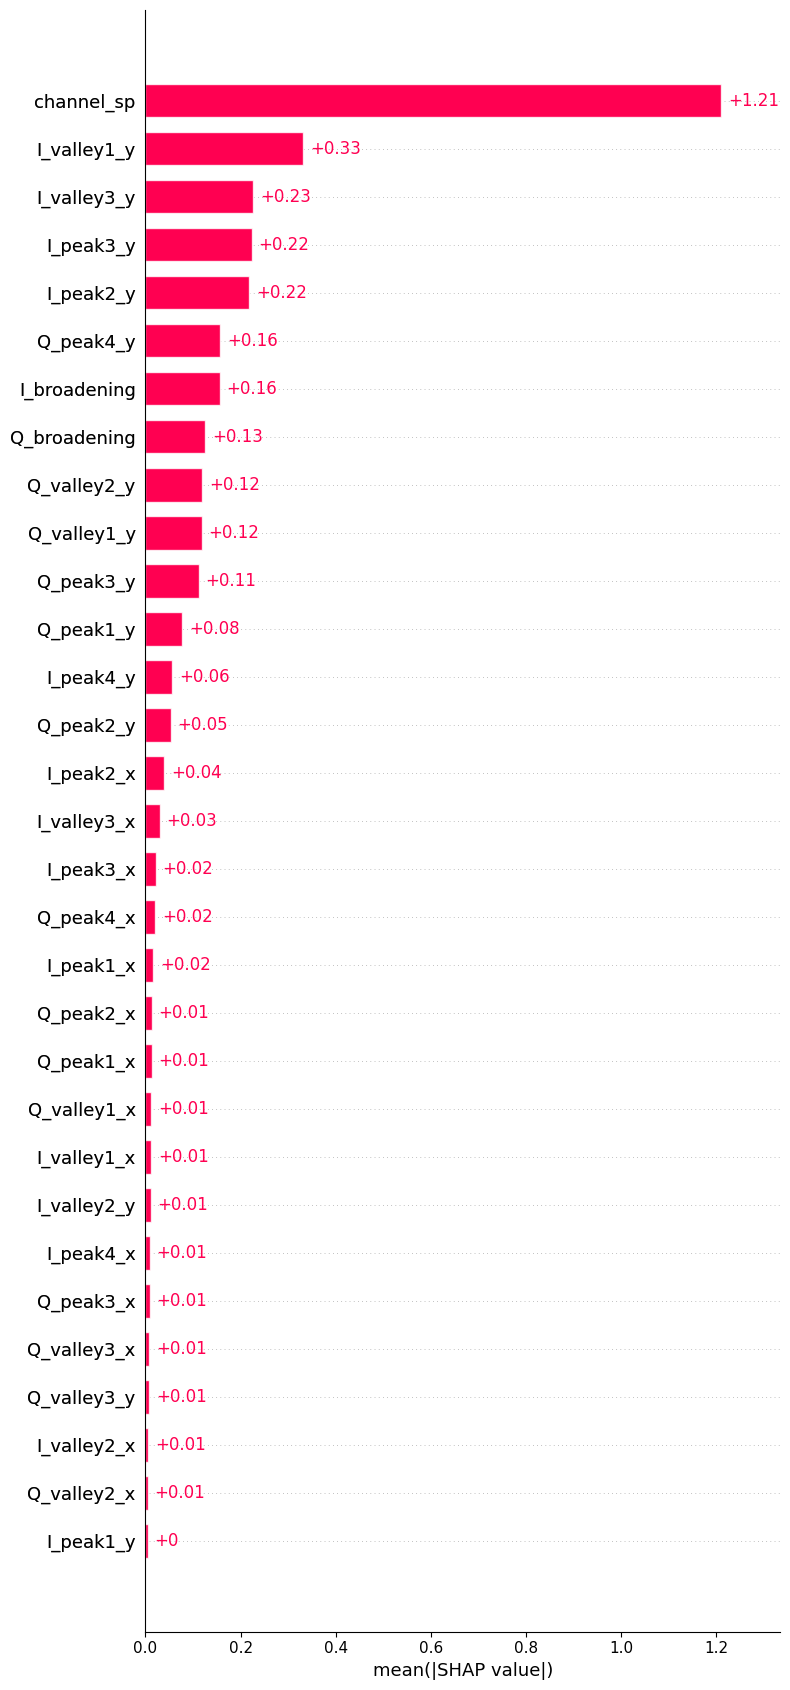

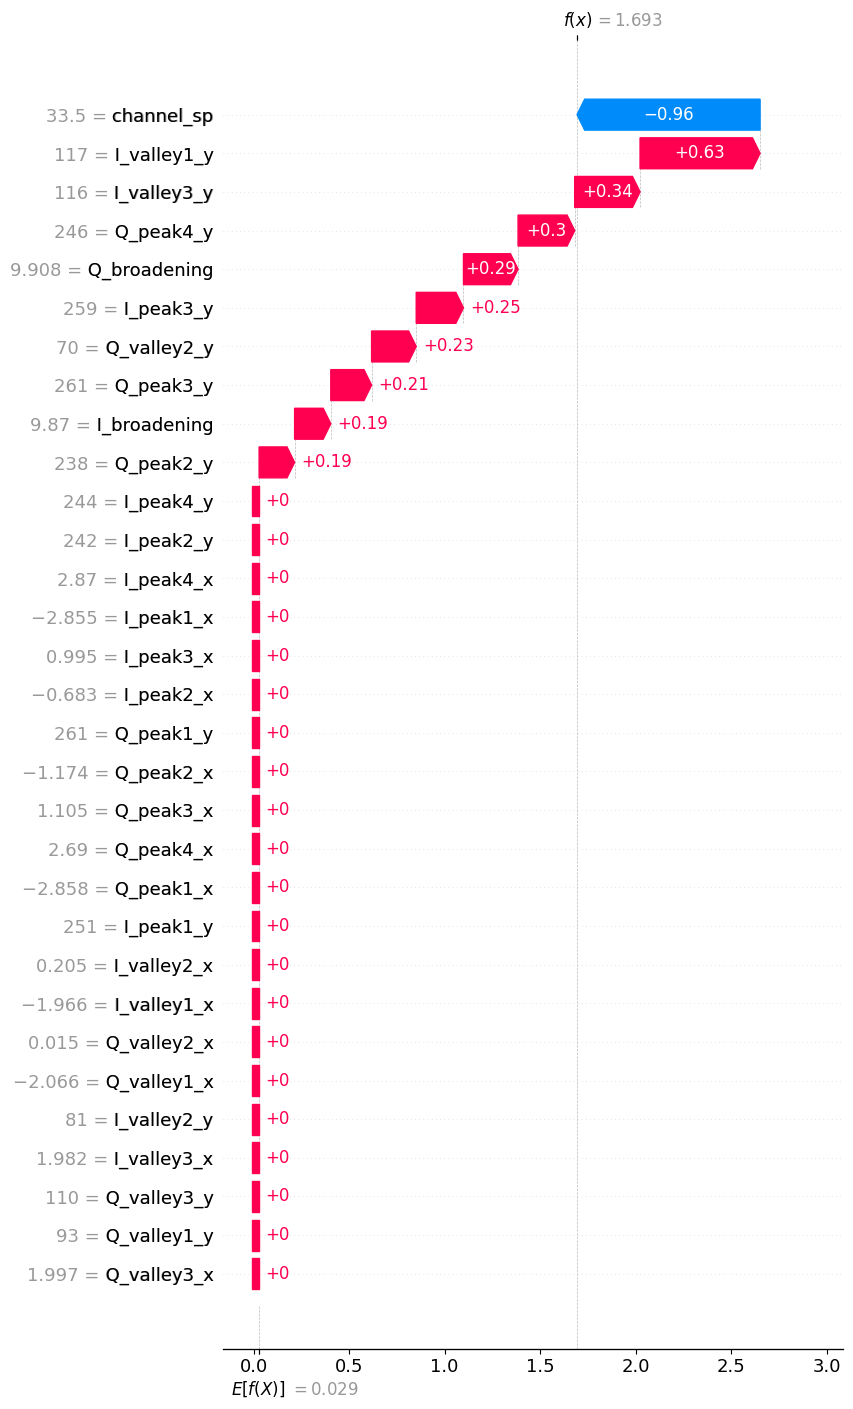


RESUMEN FINAL - SVM 32 GBd NESTED CV 5x5
Outer CV ACCURACY    : 0.8848 ± 0.0091
Outer CV PRECISION   : 0.8406 ± 0.0167
Outer CV RECALL      : 0.8582 ± 0.0057
Outer CV F1          : 0.8492 ± 0.0109
Outer CV SPECIFICITY : 0.9009 ± 0.0117

OOF Accuracy: 0.8848
OOF Precision: 0.8403
OOF Recall: 0.8582
OOF F1: 0.8492
OOF Specificity: 0.9009

Inference Mean: 104.293 µs/muestra
Inference Std: 1.238 µs/muestra

Archivos generados:
1. svm_osnr_32GBd_nested_outer_folds.csv
2. svm_osnr_32GBd_nested_oof_predictions.csv
3. svm_osnr_32GBd_nested_best_params.csv
4. svm_osnr_32GBd_nested_importancia_shap.csv

PROCESO COMPLETADO.


In [ ]:

"""
============================================================
CLASIFICACIÓN OSNR 32 GBd - SVM-RBF
NESTED CROSS-VALIDATION 5x5 + PREDICCIONES OUTER-FOLD
MÉTRICAS, MATRIZ DE CONFUSIÓN, SHAP Y TIEMPO DE INFERENCIA
============================================================

CLASES:
    0 = NORMAL: OSNR > 23 dB
    1 = ALARMA: OSNR <= 23 dB

DATASET:
    30 características I/Q
    1 característica channel_sp
    1 columna OSNR (target continuo)

METODOLOGÍA:
    - Outer CV: StratifiedKFold, 5 folds
    - Inner CV: StratifiedKFold, 5 folds
    - GridSearchCV en cada outer train
    - Predicciones OOF en los outer tests
    - Métricas por fold y métricas globales OOF
    - Tiempos de inferencia por outer fold
    - Modelo final entrenado con todos los datos
    - SHAP para interpretar el modelo final

IMPORTANTE:
    Esta implementación divide por filas.
    Si existen realizaciones del mismo escenario experimental,
    conviene considerar Nested CV agrupada por escenario.
"""

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap

from sklearn.model_selection import (
    StratifiedKFold,
    GridSearchCV
)

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

# ============================================================
# 1. CONFIGURACIÓN GENERAL
# ============================================================

CSV_PATH = "matriz32GBd_clasifi_correct.csv"

THRESHOLD_DB = 23.0

SEED = 42

N_OUTER_FOLDS = 5
N_INNER_FOLDS = 5

N_REPETITIONS = 100

SHAP_BACKGROUND = 50
SHAP_EXPLAIN = 50
SHAP_NSAMPLES = 300

# ============================================================
# 2. NOMBRES DE LAS 31 CARACTERÍSTICAS
# ============================================================

feature_names = (
    [f"I_peak{k}_x" for k in range(1, 5)] +
    [f"I_peak{k}_y" for k in range(1, 5)] +
    [f"Q_peak{k}_x" for k in range(1, 5)] +
    [f"Q_peak{k}_y" for k in range(1, 5)] +
    [f"I_valley{k}_x" for k in range(1, 4)] +
    [f"I_valley{k}_y" for k in range(1, 4)] +
    [f"Q_valley{k}_x" for k in range(1, 4)] +
    [f"Q_valley{k}_y" for k in range(1, 4)] +
    ["I_broadening", "Q_broadening", "channel_sp"]
)

assert len(feature_names) == 31

# ============================================================
# 3. CARGAR Y VALIDAR DATASET
# ============================================================

matriz = pd.read_csv(
    CSV_PATH,
    header=None
)

if matriz.shape[1] != 32:
    raise ValueError(
        f"Se esperaban 32 columnas; "
        f"se encontraron {matriz.shape[1]}"
    )

matriz = matriz.apply(
    pd.to_numeric,
    errors="raise"
)

if not np.isfinite(matriz.to_numpy()).all():
    raise ValueError(
        "El dataset contiene NaN o infinitos."
    )

# Las primeras 31 columnas contienen las features.
X = matriz.iloc[:, :31].copy()
X.columns = feature_names

# Última columna: OSNR continuo.
y_osnr = matriz.iloc[:, 31].to_numpy()

# Clasificación binaria.
y = (y_osnr <= THRESHOLD_DB).astype(int)

n_samples = len(y)

class_counts = np.bincount(
    y,
    minlength=2
)

if class_counts.min() < N_OUTER_FOLDS:
    raise ValueError(
        "No hay suficientes muestras por clase "
        "para los folds externos."
    )

print("=" * 65)
print("INFORMACIÓN DEL DATASET")
print("=" * 65)

print(f"Dataset: {CSV_PATH}")
print(f"Muestras: {n_samples}")
print(f"Características: {X.shape[1]}")
print(f"NORMAL: {class_counts[0]}")
print(f"ALARMA: {class_counts[1]}")
print(f"Umbral OSNR: {THRESHOLD_DB} dB")

print(
    "\nMonitoreo asistido: "
    "channel_sp se utiliza como entrada."
)

# ============================================================
# 4. DEFINIR PIPELINE SVM Y GRID
# ============================================================

def build_pipeline():
    """
    Construye un pipeline nuevo.

    StandardScaler se ajusta exclusivamente
    con los datos de entrenamiento de cada fold.
    """

    return Pipeline([
        (
            "scaler",
            StandardScaler()
        ),
        (
            "svm",
            SVC(
                kernel="rbf",
                random_state=SEED
            )
        )
    ])


# Mismo grid de tu código original.
param_grid = {
    "svm__C": [0.1, 1, 10, 100],
    "svm__gamma": [
        "scale",
        0.001,
        0.01,
        0.1
    ],
    "svm__class_weight": [
        None,
        "balanced"
    ]
}

# ============================================================
# 5. CONFIGURAR OUTER CV
# ============================================================

outer_cv = StratifiedKFold(
    n_splits=N_OUTER_FOLDS,
    shuffle=True,
    random_state=SEED
)

# Cada muestra recibirá exactamente una predicción
# cuando pertenezca al test de un outer fold.

oof_predictions = np.full(
    n_samples,
    -1,
    dtype=int
)

# Puntuaciones de decision_function.
oof_decisions = np.full(
    n_samples,
    np.nan,
    dtype=float
)

# Identificador del fold de evaluación.
oof_fold = np.full(
    n_samples,
    -1,
    dtype=int
)

outer_results = []
outer_best_params = []
outer_inference_times = []

print("\n" + "=" * 65)
print("INICIANDO NESTED CV 5x5 - SVM 32 GBd")
print("=" * 65)

# ============================================================
# 6. BUCLE PRINCIPAL: OUTER CROSS-VALIDATION
# ============================================================

for fold, (train_idx, test_idx) in enumerate(
    outer_cv.split(X, y),
    start=1
):

    print("\n" + "=" * 65)
    print(f"OUTER FOLD {fold}/{N_OUTER_FOLDS}")
    print("=" * 65)

    # --------------------------------------------------------
    # 6.1 SEPARACIÓN EXTERNA
    # --------------------------------------------------------

    X_outer_train = X.iloc[train_idx]
    X_outer_test = X.iloc[test_idx]

    y_outer_train = y[train_idx]
    y_outer_test = y[test_idx]

    print(
        f"Outer Train: {len(X_outer_train)} muestras"
    )

    print(
        f"Outer Test:  {len(X_outer_test)} muestras"
    )

    # --------------------------------------------------------
    # 6.2 INNER CV: GRIDSEARCHCV
    # --------------------------------------------------------

    inner_cv = StratifiedKFold(
        n_splits=N_INNER_FOLDS,
        shuffle=True,
        random_state=SEED + fold
    )

    search = GridSearchCV(
        estimator=build_pipeline(),
        param_grid=param_grid,
        scoring="f1",
        cv=inner_cv,
        n_jobs=-1,
        refit=True,
        return_train_score=False
    )

    print("\nBuscando mejores hiperparámetros...")

    # El GridSearch solo recibe el outer train.
    # El outer test NO participa en la selección.
    search.fit(
        X_outer_train,
        y_outer_train
    )

    best_svm = search.best_estimator_

    print("\nMejores hiperparámetros:")
    print(search.best_params_)

    print(
        f"Inner CV Best F1: "
        f"{search.best_score_:.4f}"
    )

    outer_best_params.append({
        "fold": fold,
        **search.best_params_,
        "inner_cv_best_f1": search.best_score_
    })

    # --------------------------------------------------------
    # 6.3 PREDICCIONES OUTER-FOLD
    # --------------------------------------------------------

    y_outer_pred = best_svm.predict(
        X_outer_test
    )

    decision_values = best_svm.decision_function(
        X_outer_test
    )

    # Guardar las predicciones en el orden original.
    oof_predictions[test_idx] = y_outer_pred

    oof_decisions[test_idx] = decision_values

    oof_fold[test_idx] = fold

    # --------------------------------------------------------
    # 6.4 MÉTRICAS DEL OUTER FOLD
    # --------------------------------------------------------

    tn, fp, fn, tp = confusion_matrix(
        y_outer_test,
        y_outer_pred,
        labels=[0, 1]
    ).ravel()

    accuracy = accuracy_score(
        y_outer_test,
        y_outer_pred
    )

    precision = precision_score(
        y_outer_test,
        y_outer_pred,
        zero_division=0
    )

    recall = recall_score(
        y_outer_test,
        y_outer_pred,
        zero_division=0
    )

    f1 = f1_score(
        y_outer_test,
        y_outer_pred,
        zero_division=0
    )

    specificity = (
        tn / (tn + fp)
        if (tn + fp) > 0
        else np.nan
    )

    # --------------------------------------------------------
    # 6.5 TIEMPO DE INFERENCIA
    # --------------------------------------------------------

    # Warm-up.
    _ = best_svm.predict(
        X_outer_test.iloc[
            :min(10, len(X_outer_test))
        ]
    )

    inference_times = np.empty(
        N_REPETITIONS
    )

    for rep in range(N_REPETITIONS):

        start = time.perf_counter()

        _ = best_svm.predict(
            X_outer_test
        )

        elapsed = (
            time.perf_counter() - start
        )

        inference_times[rep] = (
            elapsed / len(X_outer_test)
        )

    inference_mean_us = (
        inference_times.mean() * 1e6
    )

    inference_std_us = (
        inference_times.std() * 1e6
    )

    outer_inference_times.append(
        inference_times * 1e6
    )

    # --------------------------------------------------------
    # 6.6 GUARDAR RESULTADOS DEL FOLD
    # --------------------------------------------------------

    outer_results.append({
        "fold": fold,
        "n_train": len(train_idx),
        "n_test": len(test_idx),
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "specificity": specificity,
        "inference_mean_us": inference_mean_us,
        "inference_std_us": inference_std_us
    })

    print("\nMÉTRICAS OUTER FOLD:")

    print(f"Accuracy:    {accuracy:.4f}")
    print(f"Precision:   {precision:.4f}")
    print(f"Recall:      {recall:.4f}")
    print(f"F1:          {f1:.4f}")
    print(f"Specificity: {specificity:.4f}")

    print(
        f"Inference Mean: "
        f"{inference_mean_us:.3f} µs/muestra"
    )

    print(
        f"Inference Std:  "
        f"{inference_std_us:.3f} µs/muestra"
    )

# ============================================================
# 7. VALIDAR PREDICCIONES OOF
# ============================================================

if np.any(oof_predictions == -1):
    raise RuntimeError(
        "Existen muestras sin predicción OOF."
    )

if np.any(oof_fold == -1):
    raise RuntimeError(
        "Existen muestras sin fold asignado."
    )

if not np.isfinite(oof_decisions).all():
    raise RuntimeError(
        "Existen puntuaciones OOF inválidas."
    )

print("\nTodas las muestras tienen predicción OOF.")

# ============================================================
# 8. RESULTADOS POR OUTER FOLD
# ============================================================

results_df = pd.DataFrame(
    outer_results
)

print("\n" + "=" * 65)
print("RESULTADOS DE LOS 5 OUTER FOLDS")
print("=" * 65)

print(
    results_df.to_string(index=False)
)

results_df.to_csv(
    "svm_osnr_32GBd_nested_outer_folds.csv",
    index=False
)

# ============================================================
# 9. PROMEDIO ± DESVIACIÓN ESTÁNDAR OUTER CV
# ============================================================

print("\n" + "=" * 65)
print("OUTER CV - PROMEDIO ± DESVIACIÓN ESTÁNDAR")
print("=" * 65)

metrics = [
    "accuracy",
    "precision",
    "recall",
    "f1",
    "specificity"
]

for metric in metrics:

    values = results_df[
        metric
    ].to_numpy()

    print(
        f"{metric.upper():12s}: "
        f"{np.nanmean(values):.4f} ± "
        f"{np.nanstd(values):.4f}"
    )

# ============================================================
# 10. GRÁFICA DE MÉTRICAS OUTER CV
# ============================================================

plt.figure(figsize=(9, 5))

plt.boxplot(
    [
        results_df[m].values
        for m in metrics
    ],
    tick_labels=[
        "Accuracy",
        "Precision",
        "Recall",
        "F1",
        "Specificity"
    ]
)

plt.ylabel("Puntuación por outer fold")

plt.title(
    "SVM 32 GBd - Nested CV 5x5"
)

plt.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()
plt.show()
plt.close()

# ============================================================
# 11. MÉTRICAS GLOBALES OOF
# ============================================================

print("\n" + "=" * 65)
print("MÉTRICAS GLOBALES OUT-OF-FOLD (OOF)")
print("=" * 65)

tn, fp, fn, tp = confusion_matrix(
    y,
    oof_predictions,
    labels=[0, 1]
).ravel()

oof_accuracy = accuracy_score(
    y,
    oof_predictions
)

oof_precision = precision_score(
    y,
    oof_predictions,
    zero_division=0
)

oof_recall = recall_score(
    y,
    oof_predictions,
    zero_division=0
)

oof_f1 = f1_score(
    y,
    oof_predictions,
    zero_division=0
)

oof_specificity = (
    tn / (tn + fp)
    if (tn + fp) > 0
    else np.nan
)

print(
    f"OOF Accuracy:    {oof_accuracy:.4f}"
)

print(
    f"OOF Precision:   {oof_precision:.4f}"
)

print(
    f"OOF Recall:      {oof_recall:.4f}"
)

print(
    f"OOF F1:          {oof_f1:.4f}"
)

print(
    f"OOF Specificity: {oof_specificity:.4f}"
)

print("\nCLASSIFICATION REPORT OOF:")

print(
    classification_report(
        y,
        oof_predictions,
        labels=[0, 1],
        target_names=[
            "NORMAL",
            "ALARMA"
        ],
        zero_division=0
    )
)

# ============================================================
# 12. MATRIZ DE CONFUSIÓN OOF
# ============================================================

cm_oof = confusion_matrix(
    y,
    oof_predictions,
    labels=[0, 1]
)

print("\nMatriz de confusión OOF:")

print(cm_oof)

ConfusionMatrixDisplay(
    confusion_matrix=cm_oof,
    display_labels=[
        "NORMAL",
        "ALARMA"
    ]
).plot(
    cmap="Blues",
    values_format="d"
)

plt.title(
    "SVM 32 GBd\n"
    "Matriz de confusión OOF - Nested CV 5x5"
)

plt.tight_layout()
plt.show()
plt.close()

# ============================================================
# 13. GUARDAR PREDICCIONES OOF
# ============================================================

oof_df = pd.DataFrame({
    "sample_index": np.arange(n_samples),
    "outer_fold": oof_fold,
    "OSNR_dB": y_osnr,
    "true_class": y,
    "predicted_class": oof_predictions,
    "decision_score": oof_decisions,
    "correct": (
        y == oof_predictions
    )
})

oof_df.to_csv(
    "svm_osnr_32GBd_nested_oof_predictions.csv",
    index=False
)

print("\nPredicciones OOF guardadas.")

# ============================================================
# 14. HIPERPARÁMETROS POR OUTER FOLD
# ============================================================

params_df = pd.DataFrame(
    outer_best_params
)

print("\n" + "=" * 65)
print("HIPERPARÁMETROS POR OUTER FOLD")
print("=" * 65)

print(
    params_df.to_string(index=False)
)

params_df.to_csv(
    "svm_osnr_32GBd_nested_best_params.csv",
    index=False
)

# ============================================================
# 15. TIEMPO DE INFERENCIA OUTER CV
# ============================================================

all_inference_times = np.concatenate(
    outer_inference_times
)

print("\n" + "=" * 65)
print("TIEMPO DE INFERENCIA - OUTER CV")
print("=" * 65)

print(
    f"Inference Mean: "
    f"{all_inference_times.mean():.3f} µs/muestra"
)

print(
    f"Inference Std:  "
    f"{all_inference_times.std():.3f} µs/muestra"
)

print(
    f"Mediciones totales: "
    f"{len(all_inference_times)}"
)

print(
    "Tiempo por muestra dentro de un batch. "
    "Incluye StandardScaler y SVM.predict()."
)

# ============================================================
# 16. ENTRENAR MODELO FINAL CON TODOS LOS DATOS
# ============================================================

# Este modelo se utiliza para SHAP.
# NO se utiliza para las métricas OOF.
#
# Se seleccionan nuevamente los hiperparámetros
# mediante GridSearchCV sobre todo el dataset.

print("\n" + "=" * 65)
print("ENTRENANDO MODELO FINAL - SVM")
print("=" * 65)

final_inner_cv = StratifiedKFold(
    n_splits=N_INNER_FOLDS,
    shuffle=True,
    random_state=SEED
)

final_search = GridSearchCV(
    estimator=build_pipeline(),
    param_grid=param_grid,
    scoring="f1",
    cv=final_inner_cv,
    n_jobs=-1,
    refit=True
)

final_search.fit(X, y)

final_svm = final_search.best_estimator_

print("\nMejores parámetros modelo final:")
print(final_search.best_params_)

print(
    f"F1 GridSearch final: "
    f"{final_search.best_score_:.4f}"
)

# ============================================================
# 17. SHAP - KERNELEXPLAINER
# ============================================================

# SHAP explica decision_function del SVM final.
#
# SHAP positivo:
#    empuja la decisión hacia ALARMA.
#
# SHAP negativo:
#    empuja la decisión hacia NORMAL.
#
# Las muestras explicadas pertenecen al dataset
# utilizado para entrenar el modelo final.
# Por tanto, este SHAP es descriptivo, no OOF.

print("\n" + "=" * 65)
print("CALCULANDO SHAP DEL MODELO FINAL")
print("=" * 65)

background = X.sample(
    n=min(SHAP_BACKGROUND, len(X)),
    random_state=SEED
)

explained = X.sample(
    n=min(SHAP_EXPLAIN, len(X)),
    random_state=SEED + 1
)

print(
    f"Background: {len(background)} muestras"
)

print(
    f"Muestras explicadas: {len(explained)}"
)

def svm_decision(data):
    """
    Adaptador para SHAP.

    Conserva nombres y orden de las 31 columnas.
    """

    frame = pd.DataFrame(
        np.asarray(data),
        columns=feature_names
    )

    return final_svm.decision_function(frame)


explainer = shap.KernelExplainer(
    svm_decision,
    background
)

raw = explainer.shap_values(
    explained,
    nsamples=SHAP_NSAMPLES
)

shap_values = np.asarray(raw)

if shap_values.shape != explained.shape:
    raise ValueError(
        f"Forma SHAP inesperada: "
        f"{shap_values.shape}. "
        f"Se esperaba {explained.shape}."
    )

# ============================================================
# 18. IMPORTANCIA GLOBAL SHAP
# ============================================================

mean_abs = np.mean(
    np.abs(shap_values),
    axis=0
)

imp_df = pd.DataFrame({
    "feature": feature_names,
    "mean_abs_shap": mean_abs
})

imp_df = imp_df.sort_values(
    "mean_abs_shap",
    ascending=False
).reset_index(drop=True)

total = imp_df[
    "mean_abs_shap"
].sum()

if total > 0:

    imp_df["importance_percent"] = (
        100 *
        imp_df["mean_abs_shap"] /
        total
    )

else:

    imp_df["importance_percent"] = 0.0

print("\n31 CARACTERÍSTICAS ORDENADAS POR SHAP:")

print(
    imp_df.to_string(
        index=False,
        formatters={
            "mean_abs_shap": "{:.6f}".format,
            "importance_percent": "{:.2f}%".format
        }
    )
)

print(
    f"\nSuma de porcentajes: "
    f"{imp_df['importance_percent'].sum():.2f}%"
)

print("\nTOP 5 SHAP:")

print(
    imp_df.head(5).to_string(
        index=False
    )
)

imp_df.to_csv(
    "svm_osnr_32GBd_nested_importancia_shap.csv",
    index=False
)

# ============================================================
# 19. CREAR OBJETO SHAP EXPLANATION
# ============================================================

expected_value = float(
    np.asarray(
        explainer.expected_value
    ).item()
)

explanation = shap.Explanation(
    values=shap_values,
    base_values=np.full(
        len(explained),
        expected_value
    ),
    data=explained.to_numpy(),
    feature_names=feature_names
)

# ============================================================
# 20. GRÁFICAS SHAP
# ============================================================

# Beeswarm
shap.plots.beeswarm(
    explanation,
    max_display=31,
    show=False
)

plt.tight_layout()
plt.show()
plt.close()

# Bar plot
shap.plots.bar(
    explanation,
    max_display=31,
    show=False
)

plt.tight_layout()
plt.show()
plt.close()

# Waterfall de la primera muestra explicada.
shap.plots.waterfall(
    explanation[0],
    max_display=31,
    show=False
)

plt.show()
plt.close()

# ============================================================
# 21. RESUMEN FINAL
# ============================================================

print("\n" + "=" * 65)
print("RESUMEN FINAL - SVM 32 GBd NESTED CV 5x5")
print("=" * 65)

for metric in metrics:

    values = results_df[
        metric
    ].to_numpy()

    print(
        f"Outer CV {metric.upper():12s}: "
        f"{np.nanmean(values):.4f} ± "
        f"{np.nanstd(values):.4f}"
    )

print(
    f"\nOOF Accuracy: "
    f"{oof_accuracy:.4f}"
)

print(
    f"OOF Precision: "
    f"{oof_precision:.4f}"
)

print(
    f"OOF Recall: "
    f"{oof_recall:.4f}"
)

print(
    f"OOF F1: "
    f"{oof_f1:.4f}"
)

print(
    f"OOF Specificity: "
    f"{oof_specificity:.4f}"
)

print(
    f"\nInference Mean: "
    f"{all_inference_times.mean():.3f} µs/muestra"
)

print(
    f"Inference Std: "
    f"{all_inference_times.std():.3f} µs/muestra"
)

print("\nArchivos generados:")

print("1. svm_osnr_32GBd_nested_outer_folds.csv")
print("2. svm_osnr_32GBd_nested_oof_predictions.csv")
print("3. svm_osnr_32GBd_nested_best_params.csv")
print("4. svm_osnr_32GBd_nested_importancia_shap.csv")

print("\nPROCESO COMPLETADO.")


## KNN 32GBd para clasificar OSNR CON CHANNEL SPACING

INFORMACIÓN DEL DATASET
Dataset: matriz32GBd_clasifi_correct.csv
Muestras: 9330
Características: 31
NORMAL: 5804
ALARMA: 3526
Umbral OSNR: 23.0 dB

Monitoreo asistido: channel_sp se utiliza como entrada.

INICIANDO NESTED CV 5x5 - KNN 32 GBd

OUTER FOLD 1/5
Outer Train: 7464 muestras
Outer Test:  1866 muestras

Buscando mejores hiperparámetros...

Mejores hiperparámetros:
{'knn__n_neighbors': 15, 'knn__p': 1, 'knn__weights': 'distance'}
Inner CV Best F1: 0.7945

MÉTRICAS OUTER FOLD:
Accuracy:    0.8312
Precision:   0.7843
Recall:      0.7631
F1:          0.7735
Specificity: 0.8725
Inference Mean: 11.308 µs/muestra
Inference Std:  1.600 µs/muestra

OUTER FOLD 2/5
Outer Train: 7464 muestras
Outer Test:  1866 muestras

Buscando mejores hiperparámetros...

Mejores hiperparámetros:
{'knn__n_neighbors': 15, 'knn__p': 1, 'knn__weights': 'uniform'}
Inner CV Best F1: 0.7868

MÉTRICAS OUTER FOLD:
Accuracy:    0.8457
Precision:   0.8183
Recall:      0.7603
F1:          0.7882
Specificity: 0.8975


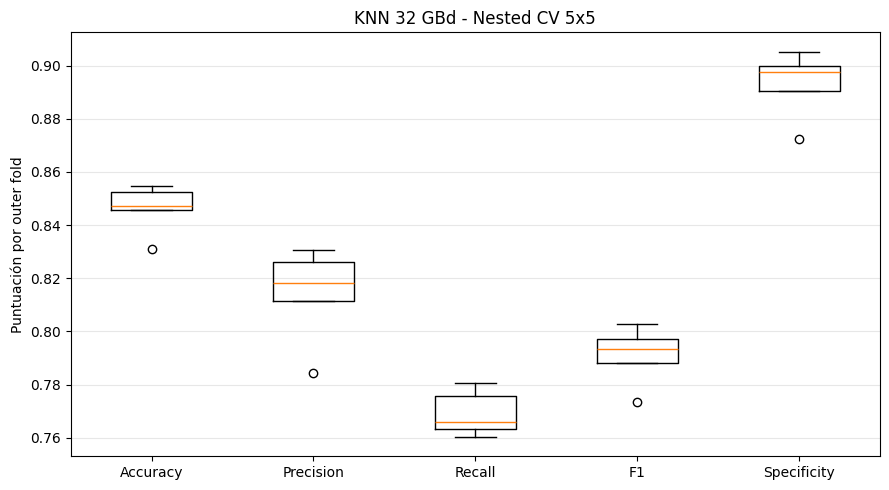


MÉTRICAS GLOBALES OUT-OF-FOLD (OOF)
OOF Accuracy:    0.8463
OOF Precision:   0.8139
OOF Recall:      0.7691
OOF F1:          0.7909
OOF Specificity: 0.8932

CLASSIFICATION REPORT OOF:
              precision    recall  f1-score   support

      NORMAL       0.86      0.89      0.88      5804
      ALARMA       0.81      0.77      0.79      3526

    accuracy                           0.85      9330
   macro avg       0.84      0.83      0.83      9330
weighted avg       0.85      0.85      0.85      9330


Matriz de confusión OOF:
[[5184  620]
 [ 814 2712]]


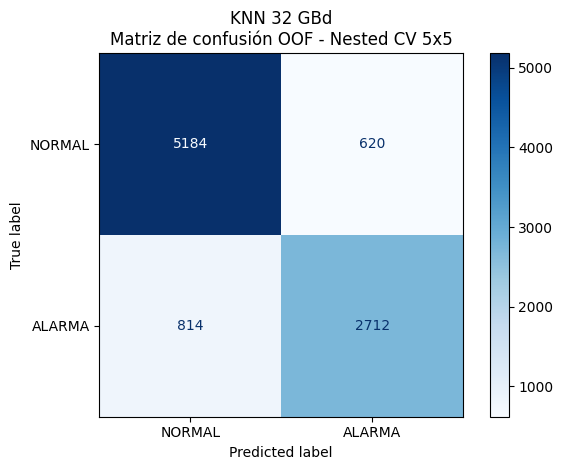


Predicciones OOF guardadas.

HIPERPARÁMETROS POR OUTER FOLD
 fold  knn__n_neighbors  knn__p knn__weights  inner_cv_best_f1
    1                15       1     distance          0.794513
    2                15       1      uniform          0.786829
    3                15       1      uniform          0.790871
    4                15       1     distance          0.786013
    5                15       1     distance          0.790014

TIEMPO DE INFERENCIA - OUTER CV
Inference Mean: 10.589 µs/muestra
Inference Std:  1.140 µs/muestra
Mediciones totales: 500
Tiempo por muestra dentro de un batch. Incluye StandardScaler y KNN.predict().

ENTRENANDO MODELO FINAL - KNN

Mejores parámetros modelo final:
{'knn__n_neighbors': 15, 'knn__p': 1, 'knn__weights': 'distance'}
F1 GridSearch final: 0.7912

CALCULANDO SHAP DEL MODELO FINAL
Background: 50 muestras
Muestras explicadas: 50


  0%|          | 0/50 [00:00<?, ?it/s]


31 CARACTERÍSTICAS ORDENADAS POR SHAP:
     feature mean_abs_shap importance_percent
  channel_sp      0.054360             11.58%
   I_peak3_y      0.030964              6.60%
   Q_peak2_y      0.028776              6.13%
   Q_peak3_y      0.026981              5.75%
   I_peak2_y      0.025704              5.48%
   Q_peak1_y      0.020853              4.44%
 I_valley3_y      0.020797              4.43%
   Q_peak4_y      0.020226              4.31%
 Q_valley3_y      0.020058              4.27%
   I_peak1_y      0.019906              4.24%
   I_peak4_y      0.017724              3.78%
 Q_valley1_y      0.015984              3.41%
 I_valley1_y      0.013580              2.89%
 I_valley2_y      0.012877              2.74%
Q_broadening      0.012350              2.63%
 Q_valley2_x      0.011736              2.50%
 Q_valley2_y      0.011257              2.40%
   I_peak2_x      0.011100              2.36%
   I_peak1_x      0.010458              2.23%
   Q_peak4_x      0.010176              

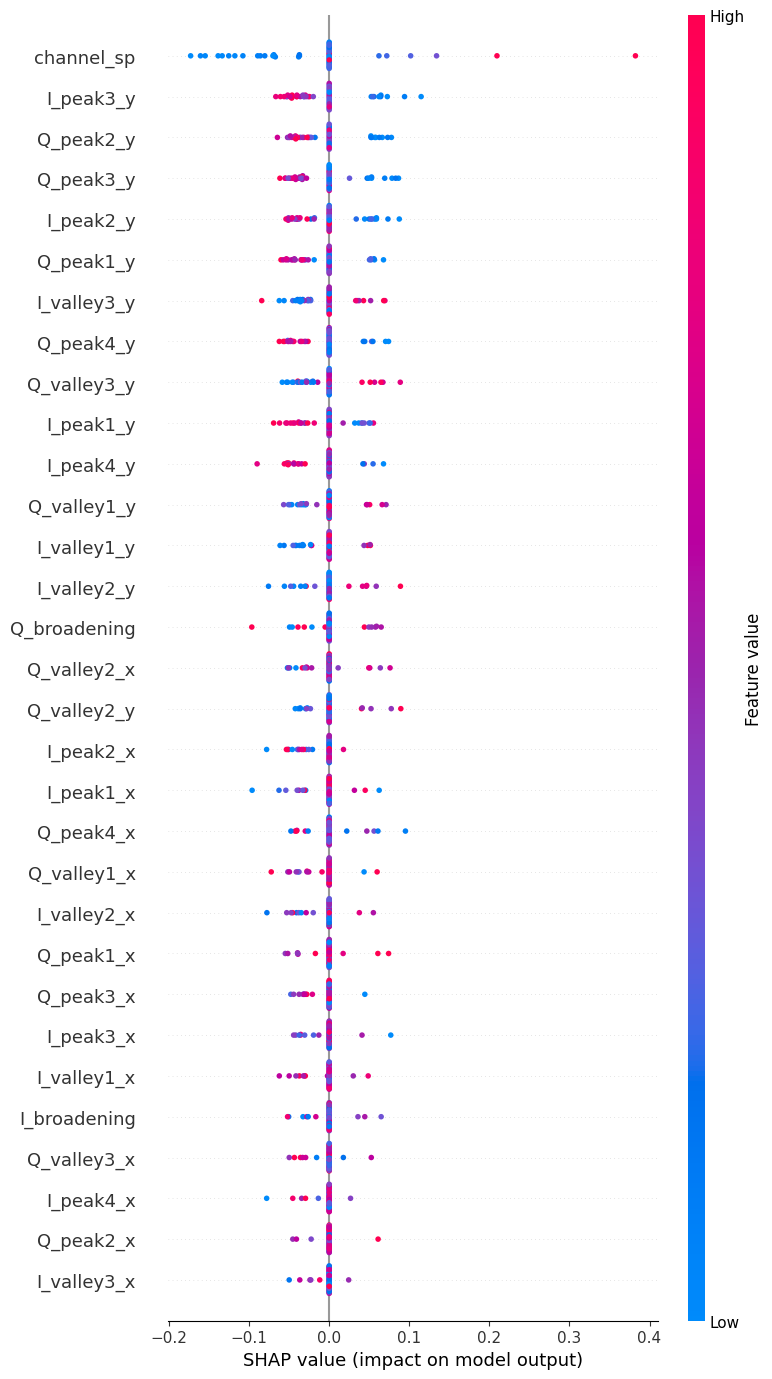

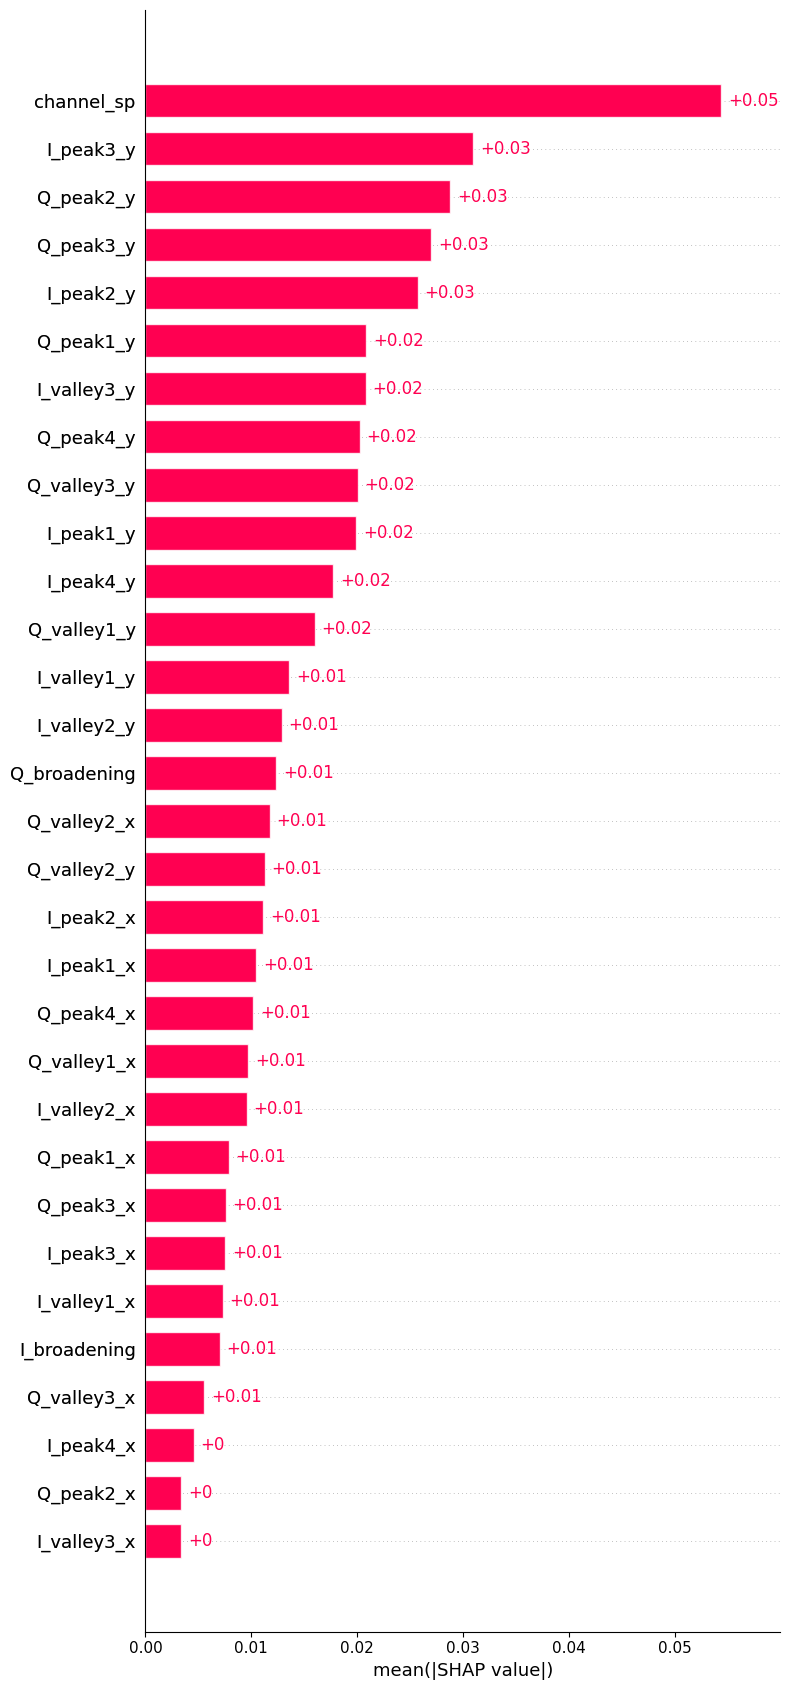

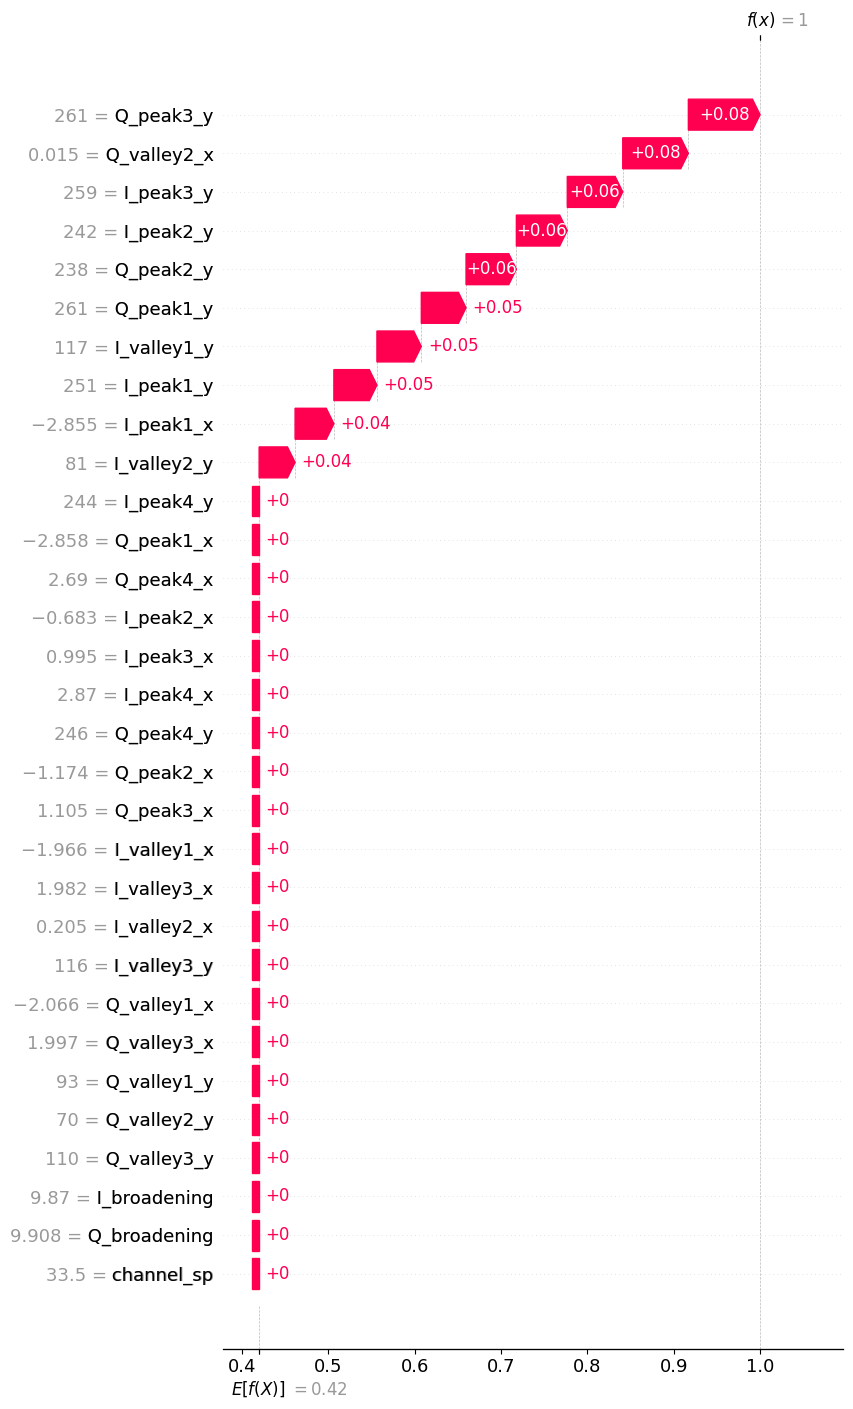


RESUMEN FINAL - KNN 32 GBd NESTED CV 5x5
Outer CV ACCURACY    : 0.8463 ± 0.0083
Outer CV PRECISION   : 0.8142 ± 0.0163
Outer CV RECALL      : 0.7691 ± 0.0077
Outer CV F1          : 0.7910 ± 0.0099
Outer CV SPECIFICITY : 0.8932 ± 0.0114

OOF Accuracy: 0.8463
OOF Precision: 0.8139
OOF Recall: 0.7691
OOF F1: 0.7909
OOF Specificity: 0.8932

Inference Mean: 10.589 µs/muestra
Inference Std: 1.140 µs/muestra

Archivos generados:
1. knn_osnr_32GBd_nested_outer_folds.csv
2. knn_osnr_32GBd_nested_oof_predictions.csv
3. knn_osnr_32GBd_nested_best_params.csv
4. knn_osnr_32GBd_nested_importancia_shap.csv

PROCESO COMPLETADO.


In [ ]:

"""
============================================================
CLASIFICACIÓN OSNR 32 GBd - KNN
NESTED CROSS-VALIDATION 5x5 + PREDICCIONES OUTER-FOLD
MÉTRICAS, MATRIZ DE CONFUSIÓN, SHAP Y TIEMPO DE INFERENCIA
============================================================

CLASES:
    0 = NORMAL: OSNR > 23 dB
    1 = ALARMA: OSNR <= 23 dB

DATASET:
    30 características I/Q
    1 característica channel_sp
    1 columna OSNR (target continuo)

METODOLOGÍA:
    - Outer CV: StratifiedKFold, 5 folds
    - Inner CV: StratifiedKFold, 5 folds
    - GridSearchCV dentro de cada outer train
    - Predicciones OOF en los outer tests
    - Métricas por fold y métricas globales OOF
    - Tiempos de inferencia por outer fold
    - Modelo final entrenado con todos los datos
    - SHAP para interpretar el modelo final

IMPORTANTE:
    Esta implementación divide por filas.
    Si existen muestras del mismo escenario experimental,
    conviene considerar Nested CV agrupada por escenario.
"""

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap

from sklearn.model_selection import (
    StratifiedKFold,
    GridSearchCV
)

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

# ============================================================
# 1. CONFIGURACIÓN GENERAL
# ============================================================

CSV_PATH = "matriz32GBd_clasifi_correct.csv"

THRESHOLD_DB = 23.0

SEED = 42

N_OUTER_FOLDS = 5
N_INNER_FOLDS = 5

N_REPETITIONS = 100

SHAP_BACKGROUND = 50
SHAP_EXPLAIN = 50
SHAP_NSAMPLES = 300

# ============================================================
# 2. NOMBRES DE LAS 31 CARACTERÍSTICAS
# ============================================================

feature_names = (
    [f"I_peak{k}_x" for k in range(1, 5)] +
    [f"I_peak{k}_y" for k in range(1, 5)] +
    [f"Q_peak{k}_x" for k in range(1, 5)] +
    [f"Q_peak{k}_y" for k in range(1, 5)] +
    [f"I_valley{k}_x" for k in range(1, 4)] +
    [f"I_valley{k}_y" for k in range(1, 4)] +
    [f"Q_valley{k}_x" for k in range(1, 4)] +
    [f"Q_valley{k}_y" for k in range(1, 4)] +
    ["I_broadening", "Q_broadening", "channel_sp"]
)

assert len(feature_names) == 31

# ============================================================
# 3. CARGAR Y VALIDAR DATASET
# ============================================================

matriz = pd.read_csv(
    CSV_PATH,
    header=None
)

if matriz.shape[1] != 32:
    raise ValueError(
        f"Se esperaban 32 columnas; "
        f"se encontraron {matriz.shape[1]}"
    )

matriz = matriz.apply(
    pd.to_numeric,
    errors="raise"
)

if not np.isfinite(matriz.to_numpy()).all():
    raise ValueError(
        "El dataset contiene NaN o infinitos."
    )

# Las primeras 31 columnas contienen las características.
X = matriz.iloc[:, :31].copy()
X.columns = feature_names

# Última columna: OSNR continuo.
y_osnr = matriz.iloc[:, 31].to_numpy()

# Clasificación binaria.
y = (y_osnr <= THRESHOLD_DB).astype(int)

n_samples = len(y)

class_counts = np.bincount(
    y,
    minlength=2
)

if class_counts.min() < N_OUTER_FOLDS:
    raise ValueError(
        "No hay suficientes muestras por clase "
        "para los folds externos."
    )

print("=" * 65)
print("INFORMACIÓN DEL DATASET")
print("=" * 65)

print(f"Dataset: {CSV_PATH}")
print(f"Muestras: {n_samples}")
print(f"Características: {X.shape[1]}")
print(f"NORMAL: {class_counts[0]}")
print(f"ALARMA: {class_counts[1]}")
print(f"Umbral OSNR: {THRESHOLD_DB} dB")

print(
    "\nMonitoreo asistido: "
    "channel_sp se utiliza como entrada."
)

# ============================================================
# 4. DEFINIR PIPELINE KNN Y GRID
# ============================================================

def build_pipeline():
    """
    Construye un pipeline nuevo.

    StandardScaler se ajusta exclusivamente
    con los datos de entrenamiento de cada fold.
    """

    return Pipeline([
        (
            "scaler",
            StandardScaler()
        ),
        (
            "knn",
            KNeighborsClassifier()
        )
    ])


# Mismo grid de tu código original.
param_grid = {
    "knn__n_neighbors": [3, 5, 7, 11, 15],
    "knn__weights": [
        "uniform",
        "distance"
    ],
    "knn__p": [
        1,
        2
    ]
}

# ============================================================
# 5. CONFIGURAR OUTER CV
# ============================================================

outer_cv = StratifiedKFold(
    n_splits=N_OUTER_FOLDS,
    shuffle=True,
    random_state=SEED
)

# Cada muestra recibirá exactamente una predicción
# cuando pertenezca al test de un outer fold.

oof_predictions = np.full(
    n_samples,
    -1,
    dtype=int
)

# Probabilidad de ALARMA.
oof_probabilities = np.full(
    n_samples,
    np.nan,
    dtype=float
)

# Identificador del fold de evaluación.
oof_fold = np.full(
    n_samples,
    -1,
    dtype=int
)

outer_results = []
outer_best_params = []
outer_inference_times = []

print("\n" + "=" * 65)
print("INICIANDO NESTED CV 5x5 - KNN 32 GBd")
print("=" * 65)

# ============================================================
# 6. BUCLE PRINCIPAL: OUTER CROSS-VALIDATION
# ============================================================

for fold, (train_idx, test_idx) in enumerate(
    outer_cv.split(X, y),
    start=1
):

    print("\n" + "=" * 65)
    print(f"OUTER FOLD {fold}/{N_OUTER_FOLDS}")
    print("=" * 65)

    # --------------------------------------------------------
    # 6.1 SEPARACIÓN EXTERNA
    # --------------------------------------------------------

    X_outer_train = X.iloc[train_idx]
    X_outer_test = X.iloc[test_idx]

    y_outer_train = y[train_idx]
    y_outer_test = y[test_idx]

    print(
        f"Outer Train: {len(X_outer_train)} muestras"
    )

    print(
        f"Outer Test:  {len(X_outer_test)} muestras"
    )

    # --------------------------------------------------------
    # 6.2 INNER CV: GRIDSEARCHCV
    # --------------------------------------------------------

    inner_cv = StratifiedKFold(
        n_splits=N_INNER_FOLDS,
        shuffle=True,
        random_state=SEED + fold
    )

    search = GridSearchCV(
        estimator=build_pipeline(),
        param_grid=param_grid,
        scoring="f1",
        cv=inner_cv,
        n_jobs=-1,
        refit=True,
        return_train_score=False
    )

    print("\nBuscando mejores hiperparámetros...")

    # GridSearchCV solo recibe el outer train.
    # El outer test NO participa en la selección.
    search.fit(
        X_outer_train,
        y_outer_train
    )

    best_knn = search.best_estimator_

    print("\nMejores hiperparámetros:")
    print(search.best_params_)

    print(
        f"Inner CV Best F1: "
        f"{search.best_score_:.4f}"
    )

    outer_best_params.append({
        "fold": fold,
        **search.best_params_,
        "inner_cv_best_f1": search.best_score_
    })

    # --------------------------------------------------------
    # 6.3 PREDICCIONES OUTER-FOLD
    # --------------------------------------------------------

    y_outer_pred = best_knn.predict(
        X_outer_test
    )

    # Probabilidad de pertenecer a ALARMA (clase 1).
    y_outer_proba = best_knn.predict_proba(
        X_outer_test
    )[:, 1]

    # Guardar las predicciones en el orden original.
    oof_predictions[test_idx] = y_outer_pred

    oof_probabilities[test_idx] = y_outer_proba

    oof_fold[test_idx] = fold

    # --------------------------------------------------------
    # 6.4 MÉTRICAS DEL OUTER FOLD
    # --------------------------------------------------------

    tn, fp, fn, tp = confusion_matrix(
        y_outer_test,
        y_outer_pred,
        labels=[0, 1]
    ).ravel()

    accuracy = accuracy_score(
        y_outer_test,
        y_outer_pred
    )

    precision = precision_score(
        y_outer_test,
        y_outer_pred,
        zero_division=0
    )

    recall = recall_score(
        y_outer_test,
        y_outer_pred,
        zero_division=0
    )

    f1 = f1_score(
        y_outer_test,
        y_outer_pred,
        zero_division=0
    )

    specificity = (
        tn / (tn + fp)
        if (tn + fp) > 0
        else np.nan
    )

    # --------------------------------------------------------
    # 6.5 TIEMPO DE INFERENCIA
    # --------------------------------------------------------

    # Warm-up.
    _ = best_knn.predict(
        X_outer_test.iloc[
            :min(10, len(X_outer_test))
        ]
    )

    inference_times = np.empty(
        N_REPETITIONS
    )

    for rep in range(N_REPETITIONS):

        start = time.perf_counter()

        _ = best_knn.predict(
            X_outer_test
        )

        elapsed = (
            time.perf_counter() - start
        )

        inference_times[rep] = (
            elapsed / len(X_outer_test)
        )

    inference_mean_us = (
        inference_times.mean() * 1e6
    )

    inference_std_us = (
        inference_times.std() * 1e6
    )

    outer_inference_times.append(
        inference_times * 1e6
    )

    # --------------------------------------------------------
    # 6.6 GUARDAR RESULTADOS DEL FOLD
    # --------------------------------------------------------

    outer_results.append({
        "fold": fold,
        "n_train": len(train_idx),
        "n_test": len(test_idx),
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "specificity": specificity,
        "inference_mean_us": inference_mean_us,
        "inference_std_us": inference_std_us
    })

    print("\nMÉTRICAS OUTER FOLD:")

    print(f"Accuracy:    {accuracy:.4f}")
    print(f"Precision:   {precision:.4f}")
    print(f"Recall:      {recall:.4f}")
    print(f"F1:          {f1:.4f}")
    print(f"Specificity: {specificity:.4f}")

    print(
        f"Inference Mean: "
        f"{inference_mean_us:.3f} µs/muestra"
    )

    print(
        f"Inference Std:  "
        f"{inference_std_us:.3f} µs/muestra"
    )

# ============================================================
# 7. VALIDAR PREDICCIONES OOF
# ============================================================

if np.any(oof_predictions == -1):
    raise RuntimeError(
        "Existen muestras sin predicción OOF."
    )

if np.any(oof_fold == -1):
    raise RuntimeError(
        "Existen muestras sin fold asignado."
    )

if not np.isfinite(oof_probabilities).all():
    raise RuntimeError(
        "Existen probabilidades OOF inválidas."
    )

print("\nTodas las muestras tienen predicción OOF.")

# ============================================================
# 8. RESULTADOS POR OUTER FOLD
# ============================================================

results_df = pd.DataFrame(
    outer_results
)

print("\n" + "=" * 65)
print("RESULTADOS DE LOS 5 OUTER FOLDS")
print("=" * 65)

print(
    results_df.to_string(index=False)
)

results_df.to_csv(
    "knn_osnr_32GBd_nested_outer_folds.csv",
    index=False
)

# ============================================================
# 9. PROMEDIO ± DESVIACIÓN ESTÁNDAR OUTER CV
# ============================================================

print("\n" + "=" * 65)
print("OUTER CV - PROMEDIO ± DESVIACIÓN ESTÁNDAR")
print("=" * 65)

metrics = [
    "accuracy",
    "precision",
    "recall",
    "f1",
    "specificity"
]

for metric in metrics:

    values = results_df[
        metric
    ].to_numpy()

    print(
        f"{metric.upper():12s}: "
        f"{np.nanmean(values):.4f} ± "
        f"{np.nanstd(values):.4f}"
    )

# ============================================================
# 10. GRÁFICA DE MÉTRICAS OUTER CV
# ============================================================

plt.figure(figsize=(9, 5))

plt.boxplot(
    [
        results_df[m].values
        for m in metrics
    ],
    tick_labels=[
        "Accuracy",
        "Precision",
        "Recall",
        "F1",
        "Specificity"
    ]
)

plt.ylabel("Puntuación por outer fold")

plt.title(
    "KNN 32 GBd - Nested CV 5x5"
)

plt.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()
plt.show()
plt.close()

# ============================================================
# 11. MÉTRICAS GLOBALES OOF
# ============================================================

print("\n" + "=" * 65)
print("MÉTRICAS GLOBALES OUT-OF-FOLD (OOF)")
print("=" * 65)

tn, fp, fn, tp = confusion_matrix(
    y,
    oof_predictions,
    labels=[0, 1]
).ravel()

oof_accuracy = accuracy_score(
    y,
    oof_predictions
)

oof_precision = precision_score(
    y,
    oof_predictions,
    zero_division=0
)

oof_recall = recall_score(
    y,
    oof_predictions,
    zero_division=0
)

oof_f1 = f1_score(
    y,
    oof_predictions,
    zero_division=0
)

oof_specificity = (
    tn / (tn + fp)
    if (tn + fp) > 0
    else np.nan
)

print(
    f"OOF Accuracy:    {oof_accuracy:.4f}"
)

print(
    f"OOF Precision:   {oof_precision:.4f}"
)

print(
    f"OOF Recall:      {oof_recall:.4f}"
)

print(
    f"OOF F1:          {oof_f1:.4f}"
)

print(
    f"OOF Specificity: {oof_specificity:.4f}"
)

print("\nCLASSIFICATION REPORT OOF:")

print(
    classification_report(
        y,
        oof_predictions,
        labels=[0, 1],
        target_names=[
            "NORMAL",
            "ALARMA"
        ],
        zero_division=0
    )
)

# ============================================================
# 12. MATRIZ DE CONFUSIÓN OOF
# ============================================================

cm_oof = confusion_matrix(
    y,
    oof_predictions,
    labels=[0, 1]
)

print("\nMatriz de confusión OOF:")

print(cm_oof)

ConfusionMatrixDisplay(
    confusion_matrix=cm_oof,
    display_labels=[
        "NORMAL",
        "ALARMA"
    ]
).plot(
    cmap="Blues",
    values_format="d"
)

plt.title(
    "KNN 32 GBd\n"
    "Matriz de confusión OOF - Nested CV 5x5"
)

plt.tight_layout()
plt.show()
plt.close()

# ============================================================
# 13. GUARDAR PREDICCIONES OOF
# ============================================================

oof_df = pd.DataFrame({
    "sample_index": np.arange(n_samples),
    "outer_fold": oof_fold,
    "OSNR_dB": y_osnr,
    "true_class": y,
    "predicted_class": oof_predictions,
    "probability_alarm": oof_probabilities,
    "correct": (
        y == oof_predictions
    )
})

oof_df.to_csv(
    "knn_osnr_32GBd_nested_oof_predictions.csv",
    index=False
)

print("\nPredicciones OOF guardadas.")

# ============================================================
# 14. HIPERPARÁMETROS POR OUTER FOLD
# ============================================================

params_df = pd.DataFrame(
    outer_best_params
)

print("\n" + "=" * 65)
print("HIPERPARÁMETROS POR OUTER FOLD")
print("=" * 65)

print(
    params_df.to_string(index=False)
)

params_df.to_csv(
    "knn_osnr_32GBd_nested_best_params.csv",
    index=False
)

# ============================================================
# 15. TIEMPO DE INFERENCIA OUTER CV
# ============================================================

all_inference_times = np.concatenate(
    outer_inference_times
)

print("\n" + "=" * 65)
print("TIEMPO DE INFERENCIA - OUTER CV")
print("=" * 65)

print(
    f"Inference Mean: "
    f"{all_inference_times.mean():.3f} µs/muestra"
)

print(
    f"Inference Std:  "
    f"{all_inference_times.std():.3f} µs/muestra"
)

print(
    f"Mediciones totales: "
    f"{len(all_inference_times)}"
)

print(
    "Tiempo por muestra dentro de un batch. "
    "Incluye StandardScaler y KNN.predict()."
)

# ============================================================
# 16. ENTRENAR MODELO FINAL CON TODOS LOS DATOS
# ============================================================

# Este modelo se utiliza para SHAP.
# NO se utiliza para las métricas OOF.
#
# Se seleccionan nuevamente los hiperparámetros
# mediante GridSearchCV sobre todo el dataset.

print("\n" + "=" * 65)
print("ENTRENANDO MODELO FINAL - KNN")
print("=" * 65)

final_inner_cv = StratifiedKFold(
    n_splits=N_INNER_FOLDS,
    shuffle=True,
    random_state=SEED
)

final_search = GridSearchCV(
    estimator=build_pipeline(),
    param_grid=param_grid,
    scoring="f1",
    cv=final_inner_cv,
    n_jobs=-1,
    refit=True
)

final_search.fit(X, y)

final_knn = final_search.best_estimator_

print("\nMejores parámetros modelo final:")
print(final_search.best_params_)

print(
    f"F1 GridSearch final: "
    f"{final_search.best_score_:.4f}"
)

# ============================================================
# 17. SHAP - KERNELEXPLAINER
# ============================================================

# SHAP explica predict_proba[:, 1] del KNN final.
#
# SHAP positivo:
#    aumenta la probabilidad de ALARMA.
#
# SHAP negativo:
#    disminuye la probabilidad de ALARMA.
#
# Las muestras explicadas pertenecen al dataset
# utilizado para entrenar el modelo final.
# Por tanto, este SHAP es descriptivo, no OOF.

print("\n" + "=" * 65)
print("CALCULANDO SHAP DEL MODELO FINAL")
print("=" * 65)

background = X.sample(
    n=min(SHAP_BACKGROUND, len(X)),
    random_state=SEED
)

explained = X.sample(
    n=min(SHAP_EXPLAIN, len(X)),
    random_state=SEED + 1
)

print(
    f"Background: {len(background)} muestras"
)

print(
    f"Muestras explicadas: {len(explained)}"
)

def knn_alarm_probability(data):
    """
    Adaptador para SHAP.

    Conserva nombres y orden de las 31 columnas.
    Devuelve P(ALARMA), correspondiente a la clase 1.
    """

    frame = pd.DataFrame(
        np.asarray(data),
        columns=feature_names
    )

    return final_knn.predict_proba(frame)[:, 1]


explainer = shap.KernelExplainer(
    knn_alarm_probability,
    background
)

raw = explainer.shap_values(
    explained,
    nsamples=SHAP_NSAMPLES
)

shap_values = np.asarray(raw)

if shap_values.shape != explained.shape:
    raise ValueError(
        f"Forma SHAP inesperada: "
        f"{shap_values.shape}. "
        f"Se esperaba {explained.shape}."
    )

# ============================================================
# 18. IMPORTANCIA GLOBAL SHAP
# ============================================================

mean_abs = np.mean(
    np.abs(shap_values),
    axis=0
)

imp_df = pd.DataFrame({
    "feature": feature_names,
    "mean_abs_shap": mean_abs
})

imp_df = imp_df.sort_values(
    "mean_abs_shap",
    ascending=False
).reset_index(drop=True)

total = imp_df[
    "mean_abs_shap"
].sum()

if total > 0:

    imp_df["importance_percent"] = (
        100 *
        imp_df["mean_abs_shap"] /
        total
    )

else:

    imp_df["importance_percent"] = 0.0

print("\n31 CARACTERÍSTICAS ORDENADAS POR SHAP:")

print(
    imp_df.to_string(
        index=False,
        formatters={
            "mean_abs_shap": "{:.6f}".format,
            "importance_percent": "{:.2f}%".format
        }
    )
)

print(
    f"\nSuma de porcentajes: "
    f"{imp_df['importance_percent'].sum():.2f}%"
)

print("\nTOP 5 SHAP:")

print(
    imp_df.head(5).to_string(
        index=False
    )
)

imp_df.to_csv(
    "knn_osnr_32GBd_nested_importancia_shap.csv",
    index=False
)

# ============================================================
# 19. CREAR OBJETO SHAP EXPLANATION
# ============================================================

expected_value = float(
    np.asarray(
        explainer.expected_value
    ).item()
)

explanation = shap.Explanation(
    values=shap_values,
    base_values=np.full(
        len(explained),
        expected_value
    ),
    data=explained.to_numpy(),
    feature_names=feature_names
)

# ============================================================
# 20. GRÁFICAS SHAP
# ============================================================

# Beeswarm
shap.plots.beeswarm(
    explanation,
    max_display=31,
    show=False
)

plt.tight_layout()
plt.show()
plt.close()

# Bar plot
shap.plots.bar(
    explanation,
    max_display=31,
    show=False
)

plt.tight_layout()
plt.show()
plt.close()

# Waterfall de la primera muestra explicada.
shap.plots.waterfall(
    explanation[0],
    max_display=31,
    show=False
)

plt.show()
plt.close()

# ============================================================
# 21. RESUMEN FINAL
# ============================================================

print("\n" + "=" * 65)
print("RESUMEN FINAL - KNN 32 GBd NESTED CV 5x5")
print("=" * 65)

for metric in metrics:

    values = results_df[
        metric
    ].to_numpy()

    print(
        f"Outer CV {metric.upper():12s}: "
        f"{np.nanmean(values):.4f} ± "
        f"{np.nanstd(values):.4f}"
    )

print(
    f"\nOOF Accuracy: "
    f"{oof_accuracy:.4f}"
)

print(
    f"OOF Precision: "
    f"{oof_precision:.4f}"
)

print(
    f"OOF Recall: "
    f"{oof_recall:.4f}"
)

print(
    f"OOF F1: "
    f"{oof_f1:.4f}"
)

print(
    f"OOF Specificity: "
    f"{oof_specificity:.4f}"
)

print(
    f"\nInference Mean: "
    f"{all_inference_times.mean():.3f} µs/muestra"
)

print(
    f"Inference Std: "
    f"{all_inference_times.std():.3f} µs/muestra"
)

print("\nArchivos generados:")

print("1. knn_osnr_32GBd_nested_outer_folds.csv")
print("2. knn_osnr_32GBd_nested_oof_predictions.csv")
print("3. knn_osnr_32GBd_nested_best_params.csv")
print("4. knn_osnr_32GBd_nested_importancia_shap.csv")

print("\nPROCESO COMPLETADO.")


#Ahora para 16GBd

## RDF 16GBd para clasificar OSNR CON CHANNEL SPACING

INFORMACIÓN DEL DATASET
Dataset: matriz16GBd_clas.csv
Muestras: 243
Características: 31
NORMAL: 141
ALARMA: 102
Umbral OSNR: 23.0 dB

Monitoreo asistido: channel_sp se utiliza como característica de entrada.

Combinaciones de hiperparámetros: 162

INICIANDO NESTED CV 5x5 - RANDOM FOREST

OUTER FOLD 1/5
Outer Train: 194 muestras
Outer Test:  49 muestras

Buscando mejores hiperparámetros...

Mejores hiperparámetros:
{'max_depth': None, 'max_features': 'log2', 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 400}
Inner CV Best F1: 0.9232

MÉTRICAS OUTER FOLD:
Accuracy:    0.8980
Precision:   0.9000
Recall:      0.8571
F1:          0.8780
Specificity: 0.9286
Inference Mean: 140.000 µs/muestra
Inference Std:  1.333 µs/muestra

OUTER FOLD 2/5
Outer Train: 194 muestras
Outer Test:  49 muestras

Buscando mejores hiperparámetros...

Mejores hiperparámetros:
{'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 100}
Inner CV Best

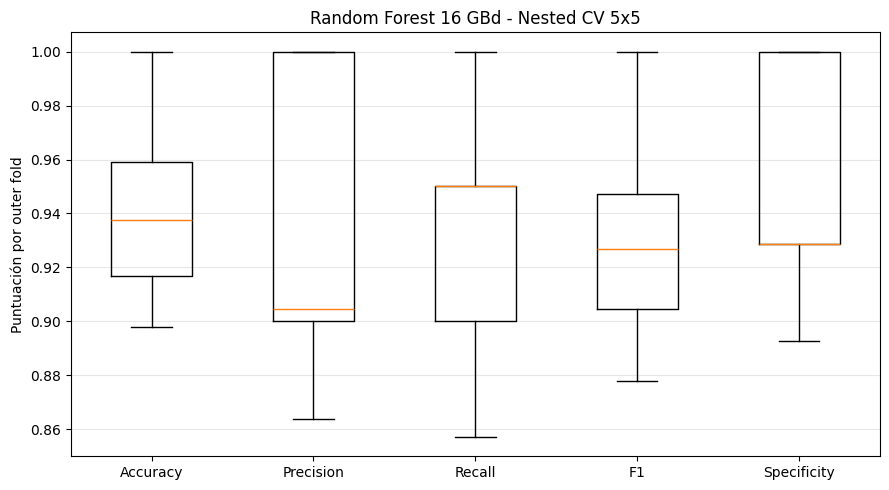


MÉTRICAS GLOBALES OUT-OF-FOLD (OOF)
OOF Accuracy:    0.9424
OOF Precision:   0.9314
OOF Recall:      0.9314
OOF F1:          0.9314
OOF Specificity: 0.9504

CLASSIFICATION REPORT OOF:
              precision    recall  f1-score   support

      NORMAL       0.95      0.95      0.95       141
      ALARMA       0.93      0.93      0.93       102

    accuracy                           0.94       243
   macro avg       0.94      0.94      0.94       243
weighted avg       0.94      0.94      0.94       243


Matriz de confusión OOF:
[[134   7]
 [  7  95]]


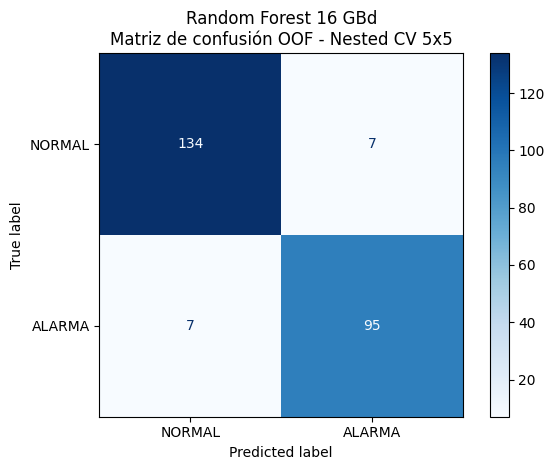


Predicciones OOF guardadas.

HIPERPARÁMETROS POR OUTER FOLD
 fold max_depth max_features  min_samples_leaf  min_samples_split  n_estimators  inner_cv_best_f1
    1      None         log2                 1                  2           400          0.923225
    2      None         sqrt                 1                  2           100          0.914773
    3      None         sqrt                 1                  2           200          0.917238
    4      None         sqrt                 1                  2           100          0.939535
    5      None         sqrt                 1                  2           400          0.931836

TIEMPO DE INFERENCIA - OUTER CV
Inference Mean: 88.416 µs/muestra
Inference Std:  44.313 µs/muestra
Mediciones totales: 500
Tiempo por muestra dentro de un batch. No es latencia individual.

ENTRENANDO MODELO FINAL - RANDOM FOREST

Mejores parámetros modelo final:
{'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'min_samples_split

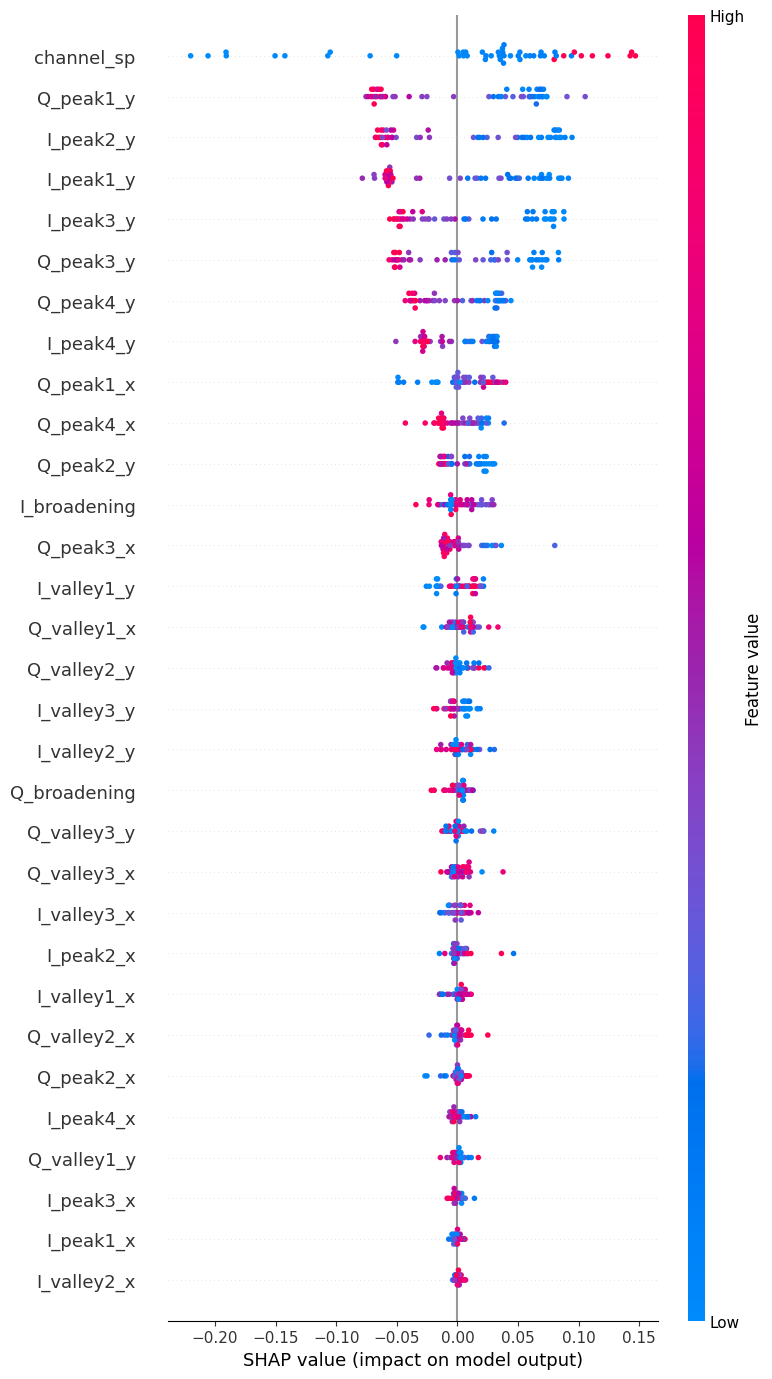

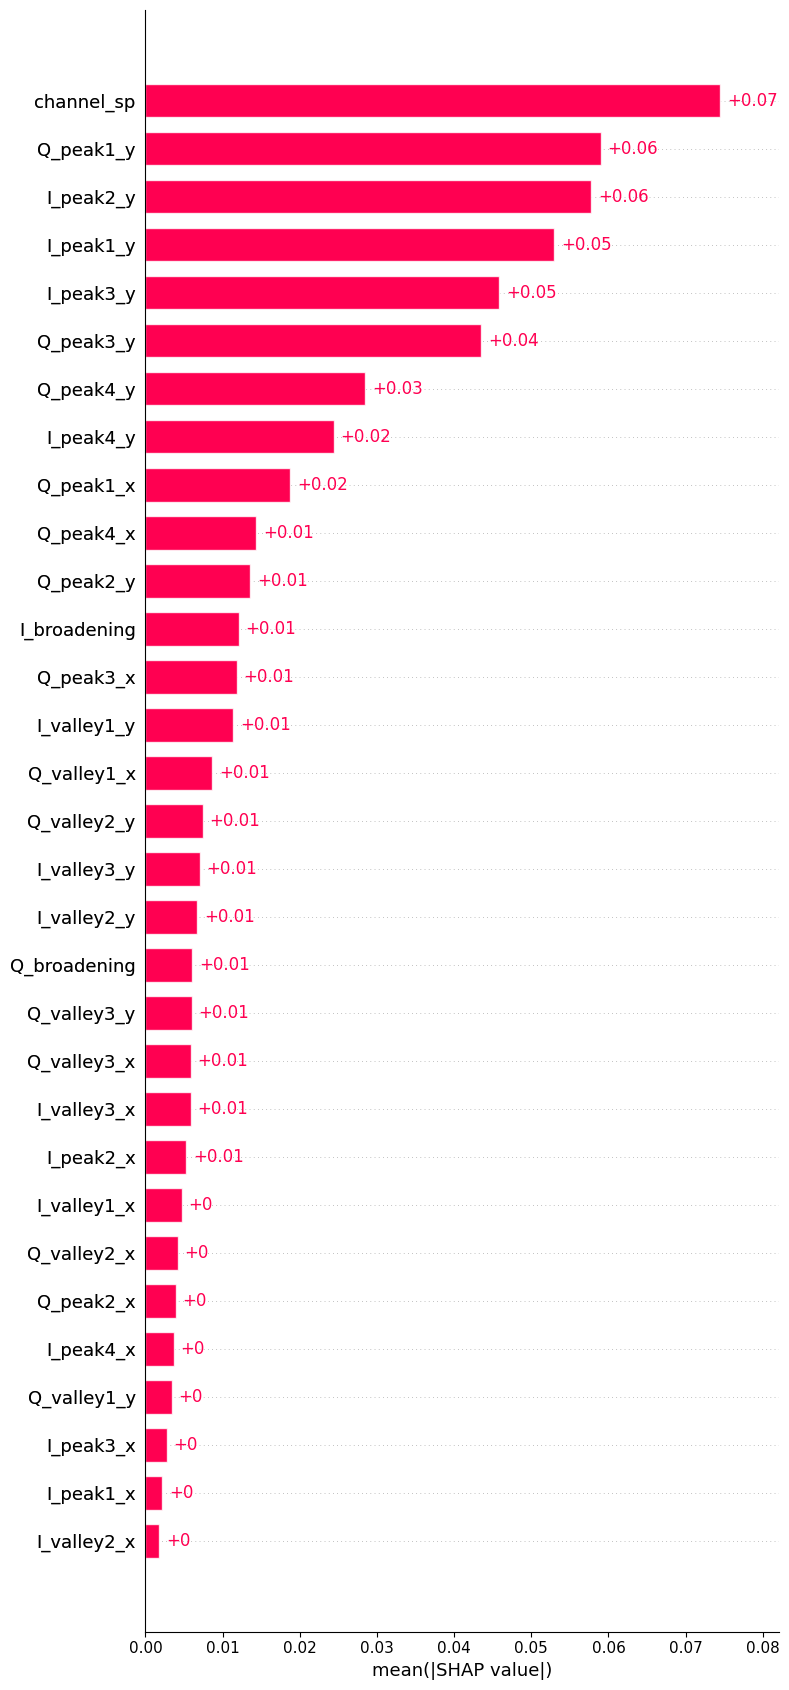

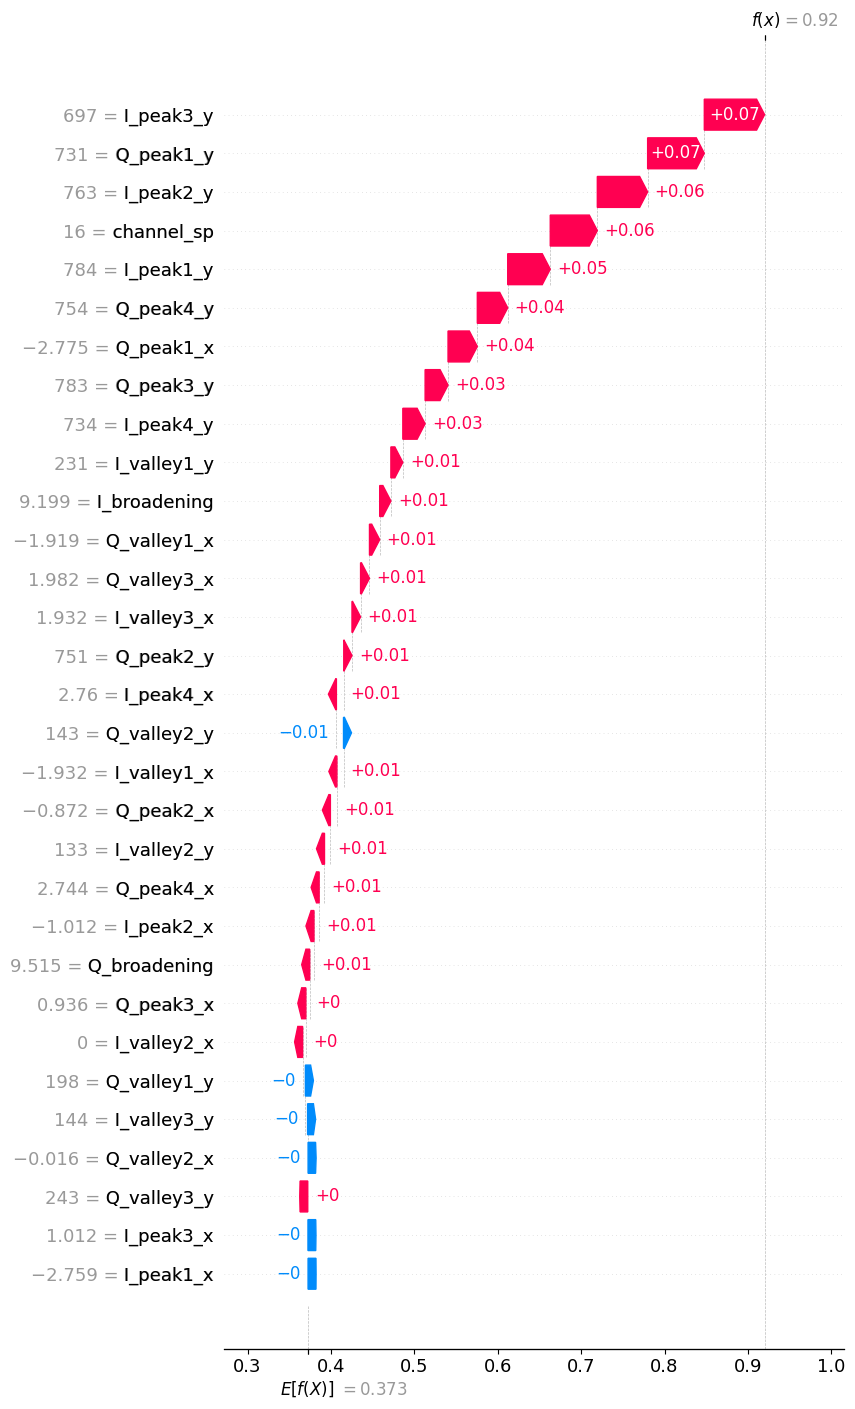


RESUMEN FINAL - RF 16 GBd NESTED CV 5x5
Outer CV Accuracy: 0.9423 ± 0.0354
Outer CV Precision: 0.9337 ± 0.0560
Outer CV Recall: 0.9314 ± 0.0488
Outer CV F1: 0.9314 ± 0.0413
Outer CV Specificity: 0.9500 ± 0.0429
OOF Accuracy: 0.9424
OOF Precision: 0.9314
OOF Recall: 0.9314
OOF F1: 0.9314
OOF Specificity: 0.9504
Inference Mean: 88.416 µs/muestra
Inference Std: 44.313 µs/muestra

Archivos generados:
1. rf_osnr_16GBd_nested_outer_folds.csv
2. rf_osnr_16GBd_nested_oof_predictions.csv
3. rf_osnr_16GBd_nested_best_params.csv
4. rf_osnr_16GBd_nested_importancia_shap.csv

PROCESO COMPLETADO.


In [ ]:

"""
===============================================================
CLASIFICACIÓN OSNR 16 GBd - RANDOM FOREST
NESTED CROSS-VALIDATION 5x5 + PREDICCIONES OUTER-FOLD
MÉTRICAS, SHAP Y TIEMPO DE INFERENCIA
===============================================================

CLASES:
    0 = NORMAL: OSNR > 23 dB
    1 = ALARMA: OSNR <= 23 dB

DATASET:
    30 características I/Q
    1 característica channel_sp
    1 columna OSNR (target continuo original)

METODOLOGÍA:
    - Outer CV: 5 folds estratificados
    - Inner CV: 5 folds estratificados
    - GridSearchCV dentro de cada outer train
    - Predicciones OOF sobre todas las muestras
    - Métricas por fold y métricas OOF globales
    - Tiempos de inferencia por outer fold
    - Modelo final entrenado con todo el dataset
    - SHAP para interpretar el modelo final

IMPORTANTE:
    La CV es estratificada por filas, no por escenario.
    Si hay muestras dependientes del mismo experimento,
    considerar validación agrupada.
"""

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap

from sklearn.model_selection import (
    StratifiedKFold,
    GridSearchCV
)

from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

# =============================================================
# 1. CONFIGURACIÓN GENERAL
# =============================================================

CSV_PATH = "matriz16GBd_clas.csv"

THRESHOLD_DB = 23.0

SEED = 42

N_OUTER_FOLDS = 5
N_INNER_FOLDS = 5

N_REPETITIONS = 100

SHAP_BACKGROUND = 50
SHAP_EXPLAIN = 50

# =============================================================
# 2. NOMBRES DE LAS 31 CARACTERÍSTICAS
# =============================================================

feature_names = (
    [f"I_peak{k}_x" for k in range(1, 5)] +
    [f"I_peak{k}_y" for k in range(1, 5)] +
    [f"Q_peak{k}_x" for k in range(1, 5)] +
    [f"Q_peak{k}_y" for k in range(1, 5)] +
    [f"I_valley{k}_x" for k in range(1, 4)] +
    [f"I_valley{k}_y" for k in range(1, 4)] +
    [f"Q_valley{k}_x" for k in range(1, 4)] +
    [f"Q_valley{k}_y" for k in range(1, 4)] +
    ["I_broadening", "Q_broadening", "channel_sp"]
)

assert len(feature_names) == 31

# =============================================================
# 3. CARGAR Y VALIDAR DATASET
# =============================================================

matriz = pd.read_csv(
    CSV_PATH,
    header=None
)

if matriz.shape[1] != 32:
    raise ValueError(
        f"Se esperaban 32 columnas; "
        f"se encontraron {matriz.shape[1]}"
    )

matriz = matriz.apply(
    pd.to_numeric,
    errors="raise"
)

if not np.isfinite(matriz.to_numpy()).all():
    raise ValueError(
        "El dataset contiene NaN o infinitos."
    )

# Las primeras 31 columnas son las características.
X = matriz.iloc[:, :31].copy()
X.columns = feature_names

# La columna 32 contiene el OSNR continuo.
y_osnr = matriz.iloc[:, 31].to_numpy()

# Convertir OSNR a clasificación binaria.
y = (y_osnr <= THRESHOLD_DB).astype(int)

n_samples = len(y)

class_counts = np.bincount(
    y,
    minlength=2
)

if class_counts.min() < N_OUTER_FOLDS:
    raise ValueError(
        "No hay suficientes muestras por clase "
        "para realizar los outer folds."
    )

print("=" * 65)
print("INFORMACIÓN DEL DATASET")
print("=" * 65)

print(f"Dataset: {CSV_PATH}")
print(f"Muestras: {n_samples}")
print(f"Características: {X.shape[1]}")
print(f"NORMAL: {class_counts[0]}")
print(f"ALARMA: {class_counts[1]}")
print(f"Umbral OSNR: {THRESHOLD_DB} dB")

print(
    "\nMonitoreo asistido: channel_sp "
    "se utiliza como característica de entrada."
)

# =============================================================
# 4. MODELO Y GRID DE HIPERPARÁMETROS
# =============================================================

def build_rf():
    """
    Crea una instancia nueva de Random Forest.

    n_jobs=1 evita paralelismo anidado:
    GridSearchCV utiliza n_jobs=-1.
    """
    return RandomForestClassifier(
        random_state=SEED,
        n_jobs=1
    )


# Se conserva el mismo grid del código original.
param_grid = {
    "n_estimators": [100, 200, 400],
    "max_depth": [None, 10, 20],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4],
    "max_features": ["sqrt", "log2"]
}

n_combinations = (
    len(param_grid["n_estimators"]) *
    len(param_grid["max_depth"]) *
    len(param_grid["min_samples_split"]) *
    len(param_grid["min_samples_leaf"]) *
    len(param_grid["max_features"])
)

print("\nCombinaciones de hiperparámetros:", n_combinations)

# =============================================================
# 5. CONFIGURAR OUTER CROSS-VALIDATION
# =============================================================

outer_cv = StratifiedKFold(
    n_splits=N_OUTER_FOLDS,
    shuffle=True,
    random_state=SEED
)

# Cada posición corresponde a una fila del dataset.
# Se rellena únicamente cuando esa muestra está
# en el outer test de un fold.

oof_predictions = np.full(
    n_samples,
    -1,
    dtype=int
)

# Probabilidad de ALARMA para cada muestra OOF.
oof_probabilities = np.full(
    n_samples,
    np.nan,
    dtype=float
)

# Número de fold donde se evaluó cada muestra.
oof_fold = np.full(
    n_samples,
    -1,
    dtype=int
)

outer_results = []
outer_best_params = []
outer_inference_times = []

print("\n" + "=" * 65)
print("INICIANDO NESTED CV 5x5 - RANDOM FOREST")
print("=" * 65)

# =============================================================
# 6. BUCLE PRINCIPAL: OUTER CV
# =============================================================

for fold, (train_idx, test_idx) in enumerate(
    outer_cv.split(X, y),
    start=1
):

    print("\n" + "=" * 65)
    print(f"OUTER FOLD {fold}/{N_OUTER_FOLDS}")
    print("=" * 65)

    # ---------------------------------------------------------
    # 6.1 DATOS DE ENTRENAMIENTO Y TEST EXTERNOS
    # ---------------------------------------------------------

    X_outer_train = X.iloc[train_idx]
    X_outer_test = X.iloc[test_idx]

    y_outer_train = y[train_idx]
    y_outer_test = y[test_idx]

    print(
        f"Outer Train: {len(X_outer_train)} muestras"
    )

    print(
        f"Outer Test:  {len(X_outer_test)} muestras"
    )

    # ---------------------------------------------------------
    # 6.2 INNER CV: GRIDSEARCHCV
    # ---------------------------------------------------------

    inner_cv = StratifiedKFold(
        n_splits=N_INNER_FOLDS,
        shuffle=True,
        random_state=SEED + fold
    )

    search = GridSearchCV(
        estimator=build_rf(),
        param_grid=param_grid,
        scoring="f1",
        cv=inner_cv,
        n_jobs=-1,
        refit=True,
        return_train_score=False
    )

    print("\nBuscando mejores hiperparámetros...")

    # IMPORTANTE:
    # GridSearchCV solo recibe el outer train.
    # El outer test permanece completamente separado.
    search.fit(
        X_outer_train,
        y_outer_train
    )

    best_rf = search.best_estimator_

    print("\nMejores hiperparámetros:")
    print(search.best_params_)

    print(
        f"Inner CV Best F1: "
        f"{search.best_score_:.4f}"
    )

    outer_best_params.append({
        "fold": fold,
        **search.best_params_,
        "inner_cv_best_f1": search.best_score_
    })

    # ---------------------------------------------------------
    # 6.3 PREDICCIONES OUTER-FOLD
    # ---------------------------------------------------------

    y_outer_pred = best_rf.predict(
        X_outer_test
    )

    # Probabilidad de pertenecer a ALARMA (clase 1).
    y_outer_proba = best_rf.predict_proba(
        X_outer_test
    )[:, 1]

    # Guardar en las posiciones originales.
    oof_predictions[test_idx] = y_outer_pred

    oof_probabilities[test_idx] = y_outer_proba

    oof_fold[test_idx] = fold

    # ---------------------------------------------------------
    # 6.4 MÉTRICAS DEL OUTER FOLD
    # ---------------------------------------------------------

    tn, fp, fn, tp = confusion_matrix(
        y_outer_test,
        y_outer_pred,
        labels=[0, 1]
    ).ravel()

    accuracy = accuracy_score(
        y_outer_test,
        y_outer_pred
    )

    precision = precision_score(
        y_outer_test,
        y_outer_pred,
        zero_division=0
    )

    recall = recall_score(
        y_outer_test,
        y_outer_pred,
        zero_division=0
    )

    f1 = f1_score(
        y_outer_test,
        y_outer_pred,
        zero_division=0
    )

    specificity = (
        tn / (tn + fp)
        if (tn + fp) > 0
        else np.nan
    )

    # ---------------------------------------------------------
    # 6.5 TIEMPO DE INFERENCIA
    # ---------------------------------------------------------

    # Warm-up antes de medir.
    _ = best_rf.predict(
        X_outer_test.iloc[
            :min(10, len(X_outer_test))
        ]
    )

    inference_times = np.empty(
        N_REPETITIONS
    )

    for rep in range(N_REPETITIONS):

        start = time.perf_counter()

        _ = best_rf.predict(X_outer_test)

        elapsed = (
            time.perf_counter() - start
        )

        inference_times[rep] = (
            elapsed / len(X_outer_test)
        )

    inference_mean_us = (
        inference_times.mean() * 1e6
    )

    inference_std_us = (
        inference_times.std() * 1e6
    )

    outer_inference_times.append(
        inference_times * 1e6
    )

    # ---------------------------------------------------------
    # 6.6 GUARDAR RESULTADOS
    # ---------------------------------------------------------

    outer_results.append({
        "fold": fold,
        "n_train": len(train_idx),
        "n_test": len(test_idx),
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "specificity": specificity,
        "inference_mean_us": inference_mean_us,
        "inference_std_us": inference_std_us
    })

    print("\nMÉTRICAS OUTER FOLD:")

    print(f"Accuracy:    {accuracy:.4f}")
    print(f"Precision:   {precision:.4f}")
    print(f"Recall:      {recall:.4f}")
    print(f"F1:          {f1:.4f}")
    print(f"Specificity: {specificity:.4f}")

    print(
        f"Inference Mean: "
        f"{inference_mean_us:.3f} µs/muestra"
    )

    print(
        f"Inference Std:  "
        f"{inference_std_us:.3f} µs/muestra"
    )

# =============================================================
# 7. VERIFICAR PREDICCIONES OOF
# =============================================================

if np.any(oof_predictions == -1):
    raise RuntimeError(
        "Existen muestras sin predicción OOF."
    )

if np.any(oof_fold == -1):
    raise RuntimeError(
        "Existen muestras sin outer fold asignado."
    )

if not np.isfinite(oof_probabilities).all():
    raise RuntimeError(
        "Existen probabilidades OOF inválidas."
    )

print("\nTodas las muestras tienen predicción OOF.")

# =============================================================
# 8. RESULTADOS POR OUTER FOLD
# =============================================================

results_df = pd.DataFrame(
    outer_results
)

print("\n" + "=" * 65)
print("RESULTADOS DE LOS 5 OUTER FOLDS")
print("=" * 65)

print(
    results_df.to_string(index=False)
)

results_df.to_csv(
    "rf_osnr_16GBd_nested_outer_folds.csv",
    index=False
)

# =============================================================
# 9. PROMEDIO Y DESVIACIÓN ESTÁNDAR OUTER CV
# =============================================================

print("\n" + "=" * 65)
print("OUTER CV - PROMEDIO ± DESVIACIÓN ESTÁNDAR")
print("=" * 65)

metrics = [
    "accuracy",
    "precision",
    "recall",
    "f1",
    "specificity"
]

for metric in metrics:

    values = results_df[
        metric
    ].to_numpy()

    print(
        f"{metric.upper():12s}: "
        f"{np.nanmean(values):.4f} ± "
        f"{np.nanstd(values):.4f}"
    )

# =============================================================
# 10. GRÁFICA DE MÉTRICAS OUTER CV
# =============================================================

plt.figure(figsize=(9, 5))

plt.boxplot(
    [
        results_df[m].values
        for m in metrics
    ],
    tick_labels=[
        "Accuracy",
        "Precision",
        "Recall",
        "F1",
        "Specificity"
    ]
)

plt.ylabel("Puntuación por outer fold")

plt.title(
    "Random Forest 16 GBd - Nested CV 5x5"
)

plt.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()
plt.show()
plt.close()

# =============================================================
# 11. MÉTRICAS GLOBALES OOF
# =============================================================

print("\n" + "=" * 65)
print("MÉTRICAS GLOBALES OUT-OF-FOLD (OOF)")
print("=" * 65)

tn, fp, fn, tp = confusion_matrix(
    y,
    oof_predictions,
    labels=[0, 1]
).ravel()

oof_accuracy = accuracy_score(
    y,
    oof_predictions
)

oof_precision = precision_score(
    y,
    oof_predictions,
    zero_division=0
)

oof_recall = recall_score(
    y,
    oof_predictions,
    zero_division=0
)

oof_f1 = f1_score(
    y,
    oof_predictions,
    zero_division=0
)

oof_specificity = (
    tn / (tn + fp)
    if (tn + fp) > 0
    else np.nan
)

print(
    f"OOF Accuracy:    {oof_accuracy:.4f}"
)

print(
    f"OOF Precision:   {oof_precision:.4f}"
)

print(
    f"OOF Recall:      {oof_recall:.4f}"
)

print(
    f"OOF F1:          {oof_f1:.4f}"
)

print(
    f"OOF Specificity: {oof_specificity:.4f}"
)

print("\nCLASSIFICATION REPORT OOF:")

print(
    classification_report(
        y,
        oof_predictions,
        labels=[0, 1],
        target_names=[
            "NORMAL",
            "ALARMA"
        ],
        zero_division=0
    )
)

# =============================================================
# 12. MATRIZ DE CONFUSIÓN OOF
# =============================================================

cm_oof = confusion_matrix(
    y,
    oof_predictions,
    labels=[0, 1]
)

print("\nMatriz de confusión OOF:")

print(cm_oof)

ConfusionMatrixDisplay(
    confusion_matrix=cm_oof,
    display_labels=[
        "NORMAL",
        "ALARMA"
    ]
).plot(
    cmap="Blues",
    values_format="d"
)

plt.title(
    "Random Forest 16 GBd\n"
    "Matriz de confusión OOF - Nested CV 5x5"
)

plt.tight_layout()
plt.show()
plt.close()

# =============================================================
# 13. GUARDAR PREDICCIONES OOF
# =============================================================

oof_df = pd.DataFrame({
    "sample_index": np.arange(n_samples),
    "outer_fold": oof_fold,
    "OSNR_dB": y_osnr,
    "true_class": y,
    "predicted_class": oof_predictions,
    "probability_alarm": oof_probabilities,
    "correct": (
        y == oof_predictions
    )
})

oof_df.to_csv(
    "rf_osnr_16GBd_nested_oof_predictions.csv",
    index=False
)

print("\nPredicciones OOF guardadas.")

# =============================================================
# 14. HIPERPARÁMETROS POR OUTER FOLD
# =============================================================

params_df = pd.DataFrame(
    outer_best_params
)

print("\n" + "=" * 65)
print("HIPERPARÁMETROS POR OUTER FOLD")
print("=" * 65)

print(
    params_df.to_string(index=False)
)

params_df.to_csv(
    "rf_osnr_16GBd_nested_best_params.csv",
    index=False
)

# =============================================================
# 15. TIEMPO DE INFERENCIA OUTER CV
# =============================================================

all_inference_times = np.concatenate(
    outer_inference_times
)

print("\n" + "=" * 65)
print("TIEMPO DE INFERENCIA - OUTER CV")
print("=" * 65)

print(
    f"Inference Mean: "
    f"{all_inference_times.mean():.3f} µs/muestra"
)

print(
    f"Inference Std:  "
    f"{all_inference_times.std():.3f} µs/muestra"
)

print(
    f"Mediciones totales: "
    f"{len(all_inference_times)}"
)

print(
    "Tiempo por muestra dentro de un batch. "
    "No es latencia individual."
)

# =============================================================
# 16. ENTRENAR MODELO FINAL CON TODOS LOS DATOS
# =============================================================

# Este modelo se utiliza para SHAP.
# NO se utiliza para las métricas OOF.
#
# Se seleccionan nuevamente los hiperparámetros
# mediante GridSearchCV sobre todo el dataset.

print("\n" + "=" * 65)
print("ENTRENANDO MODELO FINAL - RANDOM FOREST")
print("=" * 65)

final_inner_cv = StratifiedKFold(
    n_splits=N_INNER_FOLDS,
    shuffle=True,
    random_state=SEED
)

final_search = GridSearchCV(
    estimator=build_rf(),
    param_grid=param_grid,
    scoring="f1",
    cv=final_inner_cv,
    n_jobs=-1,
    refit=True
)

final_search.fit(X, y)

final_rf = final_search.best_estimator_

print("\nMejores parámetros modelo final:")
print(final_search.best_params_)

print(
    f"F1 GridSearch final: "
    f"{final_search.best_score_:.4f}"
)

# =============================================================
# 17. SHAP - TREEEXPLAINER
# =============================================================

# Explicamos P(ALARMA) = P(clase 1).
#
# SHAP positivo:
#    aumenta la probabilidad de ALARMA.
#
# SHAP negativo:
#    reduce la probabilidad de ALARMA.
#
# Las muestras explicadas fueron utilizadas
# para entrenar el modelo final.
# Por eso este SHAP es descriptivo y NO OOF.

print("\n" + "=" * 65)
print("CALCULANDO SHAP DEL MODELO FINAL")
print("=" * 65)

background = X.sample(
    n=min(SHAP_BACKGROUND, len(X)),
    random_state=SEED
)

explained = X.sample(
    n=min(SHAP_EXPLAIN, len(X)),
    random_state=SEED + 1
)

print(
    f"Background: {len(background)} muestras"
)

print(
    f"Muestras explicadas: {len(explained)}"
)

explainer = shap.TreeExplainer(
    final_rf,
    data=background,
    feature_perturbation="interventional",
    model_output="probability"
)

raw = explainer.shap_values(
    explained,
    check_additivity=False
)

# Diferentes versiones de SHAP devuelven:
#
# Versión antigua:
#   lista [SHAP clase 0, SHAP clase 1]
#
# Versión reciente:
#   array (n_muestras, n_features, n_clases)

if isinstance(raw, list):

    shap_values = np.asarray(
        raw[1]
    )

else:

    arr = np.asarray(raw)

    if arr.ndim == 3 and arr.shape[2] == 2:

        shap_values = arr[:, :, 1]

    else:

        shap_values = arr

if shap_values.shape != explained.shape:
    raise ValueError(
        f"Forma SHAP inesperada: "
        f"{shap_values.shape}. "
        f"Se esperaba {explained.shape}."
    )

# Valor base de probabilidad ALARMA.
base = np.asarray(
    explainer.expected_value
)

base_alarm = float(
    base[1]
    if base.size == 2
    else base.item()
)

# =============================================================
# 18. IMPORTANCIA GLOBAL SHAP
# =============================================================

mean_abs = np.mean(
    np.abs(shap_values),
    axis=0
)

imp_df = pd.DataFrame({
    "feature": feature_names,
    "mean_abs_shap": mean_abs
})

imp_df = imp_df.sort_values(
    "mean_abs_shap",
    ascending=False
).reset_index(drop=True)

total = imp_df[
    "mean_abs_shap"
].sum()

if total > 0:

    imp_df["importance_percent"] = (
        100 *
        imp_df["mean_abs_shap"] /
        total
    )

else:

    imp_df["importance_percent"] = 0.0

print("\n31 CARACTERÍSTICAS ORDENADAS POR SHAP:")

print(
    imp_df.to_string(
        index=False,
        formatters={
            "mean_abs_shap": "{:.6f}".format,
            "importance_percent": "{:.2f}%".format
        }
    )
)

print(
    f"\nSuma de porcentajes: "
    f"{imp_df['importance_percent'].sum():.2f}%"
)

print("\nTOP 5 SHAP:")

print(
    imp_df.head(5).to_string(
        index=False
    )
)

imp_df.to_csv(
    "rf_osnr_16GBd_nested_importancia_shap.csv",
    index=False
)

# =============================================================
# 19. CREAR OBJETO SHAP EXPLANATION
# =============================================================

explanation = shap.Explanation(
    values=shap_values,
    base_values=np.full(
        len(explained),
        base_alarm
    ),
    data=explained.to_numpy(),
    feature_names=feature_names
)

# =============================================================
# 20. GRÁFICAS SHAP
# =============================================================

# Beeswarm
shap.plots.beeswarm(
    explanation,
    max_display=31,
    show=False
)

plt.tight_layout()
plt.show()
plt.close()

# Bar plot
shap.plots.bar(
    explanation,
    max_display=31,
    show=False
)

plt.tight_layout()
plt.show()
plt.close()

# Waterfall: primera muestra explicada.
shap.plots.waterfall(
    explanation[0],
    max_display=31,
    show=False
)

plt.show()
plt.close()

# =============================================================
# 21. RESUMEN FINAL
# =============================================================

print("\n" + "=" * 65)
print("RESUMEN FINAL - RF 16 GBd NESTED CV 5x5")
print("=" * 65)

print(
    f"Outer CV Accuracy: "
    f"{results_df['accuracy'].mean():.4f} ± "
    f"{results_df['accuracy'].std(ddof=0):.4f}"
)

print(
    f"Outer CV Precision: "
    f"{results_df['precision'].mean():.4f} ± "
    f"{results_df['precision'].std(ddof=0):.4f}"
)

print(
    f"Outer CV Recall: "
    f"{results_df['recall'].mean():.4f} ± "
    f"{results_df['recall'].std(ddof=0):.4f}"
)

print(
    f"Outer CV F1: "
    f"{results_df['f1'].mean():.4f} ± "
    f"{results_df['f1'].std(ddof=0):.4f}"
)

print(
    f"Outer CV Specificity: "
    f"{results_df['specificity'].mean():.4f} ± "
    f"{results_df['specificity'].std(ddof=0):.4f}"
)

print(
    f"OOF Accuracy: "
    f"{oof_accuracy:.4f}"
)

print(
    f"OOF Precision: "
    f"{oof_precision:.4f}"
)

print(
    f"OOF Recall: "
    f"{oof_recall:.4f}"
)

print(
    f"OOF F1: "
    f"{oof_f1:.4f}"
)

print(
    f"OOF Specificity: "
    f"{oof_specificity:.4f}"
)

print(
    f"Inference Mean: "
    f"{all_inference_times.mean():.3f} µs/muestra"
)

print(
    f"Inference Std: "
    f"{all_inference_times.std():.3f} µs/muestra"
)

print("\nArchivos generados:")

print("1. rf_osnr_16GBd_nested_outer_folds.csv")
print("2. rf_osnr_16GBd_nested_oof_predictions.csv")
print("3. rf_osnr_16GBd_nested_best_params.csv")
print("4. rf_osnr_16GBd_nested_importancia_shap.csv")

print("\nPROCESO COMPLETADO.")


## SVM 16GBd para clasificar OSNR CON CHANNEL SPACING

INFORMACIÓN DEL DATASET
Dataset: matriz16GBd_clas.csv
Muestras: 243
Características: 31
NORMAL: 141
ALARMA: 102
Umbral OSNR: 23.0 dB

Monitoreo asistido: channel_sp se utiliza como entrada.

INICIANDO NESTED CV 5x5 - SVM 16 GBd

OUTER FOLD 1/5
Outer Train: 194 muestras
Outer Test:  49 muestras

Buscando mejores hiperparámetros...

Mejores hiperparámetros:
{'svm__C': 100, 'svm__class_weight': None, 'svm__gamma': 0.001}
Inner CV Best F1: 0.9028

MÉTRICAS OUTER FOLD:
Accuracy:    0.9388
Precision:   0.9091
Recall:      0.9524
F1:          0.9302
Specificity: 0.9286
Inference Mean: 10.947 µs/muestra
Inference Std:  0.563 µs/muestra

OUTER FOLD 2/5
Outer Train: 194 muestras
Outer Test:  49 muestras

Buscando mejores hiperparámetros...

Mejores hiperparámetros:
{'svm__C': 100, 'svm__class_weight': None, 'svm__gamma': 0.001}
Inner CV Best F1: 0.8947

MÉTRICAS OUTER FOLD:
Accuracy:    0.9796
Precision:   0.9545
Recall:      1.0000
F1:          0.9767
Specificity: 0.9643
Inference Mean: 11.070 

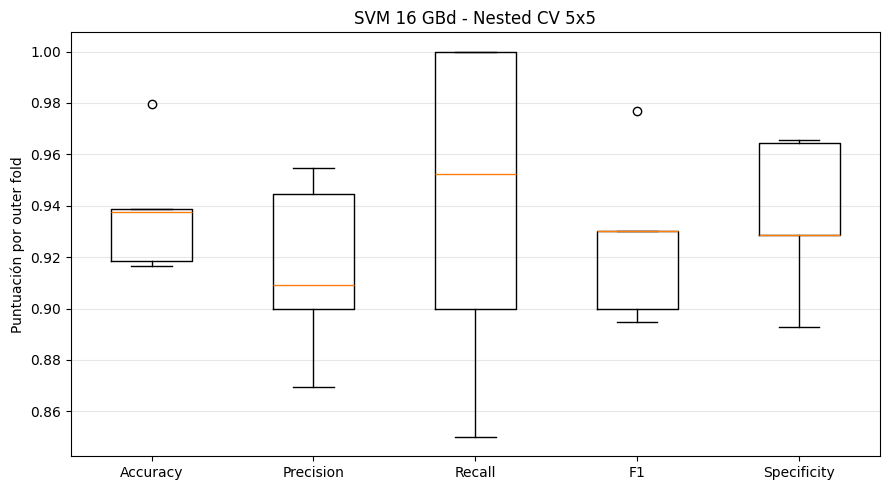


MÉTRICAS GLOBALES OUT-OF-FOLD (OOF)
OOF Accuracy:    0.9383
OOF Precision:   0.9143
OOF Recall:      0.9412
OOF F1:          0.9275
OOF Specificity: 0.9362

CLASSIFICATION REPORT OOF:
              precision    recall  f1-score   support

      NORMAL       0.96      0.94      0.95       141
      ALARMA       0.91      0.94      0.93       102

    accuracy                           0.94       243
   macro avg       0.94      0.94      0.94       243
weighted avg       0.94      0.94      0.94       243


Matriz de confusión OOF:
[[132   9]
 [  6  96]]


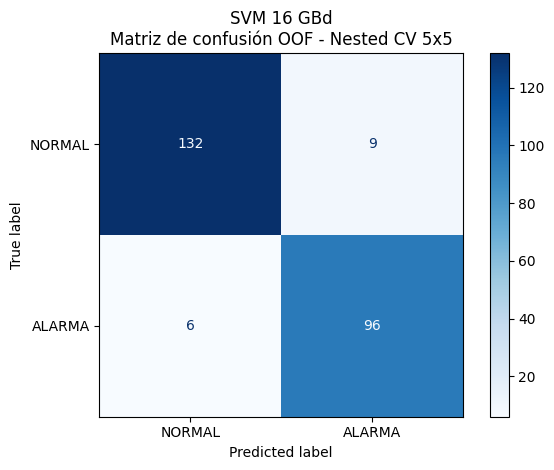


Predicciones OOF guardadas.

HIPERPARÁMETROS POR OUTER FOLD
 fold  svm__C svm__class_weight  svm__gamma  inner_cv_best_f1
    1     100              None       0.001          0.902813
    2     100              None       0.001          0.894727
    3     100              None       0.001          0.926312
    4     100              None       0.001          0.905084
    5     100              None       0.001          0.933657

TIEMPO DE INFERENCIA - OUTER CV
Inference Mean: 10.961 µs/muestra
Inference Std:  0.413 µs/muestra
Mediciones totales: 500
Tiempo por muestra dentro de un batch. Incluye StandardScaler y SVM.predict().

ENTRENANDO MODELO FINAL - SVM

Mejores parámetros modelo final:
{'svm__C': 100, 'svm__class_weight': None, 'svm__gamma': 0.001}
F1 GridSearch final: 0.9264

CALCULANDO SHAP DEL MODELO FINAL
Background: 50 muestras
Muestras explicadas: 50


  0%|          | 0/50 [00:00<?, ?it/s]


31 CARACTERÍSTICAS ORDENADAS POR SHAP:
     feature mean_abs_shap importance_percent
  channel_sp      0.650415             14.75%
   I_peak3_y      0.541873             12.29%
   I_peak2_y      0.474500             10.76%
   Q_peak3_y      0.394325              8.94%
 I_valley3_y      0.373469              8.47%
   Q_peak4_y      0.331932              7.53%
   Q_peak1_y      0.313794              7.12%
   I_peak1_y      0.276137              6.26%
 I_valley2_y      0.251208              5.70%
   Q_peak1_x      0.237339              5.38%
   Q_peak2_y      0.118420              2.69%
 Q_valley1_x      0.107220              2.43%
   Q_peak4_x      0.102286              2.32%
   I_peak3_x      0.053468              1.21%
 Q_valley2_x      0.036585              0.83%
 I_valley3_x      0.019528              0.44%
 Q_valley3_y      0.018550              0.42%
   I_peak1_x      0.018541              0.42%
 Q_valley3_x      0.017246              0.39%
 I_valley1_y      0.016416              

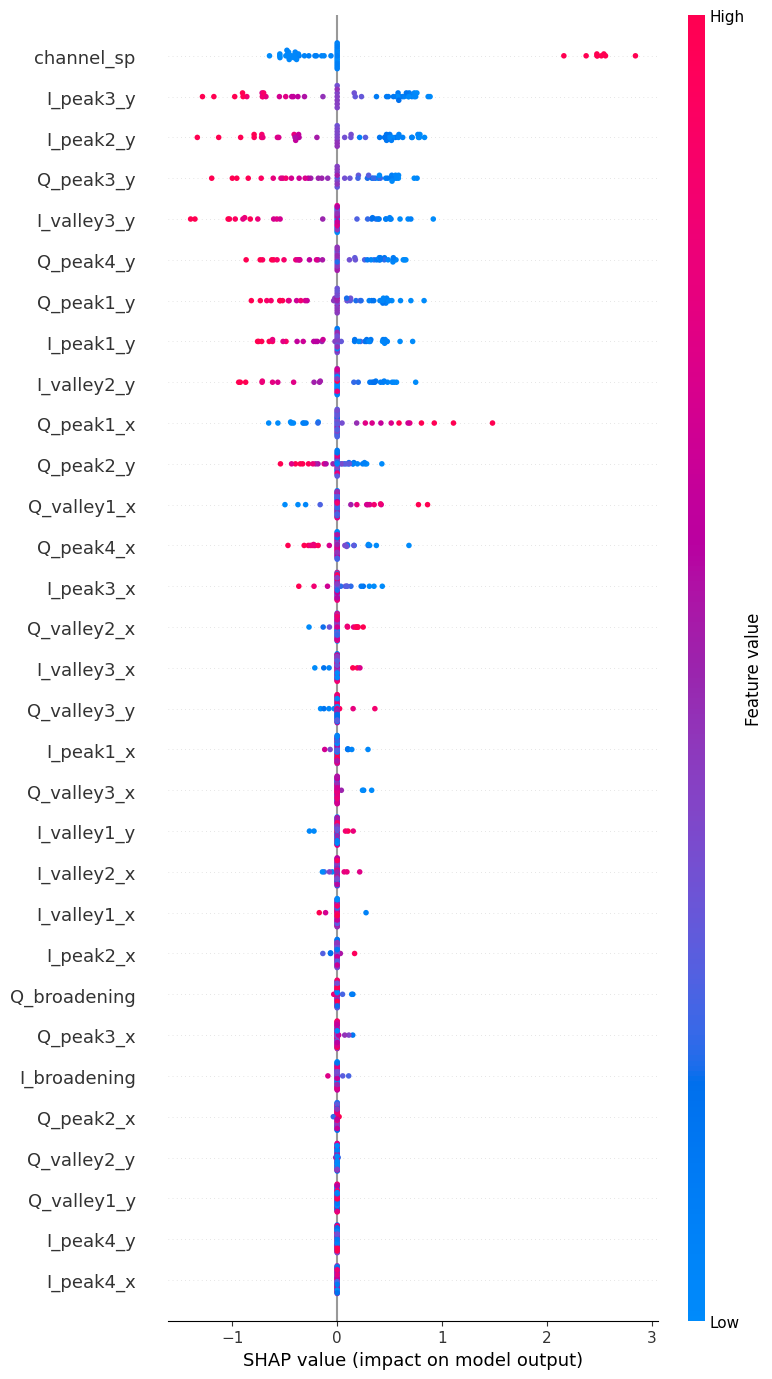

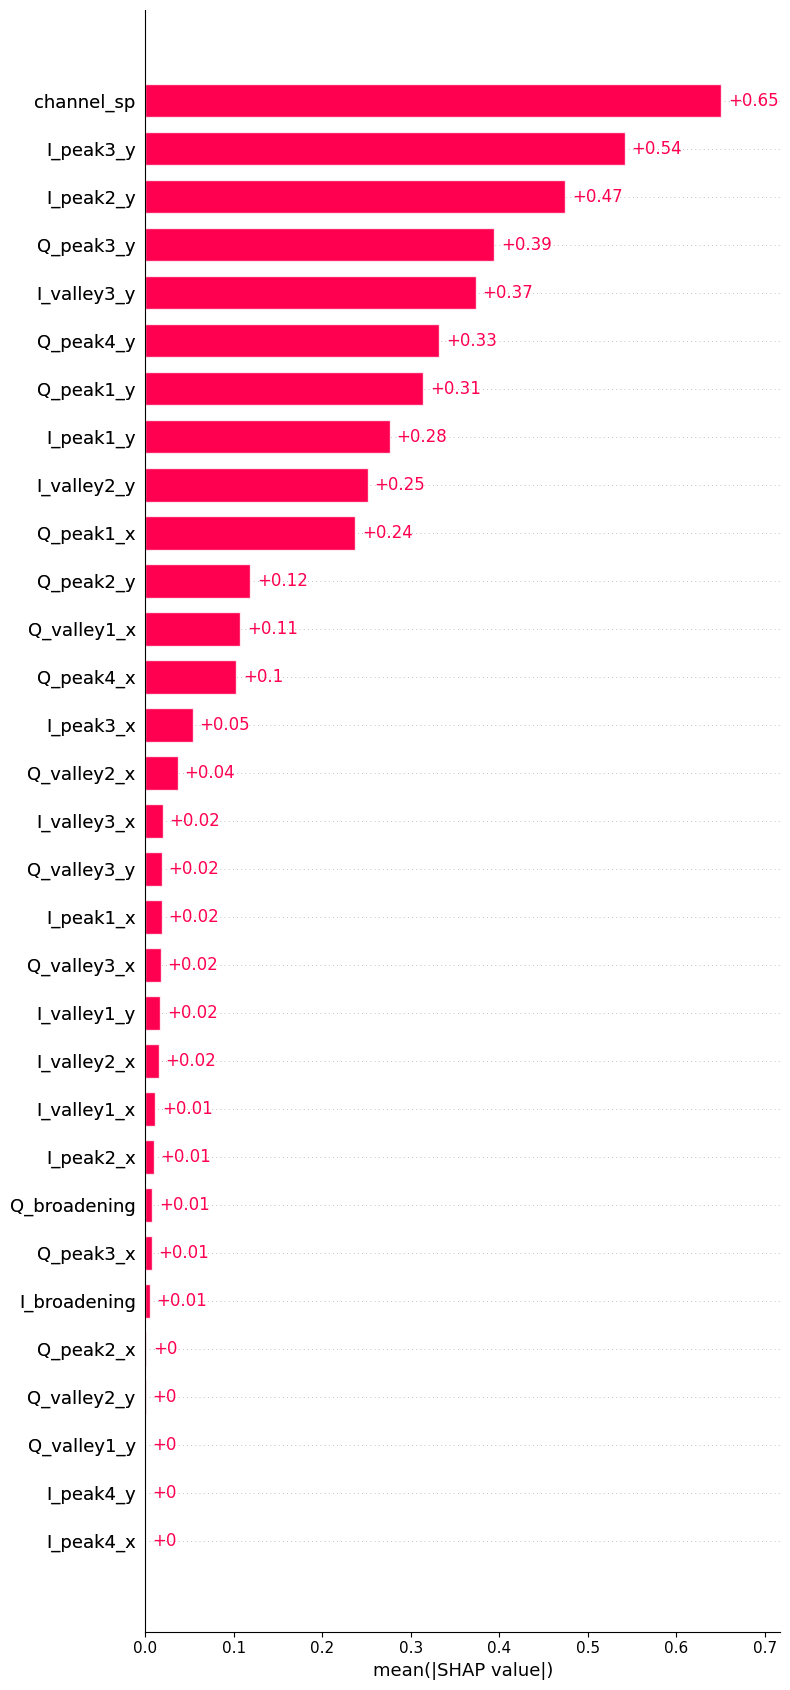

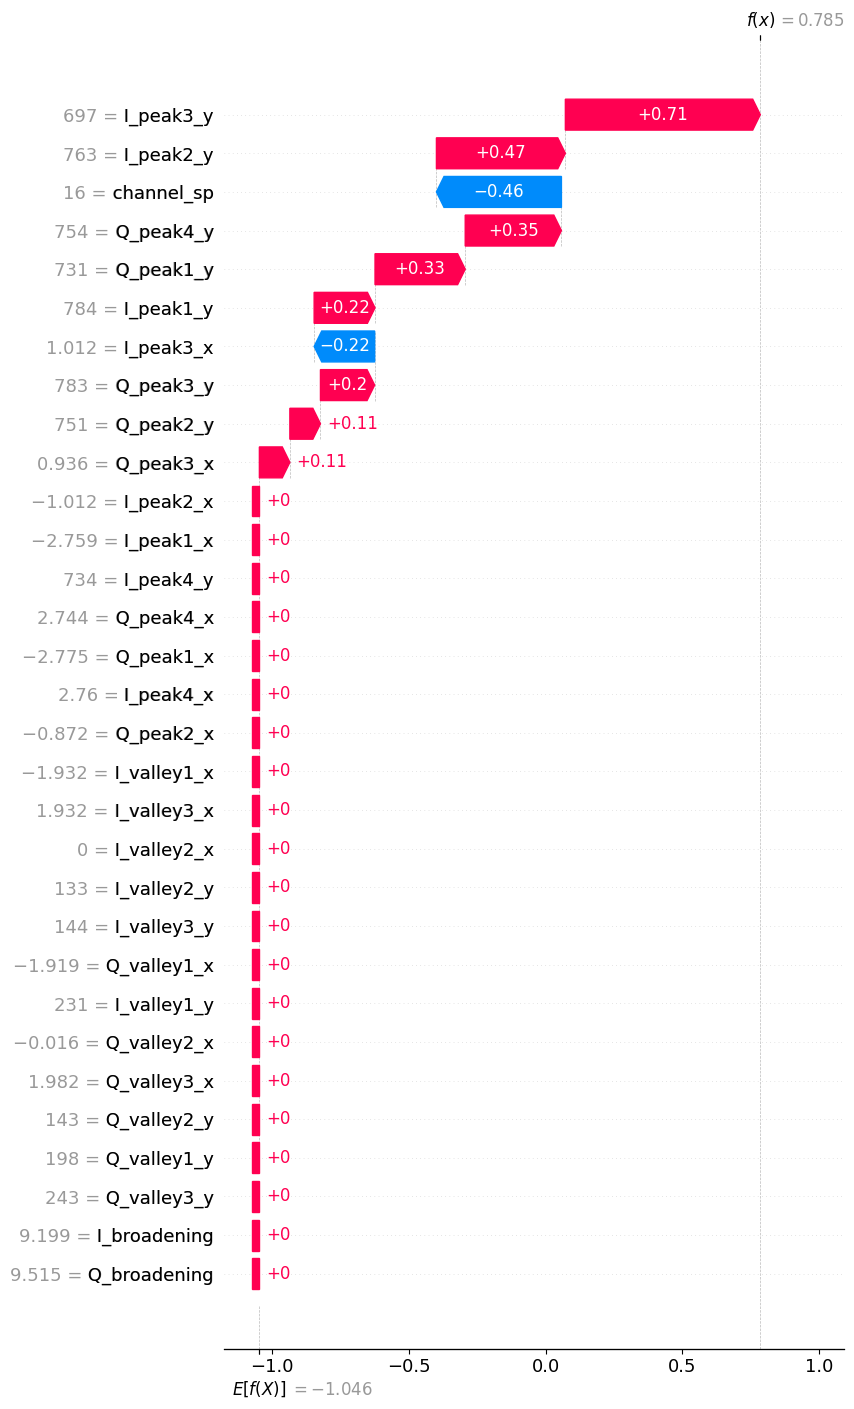


RESUMEN FINAL - SVM 16 GBd NESTED CV 5x5
Outer CV ACCURACY    : 0.9382 ± 0.0227
Outer CV PRECISION   : 0.9155 ± 0.0308
Outer CV RECALL      : 0.9405 ± 0.0584
Outer CV F1          : 0.9264 ± 0.0292
Outer CV SPECIFICITY : 0.9360 ± 0.0270

OOF Accuracy: 0.9383
OOF Precision: 0.9143
OOF Recall: 0.9412
OOF F1: 0.9275
OOF Specificity: 0.9362

Inference Mean: 10.961 µs/muestra
Inference Std: 0.413 µs/muestra

Archivos generados:
1. svm_osnr_16GBd_nested_outer_folds.csv
2. svm_osnr_16GBd_nested_oof_predictions.csv
3. svm_osnr_16GBd_nested_best_params.csv
4. svm_osnr_16GBd_nested_importancia_shap.csv

PROCESO COMPLETADO.


In [ ]:

"""
============================================================
CLASIFICACIÓN OSNR 16 GBd - SVM-RBF
NESTED CROSS-VALIDATION 5x5 + PREDICCIONES OUTER-FOLD
MÉTRICAS, MATRIZ DE CONFUSIÓN, SHAP Y TIEMPO DE INFERENCIA
============================================================

CLASES:
    0 = NORMAL: OSNR > 23 dB
    1 = ALARMA: OSNR <= 23 dB

DATASET:
    30 características I/Q
    1 característica channel_sp
    1 columna OSNR (target continuo)

METODOLOGÍA:
    - Outer CV: StratifiedKFold, 5 folds
    - Inner CV: StratifiedKFold, 5 folds
    - GridSearchCV en cada outer train
    - Predicciones OOF en los outer tests
    - Métricas por fold y métricas globales OOF
    - Tiempos de inferencia por outer fold
    - Modelo final entrenado con todos los datos
    - SHAP para interpretar el modelo final

IMPORTANTE:
    Esta implementación divide por filas.
    Si existen realizaciones del mismo escenario experimental,
    conviene considerar Nested CV agrupada por escenario.
"""

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap

from sklearn.model_selection import (
    StratifiedKFold,
    GridSearchCV
)

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

# ============================================================
# 1. CONFIGURACIÓN GENERAL
# ============================================================

CSV_PATH = "matriz16GBd_clas.csv"

THRESHOLD_DB = 23.0

SEED = 42

N_OUTER_FOLDS = 5
N_INNER_FOLDS = 5

N_REPETITIONS = 100

SHAP_BACKGROUND = 50
SHAP_EXPLAIN = 50
SHAP_NSAMPLES = 300

# ============================================================
# 2. NOMBRES DE LAS 31 CARACTERÍSTICAS
# ============================================================

feature_names = (
    [f"I_peak{k}_x" for k in range(1, 5)] +
    [f"I_peak{k}_y" for k in range(1, 5)] +
    [f"Q_peak{k}_x" for k in range(1, 5)] +
    [f"Q_peak{k}_y" for k in range(1, 5)] +
    [f"I_valley{k}_x" for k in range(1, 4)] +
    [f"I_valley{k}_y" for k in range(1, 4)] +
    [f"Q_valley{k}_x" for k in range(1, 4)] +
    [f"Q_valley{k}_y" for k in range(1, 4)] +
    ["I_broadening", "Q_broadening", "channel_sp"]
)

assert len(feature_names) == 31

# ============================================================
# 3. CARGAR Y VALIDAR DATASET
# ============================================================

matriz = pd.read_csv(
    CSV_PATH,
    header=None
)

if matriz.shape[1] != 32:
    raise ValueError(
        f"Se esperaban 32 columnas; "
        f"se encontraron {matriz.shape[1]}"
    )

matriz = matriz.apply(
    pd.to_numeric,
    errors="raise"
)

if not np.isfinite(matriz.to_numpy()).all():
    raise ValueError(
        "El dataset contiene NaN o infinitos."
    )

# Las primeras 31 columnas contienen las features.
X = matriz.iloc[:, :31].copy()
X.columns = feature_names

# Última columna: OSNR continuo.
y_osnr = matriz.iloc[:, 31].to_numpy()

# Clasificación binaria.
y = (y_osnr <= THRESHOLD_DB).astype(int)

n_samples = len(y)

class_counts = np.bincount(
    y,
    minlength=2
)

if class_counts.min() < N_OUTER_FOLDS:
    raise ValueError(
        "No hay suficientes muestras por clase "
        "para los folds externos."
    )

print("=" * 65)
print("INFORMACIÓN DEL DATASET")
print("=" * 65)

print(f"Dataset: {CSV_PATH}")
print(f"Muestras: {n_samples}")
print(f"Características: {X.shape[1]}")
print(f"NORMAL: {class_counts[0]}")
print(f"ALARMA: {class_counts[1]}")
print(f"Umbral OSNR: {THRESHOLD_DB} dB")

print(
    "\nMonitoreo asistido: "
    "channel_sp se utiliza como entrada."
)

# ============================================================
# 4. DEFINIR PIPELINE SVM Y GRID
# ============================================================

def build_pipeline():
    """
    Construye un pipeline nuevo.

    StandardScaler se ajusta exclusivamente
    con los datos de entrenamiento de cada fold.
    """

    return Pipeline([
        (
            "scaler",
            StandardScaler()
        ),
        (
            "svm",
            SVC(
                kernel="rbf",
                random_state=SEED
            )
        )
    ])


# Mismo grid de tu código original.
param_grid = {
    "svm__C": [0.1, 1, 10, 100],
    "svm__gamma": [
        "scale",
        0.001,
        0.01,
        0.1
    ],
    "svm__class_weight": [
        None,
        "balanced"
    ]
}

# ============================================================
# 5. CONFIGURAR OUTER CV
# ============================================================

outer_cv = StratifiedKFold(
    n_splits=N_OUTER_FOLDS,
    shuffle=True,
    random_state=SEED
)

# Cada muestra recibirá exactamente una predicción
# cuando pertenezca al test de un outer fold.

oof_predictions = np.full(
    n_samples,
    -1,
    dtype=int
)

# Puntuaciones de decision_function.
oof_decisions = np.full(
    n_samples,
    np.nan,
    dtype=float
)

# Identificador del fold de evaluación.
oof_fold = np.full(
    n_samples,
    -1,
    dtype=int
)

outer_results = []
outer_best_params = []
outer_inference_times = []

print("\n" + "=" * 65)
print("INICIANDO NESTED CV 5x5 - SVM 16 GBd")
print("=" * 65)

# ============================================================
# 6. BUCLE PRINCIPAL: OUTER CROSS-VALIDATION
# ============================================================

for fold, (train_idx, test_idx) in enumerate(
    outer_cv.split(X, y),
    start=1
):

    print("\n" + "=" * 65)
    print(f"OUTER FOLD {fold}/{N_OUTER_FOLDS}")
    print("=" * 65)

    # --------------------------------------------------------
    # 6.1 SEPARACIÓN EXTERNA
    # --------------------------------------------------------

    X_outer_train = X.iloc[train_idx]
    X_outer_test = X.iloc[test_idx]

    y_outer_train = y[train_idx]
    y_outer_test = y[test_idx]

    print(
        f"Outer Train: {len(X_outer_train)} muestras"
    )

    print(
        f"Outer Test:  {len(X_outer_test)} muestras"
    )

    # --------------------------------------------------------
    # 6.2 INNER CV: GRIDSEARCHCV
    # --------------------------------------------------------

    inner_cv = StratifiedKFold(
        n_splits=N_INNER_FOLDS,
        shuffle=True,
        random_state=SEED + fold
    )

    search = GridSearchCV(
        estimator=build_pipeline(),
        param_grid=param_grid,
        scoring="f1",
        cv=inner_cv,
        n_jobs=-1,
        refit=True,
        return_train_score=False
    )

    print("\nBuscando mejores hiperparámetros...")

    # El GridSearch solo recibe el outer train.
    # El outer test NO participa en la selección.
    search.fit(
        X_outer_train,
        y_outer_train
    )

    best_svm = search.best_estimator_

    print("\nMejores hiperparámetros:")
    print(search.best_params_)

    print(
        f"Inner CV Best F1: "
        f"{search.best_score_:.4f}"
    )

    outer_best_params.append({
        "fold": fold,
        **search.best_params_,
        "inner_cv_best_f1": search.best_score_
    })

    # --------------------------------------------------------
    # 6.3 PREDICCIONES OUTER-FOLD
    # --------------------------------------------------------

    y_outer_pred = best_svm.predict(
        X_outer_test
    )

    decision_values = best_svm.decision_function(
        X_outer_test
    )

    # Guardar las predicciones en el orden original.
    oof_predictions[test_idx] = y_outer_pred

    oof_decisions[test_idx] = decision_values

    oof_fold[test_idx] = fold

    # --------------------------------------------------------
    # 6.4 MÉTRICAS DEL OUTER FOLD
    # --------------------------------------------------------

    tn, fp, fn, tp = confusion_matrix(
        y_outer_test,
        y_outer_pred,
        labels=[0, 1]
    ).ravel()

    accuracy = accuracy_score(
        y_outer_test,
        y_outer_pred
    )

    precision = precision_score(
        y_outer_test,
        y_outer_pred,
        zero_division=0
    )

    recall = recall_score(
        y_outer_test,
        y_outer_pred,
        zero_division=0
    )

    f1 = f1_score(
        y_outer_test,
        y_outer_pred,
        zero_division=0
    )

    specificity = (
        tn / (tn + fp)
        if (tn + fp) > 0
        else np.nan
    )

    # --------------------------------------------------------
    # 6.5 TIEMPO DE INFERENCIA
    # --------------------------------------------------------

    # Warm-up.
    _ = best_svm.predict(
        X_outer_test.iloc[
            :min(10, len(X_outer_test))
        ]
    )

    inference_times = np.empty(
        N_REPETITIONS
    )

    for rep in range(N_REPETITIONS):

        start = time.perf_counter()

        _ = best_svm.predict(
            X_outer_test
        )

        elapsed = (
            time.perf_counter() - start
        )

        inference_times[rep] = (
            elapsed / len(X_outer_test)
        )

    inference_mean_us = (
        inference_times.mean() * 1e6
    )

    inference_std_us = (
        inference_times.std() * 1e6
    )

    outer_inference_times.append(
        inference_times * 1e6
    )

    # --------------------------------------------------------
    # 6.6 GUARDAR RESULTADOS DEL FOLD
    # --------------------------------------------------------

    outer_results.append({
        "fold": fold,
        "n_train": len(train_idx),
        "n_test": len(test_idx),
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "specificity": specificity,
        "inference_mean_us": inference_mean_us,
        "inference_std_us": inference_std_us
    })

    print("\nMÉTRICAS OUTER FOLD:")

    print(f"Accuracy:    {accuracy:.4f}")
    print(f"Precision:   {precision:.4f}")
    print(f"Recall:      {recall:.4f}")
    print(f"F1:          {f1:.4f}")
    print(f"Specificity: {specificity:.4f}")

    print(
        f"Inference Mean: "
        f"{inference_mean_us:.3f} µs/muestra"
    )

    print(
        f"Inference Std:  "
        f"{inference_std_us:.3f} µs/muestra"
    )

# ============================================================
# 7. VALIDAR PREDICCIONES OOF
# ============================================================

if np.any(oof_predictions == -1):
    raise RuntimeError(
        "Existen muestras sin predicción OOF."
    )

if np.any(oof_fold == -1):
    raise RuntimeError(
        "Existen muestras sin fold asignado."
    )

if not np.isfinite(oof_decisions).all():
    raise RuntimeError(
        "Existen puntuaciones OOF inválidas."
    )

print("\nTodas las muestras tienen predicción OOF.")

# ============================================================
# 8. RESULTADOS POR OUTER FOLD
# ============================================================

results_df = pd.DataFrame(
    outer_results
)

print("\n" + "=" * 65)
print("RESULTADOS DE LOS 5 OUTER FOLDS")
print("=" * 65)

print(
    results_df.to_string(index=False)
)

results_df.to_csv(
    "svm_osnr_16GBd_nested_outer_folds.csv",
    index=False
)

# ============================================================
# 9. PROMEDIO ± DESVIACIÓN ESTÁNDAR OUTER CV
# ============================================================

print("\n" + "=" * 65)
print("OUTER CV - PROMEDIO ± DESVIACIÓN ESTÁNDAR")
print("=" * 65)

metrics = [
    "accuracy",
    "precision",
    "recall",
    "f1",
    "specificity"
]

for metric in metrics:

    values = results_df[
        metric
    ].to_numpy()

    print(
        f"{metric.upper():12s}: "
        f"{np.nanmean(values):.4f} ± "
        f"{np.nanstd(values):.4f}"
    )

# ============================================================
# 10. GRÁFICA DE MÉTRICAS OUTER CV
# ============================================================

plt.figure(figsize=(9, 5))

plt.boxplot(
    [
        results_df[m].values
        for m in metrics
    ],
    tick_labels=[
        "Accuracy",
        "Precision",
        "Recall",
        "F1",
        "Specificity"
    ]
)

plt.ylabel("Puntuación por outer fold")

plt.title(
    "SVM 16 GBd - Nested CV 5x5"
)

plt.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()
plt.show()
plt.close()

# ============================================================
# 11. MÉTRICAS GLOBALES OOF
# ============================================================

print("\n" + "=" * 65)
print("MÉTRICAS GLOBALES OUT-OF-FOLD (OOF)")
print("=" * 65)

tn, fp, fn, tp = confusion_matrix(
    y,
    oof_predictions,
    labels=[0, 1]
).ravel()

oof_accuracy = accuracy_score(
    y,
    oof_predictions
)

oof_precision = precision_score(
    y,
    oof_predictions,
    zero_division=0
)

oof_recall = recall_score(
    y,
    oof_predictions,
    zero_division=0
)

oof_f1 = f1_score(
    y,
    oof_predictions,
    zero_division=0
)

oof_specificity = (
    tn / (tn + fp)
    if (tn + fp) > 0
    else np.nan
)

print(
    f"OOF Accuracy:    {oof_accuracy:.4f}"
)

print(
    f"OOF Precision:   {oof_precision:.4f}"
)

print(
    f"OOF Recall:      {oof_recall:.4f}"
)

print(
    f"OOF F1:          {oof_f1:.4f}"
)

print(
    f"OOF Specificity: {oof_specificity:.4f}"
)

print("\nCLASSIFICATION REPORT OOF:")

print(
    classification_report(
        y,
        oof_predictions,
        labels=[0, 1],
        target_names=[
            "NORMAL",
            "ALARMA"
        ],
        zero_division=0
    )
)

# ============================================================
# 12. MATRIZ DE CONFUSIÓN OOF
# ============================================================

cm_oof = confusion_matrix(
    y,
    oof_predictions,
    labels=[0, 1]
)

print("\nMatriz de confusión OOF:")

print(cm_oof)

ConfusionMatrixDisplay(
    confusion_matrix=cm_oof,
    display_labels=[
        "NORMAL",
        "ALARMA"
    ]
).plot(
    cmap="Blues",
    values_format="d"
)

plt.title(
    "SVM 16 GBd\n"
    "Matriz de confusión OOF - Nested CV 5x5"
)

plt.tight_layout()
plt.show()
plt.close()

# ============================================================
# 13. GUARDAR PREDICCIONES OOF
# ============================================================

oof_df = pd.DataFrame({
    "sample_index": np.arange(n_samples),
    "outer_fold": oof_fold,
    "OSNR_dB": y_osnr,
    "true_class": y,
    "predicted_class": oof_predictions,
    "decision_score": oof_decisions,
    "correct": (
        y == oof_predictions
    )
})

oof_df.to_csv(
    "svm_osnr_16GBd_nested_oof_predictions.csv",
    index=False
)

print("\nPredicciones OOF guardadas.")

# ============================================================
# 14. HIPERPARÁMETROS POR OUTER FOLD
# ============================================================

params_df = pd.DataFrame(
    outer_best_params
)

print("\n" + "=" * 65)
print("HIPERPARÁMETROS POR OUTER FOLD")
print("=" * 65)

print(
    params_df.to_string(index=False)
)

params_df.to_csv(
    "svm_osnr_16GBd_nested_best_params.csv",
    index=False
)

# ============================================================
# 15. TIEMPO DE INFERENCIA OUTER CV
# ============================================================

all_inference_times = np.concatenate(
    outer_inference_times
)

print("\n" + "=" * 65)
print("TIEMPO DE INFERENCIA - OUTER CV")
print("=" * 65)

print(
    f"Inference Mean: "
    f"{all_inference_times.mean():.3f} µs/muestra"
)

print(
    f"Inference Std:  "
    f"{all_inference_times.std():.3f} µs/muestra"
)

print(
    f"Mediciones totales: "
    f"{len(all_inference_times)}"
)

print(
    "Tiempo por muestra dentro de un batch. "
    "Incluye StandardScaler y SVM.predict()."
)

# ============================================================
# 16. ENTRENAR MODELO FINAL CON TODOS LOS DATOS
# ============================================================

# Este modelo se utiliza para SHAP.
# NO se utiliza para las métricas OOF.
#
# Se seleccionan nuevamente los hiperparámetros
# mediante GridSearchCV sobre todo el dataset.

print("\n" + "=" * 65)
print("ENTRENANDO MODELO FINAL - SVM")
print("=" * 65)

final_inner_cv = StratifiedKFold(
    n_splits=N_INNER_FOLDS,
    shuffle=True,
    random_state=SEED
)

final_search = GridSearchCV(
    estimator=build_pipeline(),
    param_grid=param_grid,
    scoring="f1",
    cv=final_inner_cv,
    n_jobs=-1,
    refit=True
)

final_search.fit(X, y)

final_svm = final_search.best_estimator_

print("\nMejores parámetros modelo final:")
print(final_search.best_params_)

print(
    f"F1 GridSearch final: "
    f"{final_search.best_score_:.4f}"
)

# ============================================================
# 17. SHAP - KERNELEXPLAINER
# ============================================================

# SHAP explica decision_function del SVM final.
#
# SHAP positivo:
#    empuja la decisión hacia ALARMA.
#
# SHAP negativo:
#    empuja la decisión hacia NORMAL.
#
# Las muestras explicadas pertenecen al dataset
# utilizado para entrenar el modelo final.
# Por tanto, este SHAP es descriptivo, no OOF.

print("\n" + "=" * 65)
print("CALCULANDO SHAP DEL MODELO FINAL")
print("=" * 65)

background = X.sample(
    n=min(SHAP_BACKGROUND, len(X)),
    random_state=SEED
)

explained = X.sample(
    n=min(SHAP_EXPLAIN, len(X)),
    random_state=SEED + 1
)

print(
    f"Background: {len(background)} muestras"
)

print(
    f"Muestras explicadas: {len(explained)}"
)

def svm_decision(data):
    """
    Adaptador para SHAP.

    Conserva nombres y orden de las 31 columnas.
    """

    frame = pd.DataFrame(
        np.asarray(data),
        columns=feature_names
    )

    return final_svm.decision_function(frame)


explainer = shap.KernelExplainer(
    svm_decision,
    background
)

raw = explainer.shap_values(
    explained,
    nsamples=SHAP_NSAMPLES
)

shap_values = np.asarray(raw)

if shap_values.shape != explained.shape:
    raise ValueError(
        f"Forma SHAP inesperada: "
        f"{shap_values.shape}. "
        f"Se esperaba {explained.shape}."
    )

# ============================================================
# 18. IMPORTANCIA GLOBAL SHAP
# ============================================================

mean_abs = np.mean(
    np.abs(shap_values),
    axis=0
)

imp_df = pd.DataFrame({
    "feature": feature_names,
    "mean_abs_shap": mean_abs
})

imp_df = imp_df.sort_values(
    "mean_abs_shap",
    ascending=False
).reset_index(drop=True)

total = imp_df[
    "mean_abs_shap"
].sum()

if total > 0:

    imp_df["importance_percent"] = (
        100 *
        imp_df["mean_abs_shap"] /
        total
    )

else:

    imp_df["importance_percent"] = 0.0

print("\n31 CARACTERÍSTICAS ORDENADAS POR SHAP:")

print(
    imp_df.to_string(
        index=False,
        formatters={
            "mean_abs_shap": "{:.6f}".format,
            "importance_percent": "{:.2f}%".format
        }
    )
)

print(
    f"\nSuma de porcentajes: "
    f"{imp_df['importance_percent'].sum():.2f}%"
)

print("\nTOP 5 SHAP:")

print(
    imp_df.head(5).to_string(
        index=False
    )
)

imp_df.to_csv(
    "svm_osnr_16GBd_nested_importancia_shap.csv",
    index=False
)

# ============================================================
# 19. CREAR OBJETO SHAP EXPLANATION
# ============================================================

expected_value = float(
    np.asarray(
        explainer.expected_value
    ).item()
)

explanation = shap.Explanation(
    values=shap_values,
    base_values=np.full(
        len(explained),
        expected_value
    ),
    data=explained.to_numpy(),
    feature_names=feature_names
)

# ============================================================
# 20. GRÁFICAS SHAP
# ============================================================

# Beeswarm
shap.plots.beeswarm(
    explanation,
    max_display=31,
    show=False
)

plt.tight_layout()
plt.show()
plt.close()

# Bar plot
shap.plots.bar(
    explanation,
    max_display=31,
    show=False
)

plt.tight_layout()
plt.show()
plt.close()

# Waterfall de la primera muestra explicada.
shap.plots.waterfall(
    explanation[0],
    max_display=31,
    show=False
)

plt.show()
plt.close()

# ============================================================
# 21. RESUMEN FINAL
# ============================================================

print("\n" + "=" * 65)
print("RESUMEN FINAL - SVM 16 GBd NESTED CV 5x5")
print("=" * 65)

for metric in metrics:

    values = results_df[
        metric
    ].to_numpy()

    print(
        f"Outer CV {metric.upper():12s}: "
        f"{np.nanmean(values):.4f} ± "
        f"{np.nanstd(values):.4f}"
    )

print(
    f"\nOOF Accuracy: "
    f"{oof_accuracy:.4f}"
)

print(
    f"OOF Precision: "
    f"{oof_precision:.4f}"
)

print(
    f"OOF Recall: "
    f"{oof_recall:.4f}"
)

print(
    f"OOF F1: "
    f"{oof_f1:.4f}"
)

print(
    f"OOF Specificity: "
    f"{oof_specificity:.4f}"
)

print(
    f"\nInference Mean: "
    f"{all_inference_times.mean():.3f} µs/muestra"
)

print(
    f"Inference Std: "
    f"{all_inference_times.std():.3f} µs/muestra"
)

print("\nArchivos generados:")

print("1. svm_osnr_16GBd_nested_outer_folds.csv")
print("2. svm_osnr_16GBd_nested_oof_predictions.csv")
print("3. svm_osnr_16GBd_nested_best_params.csv")
print("4. svm_osnr_16GBd_nested_importancia_shap.csv")

print("\nPROCESO COMPLETADO.")


## KNN 16GBd para clasificar OSNR CON CHANNEL SPACING

INFORMACIÓN DEL DATASET
Dataset: matriz16GBd_clas.csv
Muestras: 243
Características: 31
NORMAL: 141
ALARMA: 102
Umbral OSNR: 23.0 dB

Monitoreo asistido: channel_sp se utiliza como entrada.

INICIANDO NESTED CV 5x5 - KNN 16 GBd

OUTER FOLD 1/5
Outer Train: 194 muestras
Outer Test:  49 muestras

Buscando mejores hiperparámetros...

Mejores hiperparámetros:
{'knn__n_neighbors': 7, 'knn__p': 1, 'knn__weights': 'uniform'}
Inner CV Best F1: 0.8571

MÉTRICAS OUTER FOLD:
Accuracy:    0.8571
Precision:   0.8500
Recall:      0.8095
F1:          0.8293
Specificity: 0.8929
Inference Mean: 23.126 µs/muestra
Inference Std:  2.080 µs/muestra

OUTER FOLD 2/5
Outer Train: 194 muestras
Outer Test:  49 muestras

Buscando mejores hiperparámetros...

Mejores hiperparámetros:
{'knn__n_neighbors': 15, 'knn__p': 2, 'knn__weights': 'uniform'}
Inner CV Best F1: 0.8468

MÉTRICAS OUTER FOLD:
Accuracy:    0.8980
Precision:   0.8636
Recall:      0.9048
F1:          0.8837
Specificity: 0.8929
Inference Mean: 20.428

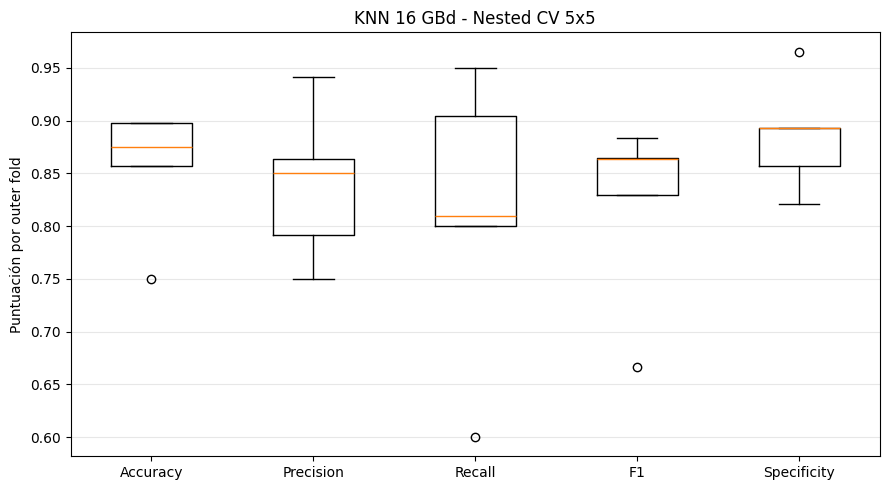


MÉTRICAS GLOBALES OUT-OF-FOLD (OOF)
OOF Accuracy:    0.8560
OOF Precision:   0.8384
OOF Recall:      0.8137
OOF F1:          0.8259
OOF Specificity: 0.8865

CLASSIFICATION REPORT OOF:
              precision    recall  f1-score   support

      NORMAL       0.87      0.89      0.88       141
      ALARMA       0.84      0.81      0.83       102

    accuracy                           0.86       243
   macro avg       0.85      0.85      0.85       243
weighted avg       0.86      0.86      0.86       243


Matriz de confusión OOF:
[[125  16]
 [ 19  83]]


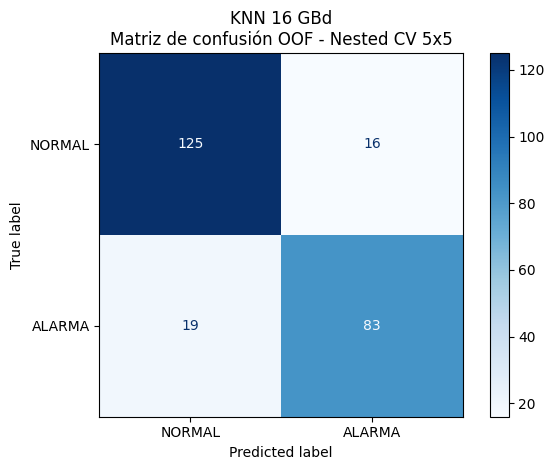


Predicciones OOF guardadas.

HIPERPARÁMETROS POR OUTER FOLD
 fold  knn__n_neighbors  knn__p knn__weights  inner_cv_best_f1
    1                 7       1      uniform          0.857109
    2                15       2      uniform          0.846762
    3                11       1      uniform          0.881142
    4                15       1      uniform          0.896047
    5                 3       1      uniform          0.835390

TIEMPO DE INFERENCIA - OUTER CV
Inference Mean: 21.435 µs/muestra
Inference Std:  1.484 µs/muestra
Mediciones totales: 500
Tiempo por muestra dentro de un batch. Incluye StandardScaler y KNN.predict().

ENTRENANDO MODELO FINAL - KNN

Mejores parámetros modelo final:
{'knn__n_neighbors': 5, 'knn__p': 1, 'knn__weights': 'uniform'}
F1 GridSearch final: 0.8699

CALCULANDO SHAP DEL MODELO FINAL
Background: 50 muestras
Muestras explicadas: 50


  0%|          | 0/50 [00:00<?, ?it/s]


31 CARACTERÍSTICAS ORDENADAS POR SHAP:
     feature mean_abs_shap importance_percent
  channel_sp      0.037596              9.55%
   Q_peak1_x      0.035727              9.08%
   I_peak2_y      0.027265              6.93%
   I_peak1_y      0.026633              6.77%
   I_peak3_y      0.025443              6.46%
   Q_peak3_y      0.023194              5.89%
   Q_peak1_y      0.020968              5.33%
   Q_peak2_y      0.018757              4.77%
   Q_peak4_y      0.018710              4.75%
   Q_peak3_x      0.017355              4.41%
   I_peak4_y      0.016867              4.29%
   Q_peak4_x      0.015971              4.06%
   I_peak4_x      0.009923              2.52%
   I_peak3_x      0.009552              2.43%
   Q_peak2_x      0.008048              2.04%
I_broadening      0.007785              1.98%
 Q_valley2_y      0.006835              1.74%
 Q_valley3_y      0.006657              1.69%
   I_peak2_x      0.006640              1.69%
 I_valley1_y      0.006540              

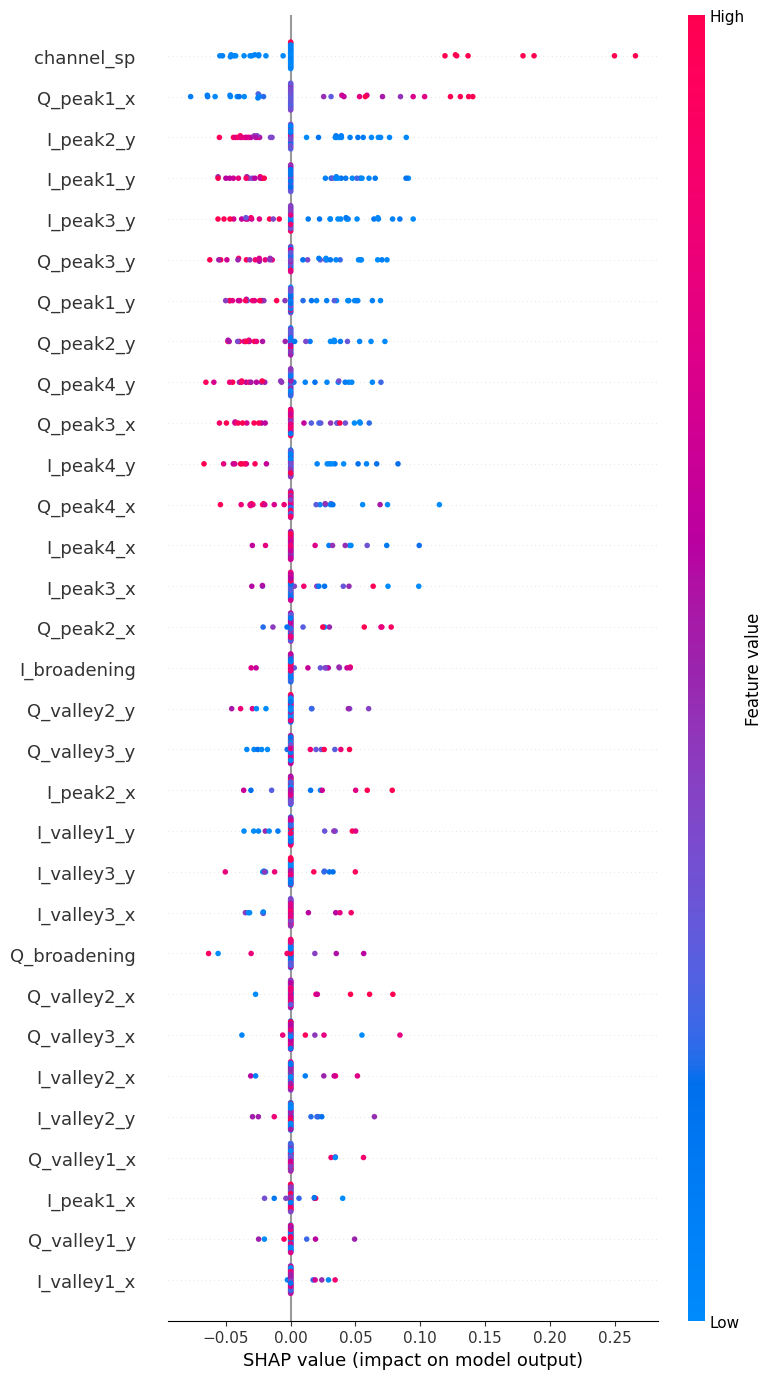

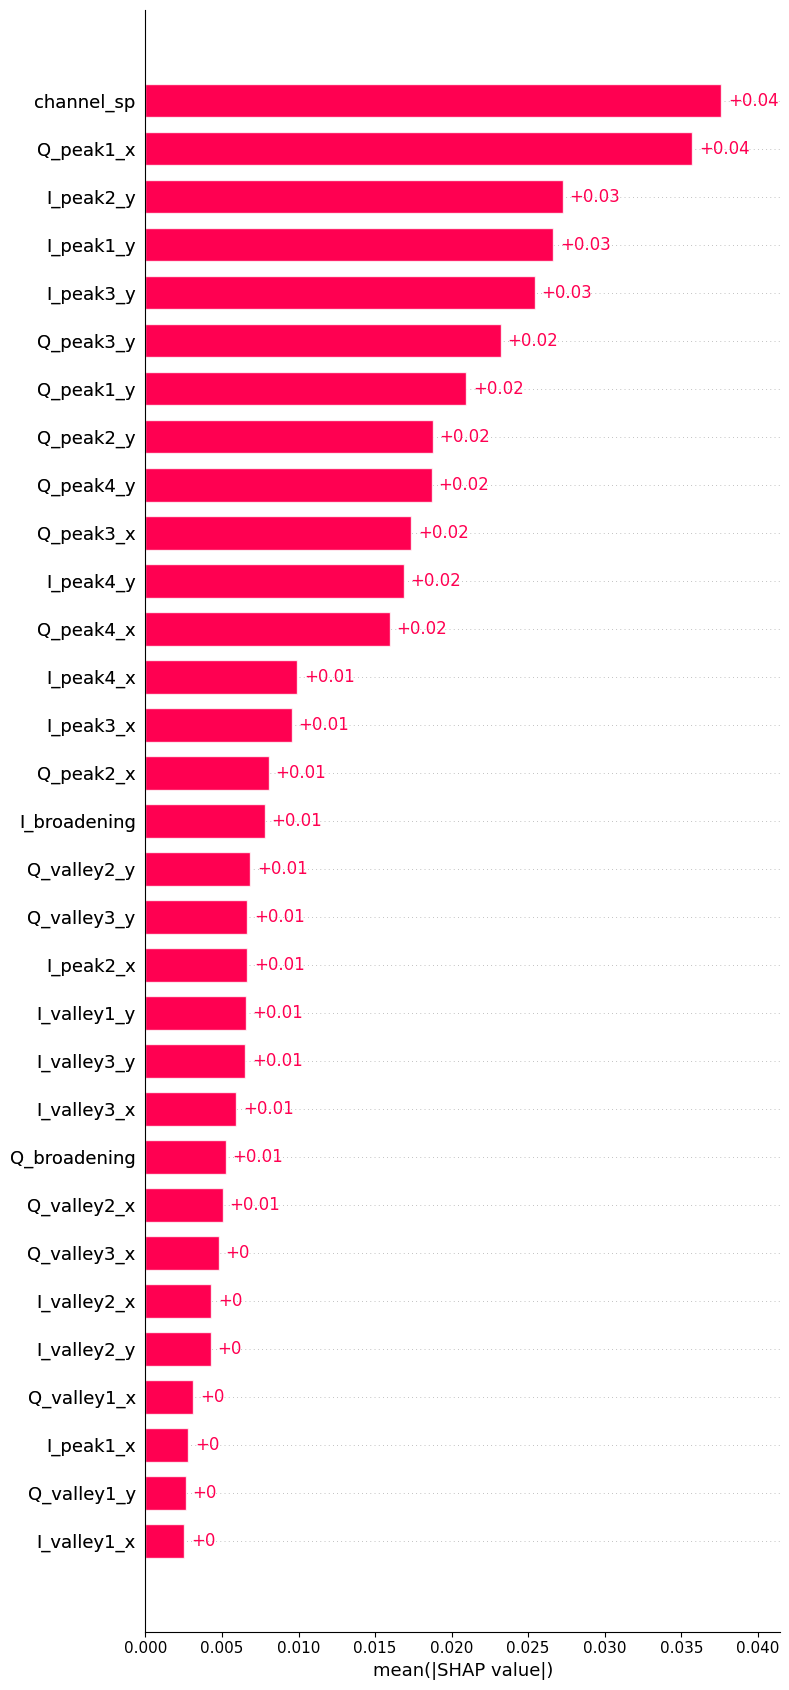

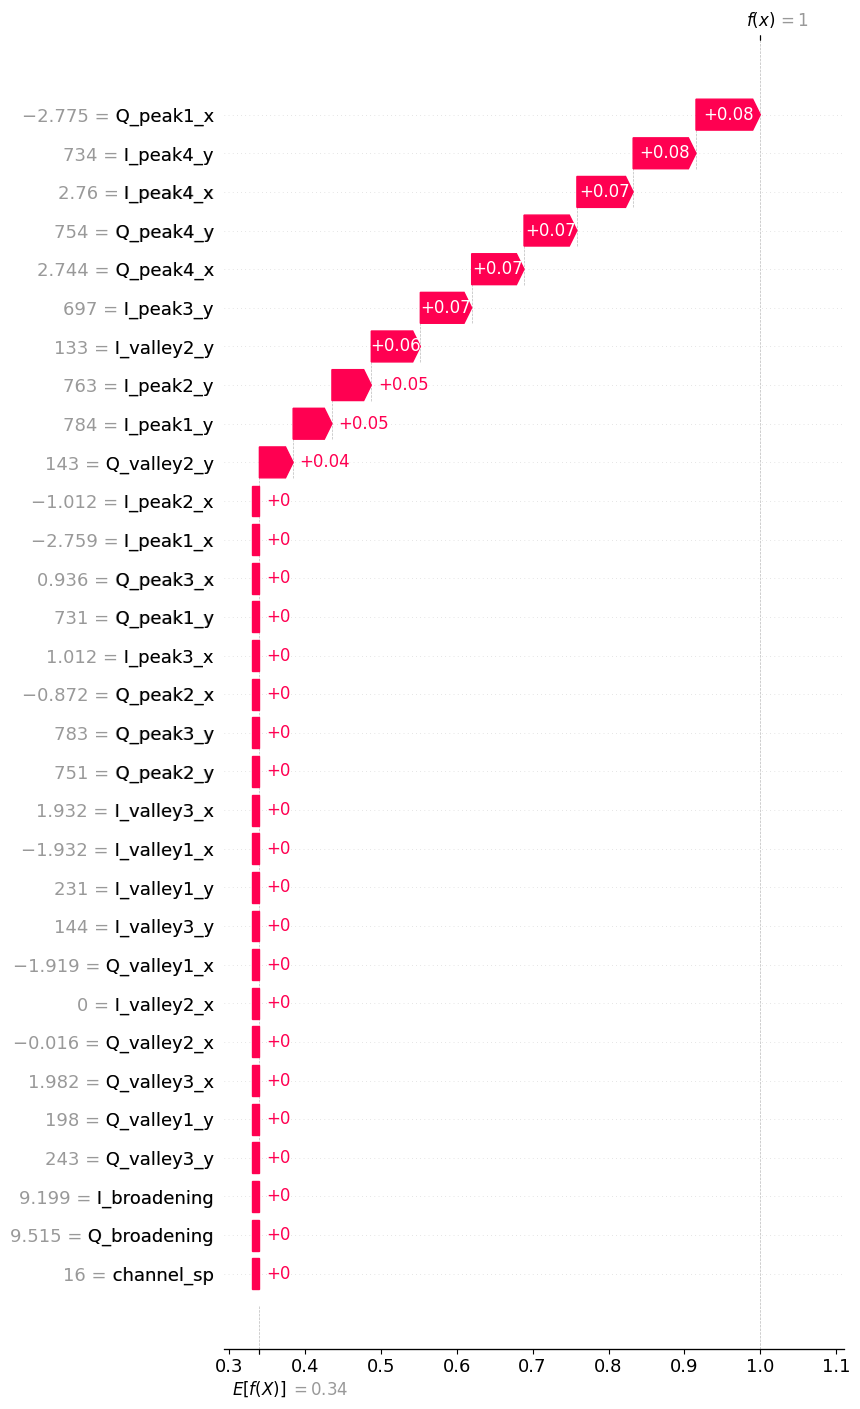


RESUMEN FINAL - KNN 16 GBd NESTED CV 5x5
Outer CV ACCURACY    : 0.8556 ± 0.0550
Outer CV PRECISION   : 0.8393 ± 0.0653
Outer CV RECALL      : 0.8129 ± 0.1206
Outer CV F1          : 0.8216 ± 0.0794
Outer CV SPECIFICITY : 0.8860 ± 0.0478

OOF Accuracy: 0.8560
OOF Precision: 0.8384
OOF Recall: 0.8137
OOF F1: 0.8259
OOF Specificity: 0.8865

Inference Mean: 21.435 µs/muestra
Inference Std: 1.484 µs/muestra

Archivos generados:
1. knn_osnr_16GBd_nested_outer_folds.csv
2. knn_osnr_16GBd_nested_oof_predictions.csv
3. knn_osnr_16GBd_nested_best_params.csv
4. knn_osnr_16GBd_nested_importancia_shap.csv

PROCESO COMPLETADO.


In [ ]:

"""
============================================================
CLASIFICACIÓN OSNR 16 GBd - KNN
NESTED CROSS-VALIDATION 5x5 + PREDICCIONES OUTER-FOLD
MÉTRICAS, MATRIZ DE CONFUSIÓN, SHAP Y TIEMPO DE INFERENCIA
============================================================

CLASES:
    0 = NORMAL: OSNR > 23 dB
    1 = ALARMA: OSNR <= 23 dB

DATASET:
    30 características I/Q
    1 característica channel_sp
    1 columna OSNR (target continuo)

METODOLOGÍA:
    - Outer CV: StratifiedKFold, 5 folds
    - Inner CV: StratifiedKFold, 5 folds
    - GridSearchCV dentro de cada outer train
    - Predicciones OOF en los outer tests
    - Métricas por fold y métricas globales OOF
    - Tiempos de inferencia por outer fold
    - Modelo final entrenado con todos los datos
    - SHAP para interpretar el modelo final

IMPORTANTE:
    Esta implementación divide por filas.
    Si existen muestras del mismo escenario experimental,
    conviene considerar Nested CV agrupada por escenario.
"""

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap

from sklearn.model_selection import (
    StratifiedKFold,
    GridSearchCV
)

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

# ============================================================
# 1. CONFIGURACIÓN GENERAL
# ============================================================

CSV_PATH = "matriz16GBd_clas.csv"

THRESHOLD_DB = 23.0

SEED = 42

N_OUTER_FOLDS = 5
N_INNER_FOLDS = 5

N_REPETITIONS = 100

SHAP_BACKGROUND = 50
SHAP_EXPLAIN = 50
SHAP_NSAMPLES = 300

# ============================================================
# 2. NOMBRES DE LAS 31 CARACTERÍSTICAS
# ============================================================

feature_names = (
    [f"I_peak{k}_x" for k in range(1, 5)] +
    [f"I_peak{k}_y" for k in range(1, 5)] +
    [f"Q_peak{k}_x" for k in range(1, 5)] +
    [f"Q_peak{k}_y" for k in range(1, 5)] +
    [f"I_valley{k}_x" for k in range(1, 4)] +
    [f"I_valley{k}_y" for k in range(1, 4)] +
    [f"Q_valley{k}_x" for k in range(1, 4)] +
    [f"Q_valley{k}_y" for k in range(1, 4)] +
    ["I_broadening", "Q_broadening", "channel_sp"]
)

assert len(feature_names) == 31

# ============================================================
# 3. CARGAR Y VALIDAR DATASET
# ============================================================

matriz = pd.read_csv(
    CSV_PATH,
    header=None
)

if matriz.shape[1] != 32:
    raise ValueError(
        f"Se esperaban 32 columnas; "
        f"se encontraron {matriz.shape[1]}"
    )

matriz = matriz.apply(
    pd.to_numeric,
    errors="raise"
)

if not np.isfinite(matriz.to_numpy()).all():
    raise ValueError(
        "El dataset contiene NaN o infinitos."
    )

# Las primeras 31 columnas contienen las características.
X = matriz.iloc[:, :31].copy()
X.columns = feature_names

# Última columna: OSNR continuo.
y_osnr = matriz.iloc[:, 31].to_numpy()

# Clasificación binaria.
y = (y_osnr <= THRESHOLD_DB).astype(int)

n_samples = len(y)

class_counts = np.bincount(
    y,
    minlength=2
)

if class_counts.min() < N_OUTER_FOLDS:
    raise ValueError(
        "No hay suficientes muestras por clase "
        "para los folds externos."
    )

print("=" * 65)
print("INFORMACIÓN DEL DATASET")
print("=" * 65)

print(f"Dataset: {CSV_PATH}")
print(f"Muestras: {n_samples}")
print(f"Características: {X.shape[1]}")
print(f"NORMAL: {class_counts[0]}")
print(f"ALARMA: {class_counts[1]}")
print(f"Umbral OSNR: {THRESHOLD_DB} dB")

print(
    "\nMonitoreo asistido: "
    "channel_sp se utiliza como entrada."
)

# ============================================================
# 4. DEFINIR PIPELINE KNN Y GRID
# ============================================================

def build_pipeline():
    """
    Construye un pipeline nuevo.

    StandardScaler se ajusta exclusivamente
    con los datos de entrenamiento de cada fold.
    """

    return Pipeline([
        (
            "scaler",
            StandardScaler()
        ),
        (
            "knn",
            KNeighborsClassifier()
        )
    ])


# Mismo grid de tu código original.
param_grid = {
    "knn__n_neighbors": [3, 5, 7, 11, 15],
    "knn__weights": [
        "uniform",
        "distance"
    ],
    "knn__p": [
        1,
        2
    ]
}

# ============================================================
# 5. CONFIGURAR OUTER CV
# ============================================================

outer_cv = StratifiedKFold(
    n_splits=N_OUTER_FOLDS,
    shuffle=True,
    random_state=SEED
)

# Cada muestra recibirá exactamente una predicción
# cuando pertenezca al test de un outer fold.

oof_predictions = np.full(
    n_samples,
    -1,
    dtype=int
)

# Probabilidad de ALARMA.
oof_probabilities = np.full(
    n_samples,
    np.nan,
    dtype=float
)

# Identificador del fold de evaluación.
oof_fold = np.full(
    n_samples,
    -1,
    dtype=int
)

outer_results = []
outer_best_params = []
outer_inference_times = []

print("\n" + "=" * 65)
print("INICIANDO NESTED CV 5x5 - KNN 16 GBd")
print("=" * 65)

# ============================================================
# 6. BUCLE PRINCIPAL: OUTER CROSS-VALIDATION
# ============================================================

for fold, (train_idx, test_idx) in enumerate(
    outer_cv.split(X, y),
    start=1
):

    print("\n" + "=" * 65)
    print(f"OUTER FOLD {fold}/{N_OUTER_FOLDS}")
    print("=" * 65)

    # --------------------------------------------------------
    # 6.1 SEPARACIÓN EXTERNA
    # --------------------------------------------------------

    X_outer_train = X.iloc[train_idx]
    X_outer_test = X.iloc[test_idx]

    y_outer_train = y[train_idx]
    y_outer_test = y[test_idx]

    print(
        f"Outer Train: {len(X_outer_train)} muestras"
    )

    print(
        f"Outer Test:  {len(X_outer_test)} muestras"
    )

    # --------------------------------------------------------
    # 6.2 INNER CV: GRIDSEARCHCV
    # --------------------------------------------------------

    inner_cv = StratifiedKFold(
        n_splits=N_INNER_FOLDS,
        shuffle=True,
        random_state=SEED + fold
    )

    search = GridSearchCV(
        estimator=build_pipeline(),
        param_grid=param_grid,
        scoring="f1",
        cv=inner_cv,
        n_jobs=-1,
        refit=True,
        return_train_score=False
    )

    print("\nBuscando mejores hiperparámetros...")

    # GridSearchCV solo recibe el outer train.
    # El outer test NO participa en la selección.
    search.fit(
        X_outer_train,
        y_outer_train
    )

    best_knn = search.best_estimator_

    print("\nMejores hiperparámetros:")
    print(search.best_params_)

    print(
        f"Inner CV Best F1: "
        f"{search.best_score_:.4f}"
    )

    outer_best_params.append({
        "fold": fold,
        **search.best_params_,
        "inner_cv_best_f1": search.best_score_
    })

    # --------------------------------------------------------
    # 6.3 PREDICCIONES OUTER-FOLD
    # --------------------------------------------------------

    y_outer_pred = best_knn.predict(
        X_outer_test
    )

    # Probabilidad de pertenecer a ALARMA (clase 1).
    y_outer_proba = best_knn.predict_proba(
        X_outer_test
    )[:, 1]

    # Guardar las predicciones en el orden original.
    oof_predictions[test_idx] = y_outer_pred

    oof_probabilities[test_idx] = y_outer_proba

    oof_fold[test_idx] = fold

    # --------------------------------------------------------
    # 6.4 MÉTRICAS DEL OUTER FOLD
    # --------------------------------------------------------

    tn, fp, fn, tp = confusion_matrix(
        y_outer_test,
        y_outer_pred,
        labels=[0, 1]
    ).ravel()

    accuracy = accuracy_score(
        y_outer_test,
        y_outer_pred
    )

    precision = precision_score(
        y_outer_test,
        y_outer_pred,
        zero_division=0
    )

    recall = recall_score(
        y_outer_test,
        y_outer_pred,
        zero_division=0
    )

    f1 = f1_score(
        y_outer_test,
        y_outer_pred,
        zero_division=0
    )

    specificity = (
        tn / (tn + fp)
        if (tn + fp) > 0
        else np.nan
    )

    # --------------------------------------------------------
    # 6.5 TIEMPO DE INFERENCIA
    # --------------------------------------------------------

    # Warm-up.
    _ = best_knn.predict(
        X_outer_test.iloc[
            :min(10, len(X_outer_test))
        ]
    )

    inference_times = np.empty(
        N_REPETITIONS
    )

    for rep in range(N_REPETITIONS):

        start = time.perf_counter()

        _ = best_knn.predict(
            X_outer_test
        )

        elapsed = (
            time.perf_counter() - start
        )

        inference_times[rep] = (
            elapsed / len(X_outer_test)
        )

    inference_mean_us = (
        inference_times.mean() * 1e6
    )

    inference_std_us = (
        inference_times.std() * 1e6
    )

    outer_inference_times.append(
        inference_times * 1e6
    )

    # --------------------------------------------------------
    # 6.6 GUARDAR RESULTADOS DEL FOLD
    # --------------------------------------------------------

    outer_results.append({
        "fold": fold,
        "n_train": len(train_idx),
        "n_test": len(test_idx),
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "specificity": specificity,
        "inference_mean_us": inference_mean_us,
        "inference_std_us": inference_std_us
    })

    print("\nMÉTRICAS OUTER FOLD:")

    print(f"Accuracy:    {accuracy:.4f}")
    print(f"Precision:   {precision:.4f}")
    print(f"Recall:      {recall:.4f}")
    print(f"F1:          {f1:.4f}")
    print(f"Specificity: {specificity:.4f}")

    print(
        f"Inference Mean: "
        f"{inference_mean_us:.3f} µs/muestra"
    )

    print(
        f"Inference Std:  "
        f"{inference_std_us:.3f} µs/muestra"
    )

# ============================================================
# 7. VALIDAR PREDICCIONES OOF
# ============================================================

if np.any(oof_predictions == -1):
    raise RuntimeError(
        "Existen muestras sin predicción OOF."
    )

if np.any(oof_fold == -1):
    raise RuntimeError(
        "Existen muestras sin fold asignado."
    )

if not np.isfinite(oof_probabilities).all():
    raise RuntimeError(
        "Existen probabilidades OOF inválidas."
    )

print("\nTodas las muestras tienen predicción OOF.")

# ============================================================
# 8. RESULTADOS POR OUTER FOLD
# ============================================================

results_df = pd.DataFrame(
    outer_results
)

print("\n" + "=" * 65)
print("RESULTADOS DE LOS 5 OUTER FOLDS")
print("=" * 65)

print(
    results_df.to_string(index=False)
)

results_df.to_csv(
    "knn_osnr_16GBd_nested_outer_folds.csv",
    index=False
)

# ============================================================
# 9. PROMEDIO ± DESVIACIÓN ESTÁNDAR OUTER CV
# ============================================================

print("\n" + "=" * 65)
print("OUTER CV - PROMEDIO ± DESVIACIÓN ESTÁNDAR")
print("=" * 65)

metrics = [
    "accuracy",
    "precision",
    "recall",
    "f1",
    "specificity"
]

for metric in metrics:

    values = results_df[
        metric
    ].to_numpy()

    print(
        f"{metric.upper():12s}: "
        f"{np.nanmean(values):.4f} ± "
        f"{np.nanstd(values):.4f}"
    )

# ============================================================
# 10. GRÁFICA DE MÉTRICAS OUTER CV
# ============================================================

plt.figure(figsize=(9, 5))

plt.boxplot(
    [
        results_df[m].values
        for m in metrics
    ],
    tick_labels=[
        "Accuracy",
        "Precision",
        "Recall",
        "F1",
        "Specificity"
    ]
)

plt.ylabel("Puntuación por outer fold")

plt.title(
    "KNN 16 GBd - Nested CV 5x5"
)

plt.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()
plt.show()
plt.close()

# ============================================================
# 11. MÉTRICAS GLOBALES OOF
# ============================================================

print("\n" + "=" * 65)
print("MÉTRICAS GLOBALES OUT-OF-FOLD (OOF)")
print("=" * 65)

tn, fp, fn, tp = confusion_matrix(
    y,
    oof_predictions,
    labels=[0, 1]
).ravel()

oof_accuracy = accuracy_score(
    y,
    oof_predictions
)

oof_precision = precision_score(
    y,
    oof_predictions,
    zero_division=0
)

oof_recall = recall_score(
    y,
    oof_predictions,
    zero_division=0
)

oof_f1 = f1_score(
    y,
    oof_predictions,
    zero_division=0
)

oof_specificity = (
    tn / (tn + fp)
    if (tn + fp) > 0
    else np.nan
)

print(
    f"OOF Accuracy:    {oof_accuracy:.4f}"
)

print(
    f"OOF Precision:   {oof_precision:.4f}"
)

print(
    f"OOF Recall:      {oof_recall:.4f}"
)

print(
    f"OOF F1:          {oof_f1:.4f}"
)

print(
    f"OOF Specificity: {oof_specificity:.4f}"
)

print("\nCLASSIFICATION REPORT OOF:")

print(
    classification_report(
        y,
        oof_predictions,
        labels=[0, 1],
        target_names=[
            "NORMAL",
            "ALARMA"
        ],
        zero_division=0
    )
)

# ============================================================
# 12. MATRIZ DE CONFUSIÓN OOF
# ============================================================

cm_oof = confusion_matrix(
    y,
    oof_predictions,
    labels=[0, 1]
)

print("\nMatriz de confusión OOF:")

print(cm_oof)

ConfusionMatrixDisplay(
    confusion_matrix=cm_oof,
    display_labels=[
        "NORMAL",
        "ALARMA"
    ]
).plot(
    cmap="Blues",
    values_format="d"
)

plt.title(
    "KNN 16 GBd\n"
    "Matriz de confusión OOF - Nested CV 5x5"
)

plt.tight_layout()
plt.show()
plt.close()

# ============================================================
# 13. GUARDAR PREDICCIONES OOF
# ============================================================

oof_df = pd.DataFrame({
    "sample_index": np.arange(n_samples),
    "outer_fold": oof_fold,
    "OSNR_dB": y_osnr,
    "true_class": y,
    "predicted_class": oof_predictions,
    "probability_alarm": oof_probabilities,
    "correct": (
        y == oof_predictions
    )
})

oof_df.to_csv(
    "knn_osnr_16GBd_nested_oof_predictions.csv",
    index=False
)

print("\nPredicciones OOF guardadas.")

# ============================================================
# 14. HIPERPARÁMETROS POR OUTER FOLD
# ============================================================

params_df = pd.DataFrame(
    outer_best_params
)

print("\n" + "=" * 65)
print("HIPERPARÁMETROS POR OUTER FOLD")
print("=" * 65)

print(
    params_df.to_string(index=False)
)

params_df.to_csv(
    "knn_osnr_16GBd_nested_best_params.csv",
    index=False
)

# ============================================================
# 15. TIEMPO DE INFERENCIA OUTER CV
# ============================================================

all_inference_times = np.concatenate(
    outer_inference_times
)

print("\n" + "=" * 65)
print("TIEMPO DE INFERENCIA - OUTER CV")
print("=" * 65)

print(
    f"Inference Mean: "
    f"{all_inference_times.mean():.3f} µs/muestra"
)

print(
    f"Inference Std:  "
    f"{all_inference_times.std():.3f} µs/muestra"
)

print(
    f"Mediciones totales: "
    f"{len(all_inference_times)}"
)

print(
    "Tiempo por muestra dentro de un batch. "
    "Incluye StandardScaler y KNN.predict()."
)

# ============================================================
# 16. ENTRENAR MODELO FINAL CON TODOS LOS DATOS
# ============================================================

# Este modelo se utiliza para SHAP.
# NO se utiliza para las métricas OOF.
#
# Se seleccionan nuevamente los hiperparámetros
# mediante GridSearchCV sobre todo el dataset.

print("\n" + "=" * 65)
print("ENTRENANDO MODELO FINAL - KNN")
print("=" * 65)

final_inner_cv = StratifiedKFold(
    n_splits=N_INNER_FOLDS,
    shuffle=True,
    random_state=SEED
)

final_search = GridSearchCV(
    estimator=build_pipeline(),
    param_grid=param_grid,
    scoring="f1",
    cv=final_inner_cv,
    n_jobs=-1,
    refit=True
)

final_search.fit(X, y)

final_knn = final_search.best_estimator_

print("\nMejores parámetros modelo final:")
print(final_search.best_params_)

print(
    f"F1 GridSearch final: "
    f"{final_search.best_score_:.4f}"
)

# ============================================================
# 17. SHAP - KERNELEXPLAINER
# ============================================================

# SHAP explica predict_proba[:, 1] del KNN final.
#
# SHAP positivo:
#    aumenta la probabilidad de ALARMA.
#
# SHAP negativo:
#    disminuye la probabilidad de ALARMA.
#
# Las muestras explicadas pertenecen al dataset
# utilizado para entrenar el modelo final.
# Por tanto, este SHAP es descriptivo, no OOF.

print("\n" + "=" * 65)
print("CALCULANDO SHAP DEL MODELO FINAL")
print("=" * 65)

background = X.sample(
    n=min(SHAP_BACKGROUND, len(X)),
    random_state=SEED
)

explained = X.sample(
    n=min(SHAP_EXPLAIN, len(X)),
    random_state=SEED + 1
)

print(
    f"Background: {len(background)} muestras"
)

print(
    f"Muestras explicadas: {len(explained)}"
)

def knn_alarm_probability(data):
    """
    Adaptador para SHAP.

    Conserva nombres y orden de las 31 columnas.
    Devuelve P(ALARMA), correspondiente a la clase 1.
    """

    frame = pd.DataFrame(
        np.asarray(data),
        columns=feature_names
    )

    return final_knn.predict_proba(frame)[:, 1]


explainer = shap.KernelExplainer(
    knn_alarm_probability,
    background
)

raw = explainer.shap_values(
    explained,
    nsamples=SHAP_NSAMPLES
)

shap_values = np.asarray(raw)

if shap_values.shape != explained.shape:
    raise ValueError(
        f"Forma SHAP inesperada: "
        f"{shap_values.shape}. "
        f"Se esperaba {explained.shape}."
    )

# ============================================================
# 18. IMPORTANCIA GLOBAL SHAP
# ============================================================

mean_abs = np.mean(
    np.abs(shap_values),
    axis=0
)

imp_df = pd.DataFrame({
    "feature": feature_names,
    "mean_abs_shap": mean_abs
})

imp_df = imp_df.sort_values(
    "mean_abs_shap",
    ascending=False
).reset_index(drop=True)

total = imp_df[
    "mean_abs_shap"
].sum()

if total > 0:

    imp_df["importance_percent"] = (
        100 *
        imp_df["mean_abs_shap"] /
        total
    )

else:

    imp_df["importance_percent"] = 0.0

print("\n31 CARACTERÍSTICAS ORDENADAS POR SHAP:")

print(
    imp_df.to_string(
        index=False,
        formatters={
            "mean_abs_shap": "{:.6f}".format,
            "importance_percent": "{:.2f}%".format
        }
    )
)

print(
    f"\nSuma de porcentajes: "
    f"{imp_df['importance_percent'].sum():.2f}%"
)

print("\nTOP 5 SHAP:")

print(
    imp_df.head(5).to_string(
        index=False
    )
)

imp_df.to_csv(
    "knn_osnr_16GBd_nested_importancia_shap.csv",
    index=False
)

# ============================================================
# 19. CREAR OBJETO SHAP EXPLANATION
# ============================================================

expected_value = float(
    np.asarray(
        explainer.expected_value
    ).item()
)

explanation = shap.Explanation(
    values=shap_values,
    base_values=np.full(
        len(explained),
        expected_value
    ),
    data=explained.to_numpy(),
    feature_names=feature_names
)

# ============================================================
# 20. GRÁFICAS SHAP
# ============================================================

# Beeswarm
shap.plots.beeswarm(
    explanation,
    max_display=31,
    show=False
)

plt.tight_layout()
plt.show()
plt.close()

# Bar plot
shap.plots.bar(
    explanation,
    max_display=31,
    show=False
)

plt.tight_layout()
plt.show()
plt.close()

# Waterfall de la primera muestra explicada.
shap.plots.waterfall(
    explanation[0],
    max_display=31,
    show=False
)

plt.show()
plt.close()

# ============================================================
# 21. RESUMEN FINAL
# ============================================================

print("\n" + "=" * 65)
print("RESUMEN FINAL - KNN 16 GBd NESTED CV 5x5")
print("=" * 65)

for metric in metrics:

    values = results_df[
        metric
    ].to_numpy()

    print(
        f"Outer CV {metric.upper():12s}: "
        f"{np.nanmean(values):.4f} ± "
        f"{np.nanstd(values):.4f}"
    )

print(
    f"\nOOF Accuracy: "
    f"{oof_accuracy:.4f}"
)

print(
    f"OOF Precision: "
    f"{oof_precision:.4f}"
)

print(
    f"OOF Recall: "
    f"{oof_recall:.4f}"
)

print(
    f"OOF F1: "
    f"{oof_f1:.4f}"
)

print(
    f"OOF Specificity: "
    f"{oof_specificity:.4f}"
)

print(
    f"\nInference Mean: "
    f"{all_inference_times.mean():.3f} µs/muestra"
)

print(
    f"Inference Std: "
    f"{all_inference_times.std():.3f} µs/muestra"
)

print("\nArchivos generados:")

print("1. knn_osnr_16GBd_nested_outer_folds.csv")
print("2. knn_osnr_16GBd_nested_oof_predictions.csv")
print("3. knn_osnr_16GBd_nested_best_params.csv")
print("4. knn_osnr_16GBd_nested_importancia_shap.csv")

print("\nPROCESO COMPLETADO.")


# AHORA PARA MONITOREO CIEGO (SIN CHANNEL SPACING) PARA CLASIFICAR OSNR

## SVM 16GBd para clasificar OSNR SIN CHANNEL SPACING

INFORMACIÓN DEL DATASET
Dataset: matriz16GBd_clas.csv
Muestras: 243
Características utilizadas: 30
NORMAL: 141
ALARMA: 102
Umbral OSNR: 23.0 dB

MONITOREO CIEGO: channel_sp NO se utiliza como entrada.

Características utilizadas:
 1. I_peak1_x
 2. I_peak2_x
 3. I_peak3_x
 4. I_peak4_x
 5. I_peak1_y
 6. I_peak2_y
 7. I_peak3_y
 8. I_peak4_y
 9. Q_peak1_x
10. Q_peak2_x
11. Q_peak3_x
12. Q_peak4_x
13. Q_peak1_y
14. Q_peak2_y
15. Q_peak3_y
16. Q_peak4_y
17. I_valley1_x
18. I_valley2_x
19. I_valley3_x
20. I_valley1_y
21. I_valley2_y
22. I_valley3_y
23. Q_valley1_x
24. Q_valley2_x
25. Q_valley3_x
26. Q_valley1_y
27. Q_valley2_y
28. Q_valley3_y
29. I_broadening
30. Q_broadening

Combinaciones de hiperparámetros: 32

INICIANDO NESTED CV 5x5 - SVM CIEGO 16 GBd

OUTER FOLD 1/5
Outer Train: 194 muestras
Outer Test:  49 muestras

Buscando mejores hiperparámetros...

Mejores hiperparámetros:
{'svm__C': 100, 'svm__class_weight': 'balanced', 'svm__gamma': 0.001}
Inner CV Best F1: 0.8623

MÉTRICAS OUT

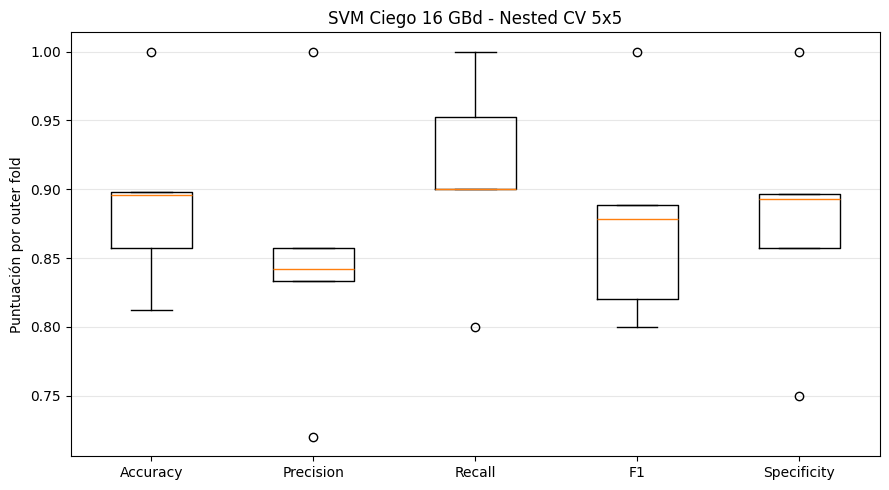


MÉTRICAS GLOBALES OUT-OF-FOLD (OOF)
OOF Accuracy:    0.8930
OOF Precision:   0.8455
OOF Recall:      0.9118
OOF F1:          0.8774
OOF Specificity: 0.8794

CLASSIFICATION REPORT OOF:
              precision    recall  f1-score   support

      NORMAL       0.93      0.88      0.91       141
      ALARMA       0.85      0.91      0.88       102

    accuracy                           0.89       243
   macro avg       0.89      0.90      0.89       243
weighted avg       0.90      0.89      0.89       243


Matriz de confusión OOF:
[[124  17]
 [  9  93]]


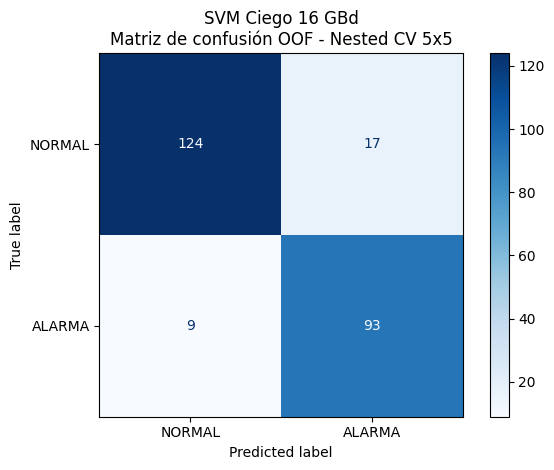


Predicciones OOF guardadas.

HIPERPARÁMETROS POR OUTER FOLD
 fold  svm__C svm__class_weight  svm__gamma  inner_cv_best_f1
    1     100          balanced       0.001          0.862286
    2     100              None       0.001          0.861356
    3     100          balanced       0.001          0.913240
    4     100          balanced       0.001          0.897679
    5     100          balanced       0.001          0.887619

TIEMPO DE INFERENCIA - OUTER CV
Inference Mean: 11.173 µs/muestra
Inference Std:  0.422 µs/muestra
Mediciones totales: 500
Tiempo por muestra dentro de un batch. Incluye StandardScaler y SVM.predict().

ENTRENANDO MODELO FINAL - SVM CIEGO

Mejores parámetros modelo final:
{'svm__C': 10, 'svm__class_weight': None, 'svm__gamma': 0.01}
F1 GridSearch final: 0.8843

CALCULANDO SHAP DEL MODELO FINAL
Background: 50 muestras
Muestras explicadas: 50


  0%|          | 0/50 [00:00<?, ?it/s]


30 CARACTERÍSTICAS ORDENADAS POR SHAP:
     feature mean_abs_shap importance_percent
   Q_peak1_y      0.370283             12.36%
   I_peak2_y      0.338894             11.32%
 I_valley3_y      0.263508              8.80%
 I_valley2_y      0.251235              8.39%
   I_peak3_y      0.246214              8.22%
   I_peak1_y      0.225349              7.52%
   Q_peak3_y      0.220493              7.36%
   Q_peak1_x      0.176381              5.89%
   Q_peak4_y      0.168246              5.62%
   Q_peak3_x      0.160906              5.37%
 Q_valley1_x      0.158234              5.28%
   Q_peak4_x      0.157010              5.24%
   Q_peak2_y      0.043785              1.46%
 Q_valley2_x      0.038721              1.29%
 I_valley3_x      0.037018              1.24%
   I_peak1_x      0.025109              0.84%
   I_peak3_x      0.021298              0.71%
 Q_valley3_y      0.020720              0.69%
 Q_valley2_y      0.013934              0.47%
Q_broadening      0.013004              

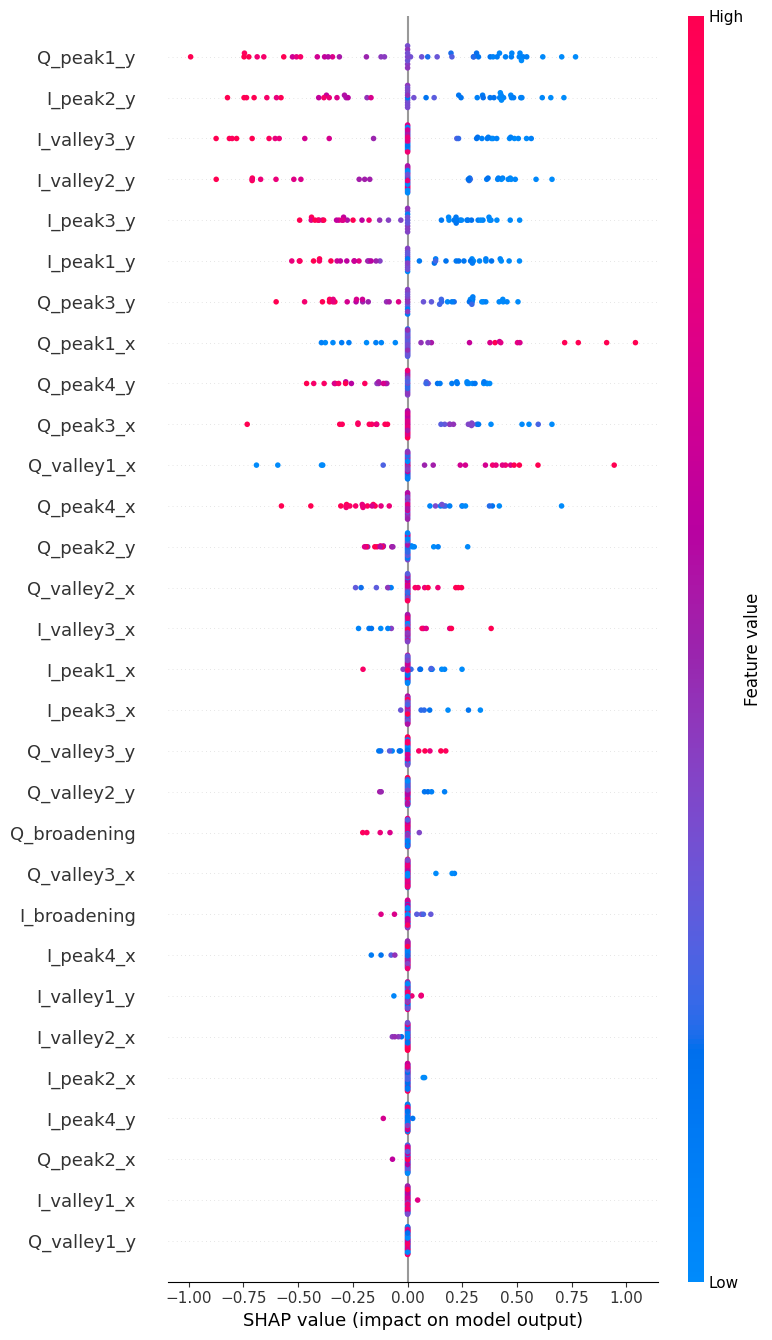

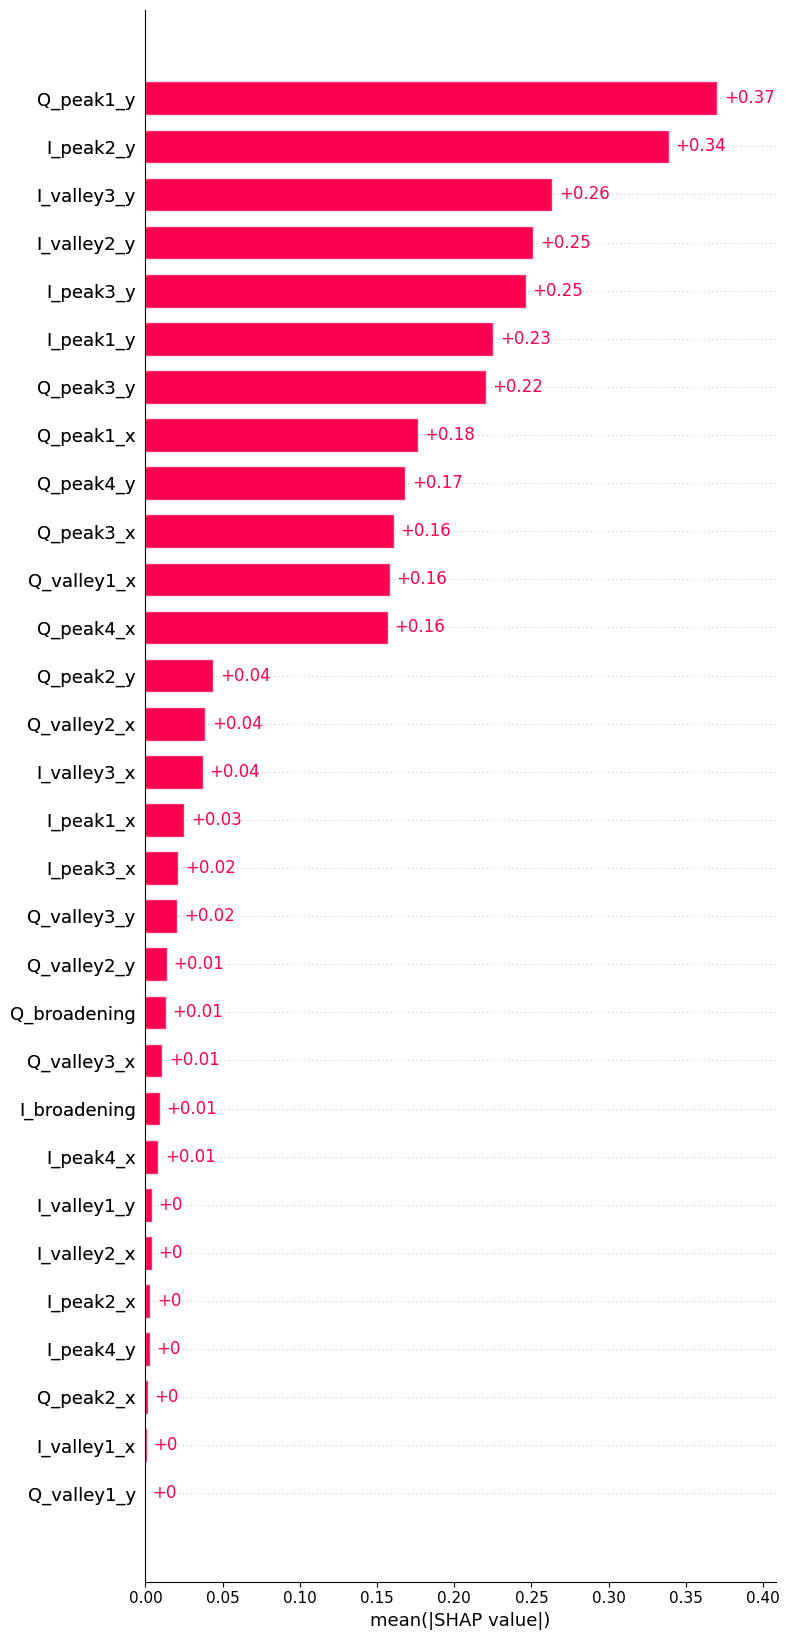

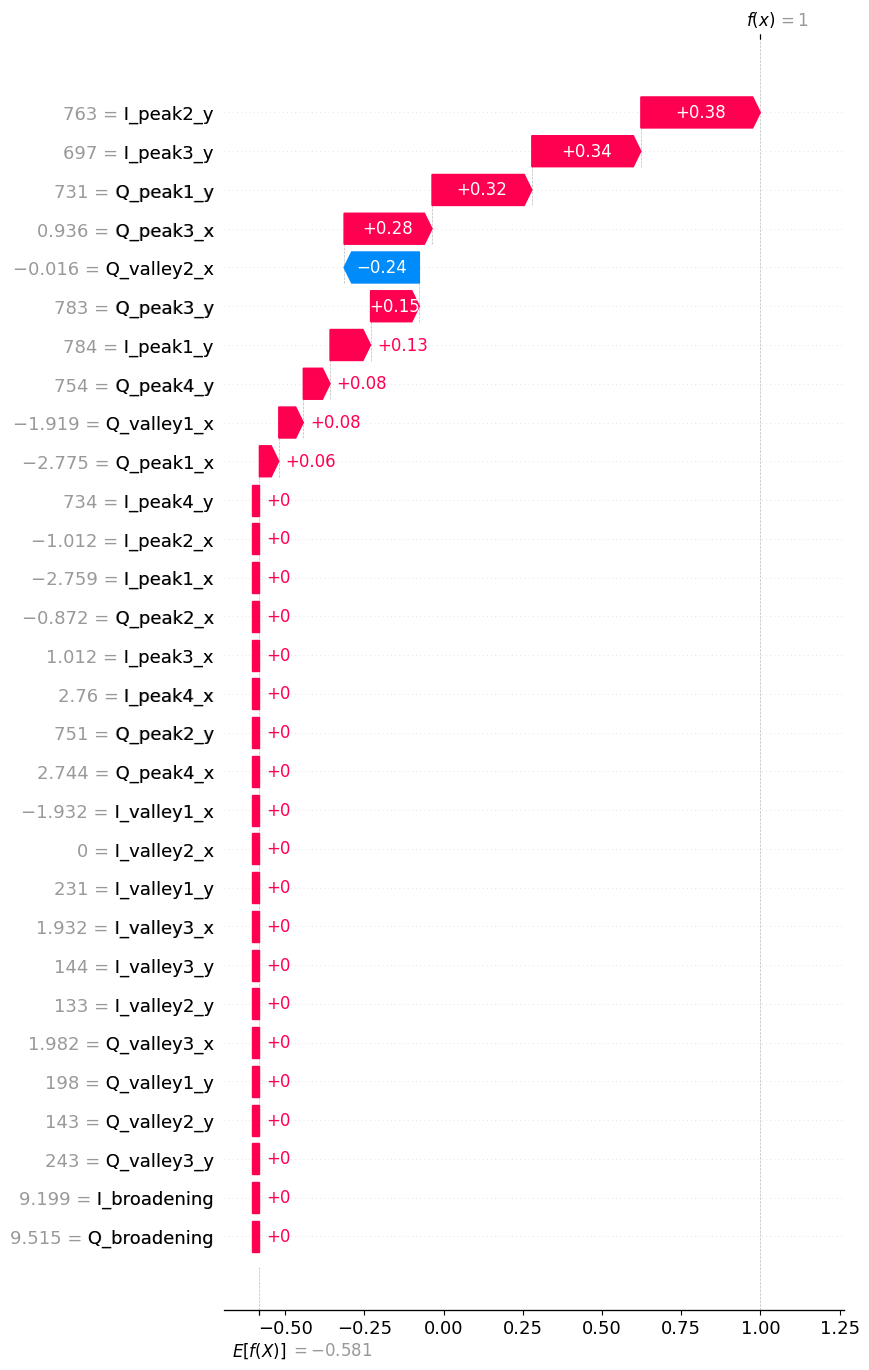


RESUMEN FINAL - SVM CIEGO 16 GBd NESTED CV 5x5
Outer CV ACCURACY    : 0.8927 ± 0.0620
Outer CV PRECISION   : 0.8505 ± 0.0892
Outer CV RECALL      : 0.9105 ± 0.0666
Outer CV F1          : 0.8775 ± 0.0698
Outer CV SPECIFICITY : 0.8793 ± 0.0803

OOF Accuracy: 0.8930
OOF Precision: 0.8455
OOF Recall: 0.9118
OOF F1: 0.8774
OOF Specificity: 0.8794

Inference Mean: 11.173 µs/muestra
Inference Std: 0.422 µs/muestra

Archivos generados:
1. svm_osnr_16GBd_ciego_nested_outer_folds.csv
2. svm_osnr_16GBd_ciego_nested_oof_predictions.csv
3. svm_osnr_16GBd_ciego_nested_best_params.csv
4. svm_osnr_16GBd_ciego_nested_importancia_shap.csv

PROCESO COMPLETADO.


In [ ]:

"""
============================================================
CLASIFICACIÓN CIEGA OSNR 16 GBd - SVM-RBF
NESTED CROSS-VALIDATION 5x5 + PREDICCIONES OUTER-FOLD
MÉTRICAS, MATRIZ DE CONFUSIÓN, SHAP Y TIEMPO DE INFERENCIA
============================================================

CLASES:
    0 = NORMAL: OSNR > 23 dB
    1 = ALARMA: OSNR <= 23 dB

DATASET:
    30 características I/Q
    1 columna channel_sp (EXCLUIDA DEL MODELO)
    1 columna OSNR (target continuo)

MONITOREO CIEGO:
    - No se utiliza channel_sp como entrada.
    - Se utilizan exclusivamente las 30 características I/Q.
    - OSNR se utiliza para construir las etiquetas.

METODOLOGÍA:
    - Outer CV: StratifiedKFold, 5 folds
    - Inner CV: StratifiedKFold, 5 folds
    - GridSearchCV dentro de cada outer train
    - Predicciones OOF en los outer tests
    - Métricas por fold y métricas globales OOF
    - Tiempos de inferencia por outer fold
    - Modelo final entrenado con todos los datos
    - SHAP para interpretar el modelo final

IMPORTANTE:
    Esta implementación divide por filas.
    Si existen muestras del mismo escenario experimental,
    conviene considerar Nested CV agrupada por escenario.
"""

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap

from sklearn.model_selection import (
    StratifiedKFold,
    GridSearchCV
)

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

# ============================================================
# 1. CONFIGURACIÓN GENERAL
# ============================================================

CSV_PATH = "matriz16GBd_clas.csv"

THRESHOLD_DB = 23.0

SEED = 42

N_OUTER_FOLDS = 5
N_INNER_FOLDS = 5

N_REPETITIONS = 100

SHAP_BACKGROUND = 50
SHAP_EXPLAIN = 50
SHAP_NSAMPLES = 300

# ============================================================
# 2. NOMBRES DE LAS 30 CARACTERÍSTICAS
# ============================================================

# MONITOREO CIEGO:
# No se incluye "channel_sp" entre las características.

feature_names = (
    [f"I_peak{k}_x" for k in range(1, 5)] +
    [f"I_peak{k}_y" for k in range(1, 5)] +
    [f"Q_peak{k}_x" for k in range(1, 5)] +
    [f"Q_peak{k}_y" for k in range(1, 5)] +
    [f"I_valley{k}_x" for k in range(1, 4)] +
    [f"I_valley{k}_y" for k in range(1, 4)] +
    [f"Q_valley{k}_x" for k in range(1, 4)] +
    [f"Q_valley{k}_y" for k in range(1, 4)] +
    ["I_broadening", "Q_broadening"]
)

assert len(feature_names) == 30

# ============================================================
# 3. CARGAR Y VALIDAR DATASET
# ============================================================

matriz = pd.read_csv(
    CSV_PATH,
    header=None
)

# La matriz original tiene 32 columnas:
# 30 características I/Q + channel_sp + OSNR.

if matriz.shape[1] != 32:
    raise ValueError(
        f"Se esperaban 32 columnas; "
        f"se encontraron {matriz.shape[1]}"
    )

matriz = matriz.apply(
    pd.to_numeric,
    errors="raise"
)

if not np.isfinite(matriz.to_numpy()).all():
    raise ValueError(
        "El dataset contiene NaN o infinitos."
    )

# ------------------------------------------------------------
# 3.1 SELECCIÓN DE CARACTERÍSTICAS PARA MONITOREO CIEGO
# ------------------------------------------------------------

# Se utilizan únicamente las primeras 30 columnas.
# La columna 30 (channel_sp) queda excluida.
X = matriz.iloc[:, :30].copy()

X.columns = feature_names

# La última columna contiene el OSNR continuo.
y_osnr = matriz.iloc[:, 31].to_numpy()

# Clasificación binaria:
# NORMAL = 0, si OSNR > 23 dB
# ALARMA = 1, si OSNR <= 23 dB
y = (y_osnr <= THRESHOLD_DB).astype(int)

n_samples = len(y)

class_counts = np.bincount(
    y,
    minlength=2
)

if class_counts.min() < N_OUTER_FOLDS:
    raise ValueError(
        "No hay suficientes muestras por clase "
        "para los folds externos."
    )

print("=" * 65)
print("INFORMACIÓN DEL DATASET")
print("=" * 65)

print(f"Dataset: {CSV_PATH}")
print(f"Muestras: {n_samples}")
print(f"Características utilizadas: {X.shape[1]}")
print(f"NORMAL: {class_counts[0]}")
print(f"ALARMA: {class_counts[1]}")
print(f"Umbral OSNR: {THRESHOLD_DB} dB")

print(
    "\nMONITOREO CIEGO: "
    "channel_sp NO se utiliza como entrada."
)

print("\nCaracterísticas utilizadas:")

for i, feature in enumerate(feature_names, start=1):
    print(f"{i:2d}. {feature}")

# ============================================================
# 4. DEFINIR PIPELINE SVM Y GRID
# ============================================================

def build_pipeline():
    """
    Construye un pipeline nuevo.

    StandardScaler se ajusta exclusivamente
    con los datos de entrenamiento de cada fold.

    El escalado forma parte del pipeline para evitar
    fuga de información entre entrenamiento y test.
    """

    return Pipeline([
        (
            "scaler",
            StandardScaler()
        ),
        (
            "svm",
            SVC(
                kernel="rbf",
                random_state=SEED
            )
        )
    ])


# Se conserva el grid del código original.

param_grid = {
    "svm__C": [0.1, 1, 10, 100],
    "svm__gamma": [
        "scale",
        0.001,
        0.01,
        0.1
    ],
    "svm__class_weight": [
        None,
        "balanced"
    ]
}

n_combinations = (
    len(param_grid["svm__C"]) *
    len(param_grid["svm__gamma"]) *
    len(param_grid["svm__class_weight"])
)

print("\nCombinaciones de hiperparámetros:", n_combinations)

# ============================================================
# 5. CONFIGURAR OUTER CROSS-VALIDATION
# ============================================================

outer_cv = StratifiedKFold(
    n_splits=N_OUTER_FOLDS,
    shuffle=True,
    random_state=SEED
)

# Cada muestra recibirá una predicción
# cuando pertenezca al test de un outer fold.

oof_predictions = np.full(
    n_samples,
    -1,
    dtype=int
)

# Puntuación de decision_function para cada muestra OOF.
oof_decisions = np.full(
    n_samples,
    np.nan,
    dtype=float
)

# Identificador del outer fold.
oof_fold = np.full(
    n_samples,
    -1,
    dtype=int
)

outer_results = []
outer_best_params = []
outer_inference_times = []

print("\n" + "=" * 65)
print("INICIANDO NESTED CV 5x5 - SVM CIEGO 16 GBd")
print("=" * 65)

# ============================================================
# 6. BUCLE PRINCIPAL: OUTER CROSS-VALIDATION
# ============================================================

for fold, (train_idx, test_idx) in enumerate(
    outer_cv.split(X, y),
    start=1
):

    print("\n" + "=" * 65)
    print(f"OUTER FOLD {fold}/{N_OUTER_FOLDS}")
    print("=" * 65)

    # --------------------------------------------------------
    # 6.1 SEPARACIÓN EXTERNA
    # --------------------------------------------------------

    X_outer_train = X.iloc[train_idx]
    X_outer_test = X.iloc[test_idx]

    y_outer_train = y[train_idx]
    y_outer_test = y[test_idx]

    print(
        f"Outer Train: {len(X_outer_train)} muestras"
    )

    print(
        f"Outer Test:  {len(X_outer_test)} muestras"
    )

    # --------------------------------------------------------
    # 6.2 INNER CV: GRIDSEARCHCV
    # --------------------------------------------------------

    # Cada outer fold tiene su propia validación interna.
    inner_cv = StratifiedKFold(
        n_splits=N_INNER_FOLDS,
        shuffle=True,
        random_state=SEED + fold
    )

    search = GridSearchCV(
        estimator=build_pipeline(),
        param_grid=param_grid,
        scoring="f1",
        cv=inner_cv,
        n_jobs=-1,
        refit=True,
        return_train_score=False
    )

    print("\nBuscando mejores hiperparámetros...")

    # El GridSearchCV recibe únicamente el outer train.
    # El outer test NO participa en la selección.
    search.fit(
        X_outer_train,
        y_outer_train
    )

    best_svm = search.best_estimator_

    print("\nMejores hiperparámetros:")
    print(search.best_params_)

    print(
        f"Inner CV Best F1: "
        f"{search.best_score_:.4f}"
    )

    outer_best_params.append({
        "fold": fold,
        **search.best_params_,
        "inner_cv_best_f1": search.best_score_
    })

    # --------------------------------------------------------
    # 6.3 PREDICCIONES OUTER-FOLD
    # --------------------------------------------------------

    # Predicción de clase.
    y_outer_pred = best_svm.predict(
        X_outer_test
    )

    # Puntuación de decisión del SVM.
    decision_values = best_svm.decision_function(
        X_outer_test
    )

    # Guardar las predicciones en el orden original.
    oof_predictions[test_idx] = y_outer_pred

    oof_decisions[test_idx] = decision_values

    oof_fold[test_idx] = fold

    # --------------------------------------------------------
    # 6.4 MÉTRICAS DEL OUTER FOLD
    # --------------------------------------------------------

    tn, fp, fn, tp = confusion_matrix(
        y_outer_test,
        y_outer_pred,
        labels=[0, 1]
    ).ravel()

    accuracy = accuracy_score(
        y_outer_test,
        y_outer_pred
    )

    precision = precision_score(
        y_outer_test,
        y_outer_pred,
        zero_division=0
    )

    recall = recall_score(
        y_outer_test,
        y_outer_pred,
        zero_division=0
    )

    f1 = f1_score(
        y_outer_test,
        y_outer_pred,
        zero_division=0
    )

    specificity = (
        tn / (tn + fp)
        if (tn + fp) > 0
        else np.nan
    )

    # --------------------------------------------------------
    # 6.5 TIEMPO DE INFERENCIA
    # --------------------------------------------------------

    # Warm-up antes de medir.
    _ = best_svm.predict(
        X_outer_test.iloc[
            :min(10, len(X_outer_test))
        ]
    )

    inference_times = np.empty(
        N_REPETITIONS
    )

    for rep in range(N_REPETITIONS):

        start = time.perf_counter()

        _ = best_svm.predict(
            X_outer_test
        )

        elapsed = (
            time.perf_counter() - start
        )

        inference_times[rep] = (
            elapsed / len(X_outer_test)
        )

    inference_mean_us = (
        inference_times.mean() * 1e6
    )

    inference_std_us = (
        inference_times.std() * 1e6
    )

    outer_inference_times.append(
        inference_times * 1e6
    )

    # --------------------------------------------------------
    # 6.6 GUARDAR RESULTADOS DEL FOLD
    # --------------------------------------------------------

    outer_results.append({
        "fold": fold,
        "n_train": len(train_idx),
        "n_test": len(test_idx),
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "specificity": specificity,
        "inference_mean_us": inference_mean_us,
        "inference_std_us": inference_std_us
    })

    print("\nMÉTRICAS OUTER FOLD:")

    print(f"Accuracy:    {accuracy:.4f}")
    print(f"Precision:   {precision:.4f}")
    print(f"Recall:      {recall:.4f}")
    print(f"F1:          {f1:.4f}")
    print(f"Specificity: {specificity:.4f}")

    print(
        f"Inference Mean: "
        f"{inference_mean_us:.3f} µs/muestra"
    )

    print(
        f"Inference Std:  "
        f"{inference_std_us:.3f} µs/muestra"
    )

# ============================================================
# 7. VALIDAR PREDICCIONES OOF
# ============================================================

if np.any(oof_predictions == -1):
    raise RuntimeError(
        "Existen muestras sin predicción OOF."
    )

if np.any(oof_fold == -1):
    raise RuntimeError(
        "Existen muestras sin outer fold asignado."
    )

if not np.isfinite(oof_decisions).all():
    raise RuntimeError(
        "Existen puntuaciones OOF inválidas."
    )

print("\nTodas las muestras tienen predicción OOF.")

# ============================================================
# 8. RESULTADOS POR OUTER FOLD
# ============================================================

results_df = pd.DataFrame(
    outer_results
)

print("\n" + "=" * 65)
print("RESULTADOS DE LOS 5 OUTER FOLDS")
print("=" * 65)

print(
    results_df.to_string(index=False)
)

results_df.to_csv(
    "svm_osnr_16GBd_ciego_nested_outer_folds.csv",
    index=False
)

# ============================================================
# 9. PROMEDIO ± DESVIACIÓN ESTÁNDAR OUTER CV
# ============================================================

print("\n" + "=" * 65)
print("OUTER CV - PROMEDIO ± DESVIACIÓN ESTÁNDAR")
print("=" * 65)

metrics = [
    "accuracy",
    "precision",
    "recall",
    "f1",
    "specificity"
]

for metric in metrics:

    values = results_df[
        metric
    ].to_numpy()

    print(
        f"{metric.upper():12s}: "
        f"{np.nanmean(values):.4f} ± "
        f"{np.nanstd(values):.4f}"
    )

# ============================================================
# 10. GRÁFICA DE MÉTRICAS OUTER CV
# ============================================================

plt.figure(figsize=(9, 5))

plt.boxplot(
    [
        results_df[m].values
        for m in metrics
    ],
    tick_labels=[
        "Accuracy",
        "Precision",
        "Recall",
        "F1",
        "Specificity"
    ]
)

plt.ylabel("Puntuación por outer fold")

plt.title(
    "SVM Ciego 16 GBd - Nested CV 5x5"
)

plt.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()
plt.show()
plt.close()

# ============================================================
# 11. MÉTRICAS GLOBALES OOF
# ============================================================

print("\n" + "=" * 65)
print("MÉTRICAS GLOBALES OUT-OF-FOLD (OOF)")
print("=" * 65)

tn, fp, fn, tp = confusion_matrix(
    y,
    oof_predictions,
    labels=[0, 1]
).ravel()

oof_accuracy = accuracy_score(
    y,
    oof_predictions
)

oof_precision = precision_score(
    y,
    oof_predictions,
    zero_division=0
)

oof_recall = recall_score(
    y,
    oof_predictions,
    zero_division=0
)

oof_f1 = f1_score(
    y,
    oof_predictions,
    zero_division=0
)

oof_specificity = (
    tn / (tn + fp)
    if (tn + fp) > 0
    else np.nan
)

print(
    f"OOF Accuracy:    {oof_accuracy:.4f}"
)

print(
    f"OOF Precision:   {oof_precision:.4f}"
)

print(
    f"OOF Recall:      {oof_recall:.4f}"
)

print(
    f"OOF F1:          {oof_f1:.4f}"
)

print(
    f"OOF Specificity: {oof_specificity:.4f}"
)

print("\nCLASSIFICATION REPORT OOF:")

print(
    classification_report(
        y,
        oof_predictions,
        labels=[0, 1],
        target_names=[
            "NORMAL",
            "ALARMA"
        ],
        zero_division=0
    )
)

# ============================================================
# 12. MATRIZ DE CONFUSIÓN OOF
# ============================================================

cm_oof = confusion_matrix(
    y,
    oof_predictions,
    labels=[0, 1]
)

print("\nMatriz de confusión OOF:")

print(cm_oof)

ConfusionMatrixDisplay(
    confusion_matrix=cm_oof,
    display_labels=[
        "NORMAL",
        "ALARMA"
    ]
).plot(
    cmap="Blues",
    values_format="d"
)

plt.title(
    "SVM Ciego 16 GBd\n"
    "Matriz de confusión OOF - Nested CV 5x5"
)

plt.tight_layout()
plt.show()
plt.close()

# ============================================================
# 13. GUARDAR PREDICCIONES OOF
# ============================================================

oof_df = pd.DataFrame({
    "sample_index": np.arange(n_samples),
    "outer_fold": oof_fold,
    "OSNR_dB": y_osnr,
    "true_class": y,
    "predicted_class": oof_predictions,
    "decision_score": oof_decisions,
    "correct": (
        y == oof_predictions
    )
})

oof_df.to_csv(
    "svm_osnr_16GBd_ciego_nested_oof_predictions.csv",
    index=False
)

print("\nPredicciones OOF guardadas.")

# ============================================================
# 14. HIPERPARÁMETROS POR OUTER FOLD
# ============================================================

params_df = pd.DataFrame(
    outer_best_params
)

print("\n" + "=" * 65)
print("HIPERPARÁMETROS POR OUTER FOLD")
print("=" * 65)

print(
    params_df.to_string(index=False)
)

params_df.to_csv(
    "svm_osnr_16GBd_ciego_nested_best_params.csv",
    index=False
)

# ============================================================
# 15. TIEMPO DE INFERENCIA OUTER CV
# ============================================================

all_inference_times = np.concatenate(
    outer_inference_times
)

print("\n" + "=" * 65)
print("TIEMPO DE INFERENCIA - OUTER CV")
print("=" * 65)

print(
    f"Inference Mean: "
    f"{all_inference_times.mean():.3f} µs/muestra"
)

print(
    f"Inference Std:  "
    f"{all_inference_times.std():.3f} µs/muestra"
)

print(
    f"Mediciones totales: "
    f"{len(all_inference_times)}"
)

print(
    "Tiempo por muestra dentro de un batch. "
    "Incluye StandardScaler y SVM.predict()."
)

# ============================================================
# 16. ENTRENAR MODELO FINAL CON TODOS LOS DATOS
# ============================================================

# Este modelo se utiliza para SHAP.
# NO se utiliza para calcular las métricas OOF.
#
# Se seleccionan nuevamente los hiperparámetros
# mediante GridSearchCV sobre todo el dataset.

print("\n" + "=" * 65)
print("ENTRENANDO MODELO FINAL - SVM CIEGO")
print("=" * 65)

final_inner_cv = StratifiedKFold(
    n_splits=N_INNER_FOLDS,
    shuffle=True,
    random_state=SEED
)

final_search = GridSearchCV(
    estimator=build_pipeline(),
    param_grid=param_grid,
    scoring="f1",
    cv=final_inner_cv,
    n_jobs=-1,
    refit=True
)

final_search.fit(X, y)

final_svm = final_search.best_estimator_

print("\nMejores parámetros modelo final:")
print(final_search.best_params_)

print(
    f"F1 GridSearch final: "
    f"{final_search.best_score_:.4f}"
)

# ============================================================
# 17. SHAP - KERNELEXPLAINER
# ============================================================

# SHAP explica decision_function del SVM final.
#
# SHAP positivo:
#    empuja la decisión hacia ALARMA.
#
# SHAP negativo:
#    empuja la decisión hacia NORMAL.
#
# Las muestras explicadas pertenecen al dataset
# utilizado para entrenar el modelo final.
#
# Por tanto, este SHAP es descriptivo, NO OOF.
#
# MONITOREO CIEGO:
# SHAP considera únicamente las 30 características I/Q.
# channel_sp no participa en el cálculo.

print("\n" + "=" * 65)
print("CALCULANDO SHAP DEL MODELO FINAL")
print("=" * 65)

background = X.sample(
    n=min(SHAP_BACKGROUND, len(X)),
    random_state=SEED
)

explained = X.sample(
    n=min(SHAP_EXPLAIN, len(X)),
    random_state=SEED + 1
)

print(
    f"Background: {len(background)} muestras"
)

print(
    f"Muestras explicadas: {len(explained)}"
)

def svm_decision(data):
    """
    Adaptador para SHAP.

    Conserva nombres y orden de las 30 columnas.
    Devuelve la función de decisión del SVM.
    """

    frame = pd.DataFrame(
        np.asarray(data),
        columns=feature_names
    )

    return final_svm.decision_function(frame)


explainer = shap.KernelExplainer(
    svm_decision,
    background
)

raw = explainer.shap_values(
    explained,
    nsamples=SHAP_NSAMPLES
)

shap_values = np.asarray(raw)

if shap_values.shape != explained.shape:
    raise ValueError(
        f"Forma SHAP inesperada: "
        f"{shap_values.shape}. "
        f"Se esperaba {explained.shape}."
    )

# ============================================================
# 18. IMPORTANCIA GLOBAL SHAP
# ============================================================

mean_abs = np.mean(
    np.abs(shap_values),
    axis=0
)

imp_df = pd.DataFrame({
    "feature": feature_names,
    "mean_abs_shap": mean_abs
})

imp_df = imp_df.sort_values(
    "mean_abs_shap",
    ascending=False
).reset_index(drop=True)

total = imp_df[
    "mean_abs_shap"
].sum()

if total > 0:

    imp_df["importance_percent"] = (
        100 *
        imp_df["mean_abs_shap"] /
        total
    )

else:

    imp_df["importance_percent"] = 0.0

print("\n30 CARACTERÍSTICAS ORDENADAS POR SHAP:")

print(
    imp_df.to_string(
        index=False,
        formatters={
            "mean_abs_shap": "{:.6f}".format,
            "importance_percent": "{:.2f}%".format
        }
    )
)

print(
    f"\nSuma de porcentajes: "
    f"{imp_df['importance_percent'].sum():.2f}%"
)

print("\nTOP 5 SHAP:")

print(
    imp_df.head(5).to_string(
        index=False
    )
)

imp_df.to_csv(
    "svm_osnr_16GBd_ciego_nested_importancia_shap.csv",
    index=False
)

# ============================================================
# 19. CREAR OBJETO SHAP EXPLANATION
# ============================================================

expected_value = float(
    np.asarray(
        explainer.expected_value
    ).item()
)

explanation = shap.Explanation(
    values=shap_values,
    base_values=np.full(
        len(explained),
        expected_value
    ),
    data=explained.to_numpy(),
    feature_names=feature_names
)

# ============================================================
# 20. GRÁFICAS SHAP
# ============================================================

# Beeswarm
shap.plots.beeswarm(
    explanation,
    max_display=30,
    show=False
)

plt.tight_layout()
plt.show()
plt.close()

# Bar plot
shap.plots.bar(
    explanation,
    max_display=30,
    show=False
)

plt.tight_layout()
plt.show()
plt.close()

# Waterfall de la primera muestra explicada.
shap.plots.waterfall(
    explanation[0],
    max_display=30,
    show=False
)

plt.show()
plt.close()

# ============================================================
# 21. RESUMEN FINAL
# ============================================================

print("\n" + "=" * 65)
print("RESUMEN FINAL - SVM CIEGO 16 GBd NESTED CV 5x5")
print("=" * 65)

for metric in metrics:

    values = results_df[
        metric
    ].to_numpy()

    print(
        f"Outer CV {metric.upper():12s}: "
        f"{np.nanmean(values):.4f} ± "
        f"{np.nanstd(values):.4f}"
    )

print(
    f"\nOOF Accuracy: "
    f"{oof_accuracy:.4f}"
)

print(
    f"OOF Precision: "
    f"{oof_precision:.4f}"
)

print(
    f"OOF Recall: "
    f"{oof_recall:.4f}"
)

print(
    f"OOF F1: "
    f"{oof_f1:.4f}"
)

print(
    f"OOF Specificity: "
    f"{oof_specificity:.4f}"
)

print(
    f"\nInference Mean: "
    f"{all_inference_times.mean():.3f} µs/muestra"
)

print(
    f"Inference Std: "
    f"{all_inference_times.std():.3f} µs/muestra"
)

print("\nArchivos generados:")

print("1. svm_osnr_16GBd_ciego_nested_outer_folds.csv")
print("2. svm_osnr_16GBd_ciego_nested_oof_predictions.csv")
print("3. svm_osnr_16GBd_ciego_nested_best_params.csv")
print("4. svm_osnr_16GBd_ciego_nested_importancia_shap.csv")

print("\nPROCESO COMPLETADO.")


## RDF 16GBd para clasificar OSNR SIN CHANNEL SPACING

INFORMACIÓN DEL DATASET
Dataset: matriz16GBd_clas.csv
Muestras: 243
Características utilizadas: 30
NORMAL: 141
ALARMA: 102
Umbral OSNR: 23.0 dB

MONITOREO CIEGO: channel_sp NO se utiliza como entrada.

Características utilizadas:
 1. I_peak1_x
 2. I_peak2_x
 3. I_peak3_x
 4. I_peak4_x
 5. I_peak1_y
 6. I_peak2_y
 7. I_peak3_y
 8. I_peak4_y
 9. Q_peak1_x
10. Q_peak2_x
11. Q_peak3_x
12. Q_peak4_x
13. Q_peak1_y
14. Q_peak2_y
15. Q_peak3_y
16. Q_peak4_y
17. I_valley1_x
18. I_valley2_x
19. I_valley3_x
20. I_valley1_y
21. I_valley2_y
22. I_valley3_y
23. Q_valley1_x
24. Q_valley2_x
25. Q_valley3_x
26. Q_valley1_y
27. Q_valley2_y
28. Q_valley3_y
29. I_broadening
30. Q_broadening

Combinaciones de hiperparámetros: 162

INICIANDO NESTED CV 5x5 - RF CIEGO 16 GBd

OUTER FOLD 1/5
Outer Train: 194 muestras
Outer Test:  49 muestras

Buscando mejores hiperparámetros...

Mejores hiperparámetros:
{'max_depth': None, 'max_features': 'log2', 'min_samples_leaf': 1, 'min_samples_split': 5, 'n_estimators': 4

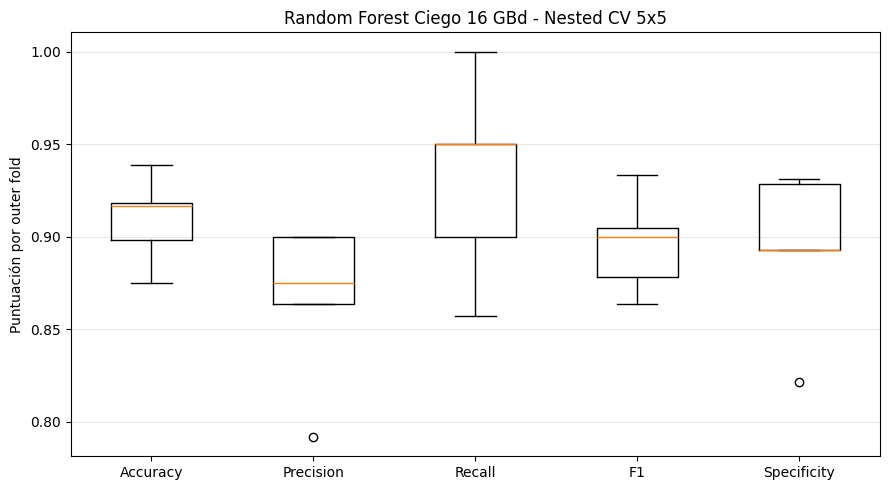


MÉTRICAS GLOBALES OUT-OF-FOLD (OOF)
OOF Accuracy:    0.9095
OOF Precision:   0.8636
OOF Recall:      0.9314
OOF F1:          0.8962
OOF Specificity: 0.8936

CLASSIFICATION REPORT OOF:
              precision    recall  f1-score   support

      NORMAL       0.95      0.89      0.92       141
      ALARMA       0.86      0.93      0.90       102

    accuracy                           0.91       243
   macro avg       0.91      0.91      0.91       243
weighted avg       0.91      0.91      0.91       243


Matriz de confusión OOF:
[[126  15]
 [  7  95]]


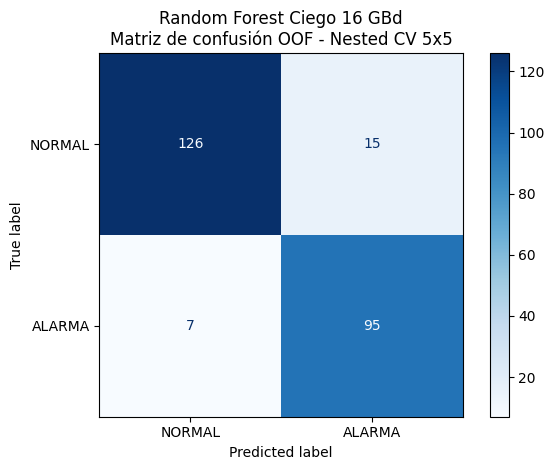


Predicciones OOF guardadas.

HIPERPARÁMETROS POR OUTER FOLD
 fold max_depth max_features  min_samples_leaf  min_samples_split  n_estimators  inner_cv_best_f1
    1      None         log2                 1                  5           400          0.890637
    2      None         log2                 1                  2           100          0.877217
    3      None         log2                 1                  2           200          0.890383
    4      None         sqrt                 1                  2           100          0.906751
    5      None         log2                 1                  5           400          0.894847

TIEMPO DE INFERENCIA - OUTER CV
Inference Mean: 88.551 µs/muestra
Inference Std:  44.408 µs/muestra
Mediciones totales: 500
Tiempo por muestra dentro de un batch. Incluye RandomForest.predict().

ENTRENANDO MODELO FINAL - RF CIEGO

Mejores parámetros modelo final:
{'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'min_samples_split

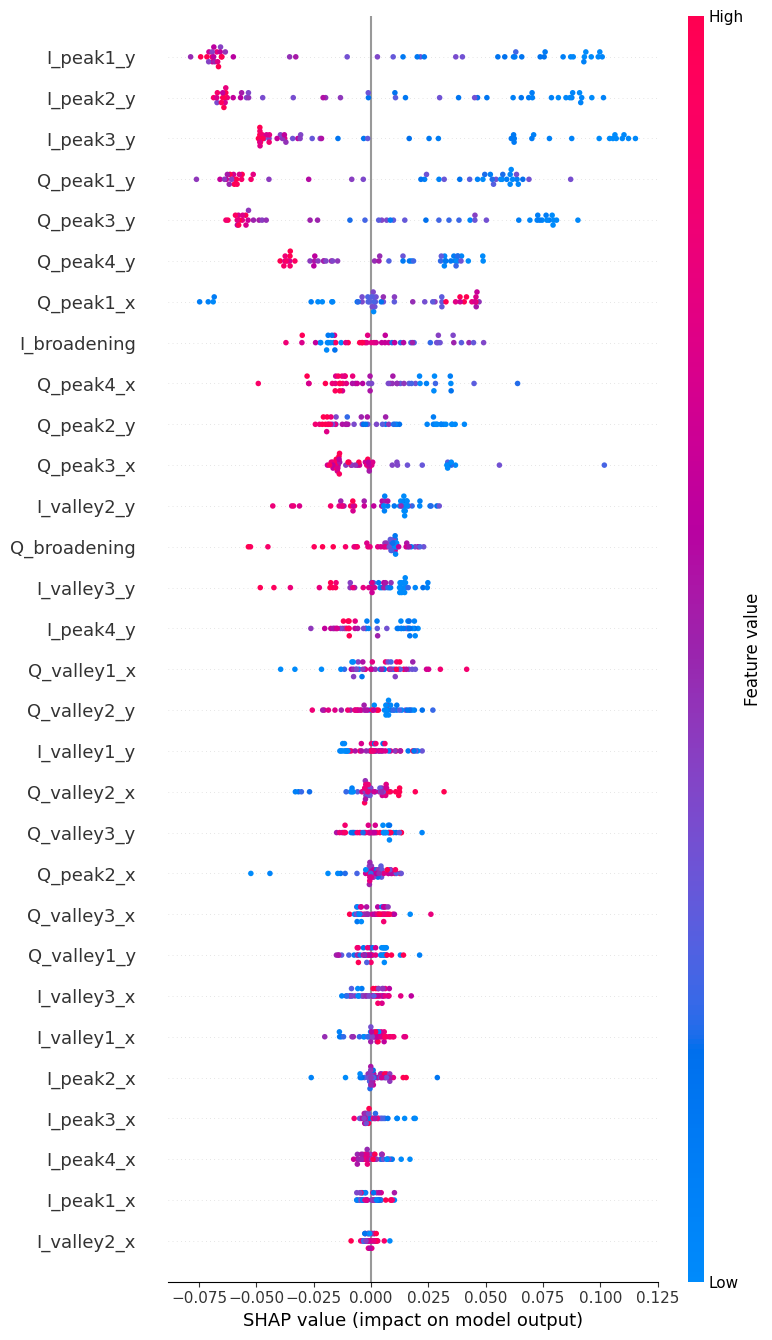

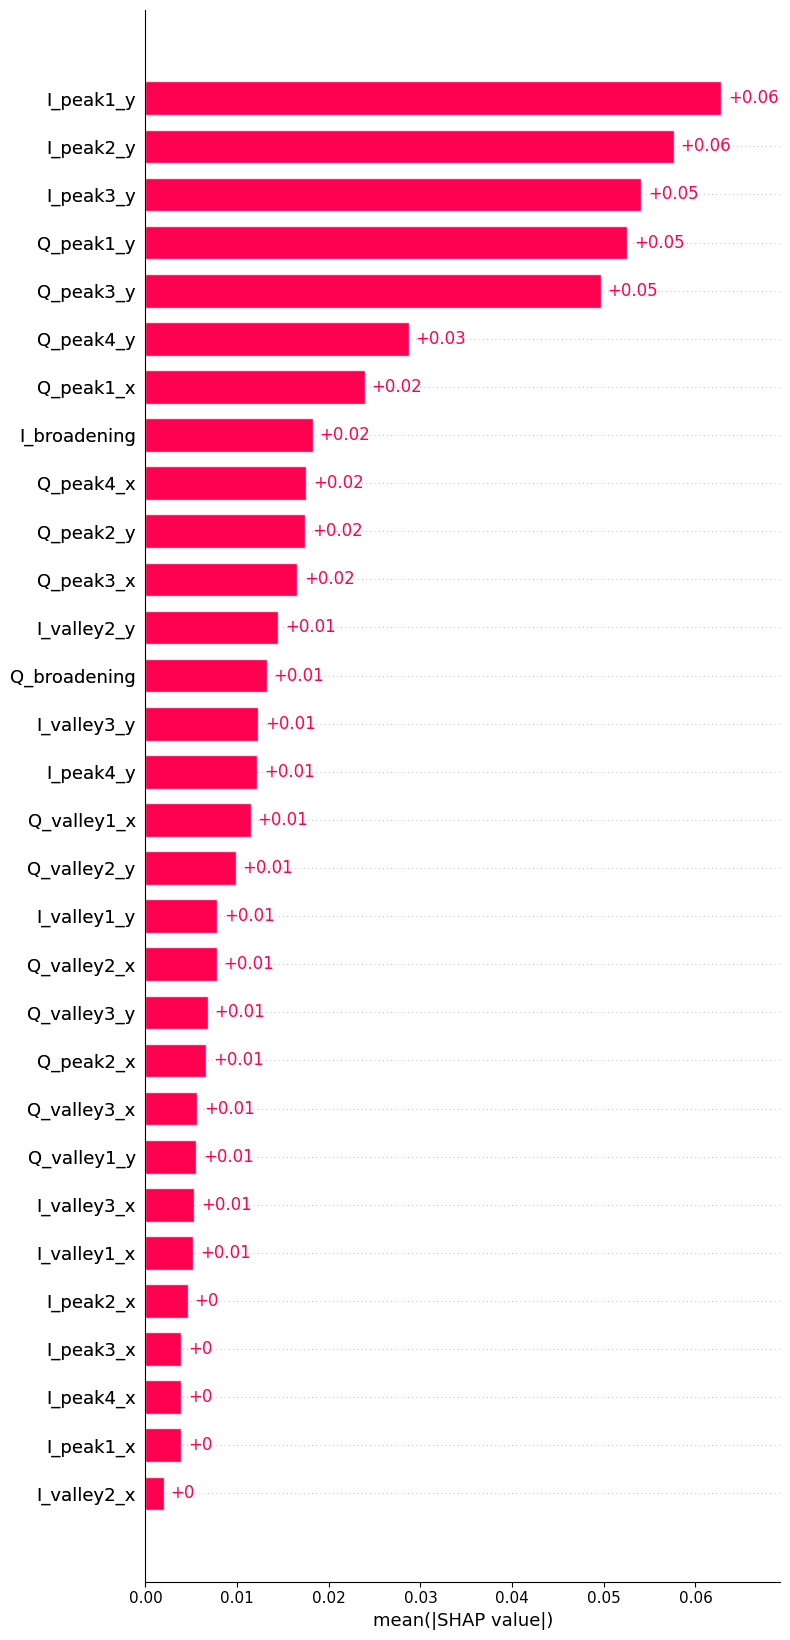

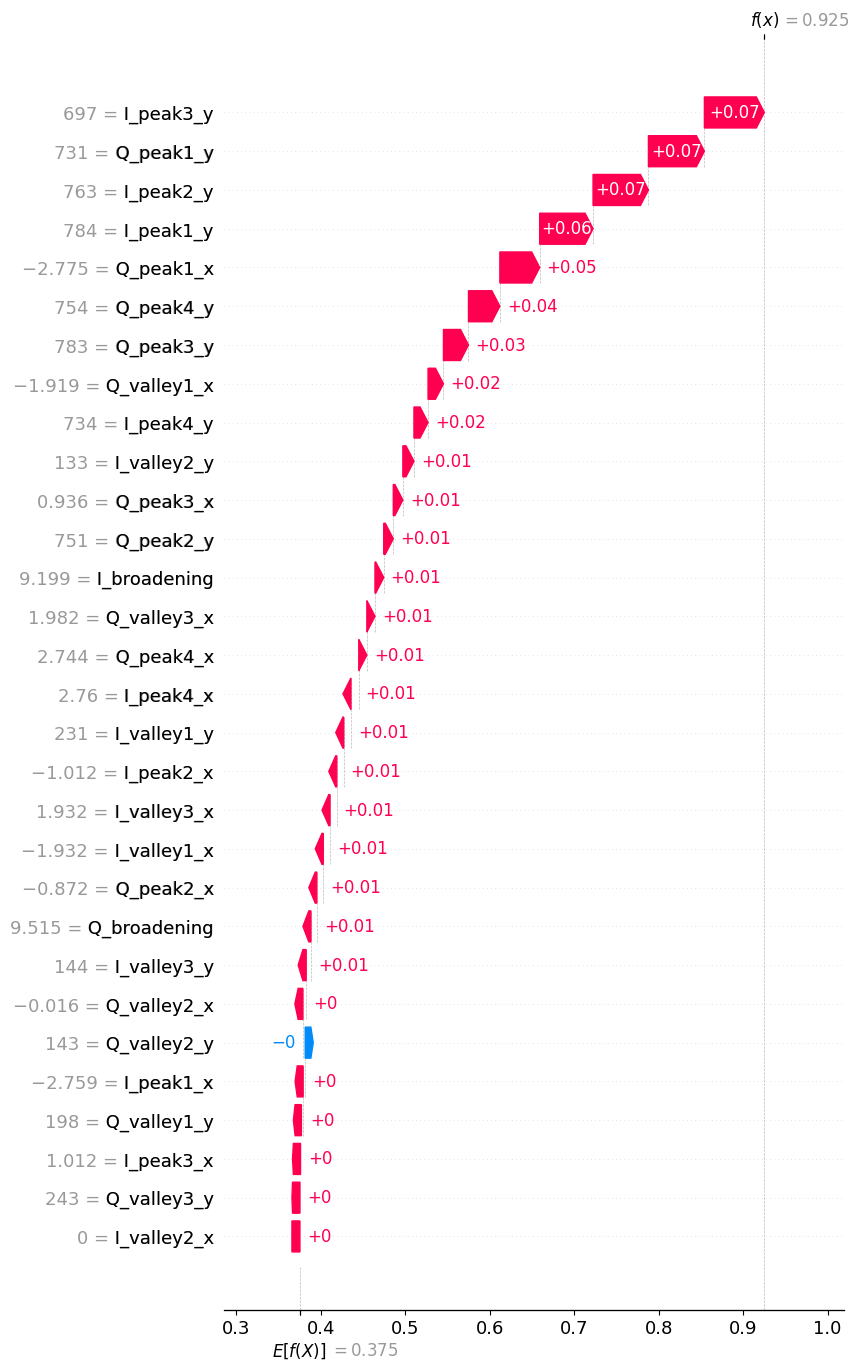


RESUMEN FINAL - RF CIEGO 16 GBd NESTED CV 5x5
Outer CV ACCURACY    : 0.9094 ± 0.0215
Outer CV PRECISION   : 0.8661 ± 0.0398
Outer CV RECALL      : 0.9314 ± 0.0488
Outer CV F1          : 0.8960 ± 0.0239
Outer CV SPECIFICITY : 0.8933 ± 0.0396

OOF Accuracy: 0.9095
OOF Precision: 0.8636
OOF Recall: 0.9314
OOF F1: 0.8962
OOF Specificity: 0.8936

Inference Mean: 88.551 µs/muestra
Inference Std: 44.408 µs/muestra

Archivos generados:
1. rf_osnr_16GBd_ciego_nested_outer_folds.csv
2. rf_osnr_16GBd_ciego_nested_oof_predictions.csv
3. rf_osnr_16GBd_ciego_nested_best_params.csv
4. rf_osnr_16GBd_ciego_nested_importancia_shap.csv

PROCESO COMPLETADO.


In [ ]:

"""
============================================================
CLASIFICACIÓN CIEGA OSNR 16 GBd - RANDOM FOREST
NESTED CROSS-VALIDATION 5x5 + PREDICCIONES OUTER-FOLD
MÉTRICAS, MATRIZ DE CONFUSIÓN, SHAP Y TIEMPO DE INFERENCIA
============================================================

CLASES:
    0 = NORMAL: OSNR > 23 dB
    1 = ALARMA: OSNR <= 23 dB

DATASET:
    30 características I/Q
    1 columna channel_sp (EXCLUIDA DEL MODELO)
    1 columna OSNR (target continuo)

MONITOREO CIEGO:
    - No se utiliza channel_sp como entrada.
    - Se utilizan exclusivamente las 30 características I/Q.
    - OSNR se utiliza para construir las etiquetas.

METODOLOGÍA:
    - Outer CV: StratifiedKFold, 5 folds
    - Inner CV: StratifiedKFold, 5 folds
    - GridSearchCV dentro de cada outer train
    - Predicciones OOF en los outer tests
    - Métricas por fold y métricas globales OOF
    - Tiempos de inferencia por outer fold
    - Modelo final entrenado con todos los datos
    - SHAP para interpretar el modelo final

IMPORTANTE:
    Esta implementación divide por filas.
    Si existen muestras del mismo escenario experimental,
    conviene considerar Nested CV agrupada por escenario.
"""

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap

from sklearn.model_selection import (
    StratifiedKFold,
    GridSearchCV
)

from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

# ============================================================
# 1. CONFIGURACIÓN GENERAL
# ============================================================

CSV_PATH = "matriz16GBd_clas.csv"

THRESHOLD_DB = 23.0

SEED = 42

N_OUTER_FOLDS = 5
N_INNER_FOLDS = 5

N_REPETITIONS = 100

SHAP_BACKGROUND = 50
SHAP_EXPLAIN = 50

# ============================================================
# 2. NOMBRES DE LAS 30 CARACTERÍSTICAS
# ============================================================

# MONITOREO CIEGO:
# No se incluye "channel_sp" entre las características.

feature_names = (
    [f"I_peak{k}_x" for k in range(1, 5)] +
    [f"I_peak{k}_y" for k in range(1, 5)] +
    [f"Q_peak{k}_x" for k in range(1, 5)] +
    [f"Q_peak{k}_y" for k in range(1, 5)] +
    [f"I_valley{k}_x" for k in range(1, 4)] +
    [f"I_valley{k}_y" for k in range(1, 4)] +
    [f"Q_valley{k}_x" for k in range(1, 4)] +
    [f"Q_valley{k}_y" for k in range(1, 4)] +
    ["I_broadening", "Q_broadening"]
)

assert len(feature_names) == 30

# ============================================================
# 3. CARGAR Y VALIDAR DATASET
# ============================================================

matriz = pd.read_csv(
    CSV_PATH,
    header=None
)

# La matriz original tiene 32 columnas:
# 30 características I/Q + channel_sp + OSNR.

if matriz.shape[1] != 32:
    raise ValueError(
        f"Se esperaban 32 columnas; "
        f"se encontraron {matriz.shape[1]}"
    )

matriz = matriz.apply(
    pd.to_numeric,
    errors="raise"
)

if not np.isfinite(matriz.to_numpy()).all():
    raise ValueError(
        "El dataset contiene NaN o infinitos."
    )

# ------------------------------------------------------------
# 3.1 SELECCIÓN DE CARACTERÍSTICAS PARA MONITOREO CIEGO
# ------------------------------------------------------------

# Se utilizan únicamente las primeras 30 columnas.
# La columna 30 (channel_sp) queda excluida.
X = matriz.iloc[:, :30].copy()

X.columns = feature_names

# La última columna contiene el OSNR continuo.
y_osnr = matriz.iloc[:, 31].to_numpy()

# Clasificación binaria:
# NORMAL = 0, si OSNR > 23 dB
# ALARMA = 1, si OSNR <= 23 dB
y = (y_osnr <= THRESHOLD_DB).astype(int)

n_samples = len(y)

class_counts = np.bincount(
    y,
    minlength=2
)

if class_counts.min() < N_OUTER_FOLDS:
    raise ValueError(
        "No hay suficientes muestras por clase "
        "para los folds externos."
    )

print("=" * 65)
print("INFORMACIÓN DEL DATASET")
print("=" * 65)

print(f"Dataset: {CSV_PATH}")
print(f"Muestras: {n_samples}")
print(f"Características utilizadas: {X.shape[1]}")
print(f"NORMAL: {class_counts[0]}")
print(f"ALARMA: {class_counts[1]}")
print(f"Umbral OSNR: {THRESHOLD_DB} dB")

print(
    "\nMONITOREO CIEGO: "
    "channel_sp NO se utiliza como entrada."
)

print("\nCaracterísticas utilizadas:")

for i, feature in enumerate(feature_names, start=1):
    print(f"{i:2d}. {feature}")

# ============================================================
# 4. DEFINIR RANDOM FOREST Y GRID
# ============================================================

def build_model():
    """
    Construye un Random Forest nuevo.

    No requiere StandardScaler.
    """

    return RandomForestClassifier(
        random_state=SEED,
        n_jobs=1
    )


# Se conserva el grid del código original.

param_grid = {
    "n_estimators": [100, 200, 400],
    "max_depth": [None, 10, 20],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4],
    "max_features": ["sqrt", "log2"]
}

n_combinations = (
    len(param_grid["n_estimators"]) *
    len(param_grid["max_depth"]) *
    len(param_grid["min_samples_split"]) *
    len(param_grid["min_samples_leaf"]) *
    len(param_grid["max_features"])
)

print("\nCombinaciones de hiperparámetros:", n_combinations)

# ============================================================
# 5. CONFIGURAR OUTER CROSS-VALIDATION
# ============================================================

outer_cv = StratifiedKFold(
    n_splits=N_OUTER_FOLDS,
    shuffle=True,
    random_state=SEED
)

# Cada muestra recibirá una predicción
# cuando pertenezca al test de un outer fold.

oof_predictions = np.full(
    n_samples,
    -1,
    dtype=int
)

# Probabilidad de ALARMA para cada muestra OOF.
oof_probabilities = np.full(
    n_samples,
    np.nan,
    dtype=float
)

# Identificador del outer fold.
oof_fold = np.full(
    n_samples,
    -1,
    dtype=int
)

outer_results = []
outer_best_params = []
outer_inference_times = []

print("\n" + "=" * 65)
print("INICIANDO NESTED CV 5x5 - RF CIEGO 16 GBd")
print("=" * 65)

# ============================================================
# 6. BUCLE PRINCIPAL: OUTER CROSS-VALIDATION
# ============================================================

for fold, (train_idx, test_idx) in enumerate(
    outer_cv.split(X, y),
    start=1
):

    print("\n" + "=" * 65)
    print(f"OUTER FOLD {fold}/{N_OUTER_FOLDS}")
    print("=" * 65)

    # --------------------------------------------------------
    # 6.1 SEPARACIÓN EXTERNA
    # --------------------------------------------------------

    X_outer_train = X.iloc[train_idx]
    X_outer_test = X.iloc[test_idx]

    y_outer_train = y[train_idx]
    y_outer_test = y[test_idx]

    print(
        f"Outer Train: {len(X_outer_train)} muestras"
    )

    print(
        f"Outer Test:  {len(X_outer_test)} muestras"
    )

    # --------------------------------------------------------
    # 6.2 INNER CV: GRIDSEARCHCV
    # --------------------------------------------------------

    # Cada outer fold tiene su propia validación interna.
    inner_cv = StratifiedKFold(
        n_splits=N_INNER_FOLDS,
        shuffle=True,
        random_state=SEED + fold
    )

    search = GridSearchCV(
        estimator=build_model(),
        param_grid=param_grid,
        scoring="f1",
        cv=inner_cv,
        n_jobs=-1,
        refit=True,
        return_train_score=False
    )

    print("\nBuscando mejores hiperparámetros...")

    # El GridSearchCV recibe únicamente el outer train.
    # El outer test NO participa en la selección.
    search.fit(
        X_outer_train,
        y_outer_train
    )

    best_rf = search.best_estimator_

    print("\nMejores hiperparámetros:")
    print(search.best_params_)

    print(
        f"Inner CV Best F1: "
        f"{search.best_score_:.4f}"
    )

    outer_best_params.append({
        "fold": fold,
        **search.best_params_,
        "inner_cv_best_f1": search.best_score_
    })

    # --------------------------------------------------------
    # 6.3 PREDICCIONES OUTER-FOLD
    # --------------------------------------------------------

    # Predicción de clase.
    y_outer_pred = best_rf.predict(
        X_outer_test
    )

    # Probabilidad de pertenecer a ALARMA (clase 1).
    y_outer_proba = best_rf.predict_proba(
        X_outer_test
    )[:, 1]

    # Guardar las predicciones en el orden original.
    oof_predictions[test_idx] = y_outer_pred

    oof_probabilities[test_idx] = y_outer_proba

    oof_fold[test_idx] = fold

    # --------------------------------------------------------
    # 6.4 MÉTRICAS DEL OUTER FOLD
    # --------------------------------------------------------

    tn, fp, fn, tp = confusion_matrix(
        y_outer_test,
        y_outer_pred,
        labels=[0, 1]
    ).ravel()

    accuracy = accuracy_score(
        y_outer_test,
        y_outer_pred
    )

    precision = precision_score(
        y_outer_test,
        y_outer_pred,
        zero_division=0
    )

    recall = recall_score(
        y_outer_test,
        y_outer_pred,
        zero_division=0
    )

    f1 = f1_score(
        y_outer_test,
        y_outer_pred,
        zero_division=0
    )

    specificity = (
        tn / (tn + fp)
        if (tn + fp) > 0
        else np.nan
    )

    # --------------------------------------------------------
    # 6.5 TIEMPO DE INFERENCIA
    # --------------------------------------------------------

    # Warm-up antes de medir.
    _ = best_rf.predict(
        X_outer_test.iloc[
            :min(10, len(X_outer_test))
        ]
    )

    inference_times = np.empty(
        N_REPETITIONS
    )

    for rep in range(N_REPETITIONS):

        start = time.perf_counter()

        _ = best_rf.predict(
            X_outer_test
        )

        elapsed = (
            time.perf_counter() - start
        )

        inference_times[rep] = (
            elapsed / len(X_outer_test)
        )

    inference_mean_us = (
        inference_times.mean() * 1e6
    )

    inference_std_us = (
        inference_times.std() * 1e6
    )

    outer_inference_times.append(
        inference_times * 1e6
    )

    # --------------------------------------------------------
    # 6.6 GUARDAR RESULTADOS DEL FOLD
    # --------------------------------------------------------

    outer_results.append({
        "fold": fold,
        "n_train": len(train_idx),
        "n_test": len(test_idx),
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "specificity": specificity,
        "inference_mean_us": inference_mean_us,
        "inference_std_us": inference_std_us
    })

    print("\nMÉTRICAS OUTER FOLD:")

    print(f"Accuracy:    {accuracy:.4f}")
    print(f"Precision:   {precision:.4f}")
    print(f"Recall:      {recall:.4f}")
    print(f"F1:          {f1:.4f}")
    print(f"Specificity: {specificity:.4f}")

    print(
        f"Inference Mean: "
        f"{inference_mean_us:.3f} µs/muestra"
    )

    print(
        f"Inference Std:  "
        f"{inference_std_us:.3f} µs/muestra"
    )

# ============================================================
# 7. VALIDAR PREDICCIONES OOF
# ============================================================

if np.any(oof_predictions == -1):
    raise RuntimeError(
        "Existen muestras sin predicción OOF."
    )

if np.any(oof_fold == -1):
    raise RuntimeError(
        "Existen muestras sin outer fold asignado."
    )

if not np.isfinite(oof_probabilities).all():
    raise RuntimeError(
        "Existen probabilidades OOF inválidas."
    )

print("\nTodas las muestras tienen predicción OOF.")

# ============================================================
# 8. RESULTADOS POR OUTER FOLD
# ============================================================

results_df = pd.DataFrame(
    outer_results
)

print("\n" + "=" * 65)
print("RESULTADOS DE LOS 5 OUTER FOLDS")
print("=" * 65)

print(
    results_df.to_string(index=False)
)

results_df.to_csv(
    "rf_osnr_16GBd_ciego_nested_outer_folds.csv",
    index=False
)

# ============================================================
# 9. PROMEDIO ± DESVIACIÓN ESTÁNDAR OUTER CV
# ============================================================

print("\n" + "=" * 65)
print("OUTER CV - PROMEDIO ± DESVIACIÓN ESTÁNDAR")
print("=" * 65)

metrics = [
    "accuracy",
    "precision",
    "recall",
    "f1",
    "specificity"
]

for metric in metrics:

    values = results_df[
        metric
    ].to_numpy()

    print(
        f"{metric.upper():12s}: "
        f"{np.nanmean(values):.4f} ± "
        f"{np.nanstd(values):.4f}"
    )

# ============================================================
# 10. GRÁFICA DE MÉTRICAS OUTER CV
# ============================================================

plt.figure(figsize=(9, 5))

plt.boxplot(
    [
        results_df[m].values
        for m in metrics
    ],
    tick_labels=[
        "Accuracy",
        "Precision",
        "Recall",
        "F1",
        "Specificity"
    ]
)

plt.ylabel("Puntuación por outer fold")

plt.title(
    "Random Forest Ciego 16 GBd - Nested CV 5x5"
)

plt.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()
plt.show()
plt.close()

# ============================================================
# 11. MÉTRICAS GLOBALES OOF
# ============================================================

print("\n" + "=" * 65)
print("MÉTRICAS GLOBALES OUT-OF-FOLD (OOF)")
print("=" * 65)

tn, fp, fn, tp = confusion_matrix(
    y,
    oof_predictions,
    labels=[0, 1]
).ravel()

oof_accuracy = accuracy_score(
    y,
    oof_predictions
)

oof_precision = precision_score(
    y,
    oof_predictions,
    zero_division=0
)

oof_recall = recall_score(
    y,
    oof_predictions,
    zero_division=0
)

oof_f1 = f1_score(
    y,
    oof_predictions,
    zero_division=0
)

oof_specificity = (
    tn / (tn + fp)
    if (tn + fp) > 0
    else np.nan
)

print(
    f"OOF Accuracy:    {oof_accuracy:.4f}"
)

print(
    f"OOF Precision:   {oof_precision:.4f}"
)

print(
    f"OOF Recall:      {oof_recall:.4f}"
)

print(
    f"OOF F1:          {oof_f1:.4f}"
)

print(
    f"OOF Specificity: {oof_specificity:.4f}"
)

print("\nCLASSIFICATION REPORT OOF:")

print(
    classification_report(
        y,
        oof_predictions,
        labels=[0, 1],
        target_names=[
            "NORMAL",
            "ALARMA"
        ],
        zero_division=0
    )
)

# ============================================================
# 12. MATRIZ DE CONFUSIÓN OOF
# ============================================================

cm_oof = confusion_matrix(
    y,
    oof_predictions,
    labels=[0, 1]
)

print("\nMatriz de confusión OOF:")

print(cm_oof)

ConfusionMatrixDisplay(
    confusion_matrix=cm_oof,
    display_labels=[
        "NORMAL",
        "ALARMA"
    ]
).plot(
    cmap="Blues",
    values_format="d"
)

plt.title(
    "Random Forest Ciego 16 GBd\n"
    "Matriz de confusión OOF - Nested CV 5x5"
)

plt.tight_layout()
plt.show()
plt.close()

# ============================================================
# 13. GUARDAR PREDICCIONES OOF
# ============================================================

oof_df = pd.DataFrame({
    "sample_index": np.arange(n_samples),
    "outer_fold": oof_fold,
    "OSNR_dB": y_osnr,
    "true_class": y,
    "predicted_class": oof_predictions,
    "probability_alarm": oof_probabilities,
    "correct": (
        y == oof_predictions
    )
})

oof_df.to_csv(
    "rf_osnr_16GBd_ciego_nested_oof_predictions.csv",
    index=False
)

print("\nPredicciones OOF guardadas.")

# ============================================================
# 14. HIPERPARÁMETROS POR OUTER FOLD
# ============================================================

params_df = pd.DataFrame(
    outer_best_params
)

print("\n" + "=" * 65)
print("HIPERPARÁMETROS POR OUTER FOLD")
print("=" * 65)

print(
    params_df.to_string(index=False)
)

params_df.to_csv(
    "rf_osnr_16GBd_ciego_nested_best_params.csv",
    index=False
)

# ============================================================
# 15. TIEMPO DE INFERENCIA OUTER CV
# ============================================================

all_inference_times = np.concatenate(
    outer_inference_times
)

print("\n" + "=" * 65)
print("TIEMPO DE INFERENCIA - OUTER CV")
print("=" * 65)

print(
    f"Inference Mean: "
    f"{all_inference_times.mean():.3f} µs/muestra"
)

print(
    f"Inference Std:  "
    f"{all_inference_times.std():.3f} µs/muestra"
)

print(
    f"Mediciones totales: "
    f"{len(all_inference_times)}"
)

print(
    "Tiempo por muestra dentro de un batch. "
    "Incluye RandomForest.predict()."
)

# ============================================================
# 16. ENTRENAR MODELO FINAL CON TODOS LOS DATOS
# ============================================================

# Este modelo se utiliza para SHAP.
# NO se utiliza para calcular las métricas OOF.
#
# Se seleccionan nuevamente los hiperparámetros
# mediante GridSearchCV sobre todo el dataset.

print("\n" + "=" * 65)
print("ENTRENANDO MODELO FINAL - RF CIEGO")
print("=" * 65)

final_inner_cv = StratifiedKFold(
    n_splits=N_INNER_FOLDS,
    shuffle=True,
    random_state=SEED
)

final_search = GridSearchCV(
    estimator=build_model(),
    param_grid=param_grid,
    scoring="f1",
    cv=final_inner_cv,
    n_jobs=-1,
    refit=True
)

final_search.fit(X, y)

final_rf = final_search.best_estimator_

print("\nMejores parámetros modelo final:")
print(final_search.best_params_)

print(
    f"F1 GridSearch final: "
    f"{final_search.best_score_:.4f}"
)

# ============================================================
# 17. SHAP - TREEEXPLAINER
# ============================================================

# TreeExplainer explica predict_proba[:, 1].
#
# SHAP positivo:
#    aumenta la probabilidad de ALARMA.
#
# SHAP negativo:
#    disminuye la probabilidad de ALARMA.
#
# Las muestras explicadas pertenecen al dataset
# utilizado para entrenar el modelo final.
#
# Por tanto, este SHAP es descriptivo, NO OOF.
#
# MONITOREO CIEGO:
# SHAP considera únicamente las 30 características I/Q.
# channel_sp no participa en el cálculo.

print("\n" + "=" * 65)
print("CALCULANDO SHAP DEL MODELO FINAL")
print("=" * 65)

background = X.sample(
    n=min(SHAP_BACKGROUND, len(X)),
    random_state=SEED
)

explained = X.sample(
    n=min(SHAP_EXPLAIN, len(X)),
    random_state=SEED + 1
)

print(
    f"Background: {len(background)} muestras"
)

print(
    f"Muestras explicadas: {len(explained)}"
)

explainer = shap.TreeExplainer(
    final_rf,
    data=background,
    feature_perturbation="interventional",
    model_output="probability"
)

raw = explainer.shap_values(
    explained,
    check_additivity=False
)

# SHAP puede devolver:
# 1. Una lista [clase 0, clase 1].
# 2. Un arreglo (muestras, características, clases).
#
# Se extraen los valores correspondientes a ALARMA.

if isinstance(raw, list):

    shap_values = np.asarray(
        raw[1]
    )

else:

    arr = np.asarray(raw)

    shap_values = (
        arr[:, :, 1]
        if arr.ndim == 3 and arr.shape[2] == 2
        else arr
    )

if shap_values.shape != explained.shape:
    raise ValueError(
        f"Forma SHAP inesperada: "
        f"{shap_values.shape}. "
        f"Se esperaba {explained.shape}."
    )

# Valor base correspondiente a ALARMA.
base = np.asarray(
    explainer.expected_value
)

base_alarm = float(
    base[1]
    if base.size == 2
    else base.item()
)

# ============================================================
# 18. IMPORTANCIA GLOBAL SHAP
# ============================================================

mean_abs = np.mean(
    np.abs(shap_values),
    axis=0
)

imp_df = pd.DataFrame({
    "feature": feature_names,
    "mean_abs_shap": mean_abs
})

imp_df = imp_df.sort_values(
    "mean_abs_shap",
    ascending=False
).reset_index(drop=True)

total = imp_df[
    "mean_abs_shap"
].sum()

if total > 0:

    imp_df["importance_percent"] = (
        100 *
        imp_df["mean_abs_shap"] /
        total
    )

else:

    imp_df["importance_percent"] = 0.0

print("\n30 CARACTERÍSTICAS ORDENADAS POR SHAP:")

print(
    imp_df.to_string(
        index=False,
        formatters={
            "mean_abs_shap": "{:.6f}".format,
            "importance_percent": "{:.2f}%".format
        }
    )
)

print(
    f"\nSuma de porcentajes: "
    f"{imp_df['importance_percent'].sum():.2f}%"
)

print("\nTOP 5 SHAP:")

print(
    imp_df.head(5).to_string(
        index=False
    )
)

imp_df.to_csv(
    "rf_osnr_16GBd_ciego_nested_importancia_shap.csv",
    index=False
)

# ============================================================
# 19. CREAR OBJETO SHAP EXPLANATION
# ============================================================

explanation = shap.Explanation(
    values=shap_values,
    base_values=np.full(
        len(explained),
        base_alarm
    ),
    data=explained.to_numpy(),
    feature_names=feature_names
)

# ============================================================
# 20. GRÁFICAS SHAP
# ============================================================

# Beeswarm
shap.plots.beeswarm(
    explanation,
    max_display=30,
    show=False
)

plt.tight_layout()
plt.show()
plt.close()

# Bar plot
shap.plots.bar(
    explanation,
    max_display=30,
    show=False
)

plt.tight_layout()
plt.show()
plt.close()

# Waterfall de la primera muestra explicada.
shap.plots.waterfall(
    explanation[0],
    max_display=30,
    show=False
)

plt.show()
plt.close()

# ============================================================
# 21. RESUMEN FINAL
# ============================================================

print("\n" + "=" * 65)
print("RESUMEN FINAL - RF CIEGO 16 GBd NESTED CV 5x5")
print("=" * 65)

for metric in metrics:

    values = results_df[
        metric
    ].to_numpy()

    print(
        f"Outer CV {metric.upper():12s}: "
        f"{np.nanmean(values):.4f} ± "
        f"{np.nanstd(values):.4f}"
    )

print(
    f"\nOOF Accuracy: "
    f"{oof_accuracy:.4f}"
)

print(
    f"OOF Precision: "
    f"{oof_precision:.4f}"
)

print(
    f"OOF Recall: "
    f"{oof_recall:.4f}"
)

print(
    f"OOF F1: "
    f"{oof_f1:.4f}"
)

print(
    f"OOF Specificity: "
    f"{oof_specificity:.4f}"
)

print(
    f"\nInference Mean: "
    f"{all_inference_times.mean():.3f} µs/muestra"
)

print(
    f"Inference Std: "
    f"{all_inference_times.std():.3f} µs/muestra"
)

print("\nArchivos generados:")

print("1. rf_osnr_16GBd_ciego_nested_outer_folds.csv")
print("2. rf_osnr_16GBd_ciego_nested_oof_predictions.csv")
print("3. rf_osnr_16GBd_ciego_nested_best_params.csv")
print("4. rf_osnr_16GBd_ciego_nested_importancia_shap.csv")

print("\nPROCESO COMPLETADO.")


## KNN 16GBd para clasificar OSNR SIN CHANNEL SPACING

INFORMACIÓN DEL DATASET
Dataset: matriz16GBd_clas.csv
Muestras: 243
Características utilizadas: 30
NORMAL: 141
ALARMA: 102
Umbral OSNR: 23.0 dB

MONITOREO CIEGO: channel_sp NO se utiliza como entrada.

Características utilizadas:
 1. I_peak1_x
 2. I_peak2_x
 3. I_peak3_x
 4. I_peak4_x
 5. I_peak1_y
 6. I_peak2_y
 7. I_peak3_y
 8. I_peak4_y
 9. Q_peak1_x
10. Q_peak2_x
11. Q_peak3_x
12. Q_peak4_x
13. Q_peak1_y
14. Q_peak2_y
15. Q_peak3_y
16. Q_peak4_y
17. I_valley1_x
18. I_valley2_x
19. I_valley3_x
20. I_valley1_y
21. I_valley2_y
22. I_valley3_y
23. Q_valley1_x
24. Q_valley2_x
25. Q_valley3_x
26. Q_valley1_y
27. Q_valley2_y
28. Q_valley3_y
29. I_broadening
30. Q_broadening

Combinaciones de hiperparámetros: 20

INICIANDO NESTED CV 5x5 - KNN CIEGO 16 GBd

OUTER FOLD 1/5
Outer Train: 194 muestras
Outer Test:  49 muestras

Buscando mejores hiperparámetros...

Mejores hiperparámetros:
{'knn__n_neighbors': 7, 'knn__p': 1, 'knn__weights': 'uniform'}
Inner CV Best F1: 0.8737

MÉTRICAS OUTER FOL

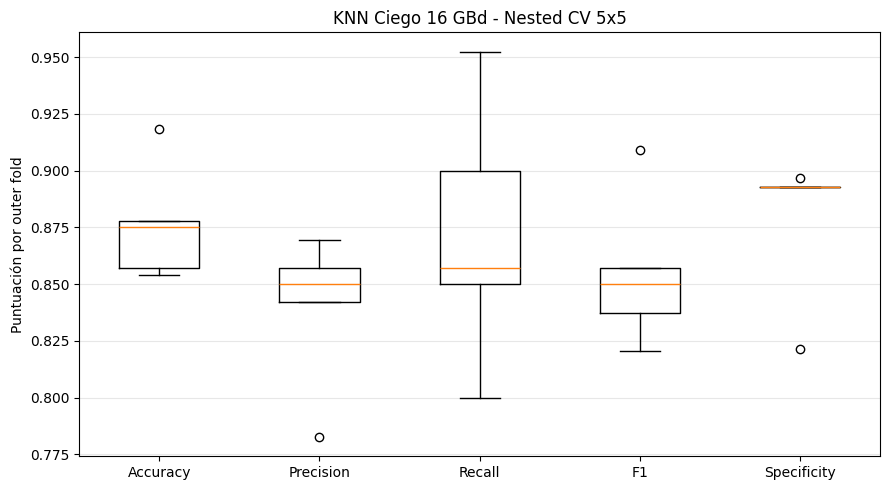


MÉTRICAS GLOBALES OUT-OF-FOLD (OOF)
OOF Accuracy:    0.8765
OOF Precision:   0.8396
OOF Recall:      0.8725
OOF F1:          0.8558
OOF Specificity: 0.8794

CLASSIFICATION REPORT OOF:
              precision    recall  f1-score   support

      NORMAL       0.91      0.88      0.89       141
      ALARMA       0.84      0.87      0.86       102

    accuracy                           0.88       243
   macro avg       0.87      0.88      0.87       243
weighted avg       0.88      0.88      0.88       243


Matriz de confusión OOF:
[[124  17]
 [ 13  89]]


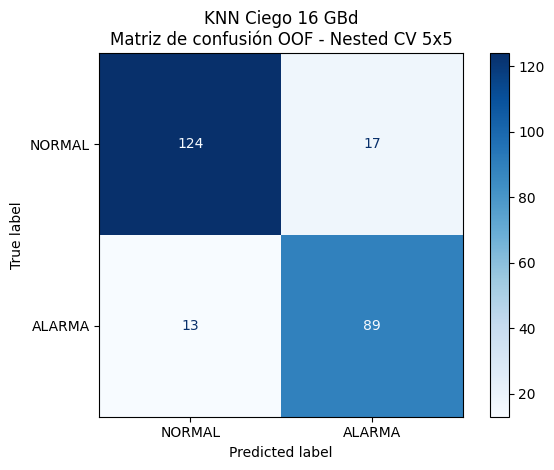


Predicciones OOF guardadas.

HIPERPARÁMETROS POR OUTER FOLD
 fold  knn__n_neighbors  knn__p knn__weights  inner_cv_best_f1
    1                 7       1      uniform          0.873730
    2                11       1      uniform          0.830494
    3                15       1      uniform          0.869143
    4                15       1      uniform          0.899574
    5                 7       1      uniform          0.839027

TIEMPO DE INFERENCIA - OUTER CV
Inference Mean: 21.684 µs/muestra
Inference Std:  2.742 µs/muestra
Mediciones totales: 500
Tiempo por muestra dentro de un batch. Incluye StandardScaler y KNN.predict().

ENTRENANDO MODELO FINAL - KNN CIEGO

Mejores parámetros modelo final:
{'knn__n_neighbors': 15, 'knn__p': 1, 'knn__weights': 'distance'}
F1 GridSearch final: 0.8545

CALCULANDO SHAP DEL MODELO FINAL
Background: 50 muestras
Muestras explicadas: 50


  0%|          | 0/50 [00:00<?, ?it/s]


30 CARACTERÍSTICAS ORDENADAS POR SHAP:
     feature mean_abs_shap importance_percent
   I_peak2_y      0.038097              7.79%
   Q_peak1_x      0.033945              6.94%
   I_peak1_y      0.033482              6.85%
   Q_peak4_y      0.031260              6.40%
   I_peak3_y      0.030186              6.18%
   Q_peak4_x      0.029408              6.02%
   Q_peak1_y      0.029191              5.97%
   Q_peak2_y      0.026625              5.45%
   Q_peak3_y      0.026018              5.32%
   Q_peak3_x      0.024286              4.97%
   I_peak4_y      0.023936              4.90%
   Q_peak2_x      0.015856              3.24%
I_broadening      0.014958              3.06%
 Q_valley3_y      0.011184              2.29%
   I_peak4_x      0.010710              2.19%
 Q_valley2_y      0.009435              1.93%
 Q_valley3_x      0.009358              1.91%
Q_broadening      0.009253              1.89%
 I_valley3_x      0.009129              1.87%
 I_valley1_y      0.008548              

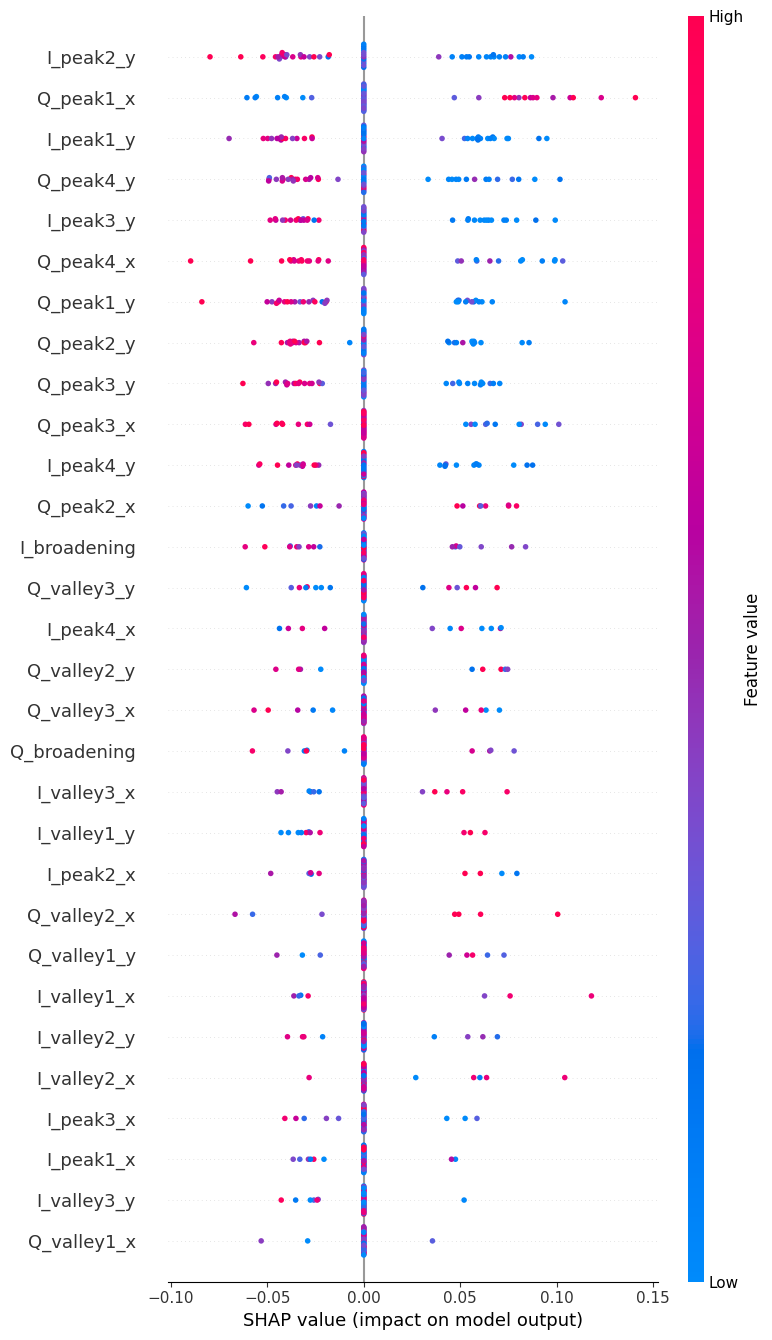

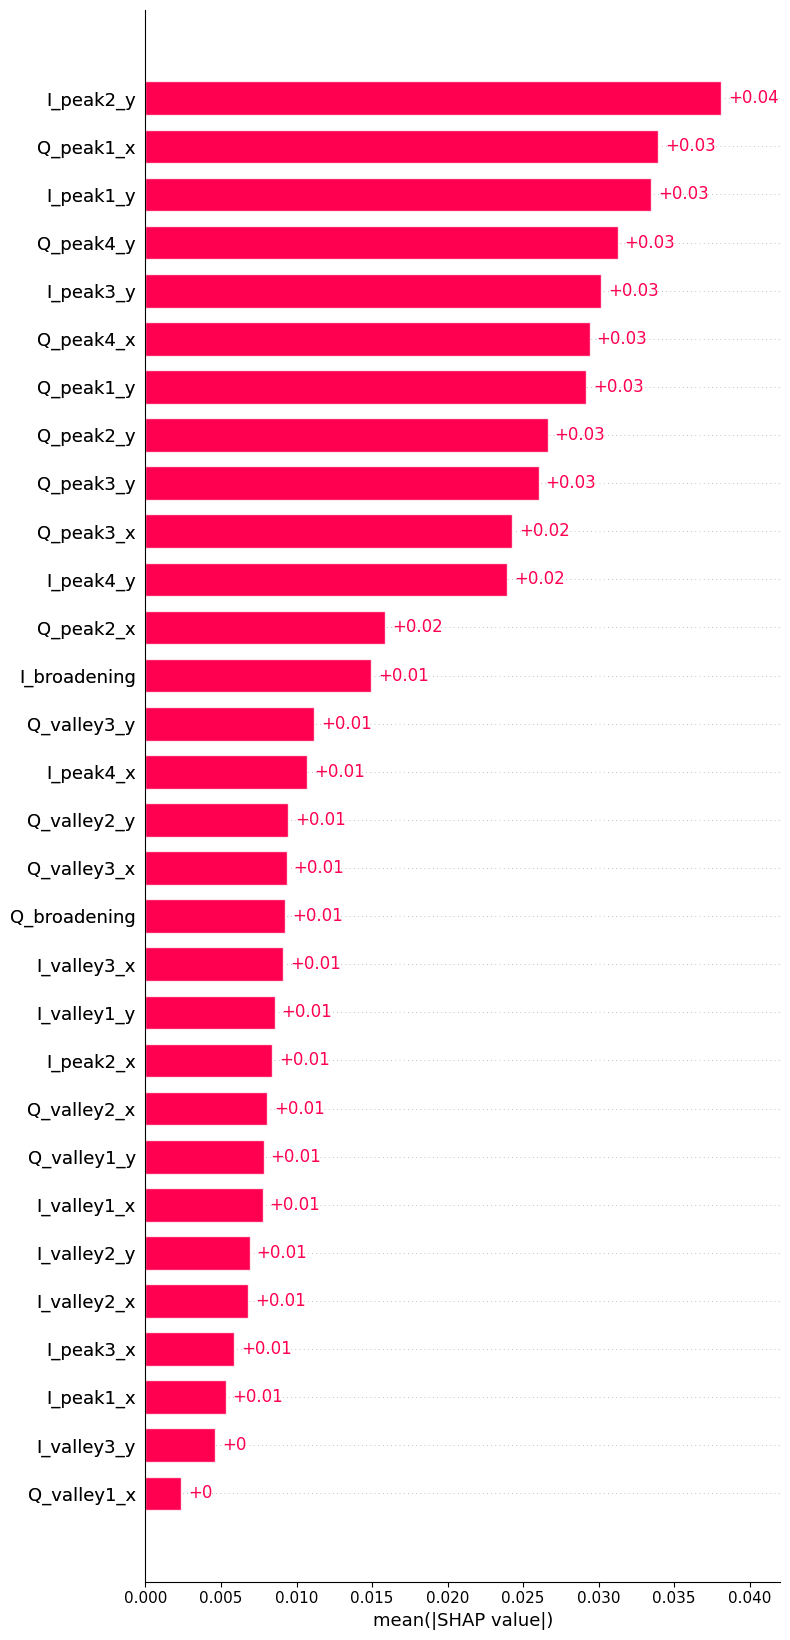

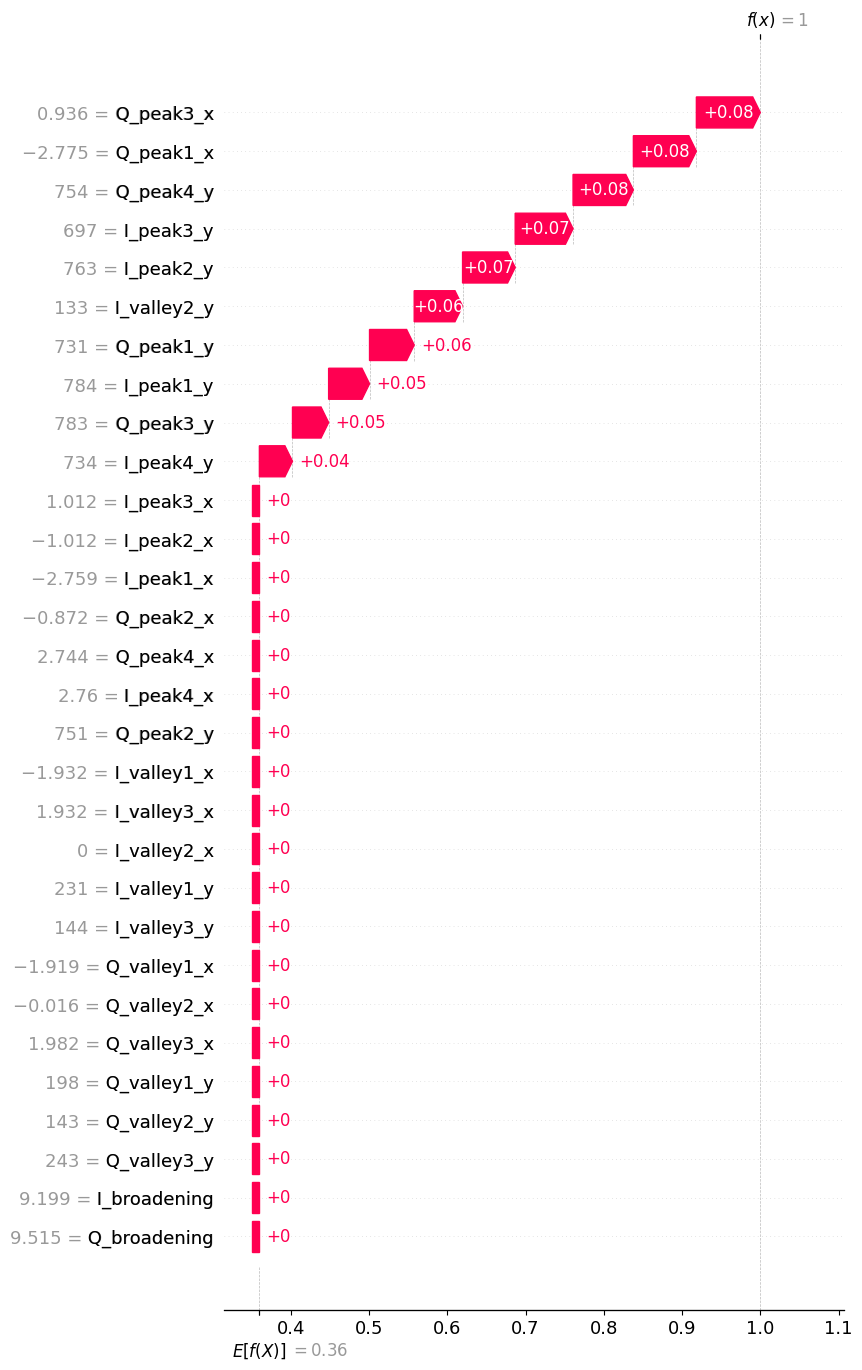


RESUMEN FINAL - KNN CIEGO 16 GBd NESTED CV 5x5
Outer CV ACCURACY    : 0.8764 ± 0.0229
Outer CV PRECISION   : 0.8403 ± 0.0302
Outer CV RECALL      : 0.8719 ± 0.0513
Outer CV F1          : 0.8548 ± 0.0299
Outer CV SPECIFICITY : 0.8793 ± 0.0290

OOF Accuracy: 0.8765
OOF Precision: 0.8396
OOF Recall: 0.8725
OOF F1: 0.8558
OOF Specificity: 0.8794

Inference Mean: 21.684 µs/muestra
Inference Std: 2.742 µs/muestra

Archivos generados:
1. knn_osnr_16GBd_ciego_nested_outer_folds.csv
2. knn_osnr_16GBd_ciego_nested_oof_predictions.csv
3. knn_osnr_16GBd_ciego_nested_best_params.csv
4. knn_osnr_16GBd_ciego_nested_importancia_shap.csv

PROCESO COMPLETADO.


In [ ]:

"""
============================================================
CLASIFICACIÓN CIEGA OSNR 16 GBd - KNN
NESTED CROSS-VALIDATION 5x5 + PREDICCIONES OUTER-FOLD
MÉTRICAS, MATRIZ DE CONFUSIÓN, SHAP Y TIEMPO DE INFERENCIA
============================================================

CLASES:
    0 = NORMAL: OSNR > 23 dB
    1 = ALARMA: OSNR <= 23 dB

DATASET:
    30 características I/Q
    1 columna channel_sp (EXCLUIDA DEL MODELO)
    1 columna OSNR (target continuo)

MONITOREO CIEGO:
    - No se utiliza channel_sp como entrada.
    - Se utilizan exclusivamente las 30 características I/Q.
    - OSNR se utiliza para construir las etiquetas.

METODOLOGÍA:
    - Outer CV: StratifiedKFold, 5 folds
    - Inner CV: StratifiedKFold, 5 folds
    - GridSearchCV dentro de cada outer train
    - Predicciones OOF en los outer tests
    - Métricas por fold y métricas globales OOF
    - Tiempos de inferencia por outer fold
    - Modelo final entrenado con todos los datos
    - SHAP para interpretar el modelo final

IMPORTANTE:
    Esta implementación divide por filas.
    Si existen muestras del mismo escenario experimental,
    conviene considerar Nested CV agrupada por escenario.
"""

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap

from sklearn.model_selection import (
    StratifiedKFold,
    GridSearchCV
)

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

# ============================================================
# 1. CONFIGURACIÓN GENERAL
# ============================================================

CSV_PATH = "matriz16GBd_clas.csv"

THRESHOLD_DB = 23.0

SEED = 42

N_OUTER_FOLDS = 5
N_INNER_FOLDS = 5

N_REPETITIONS = 100

SHAP_BACKGROUND = 50
SHAP_EXPLAIN = 50
SHAP_NSAMPLES = 300

# ============================================================
# 2. NOMBRES DE LAS 30 CARACTERÍSTICAS
# ============================================================

# MONITOREO CIEGO:
# No se incluye "channel_sp" entre las características.

feature_names = (
    [f"I_peak{k}_x" for k in range(1, 5)] +
    [f"I_peak{k}_y" for k in range(1, 5)] +
    [f"Q_peak{k}_x" for k in range(1, 5)] +
    [f"Q_peak{k}_y" for k in range(1, 5)] +
    [f"I_valley{k}_x" for k in range(1, 4)] +
    [f"I_valley{k}_y" for k in range(1, 4)] +
    [f"Q_valley{k}_x" for k in range(1, 4)] +
    [f"Q_valley{k}_y" for k in range(1, 4)] +
    ["I_broadening", "Q_broadening"]
)

assert len(feature_names) == 30

# ============================================================
# 3. CARGAR Y VALIDAR DATASET
# ============================================================

matriz = pd.read_csv(
    CSV_PATH,
    header=None
)

# La matriz original tiene 32 columnas:
# 30 características I/Q + channel_sp + OSNR.

if matriz.shape[1] != 32:
    raise ValueError(
        f"Se esperaban 32 columnas; "
        f"se encontraron {matriz.shape[1]}"
    )

matriz = matriz.apply(
    pd.to_numeric,
    errors="raise"
)

if not np.isfinite(matriz.to_numpy()).all():
    raise ValueError(
        "El dataset contiene NaN o infinitos."
    )

# ------------------------------------------------------------
# 3.1 SELECCIÓN DE CARACTERÍSTICAS PARA MONITOREO CIEGO
# ------------------------------------------------------------

# Se utilizan únicamente las primeras 30 columnas.
# La columna 30 (channel_sp) queda excluida.
X = matriz.iloc[:, :30].copy()

X.columns = feature_names

# La última columna contiene el OSNR continuo.
y_osnr = matriz.iloc[:, 31].to_numpy()

# Clasificación binaria:
# NORMAL = 0, si OSNR > 23 dB
# ALARMA = 1, si OSNR <= 23 dB
y = (y_osnr <= THRESHOLD_DB).astype(int)

n_samples = len(y)

class_counts = np.bincount(
    y,
    minlength=2
)

if class_counts.min() < N_OUTER_FOLDS:
    raise ValueError(
        "No hay suficientes muestras por clase "
        "para los folds externos."
    )

print("=" * 65)
print("INFORMACIÓN DEL DATASET")
print("=" * 65)

print(f"Dataset: {CSV_PATH}")
print(f"Muestras: {n_samples}")
print(f"Características utilizadas: {X.shape[1]}")
print(f"NORMAL: {class_counts[0]}")
print(f"ALARMA: {class_counts[1]}")
print(f"Umbral OSNR: {THRESHOLD_DB} dB")

print(
    "\nMONITOREO CIEGO: "
    "channel_sp NO se utiliza como entrada."
)

print("\nCaracterísticas utilizadas:")

for i, feature in enumerate(feature_names, start=1):
    print(f"{i:2d}. {feature}")

# ============================================================
# 4. DEFINIR PIPELINE KNN Y GRID
# ============================================================

def build_pipeline():
    """
    Construye un pipeline nuevo.

    StandardScaler se ajusta exclusivamente
    con los datos de entrenamiento de cada fold.

    El escalado forma parte del pipeline para evitar
    fuga de información entre entrenamiento y test.
    """

    return Pipeline([
        (
            "scaler",
            StandardScaler()
        ),
        (
            "knn",
            KNeighborsClassifier()
        )
    ])


# Se conserva el grid del código original.

param_grid = {
    "knn__n_neighbors": [3, 5, 7, 11, 15],
    "knn__weights": [
        "uniform",
        "distance"
    ],
    "knn__p": [
        1,
        2
    ]
}

n_combinations = (
    len(param_grid["knn__n_neighbors"]) *
    len(param_grid["knn__weights"]) *
    len(param_grid["knn__p"])
)

print("\nCombinaciones de hiperparámetros:", n_combinations)

# ============================================================
# 5. CONFIGURAR OUTER CROSS-VALIDATION
# ============================================================

outer_cv = StratifiedKFold(
    n_splits=N_OUTER_FOLDS,
    shuffle=True,
    random_state=SEED
)

# Cada muestra recibirá una predicción
# cuando pertenezca al test de un outer fold.

oof_predictions = np.full(
    n_samples,
    -1,
    dtype=int
)

# Probabilidad de ALARMA para cada muestra OOF.
oof_probabilities = np.full(
    n_samples,
    np.nan,
    dtype=float
)

# Identificador del outer fold.
oof_fold = np.full(
    n_samples,
    -1,
    dtype=int
)

outer_results = []
outer_best_params = []
outer_inference_times = []

print("\n" + "=" * 65)
print("INICIANDO NESTED CV 5x5 - KNN CIEGO 16 GBd")
print("=" * 65)

# ============================================================
# 6. BUCLE PRINCIPAL: OUTER CROSS-VALIDATION
# ============================================================

for fold, (train_idx, test_idx) in enumerate(
    outer_cv.split(X, y),
    start=1
):

    print("\n" + "=" * 65)
    print(f"OUTER FOLD {fold}/{N_OUTER_FOLDS}")
    print("=" * 65)

    # --------------------------------------------------------
    # 6.1 SEPARACIÓN EXTERNA
    # --------------------------------------------------------

    X_outer_train = X.iloc[train_idx]
    X_outer_test = X.iloc[test_idx]

    y_outer_train = y[train_idx]
    y_outer_test = y[test_idx]

    print(
        f"Outer Train: {len(X_outer_train)} muestras"
    )

    print(
        f"Outer Test:  {len(X_outer_test)} muestras"
    )

    # --------------------------------------------------------
    # 6.2 INNER CV: GRIDSEARCHCV
    # --------------------------------------------------------

    # Cada outer fold tiene su propia validación interna.
    inner_cv = StratifiedKFold(
        n_splits=N_INNER_FOLDS,
        shuffle=True,
        random_state=SEED + fold
    )

    search = GridSearchCV(
        estimator=build_pipeline(),
        param_grid=param_grid,
        scoring="f1",
        cv=inner_cv,
        n_jobs=-1,
        refit=True,
        return_train_score=False
    )

    print("\nBuscando mejores hiperparámetros...")

    # El GridSearchCV recibe únicamente el outer train.
    # El outer test NO participa en la selección.
    search.fit(
        X_outer_train,
        y_outer_train
    )

    best_knn = search.best_estimator_

    print("\nMejores hiperparámetros:")
    print(search.best_params_)

    print(
        f"Inner CV Best F1: "
        f"{search.best_score_:.4f}"
    )

    outer_best_params.append({
        "fold": fold,
        **search.best_params_,
        "inner_cv_best_f1": search.best_score_
    })

    # --------------------------------------------------------
    # 6.3 PREDICCIONES OUTER-FOLD
    # --------------------------------------------------------

    # Predicción de clase.
    y_outer_pred = best_knn.predict(
        X_outer_test
    )

    # Probabilidad de pertenecer a ALARMA (clase 1).
    y_outer_proba = best_knn.predict_proba(
        X_outer_test
    )[:, 1]

    # Guardar las predicciones en el orden original.
    oof_predictions[test_idx] = y_outer_pred

    oof_probabilities[test_idx] = y_outer_proba

    oof_fold[test_idx] = fold

    # --------------------------------------------------------
    # 6.4 MÉTRICAS DEL OUTER FOLD
    # --------------------------------------------------------

    tn, fp, fn, tp = confusion_matrix(
        y_outer_test,
        y_outer_pred,
        labels=[0, 1]
    ).ravel()

    accuracy = accuracy_score(
        y_outer_test,
        y_outer_pred
    )

    precision = precision_score(
        y_outer_test,
        y_outer_pred,
        zero_division=0
    )

    recall = recall_score(
        y_outer_test,
        y_outer_pred,
        zero_division=0
    )

    f1 = f1_score(
        y_outer_test,
        y_outer_pred,
        zero_division=0
    )

    specificity = (
        tn / (tn + fp)
        if (tn + fp) > 0
        else np.nan
    )

    # --------------------------------------------------------
    # 6.5 TIEMPO DE INFERENCIA
    # --------------------------------------------------------

    # Warm-up antes de medir.
    _ = best_knn.predict(
        X_outer_test.iloc[
            :min(10, len(X_outer_test))
        ]
    )

    inference_times = np.empty(
        N_REPETITIONS
    )

    for rep in range(N_REPETITIONS):

        start = time.perf_counter()

        _ = best_knn.predict(
            X_outer_test
        )

        elapsed = (
            time.perf_counter() - start
        )

        inference_times[rep] = (
            elapsed / len(X_outer_test)
        )

    inference_mean_us = (
        inference_times.mean() * 1e6
    )

    inference_std_us = (
        inference_times.std() * 1e6
    )

    outer_inference_times.append(
        inference_times * 1e6
    )

    # --------------------------------------------------------
    # 6.6 GUARDAR RESULTADOS DEL FOLD
    # --------------------------------------------------------

    outer_results.append({
        "fold": fold,
        "n_train": len(train_idx),
        "n_test": len(test_idx),
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "specificity": specificity,
        "inference_mean_us": inference_mean_us,
        "inference_std_us": inference_std_us
    })

    print("\nMÉTRICAS OUTER FOLD:")

    print(f"Accuracy:    {accuracy:.4f}")
    print(f"Precision:   {precision:.4f}")
    print(f"Recall:      {recall:.4f}")
    print(f"F1:          {f1:.4f}")
    print(f"Specificity: {specificity:.4f}")

    print(
        f"Inference Mean: "
        f"{inference_mean_us:.3f} µs/muestra"
    )

    print(
        f"Inference Std:  "
        f"{inference_std_us:.3f} µs/muestra"
    )

# ============================================================
# 7. VALIDAR PREDICCIONES OOF
# ============================================================

if np.any(oof_predictions == -1):
    raise RuntimeError(
        "Existen muestras sin predicción OOF."
    )

if np.any(oof_fold == -1):
    raise RuntimeError(
        "Existen muestras sin outer fold asignado."
    )

if not np.isfinite(oof_probabilities).all():
    raise RuntimeError(
        "Existen probabilidades OOF inválidas."
    )

print("\nTodas las muestras tienen predicción OOF.")

# ============================================================
# 8. RESULTADOS POR OUTER FOLD
# ============================================================

results_df = pd.DataFrame(
    outer_results
)

print("\n" + "=" * 65)
print("RESULTADOS DE LOS 5 OUTER FOLDS")
print("=" * 65)

print(
    results_df.to_string(index=False)
)

results_df.to_csv(
    "knn_osnr_16GBd_ciego_nested_outer_folds.csv",
    index=False
)

# ============================================================
# 9. PROMEDIO ± DESVIACIÓN ESTÁNDAR OUTER CV
# ============================================================

print("\n" + "=" * 65)
print("OUTER CV - PROMEDIO ± DESVIACIÓN ESTÁNDAR")
print("=" * 65)

metrics = [
    "accuracy",
    "precision",
    "recall",
    "f1",
    "specificity"
]

for metric in metrics:

    values = results_df[
        metric
    ].to_numpy()

    print(
        f"{metric.upper():12s}: "
        f"{np.nanmean(values):.4f} ± "
        f"{np.nanstd(values):.4f}"
    )

# ============================================================
# 10. GRÁFICA DE MÉTRICAS OUTER CV
# ============================================================

plt.figure(figsize=(9, 5))

plt.boxplot(
    [
        results_df[m].values
        for m in metrics
    ],
    tick_labels=[
        "Accuracy",
        "Precision",
        "Recall",
        "F1",
        "Specificity"
    ]
)

plt.ylabel("Puntuación por outer fold")

plt.title(
    "KNN Ciego 16 GBd - Nested CV 5x5"
)

plt.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()
plt.show()
plt.close()

# ============================================================
# 11. MÉTRICAS GLOBALES OOF
# ============================================================

print("\n" + "=" * 65)
print("MÉTRICAS GLOBALES OUT-OF-FOLD (OOF)")
print("=" * 65)

tn, fp, fn, tp = confusion_matrix(
    y,
    oof_predictions,
    labels=[0, 1]
).ravel()

oof_accuracy = accuracy_score(
    y,
    oof_predictions
)

oof_precision = precision_score(
    y,
    oof_predictions,
    zero_division=0
)

oof_recall = recall_score(
    y,
    oof_predictions,
    zero_division=0
)

oof_f1 = f1_score(
    y,
    oof_predictions,
    zero_division=0
)

oof_specificity = (
    tn / (tn + fp)
    if (tn + fp) > 0
    else np.nan
)

print(
    f"OOF Accuracy:    {oof_accuracy:.4f}"
)

print(
    f"OOF Precision:   {oof_precision:.4f}"
)

print(
    f"OOF Recall:      {oof_recall:.4f}"
)

print(
    f"OOF F1:          {oof_f1:.4f}"
)

print(
    f"OOF Specificity: {oof_specificity:.4f}"
)

print("\nCLASSIFICATION REPORT OOF:")

print(
    classification_report(
        y,
        oof_predictions,
        labels=[0, 1],
        target_names=[
            "NORMAL",
            "ALARMA"
        ],
        zero_division=0
    )
)

# ============================================================
# 12. MATRIZ DE CONFUSIÓN OOF
# ============================================================

cm_oof = confusion_matrix(
    y,
    oof_predictions,
    labels=[0, 1]
)

print("\nMatriz de confusión OOF:")

print(cm_oof)

ConfusionMatrixDisplay(
    confusion_matrix=cm_oof,
    display_labels=[
        "NORMAL",
        "ALARMA"
    ]
).plot(
    cmap="Blues",
    values_format="d"
)

plt.title(
    "KNN Ciego 16 GBd\n"
    "Matriz de confusión OOF - Nested CV 5x5"
)

plt.tight_layout()
plt.show()
plt.close()

# ============================================================
# 13. GUARDAR PREDICCIONES OOF
# ============================================================

oof_df = pd.DataFrame({
    "sample_index": np.arange(n_samples),
    "outer_fold": oof_fold,
    "OSNR_dB": y_osnr,
    "true_class": y,
    "predicted_class": oof_predictions,
    "probability_alarm": oof_probabilities,
    "correct": (
        y == oof_predictions
    )
})

oof_df.to_csv(
    "knn_osnr_16GBd_ciego_nested_oof_predictions.csv",
    index=False
)

print("\nPredicciones OOF guardadas.")

# ============================================================
# 14. HIPERPARÁMETROS POR OUTER FOLD
# ============================================================

params_df = pd.DataFrame(
    outer_best_params
)

print("\n" + "=" * 65)
print("HIPERPARÁMETROS POR OUTER FOLD")
print("=" * 65)

print(
    params_df.to_string(index=False)
)

params_df.to_csv(
    "knn_osnr_16GBd_ciego_nested_best_params.csv",
    index=False
)

# ============================================================
# 15. TIEMPO DE INFERENCIA OUTER CV
# ============================================================

all_inference_times = np.concatenate(
    outer_inference_times
)

print("\n" + "=" * 65)
print("TIEMPO DE INFERENCIA - OUTER CV")
print("=" * 65)

print(
    f"Inference Mean: "
    f"{all_inference_times.mean():.3f} µs/muestra"
)

print(
    f"Inference Std:  "
    f"{all_inference_times.std():.3f} µs/muestra"
)

print(
    f"Mediciones totales: "
    f"{len(all_inference_times)}"
)

print(
    "Tiempo por muestra dentro de un batch. "
    "Incluye StandardScaler y KNN.predict()."
)

# ============================================================
# 16. ENTRENAR MODELO FINAL CON TODOS LOS DATOS
# ============================================================

# Este modelo se utiliza para SHAP.
# NO se utiliza para calcular las métricas OOF.
#
# Se seleccionan nuevamente los hiperparámetros
# mediante GridSearchCV sobre todo el dataset.

print("\n" + "=" * 65)
print("ENTRENANDO MODELO FINAL - KNN CIEGO")
print("=" * 65)

final_inner_cv = StratifiedKFold(
    n_splits=N_INNER_FOLDS,
    shuffle=True,
    random_state=SEED
)

final_search = GridSearchCV(
    estimator=build_pipeline(),
    param_grid=param_grid,
    scoring="f1",
    cv=final_inner_cv,
    n_jobs=-1,
    refit=True
)

final_search.fit(X, y)

final_knn = final_search.best_estimator_

print("\nMejores parámetros modelo final:")
print(final_search.best_params_)

print(
    f"F1 GridSearch final: "
    f"{final_search.best_score_:.4f}"
)

# ============================================================
# 17. SHAP - KERNELEXPLAINER
# ============================================================

# SHAP explica predict_proba[:, 1] del KNN final.
#
# SHAP positivo:
#    aumenta la probabilidad de ALARMA.
#
# SHAP negativo:
#    disminuye la probabilidad de ALARMA.
#
# Las muestras explicadas pertenecen al dataset
# utilizado para entrenar el modelo final.
#
# Por tanto, este SHAP es descriptivo, NO OOF.
#
# MONITOREO CIEGO:
# SHAP considera únicamente las 30 características I/Q.
# channel_sp no participa en el cálculo.

print("\n" + "=" * 65)
print("CALCULANDO SHAP DEL MODELO FINAL")
print("=" * 65)

background = X.sample(
    n=min(SHAP_BACKGROUND, len(X)),
    random_state=SEED
)

explained = X.sample(
    n=min(SHAP_EXPLAIN, len(X)),
    random_state=SEED + 1
)

print(
    f"Background: {len(background)} muestras"
)

print(
    f"Muestras explicadas: {len(explained)}"
)

def knn_alarm_probability(data):
    """
    Adaptador para SHAP.

    Conserva nombres y orden de las 30 columnas.
    Devuelve P(ALARMA), correspondiente a la clase 1.
    """

    frame = pd.DataFrame(
        np.asarray(data),
        columns=feature_names
    )

    return final_knn.predict_proba(frame)[:, 1]


explainer = shap.KernelExplainer(
    knn_alarm_probability,
    background
)

raw = explainer.shap_values(
    explained,
    nsamples=SHAP_NSAMPLES
)

shap_values = np.asarray(raw)

if shap_values.shape != explained.shape:
    raise ValueError(
        f"Forma SHAP inesperada: "
        f"{shap_values.shape}. "
        f"Se esperaba {explained.shape}."
    )

# ============================================================
# 18. IMPORTANCIA GLOBAL SHAP
# ============================================================

mean_abs = np.mean(
    np.abs(shap_values),
    axis=0
)

imp_df = pd.DataFrame({
    "feature": feature_names,
    "mean_abs_shap": mean_abs
})

imp_df = imp_df.sort_values(
    "mean_abs_shap",
    ascending=False
).reset_index(drop=True)

total = imp_df[
    "mean_abs_shap"
].sum()

if total > 0:

    imp_df["importance_percent"] = (
        100 *
        imp_df["mean_abs_shap"] /
        total
    )

else:

    imp_df["importance_percent"] = 0.0

print("\n30 CARACTERÍSTICAS ORDENADAS POR SHAP:")

print(
    imp_df.to_string(
        index=False,
        formatters={
            "mean_abs_shap": "{:.6f}".format,
            "importance_percent": "{:.2f}%".format
        }
    )
)

print(
    f"\nSuma de porcentajes: "
    f"{imp_df['importance_percent'].sum():.2f}%"
)

print("\nTOP 5 SHAP:")

print(
    imp_df.head(5).to_string(
        index=False
    )
)

imp_df.to_csv(
    "knn_osnr_16GBd_ciego_nested_importancia_shap.csv",
    index=False
)

# ============================================================
# 19. CREAR OBJETO SHAP EXPLANATION
# ============================================================

expected_value = float(
    np.asarray(
        explainer.expected_value
    ).item()
)

explanation = shap.Explanation(
    values=shap_values,
    base_values=np.full(
        len(explained),
        expected_value
    ),
    data=explained.to_numpy(),
    feature_names=feature_names
)

# ============================================================
# 20. GRÁFICAS SHAP
# ============================================================

# Beeswarm
shap.plots.beeswarm(
    explanation,
    max_display=30,
    show=False
)

plt.tight_layout()
plt.show()
plt.close()

# Bar plot
shap.plots.bar(
    explanation,
    max_display=30,
    show=False
)

plt.tight_layout()
plt.show()
plt.close()

# Waterfall de la primera muestra explicada.
shap.plots.waterfall(
    explanation[0],
    max_display=30,
    show=False
)

plt.show()
plt.close()

# ============================================================
# 21. RESUMEN FINAL
# ============================================================

print("\n" + "=" * 65)
print("RESUMEN FINAL - KNN CIEGO 16 GBd NESTED CV 5x5")
print("=" * 65)

for metric in metrics:

    values = results_df[
        metric
    ].to_numpy()

    print(
        f"Outer CV {metric.upper():12s}: "
        f"{np.nanmean(values):.4f} ± "
        f"{np.nanstd(values):.4f}"
    )

print(
    f"\nOOF Accuracy: "
    f"{oof_accuracy:.4f}"
)

print(
    f"OOF Precision: "
    f"{oof_precision:.4f}"
)

print(
    f"OOF Recall: "
    f"{oof_recall:.4f}"
)

print(
    f"OOF F1: "
    f"{oof_f1:.4f}"
)

print(
    f"OOF Specificity: "
    f"{oof_specificity:.4f}"
)

print(
    f"\nInference Mean: "
    f"{all_inference_times.mean():.3f} µs/muestra"
)

print(
    f"Inference Std: "
    f"{all_inference_times.std():.3f} µs/muestra"
)

print("\nArchivos generados:")

print("1. knn_osnr_16GBd_ciego_nested_outer_folds.csv")
print("2. knn_osnr_16GBd_ciego_nested_oof_predictions.csv")
print("3. knn_osnr_16GBd_ciego_nested_best_params.csv")
print("4. knn_osnr_16GBd_ciego_nested_importancia_shap.csv")

print("\nPROCESO COMPLETADO.")


# PRUEBAS PARA JUSTIFICAR
##Para justificar el por qué sin channel spacing la OSNR para 16GBd dio mayor a cuando es conocida

In [ ]:
import numpy as np
import pandas as pd

from scipy.stats import binomtest
from sklearn.model_selection import (
    train_test_split, StratifiedKFold, GridSearchCV
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix

CSV_PATH = "matriz16GBd_clas.csv"
SEED = 42

matriz = pd.read_csv(CSV_PATH, header=None)
if matriz.shape[1] != 32:
    raise ValueError("Se esperan 32 columnas: 31 características + OSNR")

# Conservamos los índices de fila para identificar los casos que cambian.
indices = np.arange(len(matriz))
y = (matriz.iloc[:, 31].to_numpy() <= 23.0).astype(int)

idx_train, idx_test = train_test_split(
    indices,
    test_size=0.20,
    stratify=y,
    random_state=SEED
)

cv = StratifiedKFold(
    n_splits=5, shuffle=True, random_state=SEED
)

param_grid = {
    "knn__n_neighbors": [3, 5, 7, 11, 15],
    "knn__weights": ["uniform", "distance"],
    "knn__p": [1, 2],
}

predicciones = {}

for nombre, n_features in [
    ("ciego", 30),
    ("con_spacing", 31),
]:
    X = matriz.iloc[:, :n_features]

    modelo = Pipeline([
        ("scaler", StandardScaler()),
        ("knn", KNeighborsClassifier())
    ])

    busqueda = GridSearchCV(
        modelo,
        param_grid,
        scoring="f1",
        cv=cv,
        n_jobs=-1,
        refit=True
    )

    busqueda.fit(X.iloc[idx_train], y[idx_train])
    predicciones[nombre] = busqueda.predict(X.iloc[idx_test])

    print(f"\n{nombre.upper()}")
    print("Mejores parámetros:", busqueda.best_params_)
    print(
        "Accuracy test:",
        accuracy_score(y[idx_test], predicciones[nombre])
    )
    print(
        "Matriz de confusión:\n",
        confusion_matrix(
            y[idx_test],
            predicciones[nombre],
            labels=[0, 1]
        )
    )

comparacion = pd.DataFrame({
    "fila_original_csv": idx_test,
    "OSNR_dB": matriz.iloc[idx_test, 31].to_numpy(),
    "channel_sp": matriz.iloc[idx_test, 30].to_numpy(),
    "clase_real": y[idx_test],
    "pred_ciego": predicciones["ciego"],
    "pred_con_spacing": predicciones["con_spacing"],
})

comparacion["acierto_ciego"] = (
    comparacion["pred_ciego"] == comparacion["clase_real"]
)
comparacion["acierto_con_spacing"] = (
    comparacion["pred_con_spacing"] == comparacion["clase_real"]
)

print("\nFILAS EN QUE CAMBIA LA PREDICCIÓN:")
print(
    comparacion.loc[
        comparacion["pred_ciego"]
        != comparacion["pred_con_spacing"]
    ].sort_values("fila_original_csv").to_string(index=False)
)

solo_ciego_acierta = (
    comparacion["acierto_ciego"]
    & ~comparacion["acierto_con_spacing"]
).sum()

solo_spacing_acierta = (
    ~comparacion["acierto_ciego"]
    & comparacion["acierto_con_spacing"]
).sum()

print("\nSolo acierta el ciego:", solo_ciego_acierta)
print("Solo acierta el asistido:", solo_spacing_acierta)

# Prueba exacta de McNemar para predicciones emparejadas.
discordancias = solo_ciego_acierta + solo_spacing_acierta
if discordancias:
    p_valor = binomtest(
        min(solo_ciego_acierta, solo_spacing_acierta),
        n=discordancias,
        p=0.5,
        alternative="two-sided"
    ).pvalue
    print(f"McNemar exacto, p = {p_valor:.4f}")


CIEGO
Mejores parámetros: {'knn__n_neighbors': 7, 'knn__p': 1, 'knn__weights': 'uniform'}
Accuracy test: 0.8571428571428571
Matriz de confusión:
 [[23  5]
 [ 2 19]]

CON_SPACING
Mejores parámetros: {'knn__n_neighbors': 7, 'knn__p': 1, 'knn__weights': 'uniform'}
Accuracy test: 0.8367346938775511
Matriz de confusión:
 [[23  5]
 [ 3 18]]

FILAS EN QUE CAMBIA LA PREDICCIÓN:
 fila_original_csv  OSNR_dB  channel_sp  clase_real  pred_ciego  pred_con_spacing  acierto_ciego  acierto_con_spacing
                95     23.0        16.5           1           1                 0           True                False

Solo acierta el ciego: 1
Solo acierta el asistido: 0
McNemar exacto, p = 1.0000


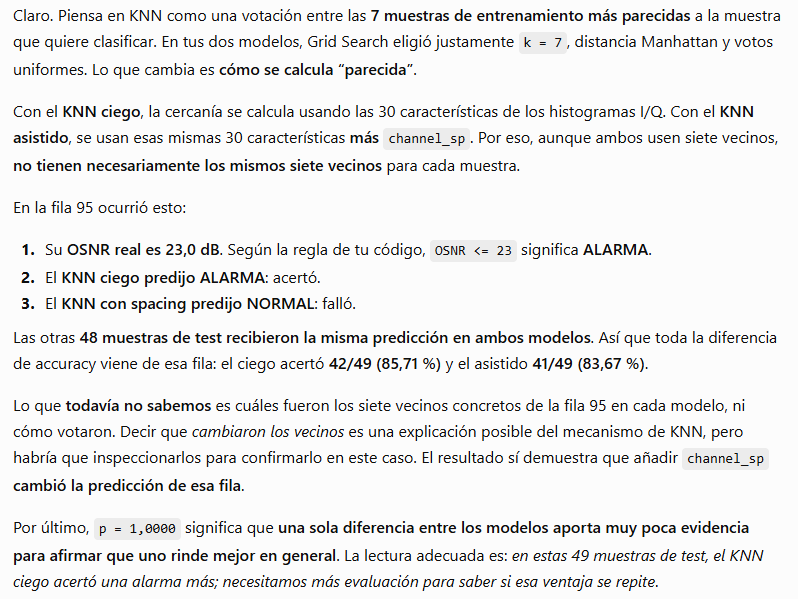

In [ ]:
"""Compara KNN ciego/asistido y muestra sus vecinos para una fila de test."""
import numpy as np
import pandas as pd
from scipy.stats import binomtest
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix

CSV_PATH = "matriz16GBd_clas.csv"
UMBRAL_OSNR = 23.0
SEED = 42
FILA_A_REVISAR = 95  # Índice de pandas/Python; primera fila del CSV = 0.

matriz = pd.read_csv(CSV_PATH, header=None)
if matriz.shape[1] != 32:
    raise ValueError(f"Se esperan 32 columnas y hay {matriz.shape[1]}.")
matriz = matriz.apply(pd.to_numeric, errors="raise")
if not np.isfinite(matriz.to_numpy()).all():
    raise ValueError("El CSV contiene NaN o valores infinitos.")

# La columna 30 es channel_sp; la 31 es OSNR. OSNR=23 es ALARMA.
y = (matriz.iloc[:, 31].to_numpy() <= UMBRAL_OSNR).astype(int)
indices = np.arange(len(matriz))
idx_train, idx_test = train_test_split(
    indices, test_size=0.20, stratify=y, random_state=SEED
)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
param_grid = {
    "knn__n_neighbors": [3, 5, 7, 11, 15],
    "knn__weights": ["uniform", "distance"],
    "knn__p": [1, 2],
}

modelos = {}
predicciones = {}
for nombre, n_features in [("ciego", 30), ("con_spacing", 31)]:
    # El ciego utiliza columnas 0..29; el asistido utiliza 0..30.
    X = matriz.iloc[:, :n_features]
    pipeline = Pipeline([
        ("scaler", StandardScaler()),
        ("knn", KNeighborsClassifier()),
    ])
    busqueda = GridSearchCV(
        pipeline, param_grid, cv=cv, scoring="f1", n_jobs=-1, refit=True
    )
    busqueda.fit(X.iloc[idx_train], y[idx_train])
    modelos[nombre] = busqueda.best_estimator_
    predicciones[nombre] = modelos[nombre].predict(X.iloc[idx_test])

    print(f"\n=== {nombre.upper()} ===")
    print("Hiperparámetros:", busqueda.best_params_)
    print("Accuracy en test:", f"{accuracy_score(y[idx_test], predicciones[nombre]):.4f}")
    print("Matriz de confusión [NORMAL, ALARMA]:")
    print(confusion_matrix(y[idx_test], predicciones[nombre], labels=[0, 1]))

comparacion = pd.DataFrame({
    "fila_csv": idx_test,
    "OSNR_dB": matriz.iloc[idx_test, 31].to_numpy(),
    "channel_sp": matriz.iloc[idx_test, 30].to_numpy(),
    "clase_real": y[idx_test],
    "pred_ciego": predicciones["ciego"],
    "pred_con_spacing": predicciones["con_spacing"],
})
comparacion["acierto_ciego"] = comparacion["pred_ciego"] == comparacion["clase_real"]
comparacion["acierto_con_spacing"] = (
    comparacion["pred_con_spacing"] == comparacion["clase_real"]
)
print("\n=== FILAS DONDE CAMBIA LA PREDICCIÓN ===")
cambios = comparacion[comparacion["pred_ciego"] != comparacion["pred_con_spacing"]]
print(cambios.sort_values("fila_csv").to_string(index=False) if len(cambios)
      else "Los modelos predijeron lo mismo en todo el test.")

solo_ciego = int((comparacion["acierto_ciego"] & ~comparacion["acierto_con_spacing"]).sum())
solo_asistido = int((~comparacion["acierto_ciego"] & comparacion["acierto_con_spacing"]).sum())
print(f"\nSolo acierta el ciego: {solo_ciego}")
print(f"Solo acierta el asistido: {solo_asistido}")
if solo_ciego + solo_asistido:
    p = binomtest(min(solo_ciego, solo_asistido),
                n=solo_ciego + solo_asistido, p=0.5,
                alternative="two-sided").pvalue
    print(f"McNemar exacto, p = {p:.4f}")

if FILA_A_REVISAR not in idx_test:
    raise ValueError(
        f"La fila {FILA_A_REVISAR} no está en test con esta semilla. "
        "Elige una fila de la tabla de cambios o revisa que uses el mismo CSV."
    )
print(f"\n=== VECINOS DE LA FILA {FILA_A_REVISAR} ===")
print("OSNR real:", matriz.iloc[FILA_A_REVISAR, 31], "dB;")
print("channel_sp:", matriz.iloc[FILA_A_REVISAR, 30])
print("Clase real:", "ALARMA" if y[FILA_A_REVISAR] else "NORMAL")

vecinos_por_modelo = {}
for nombre, n_features in [("ciego", 30), ("con_spacing", 31)]:
    modelo = modelos[nombre]
    X_caso = matriz.iloc[[FILA_A_REVISAR], :n_features]
    caso_escalado = modelo.named_steps["scaler"].transform(X_caso)
    knn = modelo.named_steps["knn"]
    distancias, posiciones = knn.kneighbors(
        caso_escalado, n_neighbors=knn.n_neighbors
    )
    # posiciones se refieren al orden de idx_train utilizado en fit.
    filas_vecinas = idx_train[posiciones[0]]
    vecinos_por_modelo[nombre] = set(filas_vecinas)
    tabla = pd.DataFrame({
        "fila_vecina_csv": filas_vecinas,
        "distancia_escalada": distancias[0],
        "OSNR_vecino_dB": matriz.iloc[filas_vecinas, 31].to_numpy(),
        "channel_sp_vecino": matriz.iloc[filas_vecinas, 30].to_numpy(),
        "voto": np.where(y[filas_vecinas] == 1, "ALARMA", "NORMAL"),
    })
    pred = int(modelo.predict(X_caso)[0])
    print(f"\n--- {nombre.upper()} ---")
    print(tabla.to_string(index=False))
    print("Votos:", tabla["voto"].value_counts().to_dict())
    print("Predicción:", "ALARMA" if pred else "NORMAL")
    print("Pesos:", knn.weights)

comunes = vecinos_por_modelo["ciego"] & vecinos_por_modelo["con_spacing"]
print(f"\nVecinos comunes: {len(comunes)}")
print("Filas comunes:", sorted(comunes))
print("Solo vecinos del ciego:", sorted(vecinos_por_modelo["ciego"] - comunes))
print("Solo vecinos del asistido:", sorted(vecinos_por_modelo["con_spacing"] - comunes))
print("Nota: las distancias numéricas usan distinto número de columnas y no son directamente comparables.")


=== CIEGO ===
Hiperparámetros: {'knn__n_neighbors': 7, 'knn__p': 1, 'knn__weights': 'uniform'}
Accuracy en test: 0.8571
Matriz de confusión [NORMAL, ALARMA]:
[[23  5]
 [ 2 19]]

=== CON_SPACING ===
Hiperparámetros: {'knn__n_neighbors': 7, 'knn__p': 1, 'knn__weights': 'uniform'}
Accuracy en test: 0.8367
Matriz de confusión [NORMAL, ALARMA]:
[[23  5]
 [ 3 18]]

=== FILAS DONDE CAMBIA LA PREDICCIÓN ===
 fila_csv  OSNR_dB  channel_sp  clase_real  pred_ciego  pred_con_spacing  acierto_ciego  acierto_con_spacing
       95     23.0        16.5           1           1                 0           True                False

Solo acierta el ciego: 1
Solo acierta el asistido: 0
McNemar exacto, p = 1.0000

=== VECINOS DE LA FILA 95 ===
OSNR real: 23.0 dB;
channel_sp: 16.5
Clase real: ALARMA

--- CIEGO ---
 fila_vecina_csv  distancia_escalada  OSNR_vecino_dB  channel_sp_vecino   voto
              66            9.761303            27.0               16.0 NORMAL
             220           10.778178 

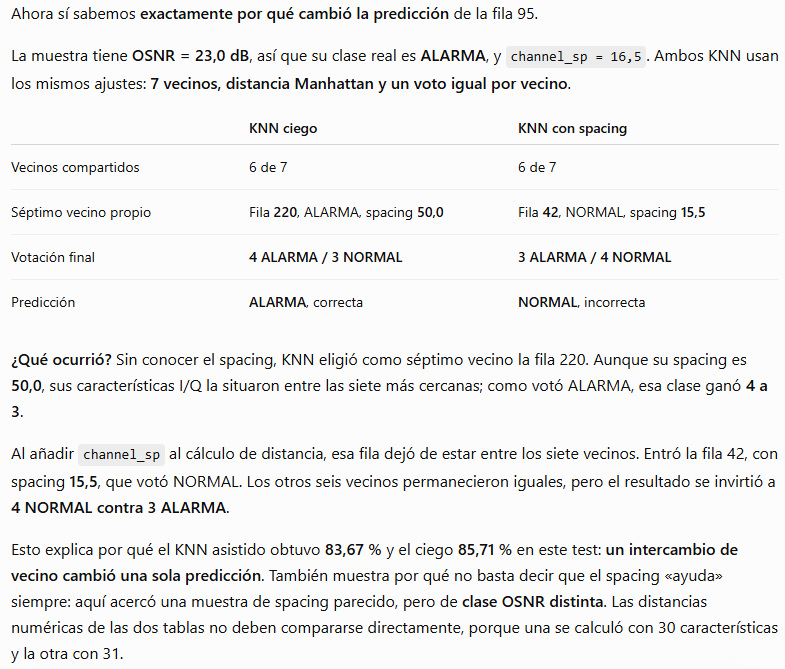

## KNN 32GBd para clasificar OSNR SIN CHANNEL SPACING

INFORMACIÓN DEL DATASET
Dataset: matriz32GBd_clasifi_correct.csv
Muestras: 9330
Características utilizadas: 30
NORMAL: 5804
ALARMA: 3526
Umbral OSNR: 23.0 dB

MONITOREO CIEGO: channel_sp NO se utiliza como entrada.

Características utilizadas:
 1. I_peak1_x
 2. I_peak2_x
 3. I_peak3_x
 4. I_peak4_x
 5. I_peak1_y
 6. I_peak2_y
 7. I_peak3_y
 8. I_peak4_y
 9. Q_peak1_x
10. Q_peak2_x
11. Q_peak3_x
12. Q_peak4_x
13. Q_peak1_y
14. Q_peak2_y
15. Q_peak3_y
16. Q_peak4_y
17. I_valley1_x
18. I_valley2_x
19. I_valley3_x
20. I_valley1_y
21. I_valley2_y
22. I_valley3_y
23. Q_valley1_x
24. Q_valley2_x
25. Q_valley3_x
26. Q_valley1_y
27. Q_valley2_y
28. Q_valley3_y
29. I_broadening
30. Q_broadening

Combinaciones de hiperparámetros: 20

INICIANDO NESTED CV 5x5 - KNN CIEGO 32 GBd

OUTER FOLD 1/5
Outer Train: 7464 muestras
Outer Test:  1866 muestras

Buscando mejores hiperparámetros...

Mejores hiperparámetros:
{'knn__n_neighbors': 11, 'knn__p': 1, 'knn__weights': 'uniform'}
Inner CV Best F1: 0.7068



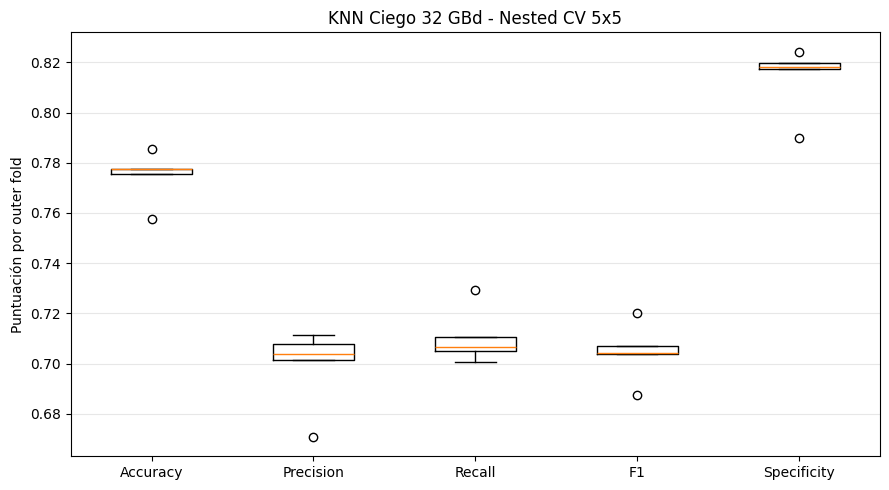


MÉTRICAS GLOBALES OUT-OF-FOLD (OOF)
OOF Accuracy:    0.7748
OOF Precision:   0.6987
OOF Recall:      0.7104
OOF F1:          0.7045
OOF Specificity: 0.8139

CLASSIFICATION REPORT OOF:
              precision    recall  f1-score   support

      NORMAL       0.82      0.81      0.82      5804
      ALARMA       0.70      0.71      0.70      3526

    accuracy                           0.77      9330
   macro avg       0.76      0.76      0.76      9330
weighted avg       0.78      0.77      0.78      9330


Matriz de confusión OOF:
[[4724 1080]
 [1021 2505]]


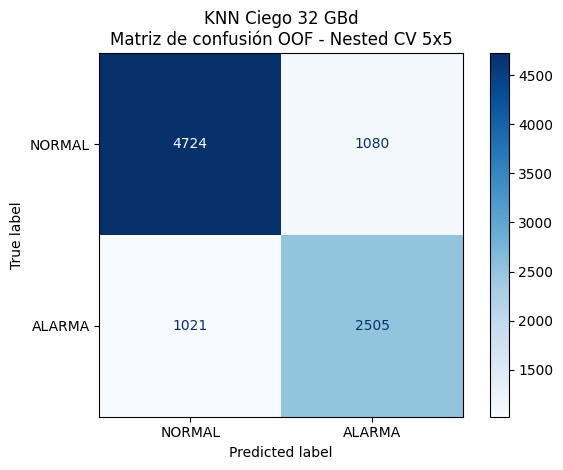


Predicciones OOF guardadas.

HIPERPARÁMETROS POR OUTER FOLD
 fold  knn__n_neighbors  knn__p knn__weights  inner_cv_best_f1
    1                11       1      uniform          0.706793
    2                15       1      uniform          0.702110
    3                15       1      uniform          0.702261
    4                15       1     distance          0.708801
    5                15       1     distance          0.708997

TIEMPO DE INFERENCIA - OUTER CV
Inference Mean: 9.920 µs/muestra
Inference Std:  0.779 µs/muestra
Mediciones totales: 500
Tiempo por muestra dentro de un batch. Incluye StandardScaler y KNN.predict().

ENTRENANDO MODELO FINAL - KNN CIEGO

Mejores parámetros modelo final:
{'knn__n_neighbors': 15, 'knn__p': 1, 'knn__weights': 'distance'}
F1 GridSearch final: 0.7037

CALCULANDO SHAP DEL MODELO FINAL
Background: 50 muestras
Muestras explicadas: 50


  0%|          | 0/50 [00:00<?, ?it/s]


30 CARACTERÍSTICAS ORDENADAS POR SHAP:
     feature mean_abs_shap importance_percent
   I_peak2_y      0.035396              7.62%
   Q_peak2_y      0.034264              7.37%
   I_peak3_y      0.030898              6.65%
   Q_peak3_y      0.028867              6.21%
   I_peak4_y      0.026991              5.81%
   Q_peak4_y      0.022195              4.78%
   I_peak1_y      0.021582              4.64%
 Q_valley3_y      0.020491              4.41%
   I_peak2_x      0.017917              3.85%
 I_valley3_y      0.017875              3.85%
 Q_valley1_y      0.017560              3.78%
   Q_peak4_x      0.017356              3.73%
 I_valley1_y      0.016595              3.57%
   I_peak4_x      0.014463              3.11%
   Q_peak1_y      0.014449              3.11%
 Q_valley2_y      0.014116              3.04%
 Q_valley2_x      0.013762              2.96%
   I_peak1_x      0.013347              2.87%
   Q_peak1_x      0.012354              2.66%
Q_broadening      0.011995              

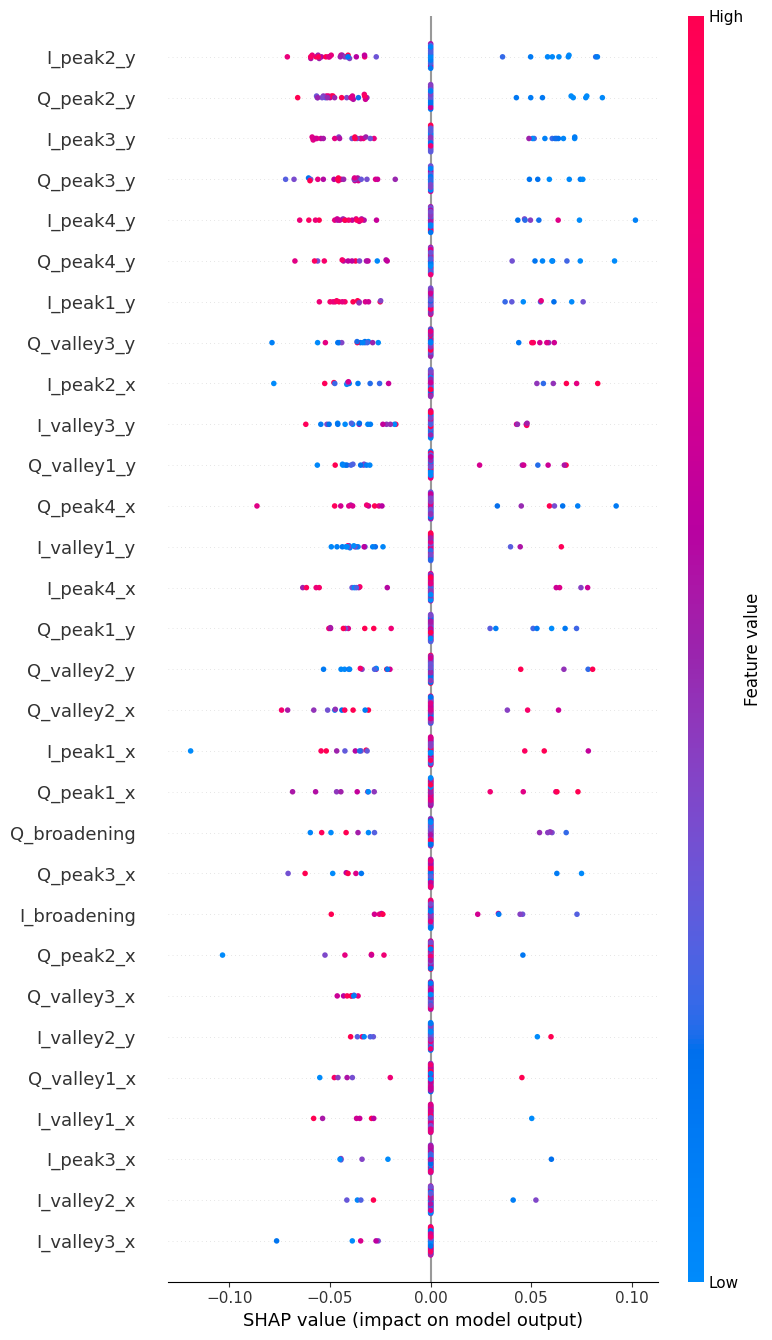

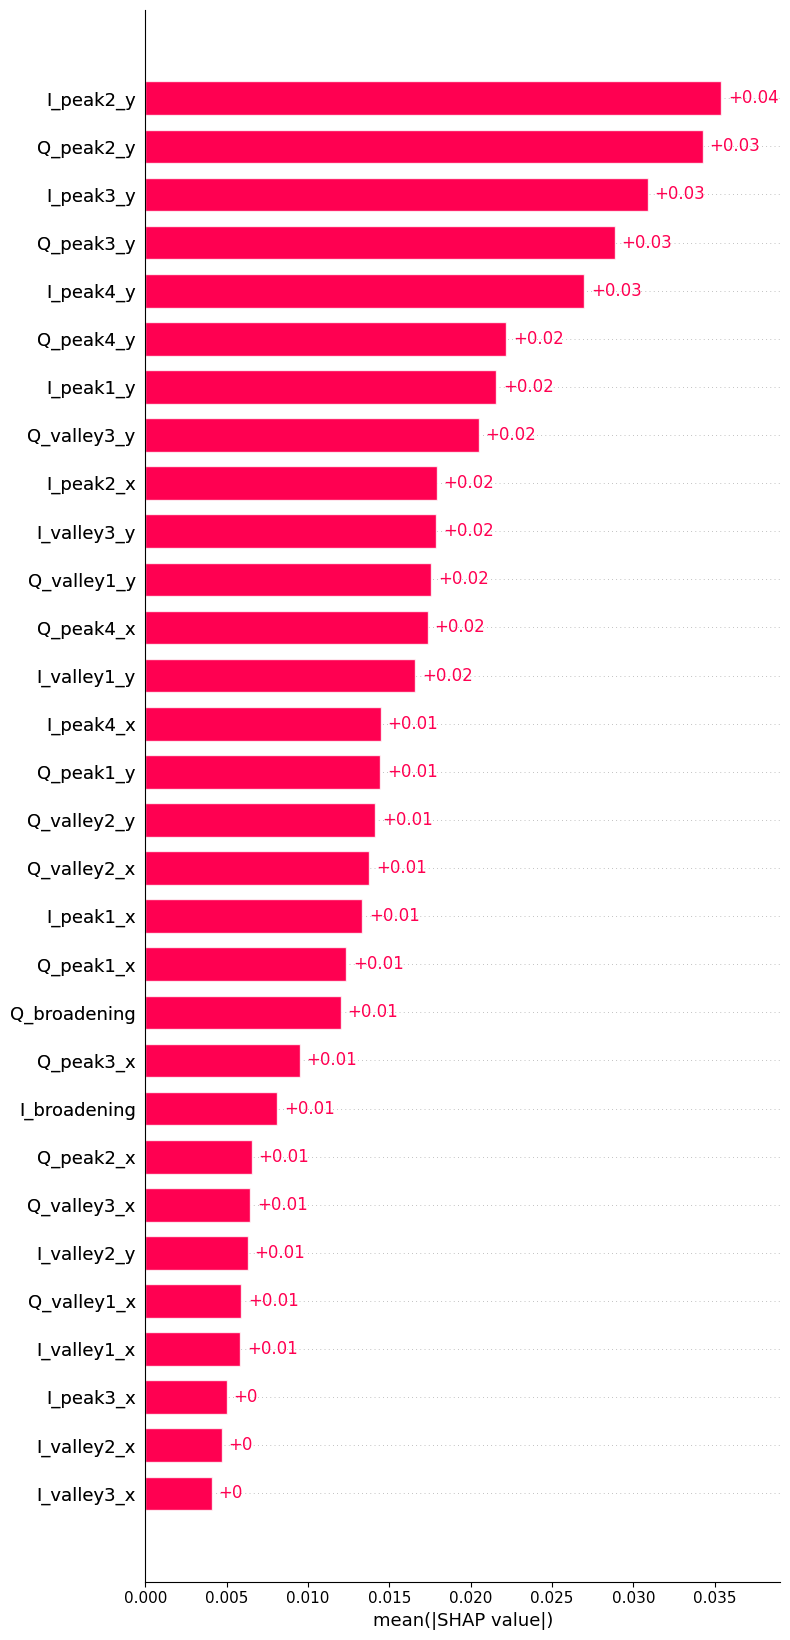

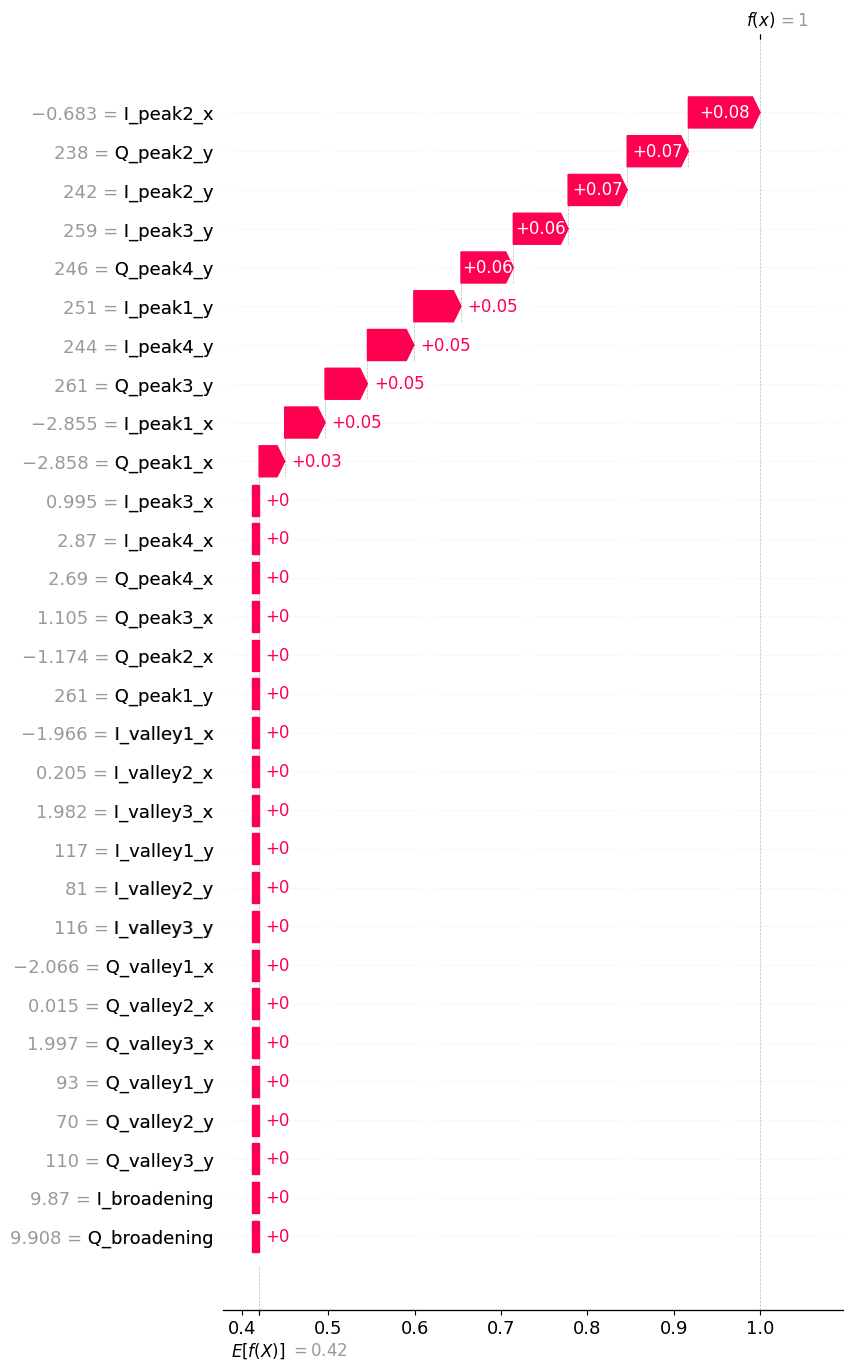


RESUMEN FINAL - KNN CIEGO 32 GBd NESTED CV 5x5
Outer CV ACCURACY    : 0.7748 ± 0.0092
Outer CV PRECISION   : 0.6990 ± 0.0145
Outer CV RECALL      : 0.7104 ± 0.0100
Outer CV F1          : 0.7046 ± 0.0105
Outer CV SPECIFICITY : 0.8139 ± 0.0123

OOF Accuracy: 0.7748
OOF Precision: 0.6987
OOF Recall: 0.7104
OOF F1: 0.7045
OOF Specificity: 0.8139

Inference Mean: 9.920 µs/muestra
Inference Std: 0.779 µs/muestra

Archivos generados:
1. knn_osnr_32GBd_ciego_nested_outer_folds.csv
2. knn_osnr_32GBd_ciego_nested_oof_predictions.csv
3. knn_osnr_32GBd_ciego_nested_best_params.csv
4. knn_osnr_32GBd_ciego_nested_importancia_shap.csv

PROCESO COMPLETADO.


In [ ]:

"""
============================================================
CLASIFICACIÓN CIEGA OSNR 32 GBd - KNN
NESTED CROSS-VALIDATION 5x5 + PREDICCIONES OUTER-FOLD
MÉTRICAS, MATRIZ DE CONFUSIÓN, SHAP Y TIEMPO DE INFERENCIA
============================================================

CLASES:
    0 = NORMAL: OSNR > 23 dB
    1 = ALARMA: OSNR <= 23 dB

DATASET:
    30 características I/Q
    1 columna channel_sp (EXCLUIDA DEL MODELO)
    1 columna OSNR (target continuo)

MONITOREO CIEGO:
    - No se utiliza channel_sp como entrada.
    - Se utilizan exclusivamente las 30 características I/Q.
    - OSNR se utiliza para construir las etiquetas.

METODOLOGÍA:
    - Outer CV: StratifiedKFold, 5 folds
    - Inner CV: StratifiedKFold, 5 folds
    - GridSearchCV dentro de cada outer train
    - Predicciones OOF en los outer tests
    - Métricas por fold y métricas globales OOF
    - Tiempos de inferencia por outer fold
    - Modelo final entrenado con todos los datos
    - SHAP para interpretar el modelo final

IMPORTANTE:
    Esta implementación divide por filas.
    Si existen muestras del mismo escenario experimental,
    conviene considerar Nested CV agrupada por escenario.
"""

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap

from sklearn.model_selection import (
    StratifiedKFold,
    GridSearchCV
)

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

# ============================================================
# 1. CONFIGURACIÓN GENERAL
# ============================================================

CSV_PATH = "matriz32GBd_clasifi_correct.csv"

THRESHOLD_DB = 23.0

SEED = 42

N_OUTER_FOLDS = 5
N_INNER_FOLDS = 5

N_REPETITIONS = 100

SHAP_BACKGROUND = 50
SHAP_EXPLAIN = 50
SHAP_NSAMPLES = 300

# ============================================================
# 2. NOMBRES DE LAS 30 CARACTERÍSTICAS
# ============================================================

# MONITOREO CIEGO:
# No se incluye "channel_sp" entre las características.

feature_names = (
    [f"I_peak{k}_x" for k in range(1, 5)] +
    [f"I_peak{k}_y" for k in range(1, 5)] +
    [f"Q_peak{k}_x" for k in range(1, 5)] +
    [f"Q_peak{k}_y" for k in range(1, 5)] +
    [f"I_valley{k}_x" for k in range(1, 4)] +
    [f"I_valley{k}_y" for k in range(1, 4)] +
    [f"Q_valley{k}_x" for k in range(1, 4)] +
    [f"Q_valley{k}_y" for k in range(1, 4)] +
    ["I_broadening", "Q_broadening"]
)

assert len(feature_names) == 30

# ============================================================
# 3. CARGAR Y VALIDAR DATASET
# ============================================================

matriz = pd.read_csv(
    CSV_PATH,
    header=None
)

# La matriz original tiene 32 columnas:
# 30 características I/Q + channel_sp + OSNR.

if matriz.shape[1] != 32:
    raise ValueError(
        f"Se esperaban 32 columnas; "
        f"se encontraron {matriz.shape[1]}"
    )

matriz = matriz.apply(
    pd.to_numeric,
    errors="raise"
)

if not np.isfinite(matriz.to_numpy()).all():
    raise ValueError(
        "El dataset contiene NaN o infinitos."
    )

# ------------------------------------------------------------
# 3.1 SELECCIÓN DE CARACTERÍSTICAS PARA MONITOREO CIEGO
# ------------------------------------------------------------

# Se utilizan únicamente las primeras 30 columnas.
# La columna 30 (channel_sp) queda excluida.
X = matriz.iloc[:, :30].copy()

X.columns = feature_names

# La última columna contiene el OSNR continuo.
y_osnr = matriz.iloc[:, 31].to_numpy()

# Clasificación binaria:
# NORMAL = 0, si OSNR > 23 dB
# ALARMA = 1, si OSNR <= 23 dB
y = (y_osnr <= THRESHOLD_DB).astype(int)

n_samples = len(y)

class_counts = np.bincount(
    y,
    minlength=2
)

if class_counts.min() < N_OUTER_FOLDS:
    raise ValueError(
        "No hay suficientes muestras por clase "
        "para los folds externos."
    )

print("=" * 65)
print("INFORMACIÓN DEL DATASET")
print("=" * 65)

print(f"Dataset: {CSV_PATH}")
print(f"Muestras: {n_samples}")
print(f"Características utilizadas: {X.shape[1]}")
print(f"NORMAL: {class_counts[0]}")
print(f"ALARMA: {class_counts[1]}")
print(f"Umbral OSNR: {THRESHOLD_DB} dB")

print(
    "\nMONITOREO CIEGO: "
    "channel_sp NO se utiliza como entrada."
)

print("\nCaracterísticas utilizadas:")

for i, feature in enumerate(feature_names, start=1):
    print(f"{i:2d}. {feature}")

# ============================================================
# 4. DEFINIR PIPELINE KNN Y GRID
# ============================================================

def build_pipeline():
    """
    Construye un pipeline nuevo.

    StandardScaler se ajusta exclusivamente
    con los datos de entrenamiento de cada fold.

    El escalado forma parte del pipeline para evitar
    fuga de información entre entrenamiento y test.
    """

    return Pipeline([
        (
            "scaler",
            StandardScaler()
        ),
        (
            "knn",
            KNeighborsClassifier()
        )
    ])


# Se conserva el grid del código original.

param_grid = {
    "knn__n_neighbors": [3, 5, 7, 11, 15],
    "knn__weights": [
        "uniform",
        "distance"
    ],
    "knn__p": [
        1,
        2
    ]
}

n_combinations = (
    len(param_grid["knn__n_neighbors"]) *
    len(param_grid["knn__weights"]) *
    len(param_grid["knn__p"])
)

print("\nCombinaciones de hiperparámetros:", n_combinations)

# ============================================================
# 5. CONFIGURAR OUTER CROSS-VALIDATION
# ============================================================

outer_cv = StratifiedKFold(
    n_splits=N_OUTER_FOLDS,
    shuffle=True,
    random_state=SEED
)

# Cada muestra recibirá una predicción
# cuando pertenezca al test de un outer fold.

oof_predictions = np.full(
    n_samples,
    -1,
    dtype=int
)

# Probabilidad de ALARMA para cada muestra OOF.
oof_probabilities = np.full(
    n_samples,
    np.nan,
    dtype=float
)

# Identificador del outer fold.
oof_fold = np.full(
    n_samples,
    -1,
    dtype=int
)

outer_results = []
outer_best_params = []
outer_inference_times = []

print("\n" + "=" * 65)
print("INICIANDO NESTED CV 5x5 - KNN CIEGO 32 GBd")
print("=" * 65)

# ============================================================
# 6. BUCLE PRINCIPAL: OUTER CROSS-VALIDATION
# ============================================================

for fold, (train_idx, test_idx) in enumerate(
    outer_cv.split(X, y),
    start=1
):

    print("\n" + "=" * 65)
    print(f"OUTER FOLD {fold}/{N_OUTER_FOLDS}")
    print("=" * 65)

    # --------------------------------------------------------
    # 6.1 SEPARACIÓN EXTERNA
    # --------------------------------------------------------

    X_outer_train = X.iloc[train_idx]
    X_outer_test = X.iloc[test_idx]

    y_outer_train = y[train_idx]
    y_outer_test = y[test_idx]

    print(
        f"Outer Train: {len(X_outer_train)} muestras"
    )

    print(
        f"Outer Test:  {len(X_outer_test)} muestras"
    )

    # --------------------------------------------------------
    # 6.2 INNER CV: GRIDSEARCHCV
    # --------------------------------------------------------

    # Cada outer fold tiene su propia validación interna.
    inner_cv = StratifiedKFold(
        n_splits=N_INNER_FOLDS,
        shuffle=True,
        random_state=SEED + fold
    )

    search = GridSearchCV(
        estimator=build_pipeline(),
        param_grid=param_grid,
        scoring="f1",
        cv=inner_cv,
        n_jobs=-1,
        refit=True,
        return_train_score=False
    )

    print("\nBuscando mejores hiperparámetros...")

    # El GridSearchCV recibe únicamente el outer train.
    # El outer test NO participa en la selección.
    search.fit(
        X_outer_train,
        y_outer_train
    )

    best_knn = search.best_estimator_

    print("\nMejores hiperparámetros:")
    print(search.best_params_)

    print(
        f"Inner CV Best F1: "
        f"{search.best_score_:.4f}"
    )

    outer_best_params.append({
        "fold": fold,
        **search.best_params_,
        "inner_cv_best_f1": search.best_score_
    })

    # --------------------------------------------------------
    # 6.3 PREDICCIONES OUTER-FOLD
    # --------------------------------------------------------

    # Predicción de clase.
    y_outer_pred = best_knn.predict(
        X_outer_test
    )

    # Probabilidad de pertenecer a ALARMA (clase 1).
    y_outer_proba = best_knn.predict_proba(
        X_outer_test
    )[:, 1]

    # Guardar las predicciones en el orden original.
    oof_predictions[test_idx] = y_outer_pred

    oof_probabilities[test_idx] = y_outer_proba

    oof_fold[test_idx] = fold

    # --------------------------------------------------------
    # 6.4 MÉTRICAS DEL OUTER FOLD
    # --------------------------------------------------------

    tn, fp, fn, tp = confusion_matrix(
        y_outer_test,
        y_outer_pred,
        labels=[0, 1]
    ).ravel()

    accuracy = accuracy_score(
        y_outer_test,
        y_outer_pred
    )

    precision = precision_score(
        y_outer_test,
        y_outer_pred,
        zero_division=0
    )

    recall = recall_score(
        y_outer_test,
        y_outer_pred,
        zero_division=0
    )

    f1 = f1_score(
        y_outer_test,
        y_outer_pred,
        zero_division=0
    )

    specificity = (
        tn / (tn + fp)
        if (tn + fp) > 0
        else np.nan
    )

    # --------------------------------------------------------
    # 6.5 TIEMPO DE INFERENCIA
    # --------------------------------------------------------

    # Warm-up antes de medir.
    _ = best_knn.predict(
        X_outer_test.iloc[
            :min(10, len(X_outer_test))
        ]
    )

    inference_times = np.empty(
        N_REPETITIONS
    )

    for rep in range(N_REPETITIONS):

        start = time.perf_counter()

        _ = best_knn.predict(
            X_outer_test
        )

        elapsed = (
            time.perf_counter() - start
        )

        inference_times[rep] = (
            elapsed / len(X_outer_test)
        )

    inference_mean_us = (
        inference_times.mean() * 1e6
    )

    inference_std_us = (
        inference_times.std() * 1e6
    )

    outer_inference_times.append(
        inference_times * 1e6
    )

    # --------------------------------------------------------
    # 6.6 GUARDAR RESULTADOS DEL FOLD
    # --------------------------------------------------------

    outer_results.append({
        "fold": fold,
        "n_train": len(train_idx),
        "n_test": len(test_idx),
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "specificity": specificity,
        "inference_mean_us": inference_mean_us,
        "inference_std_us": inference_std_us
    })

    print("\nMÉTRICAS OUTER FOLD:")

    print(f"Accuracy:    {accuracy:.4f}")
    print(f"Precision:   {precision:.4f}")
    print(f"Recall:      {recall:.4f}")
    print(f"F1:          {f1:.4f}")
    print(f"Specificity: {specificity:.4f}")

    print(
        f"Inference Mean: "
        f"{inference_mean_us:.3f} µs/muestra"
    )

    print(
        f"Inference Std:  "
        f"{inference_std_us:.3f} µs/muestra"
    )

# ============================================================
# 7. VALIDAR PREDICCIONES OOF
# ============================================================

if np.any(oof_predictions == -1):
    raise RuntimeError(
        "Existen muestras sin predicción OOF."
    )

if np.any(oof_fold == -1):
    raise RuntimeError(
        "Existen muestras sin outer fold asignado."
    )

if not np.isfinite(oof_probabilities).all():
    raise RuntimeError(
        "Existen probabilidades OOF inválidas."
    )

print("\nTodas las muestras tienen predicción OOF.")

# ============================================================
# 8. RESULTADOS POR OUTER FOLD
# ============================================================

results_df = pd.DataFrame(
    outer_results
)

print("\n" + "=" * 65)
print("RESULTADOS DE LOS 5 OUTER FOLDS")
print("=" * 65)

print(
    results_df.to_string(index=False)
)

results_df.to_csv(
    "knn_osnr_32GBd_ciego_nested_outer_folds.csv",
    index=False
)

# ============================================================
# 9. PROMEDIO ± DESVIACIÓN ESTÁNDAR OUTER CV
# ============================================================

print("\n" + "=" * 65)
print("OUTER CV - PROMEDIO ± DESVIACIÓN ESTÁNDAR")
print("=" * 65)

metrics = [
    "accuracy",
    "precision",
    "recall",
    "f1",
    "specificity"
]

for metric in metrics:

    values = results_df[
        metric
    ].to_numpy()

    print(
        f"{metric.upper():12s}: "
        f"{np.nanmean(values):.4f} ± "
        f"{np.nanstd(values):.4f}"
    )

# ============================================================
# 10. GRÁFICA DE MÉTRICAS OUTER CV
# ============================================================

plt.figure(figsize=(9, 5))

plt.boxplot(
    [
        results_df[m].values
        for m in metrics
    ],
    tick_labels=[
        "Accuracy",
        "Precision",
        "Recall",
        "F1",
        "Specificity"
    ]
)

plt.ylabel("Puntuación por outer fold")

plt.title(
    "KNN Ciego 32 GBd - Nested CV 5x5"
)

plt.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()
plt.show()
plt.close()

# ============================================================
# 11. MÉTRICAS GLOBALES OOF
# ============================================================

print("\n" + "=" * 65)
print("MÉTRICAS GLOBALES OUT-OF-FOLD (OOF)")
print("=" * 65)

tn, fp, fn, tp = confusion_matrix(
    y,
    oof_predictions,
    labels=[0, 1]
).ravel()

oof_accuracy = accuracy_score(
    y,
    oof_predictions
)

oof_precision = precision_score(
    y,
    oof_predictions,
    zero_division=0
)

oof_recall = recall_score(
    y,
    oof_predictions,
    zero_division=0
)

oof_f1 = f1_score(
    y,
    oof_predictions,
    zero_division=0
)

oof_specificity = (
    tn / (tn + fp)
    if (tn + fp) > 0
    else np.nan
)

print(
    f"OOF Accuracy:    {oof_accuracy:.4f}"
)

print(
    f"OOF Precision:   {oof_precision:.4f}"
)

print(
    f"OOF Recall:      {oof_recall:.4f}"
)

print(
    f"OOF F1:          {oof_f1:.4f}"
)

print(
    f"OOF Specificity: {oof_specificity:.4f}"
)

print("\nCLASSIFICATION REPORT OOF:")

print(
    classification_report(
        y,
        oof_predictions,
        labels=[0, 1],
        target_names=[
            "NORMAL",
            "ALARMA"
        ],
        zero_division=0
    )
)

# ============================================================
# 12. MATRIZ DE CONFUSIÓN OOF
# ============================================================

cm_oof = confusion_matrix(
    y,
    oof_predictions,
    labels=[0, 1]
)

print("\nMatriz de confusión OOF:")

print(cm_oof)

ConfusionMatrixDisplay(
    confusion_matrix=cm_oof,
    display_labels=[
        "NORMAL",
        "ALARMA"
    ]
).plot(
    cmap="Blues",
    values_format="d"
)

plt.title(
    "KNN Ciego 32 GBd\n"
    "Matriz de confusión OOF - Nested CV 5x5"
)

plt.tight_layout()
plt.show()
plt.close()

# ============================================================
# 13. GUARDAR PREDICCIONES OOF
# ============================================================

oof_df = pd.DataFrame({
    "sample_index": np.arange(n_samples),
    "outer_fold": oof_fold,
    "OSNR_dB": y_osnr,
    "true_class": y,
    "predicted_class": oof_predictions,
    "probability_alarm": oof_probabilities,
    "correct": (
        y == oof_predictions
    )
})

oof_df.to_csv(
    "knn_osnr_32GBd_ciego_nested_oof_predictions.csv",
    index=False
)

print("\nPredicciones OOF guardadas.")

# ============================================================
# 14. HIPERPARÁMETROS POR OUTER FOLD
# ============================================================

params_df = pd.DataFrame(
    outer_best_params
)

print("\n" + "=" * 65)
print("HIPERPARÁMETROS POR OUTER FOLD")
print("=" * 65)

print(
    params_df.to_string(index=False)
)

params_df.to_csv(
    "knn_osnr_32GBd_ciego_nested_best_params.csv",
    index=False
)

# ============================================================
# 15. TIEMPO DE INFERENCIA OUTER CV
# ============================================================

all_inference_times = np.concatenate(
    outer_inference_times
)

print("\n" + "=" * 65)
print("TIEMPO DE INFERENCIA - OUTER CV")
print("=" * 65)

print(
    f"Inference Mean: "
    f"{all_inference_times.mean():.3f} µs/muestra"
)

print(
    f"Inference Std:  "
    f"{all_inference_times.std():.3f} µs/muestra"
)

print(
    f"Mediciones totales: "
    f"{len(all_inference_times)}"
)

print(
    "Tiempo por muestra dentro de un batch. "
    "Incluye StandardScaler y KNN.predict()."
)

# ============================================================
# 16. ENTRENAR MODELO FINAL CON TODOS LOS DATOS
# ============================================================

# Este modelo se utiliza para SHAP.
# NO se utiliza para calcular las métricas OOF.
#
# Se seleccionan nuevamente los hiperparámetros
# mediante GridSearchCV sobre todo el dataset.

print("\n" + "=" * 65)
print("ENTRENANDO MODELO FINAL - KNN CIEGO")
print("=" * 65)

final_inner_cv = StratifiedKFold(
    n_splits=N_INNER_FOLDS,
    shuffle=True,
    random_state=SEED
)

final_search = GridSearchCV(
    estimator=build_pipeline(),
    param_grid=param_grid,
    scoring="f1",
    cv=final_inner_cv,
    n_jobs=-1,
    refit=True
)

final_search.fit(X, y)

final_knn = final_search.best_estimator_

print("\nMejores parámetros modelo final:")
print(final_search.best_params_)

print(
    f"F1 GridSearch final: "
    f"{final_search.best_score_:.4f}"
)

# ============================================================
# 17. SHAP - KERNELEXPLAINER
# ============================================================

# SHAP explica predict_proba[:, 1] del KNN final.
#
# SHAP positivo:
#    aumenta la probabilidad de ALARMA.
#
# SHAP negativo:
#    disminuye la probabilidad de ALARMA.
#
# Las muestras explicadas pertenecen al dataset
# utilizado para entrenar el modelo final.
#
# Por tanto, este SHAP es descriptivo, NO OOF.
#
# MONITOREO CIEGO:
# SHAP considera únicamente las 30 características I/Q.
# channel_sp no participa en el cálculo.

print("\n" + "=" * 65)
print("CALCULANDO SHAP DEL MODELO FINAL")
print("=" * 65)

background = X.sample(
    n=min(SHAP_BACKGROUND, len(X)),
    random_state=SEED
)

explained = X.sample(
    n=min(SHAP_EXPLAIN, len(X)),
    random_state=SEED + 1
)

print(
    f"Background: {len(background)} muestras"
)

print(
    f"Muestras explicadas: {len(explained)}"
)

def knn_alarm_probability(data):
    """
    Adaptador para SHAP.

    Conserva nombres y orden de las 30 columnas.
    Devuelve P(ALARMA), correspondiente a la clase 1.
    """

    frame = pd.DataFrame(
        np.asarray(data),
        columns=feature_names
    )

    return final_knn.predict_proba(frame)[:, 1]


explainer = shap.KernelExplainer(
    knn_alarm_probability,
    background
)

raw = explainer.shap_values(
    explained,
    nsamples=SHAP_NSAMPLES
)

shap_values = np.asarray(raw)

if shap_values.shape != explained.shape:
    raise ValueError(
        f"Forma SHAP inesperada: "
        f"{shap_values.shape}. "
        f"Se esperaba {explained.shape}."
    )

# ============================================================
# 18. IMPORTANCIA GLOBAL SHAP
# ============================================================

mean_abs = np.mean(
    np.abs(shap_values),
    axis=0
)

imp_df = pd.DataFrame({
    "feature": feature_names,
    "mean_abs_shap": mean_abs
})

imp_df = imp_df.sort_values(
    "mean_abs_shap",
    ascending=False
).reset_index(drop=True)

total = imp_df[
    "mean_abs_shap"
].sum()

if total > 0:

    imp_df["importance_percent"] = (
        100 *
        imp_df["mean_abs_shap"] /
        total
    )

else:

    imp_df["importance_percent"] = 0.0

print("\n30 CARACTERÍSTICAS ORDENADAS POR SHAP:")

print(
    imp_df.to_string(
        index=False,
        formatters={
            "mean_abs_shap": "{:.6f}".format,
            "importance_percent": "{:.2f}%".format
        }
    )
)

print(
    f"\nSuma de porcentajes: "
    f"{imp_df['importance_percent'].sum():.2f}%"
)

print("\nTOP 5 SHAP:")

print(
    imp_df.head(5).to_string(
        index=False
    )
)

imp_df.to_csv(
    "knn_osnr_32GBd_ciego_nested_importancia_shap.csv",
    index=False
)

# ============================================================
# 19. CREAR OBJETO SHAP EXPLANATION
# ============================================================

expected_value = float(
    np.asarray(
        explainer.expected_value
    ).item()
)

explanation = shap.Explanation(
    values=shap_values,
    base_values=np.full(
        len(explained),
        expected_value
    ),
    data=explained.to_numpy(),
    feature_names=feature_names
)

# ============================================================
# 20. GRÁFICAS SHAP
# ============================================================

# Beeswarm
shap.plots.beeswarm(
    explanation,
    max_display=30,
    show=False
)

plt.tight_layout()
plt.show()
plt.close()

# Bar plot
shap.plots.bar(
    explanation,
    max_display=30,
    show=False
)

plt.tight_layout()
plt.show()
plt.close()

# Waterfall de la primera muestra explicada.
shap.plots.waterfall(
    explanation[0],
    max_display=30,
    show=False
)

plt.show()
plt.close()

# ============================================================
# 21. RESUMEN FINAL
# ============================================================

print("\n" + "=" * 65)
print("RESUMEN FINAL - KNN CIEGO 32 GBd NESTED CV 5x5")
print("=" * 65)

for metric in metrics:

    values = results_df[
        metric
    ].to_numpy()

    print(
        f"Outer CV {metric.upper():12s}: "
        f"{np.nanmean(values):.4f} ± "
        f"{np.nanstd(values):.4f}"
    )

print(
    f"\nOOF Accuracy: "
    f"{oof_accuracy:.4f}"
)

print(
    f"OOF Precision: "
    f"{oof_precision:.4f}"
)

print(
    f"OOF Recall: "
    f"{oof_recall:.4f}"
)

print(
    f"OOF F1: "
    f"{oof_f1:.4f}"
)

print(
    f"OOF Specificity: "
    f"{oof_specificity:.4f}"
)

print(
    f"\nInference Mean: "
    f"{all_inference_times.mean():.3f} µs/muestra"
)

print(
    f"Inference Std: "
    f"{all_inference_times.std():.3f} µs/muestra"
)

print("\nArchivos generados:")

print("1. knn_osnr_32GBd_ciego_nested_outer_folds.csv")
print("2. knn_osnr_32GBd_ciego_nested_oof_predictions.csv")
print("3. knn_osnr_32GBd_ciego_nested_best_params.csv")
print("4. knn_osnr_32GBd_ciego_nested_importancia_shap.csv")

print("\nPROCESO COMPLETADO.")


## SVM 32GBd para clasificar OSNR SIN CHANNEL SPACING

INFORMACIÓN DEL DATASET
Dataset: matriz32GBd_clasifi_correct.csv
Muestras: 9330
Características utilizadas: 30
NORMAL: 5804
ALARMA: 3526
Umbral OSNR: 23.0 dB

MONITOREO CIEGO: channel_sp NO se utiliza como entrada.

Características utilizadas:
 1. I_peak1_x
 2. I_peak2_x
 3. I_peak3_x
 4. I_peak4_x
 5. I_peak1_y
 6. I_peak2_y
 7. I_peak3_y
 8. I_peak4_y
 9. Q_peak1_x
10. Q_peak2_x
11. Q_peak3_x
12. Q_peak4_x
13. Q_peak1_y
14. Q_peak2_y
15. Q_peak3_y
16. Q_peak4_y
17. I_valley1_x
18. I_valley2_x
19. I_valley3_x
20. I_valley1_y
21. I_valley2_y
22. I_valley3_y
23. Q_valley1_x
24. Q_valley2_x
25. Q_valley3_x
26. Q_valley1_y
27. Q_valley2_y
28. Q_valley3_y
29. I_broadening
30. Q_broadening

Combinaciones de hiperparámetros: 32

INICIANDO NESTED CV 5x5 - SVM CIEGO 32 GBd

OUTER FOLD 1/5
Outer Train: 7464 muestras
Outer Test:  1866 muestras

Buscando mejores hiperparámetros...

Mejores hiperparámetros:
{'svm__C': 10, 'svm__class_weight': 'balanced', 'svm__gamma': 0.01}
Inner CV Best F1: 0.740

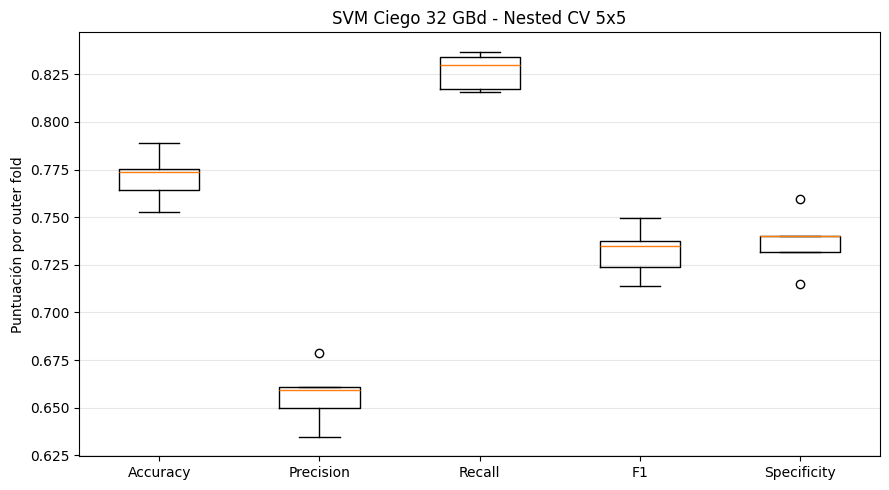


MÉTRICAS GLOBALES OUT-OF-FOLD (OOF)
OOF Accuracy:    0.7711
OOF Precision:   0.6565
OOF Recall:      0.8267
OOF F1:          0.7319
OOF Specificity: 0.7373

CLASSIFICATION REPORT OOF:
              precision    recall  f1-score   support

      NORMAL       0.88      0.74      0.80      5804
      ALARMA       0.66      0.83      0.73      3526

    accuracy                           0.77      9330
   macro avg       0.77      0.78      0.77      9330
weighted avg       0.79      0.77      0.77      9330


Matriz de confusión OOF:
[[4279 1525]
 [ 611 2915]]


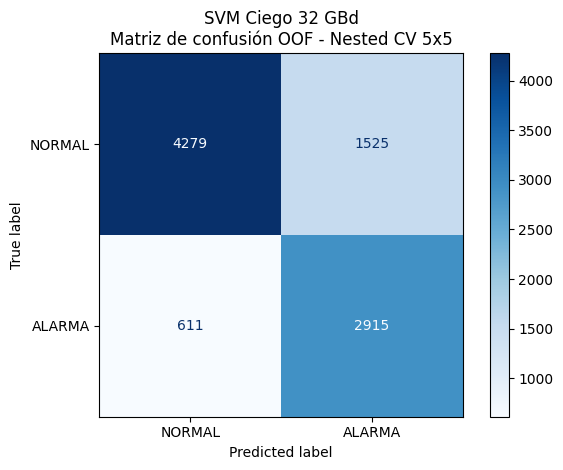


Predicciones OOF guardadas.

HIPERPARÁMETROS POR OUTER FOLD
 fold  svm__C svm__class_weight svm__gamma  inner_cv_best_f1
    1      10          balanced       0.01          0.740311
    2      10          balanced       0.01          0.737940
    3       1          balanced      scale          0.736877
    4     100          balanced      0.001          0.736516
    5      10          balanced       0.01          0.738674

TIEMPO DE INFERENCIA - OUTER CV
Inference Mean: 158.078 µs/muestra
Inference Std:  3.232 µs/muestra
Mediciones totales: 500
Tiempo por muestra dentro de un batch. Incluye StandardScaler y SVM.predict().

ENTRENANDO MODELO FINAL - SVM CIEGO

Mejores parámetros modelo final:
{'svm__C': 100, 'svm__class_weight': 'balanced', 'svm__gamma': 0.001}
F1 GridSearch final: 0.7361

CALCULANDO SHAP DEL MODELO FINAL
Background: 50 muestras
Muestras explicadas: 50


  0%|          | 0/50 [00:00<?, ?it/s]


30 CARACTERÍSTICAS ORDENADAS POR SHAP:
     feature mean_abs_shap importance_percent
   I_peak2_y      0.405145             17.75%
   I_peak3_y      0.360351             15.79%
   Q_peak3_y      0.333986             14.63%
   Q_peak4_y      0.194504              8.52%
   Q_peak2_y      0.183552              8.04%
 I_valley2_y      0.135483              5.94%
Q_broadening      0.101085              4.43%
   I_peak1_y      0.094526              4.14%
   I_peak4_y      0.083456              3.66%
   Q_peak4_x      0.048907              2.14%
 Q_valley2_y      0.047239              2.07%
   Q_peak1_y      0.041466              1.82%
 I_valley1_y      0.039812              1.74%
 Q_valley1_y      0.037689              1.65%
   I_peak4_x      0.031022              1.36%
I_broadening      0.023907              1.05%
   Q_peak2_x      0.021784              0.95%
 Q_valley1_x      0.019261              0.84%
   Q_peak1_x      0.015311              0.67%
 I_valley1_x      0.011931              

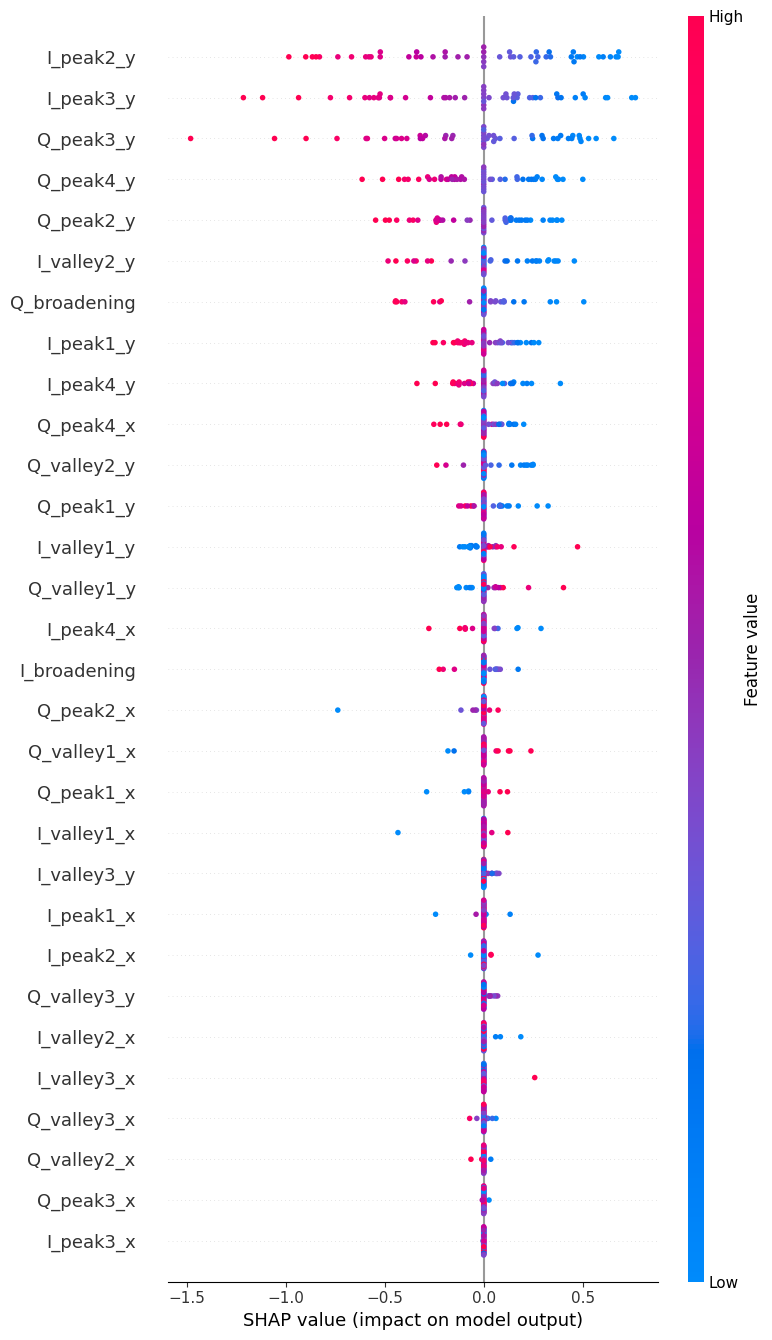

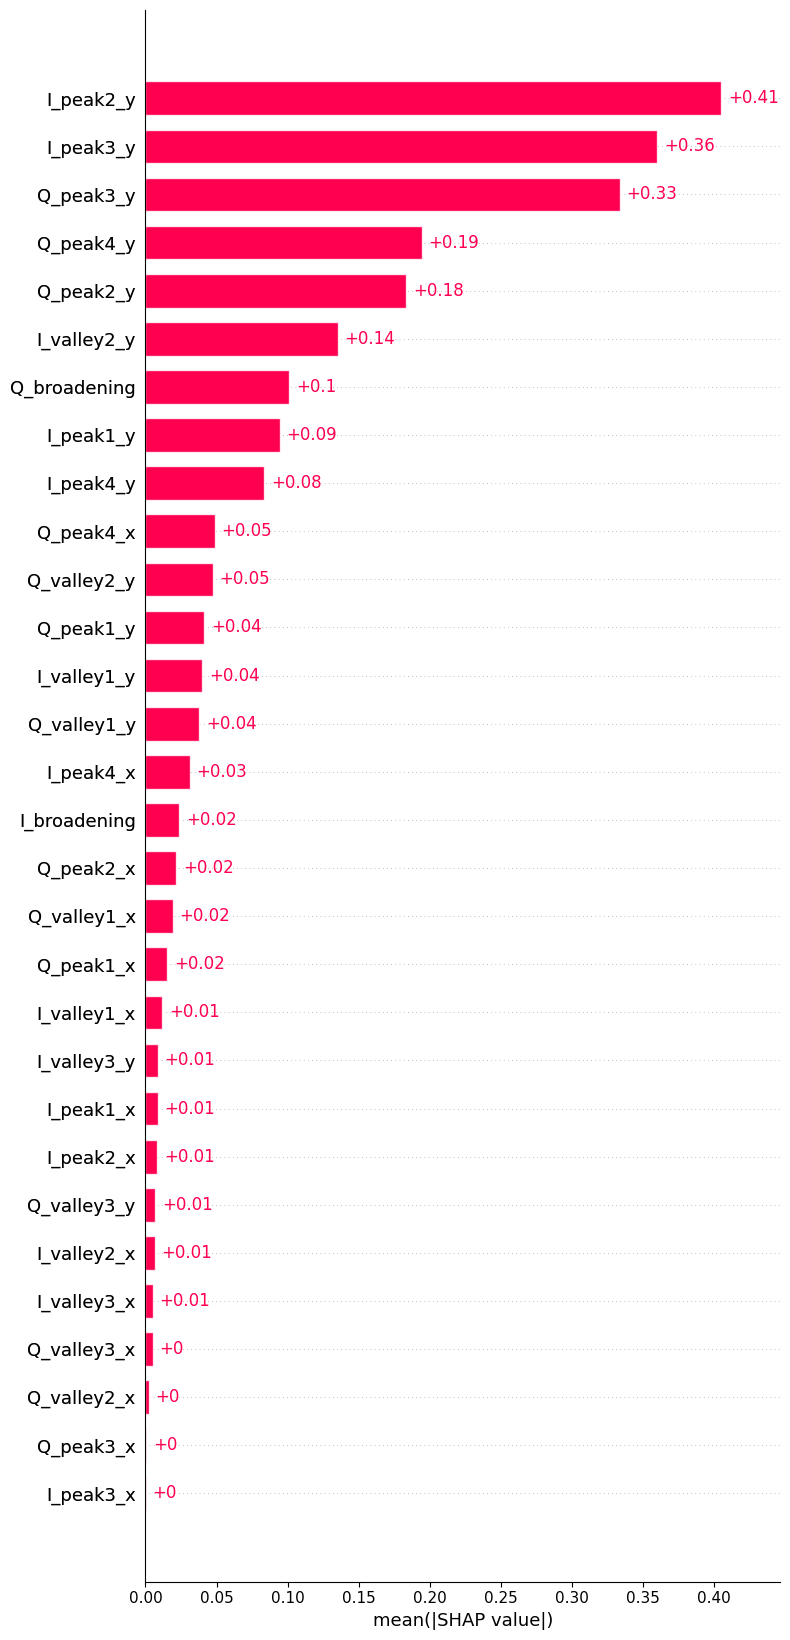

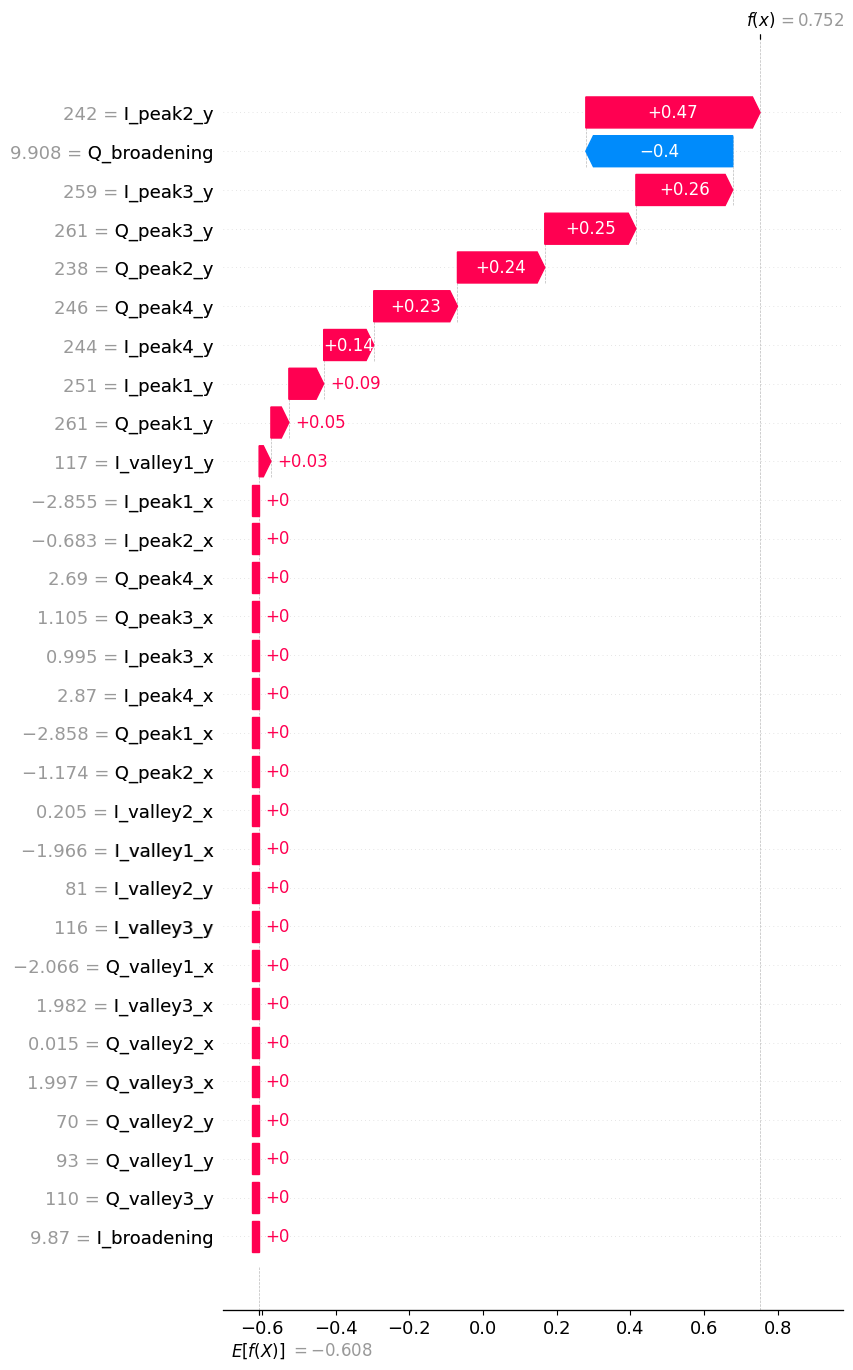


RESUMEN FINAL - SVM CIEGO 32 GBd NESTED CV 5x5
Outer CV ACCURACY    : 0.7711 ± 0.0120
Outer CV PRECISION   : 0.6567 ± 0.0145
Outer CV RECALL      : 0.8267 ± 0.0087
Outer CV F1          : 0.7319 ± 0.0122
Outer CV SPECIFICITY : 0.7372 ± 0.0145

OOF Accuracy: 0.7711
OOF Precision: 0.6565
OOF Recall: 0.8267
OOF F1: 0.7319
OOF Specificity: 0.7373

Inference Mean: 158.078 µs/muestra
Inference Std: 3.232 µs/muestra

Archivos generados:
1. svm_osnr_32GBd_ciego_nested_outer_folds.csv
2. svm_osnr_32GBd_ciego_nested_oof_predictions.csv
3. svm_osnr_32GBd_ciego_nested_best_params.csv
4. svm_osnr_32GBd_ciego_nested_importancia_shap.csv

PROCESO COMPLETADO.


In [ ]:

"""
============================================================
CLASIFICACIÓN CIEGA OSNR 32 GBd - SVM-RBF
NESTED CROSS-VALIDATION 5x5 + PREDICCIONES OUTER-FOLD
MÉTRICAS, MATRIZ DE CONFUSIÓN, SHAP Y TIEMPO DE INFERENCIA
============================================================

CLASES:
    0 = NORMAL: OSNR > 23 dB
    1 = ALARMA: OSNR <= 23 dB

DATASET:
    30 características I/Q
    1 columna channel_sp (EXCLUIDA DEL MODELO)
    1 columna OSNR (target continuo)

MONITOREO CIEGO:
    - No se utiliza channel_sp como entrada.
    - Se utilizan exclusivamente las 30 características I/Q.
    - OSNR se utiliza para construir las etiquetas.

METODOLOGÍA:
    - Outer CV: StratifiedKFold, 5 folds
    - Inner CV: StratifiedKFold, 5 folds
    - GridSearchCV dentro de cada outer train
    - Predicciones OOF en los outer tests
    - Métricas por fold y métricas globales OOF
    - Tiempos de inferencia por outer fold
    - Modelo final entrenado con todos los datos
    - SHAP para interpretar el modelo final

IMPORTANTE:
    Esta implementación divide por filas.
    Si existen muestras del mismo escenario experimental,
    conviene considerar Nested CV agrupada por escenario.
"""

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap

from sklearn.model_selection import (
    StratifiedKFold,
    GridSearchCV
)

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

# ============================================================
# 1. CONFIGURACIÓN GENERAL
# ============================================================

CSV_PATH = "matriz32GBd_clasifi_correct.csv"

THRESHOLD_DB = 23.0

SEED = 42

N_OUTER_FOLDS = 5
N_INNER_FOLDS = 5

N_REPETITIONS = 100

SHAP_BACKGROUND = 50
SHAP_EXPLAIN = 50
SHAP_NSAMPLES = 300

# ============================================================
# 2. NOMBRES DE LAS 30 CARACTERÍSTICAS
# ============================================================

# MONITOREO CIEGO:
# No se incluye "channel_sp" entre las características.

feature_names = (
    [f"I_peak{k}_x" for k in range(1, 5)] +
    [f"I_peak{k}_y" for k in range(1, 5)] +
    [f"Q_peak{k}_x" for k in range(1, 5)] +
    [f"Q_peak{k}_y" for k in range(1, 5)] +
    [f"I_valley{k}_x" for k in range(1, 4)] +
    [f"I_valley{k}_y" for k in range(1, 4)] +
    [f"Q_valley{k}_x" for k in range(1, 4)] +
    [f"Q_valley{k}_y" for k in range(1, 4)] +
    ["I_broadening", "Q_broadening"]
)

assert len(feature_names) == 30

# ============================================================
# 3. CARGAR Y VALIDAR DATASET
# ============================================================

matriz = pd.read_csv(
    CSV_PATH,
    header=None
)

# La matriz original tiene 32 columnas:
# 30 características I/Q + channel_sp + OSNR.

if matriz.shape[1] != 32:
    raise ValueError(
        f"Se esperaban 32 columnas; "
        f"se encontraron {matriz.shape[1]}"
    )

matriz = matriz.apply(
    pd.to_numeric,
    errors="raise"
)

if not np.isfinite(matriz.to_numpy()).all():
    raise ValueError(
        "El dataset contiene NaN o infinitos."
    )

# ------------------------------------------------------------
# 3.1 SELECCIÓN DE CARACTERÍSTICAS PARA MONITOREO CIEGO
# ------------------------------------------------------------

# Se utilizan únicamente las primeras 30 columnas.
# La columna 30 (channel_sp) queda excluida.
X = matriz.iloc[:, :30].copy()

X.columns = feature_names

# La última columna contiene el OSNR continuo.
y_osnr = matriz.iloc[:, 31].to_numpy()

# Clasificación binaria:
# NORMAL = 0, si OSNR > 23 dB
# ALARMA = 1, si OSNR <= 23 dB
y = (y_osnr <= THRESHOLD_DB).astype(int)

n_samples = len(y)

class_counts = np.bincount(
    y,
    minlength=2
)

if class_counts.min() < N_OUTER_FOLDS:
    raise ValueError(
        "No hay suficientes muestras por clase "
        "para los folds externos."
    )

print("=" * 65)
print("INFORMACIÓN DEL DATASET")
print("=" * 65)

print(f"Dataset: {CSV_PATH}")
print(f"Muestras: {n_samples}")
print(f"Características utilizadas: {X.shape[1]}")
print(f"NORMAL: {class_counts[0]}")
print(f"ALARMA: {class_counts[1]}")
print(f"Umbral OSNR: {THRESHOLD_DB} dB")

print(
    "\nMONITOREO CIEGO: "
    "channel_sp NO se utiliza como entrada."
)

print("\nCaracterísticas utilizadas:")

for i, feature in enumerate(feature_names, start=1):
    print(f"{i:2d}. {feature}")

# ============================================================
# 4. DEFINIR PIPELINE SVM Y GRID
# ============================================================

def build_pipeline():
    """
    Construye un pipeline nuevo.

    StandardScaler se ajusta exclusivamente
    con los datos de entrenamiento de cada fold.

    El escalado forma parte del pipeline para evitar
    fuga de información entre entrenamiento y test.
    """

    return Pipeline([
        (
            "scaler",
            StandardScaler()
        ),
        (
            "svm",
            SVC(
                kernel="rbf",
                random_state=SEED
            )
        )
    ])


# Se conserva el grid del código original.

param_grid = {
    "svm__C": [0.1, 1, 10, 100],
    "svm__gamma": [
        "scale",
        0.001,
        0.01,
        0.1
    ],
    "svm__class_weight": [
        None,
        "balanced"
    ]
}

n_combinations = (
    len(param_grid["svm__C"]) *
    len(param_grid["svm__gamma"]) *
    len(param_grid["svm__class_weight"])
)

print("\nCombinaciones de hiperparámetros:", n_combinations)

# ============================================================
# 5. CONFIGURAR OUTER CROSS-VALIDATION
# ============================================================

outer_cv = StratifiedKFold(
    n_splits=N_OUTER_FOLDS,
    shuffle=True,
    random_state=SEED
)

# Cada muestra recibirá una predicción
# cuando pertenezca al test de un outer fold.

oof_predictions = np.full(
    n_samples,
    -1,
    dtype=int
)

# Puntuación de decision_function para cada muestra OOF.
oof_decisions = np.full(
    n_samples,
    np.nan,
    dtype=float
)

# Identificador del outer fold.
oof_fold = np.full(
    n_samples,
    -1,
    dtype=int
)

outer_results = []
outer_best_params = []
outer_inference_times = []

print("\n" + "=" * 65)
print("INICIANDO NESTED CV 5x5 - SVM CIEGO 32 GBd")
print("=" * 65)

# ============================================================
# 6. BUCLE PRINCIPAL: OUTER CROSS-VALIDATION
# ============================================================

for fold, (train_idx, test_idx) in enumerate(
    outer_cv.split(X, y),
    start=1
):

    print("\n" + "=" * 65)
    print(f"OUTER FOLD {fold}/{N_OUTER_FOLDS}")
    print("=" * 65)

    # --------------------------------------------------------
    # 6.1 SEPARACIÓN EXTERNA
    # --------------------------------------------------------

    X_outer_train = X.iloc[train_idx]
    X_outer_test = X.iloc[test_idx]

    y_outer_train = y[train_idx]
    y_outer_test = y[test_idx]

    print(
        f"Outer Train: {len(X_outer_train)} muestras"
    )

    print(
        f"Outer Test:  {len(X_outer_test)} muestras"
    )

    # --------------------------------------------------------
    # 6.2 INNER CV: GRIDSEARCHCV
    # --------------------------------------------------------

    # Cada outer fold tiene su propia validación interna.
    inner_cv = StratifiedKFold(
        n_splits=N_INNER_FOLDS,
        shuffle=True,
        random_state=SEED + fold
    )

    search = GridSearchCV(
        estimator=build_pipeline(),
        param_grid=param_grid,
        scoring="f1",
        cv=inner_cv,
        n_jobs=-1,
        refit=True,
        return_train_score=False
    )

    print("\nBuscando mejores hiperparámetros...")

    # El GridSearchCV recibe únicamente el outer train.
    # El outer test NO participa en la selección.
    search.fit(
        X_outer_train,
        y_outer_train
    )

    best_svm = search.best_estimator_

    print("\nMejores hiperparámetros:")
    print(search.best_params_)

    print(
        f"Inner CV Best F1: "
        f"{search.best_score_:.4f}"
    )

    outer_best_params.append({
        "fold": fold,
        **search.best_params_,
        "inner_cv_best_f1": search.best_score_
    })

    # --------------------------------------------------------
    # 6.3 PREDICCIONES OUTER-FOLD
    # --------------------------------------------------------

    # Predicción de clase.
    y_outer_pred = best_svm.predict(
        X_outer_test
    )

    # Puntuación de decisión del SVM.
    decision_values = best_svm.decision_function(
        X_outer_test
    )

    # Guardar las predicciones en el orden original.
    oof_predictions[test_idx] = y_outer_pred

    oof_decisions[test_idx] = decision_values

    oof_fold[test_idx] = fold

    # --------------------------------------------------------
    # 6.4 MÉTRICAS DEL OUTER FOLD
    # --------------------------------------------------------

    tn, fp, fn, tp = confusion_matrix(
        y_outer_test,
        y_outer_pred,
        labels=[0, 1]
    ).ravel()

    accuracy = accuracy_score(
        y_outer_test,
        y_outer_pred
    )

    precision = precision_score(
        y_outer_test,
        y_outer_pred,
        zero_division=0
    )

    recall = recall_score(
        y_outer_test,
        y_outer_pred,
        zero_division=0
    )

    f1 = f1_score(
        y_outer_test,
        y_outer_pred,
        zero_division=0
    )

    specificity = (
        tn / (tn + fp)
        if (tn + fp) > 0
        else np.nan
    )

    # --------------------------------------------------------
    # 6.5 TIEMPO DE INFERENCIA
    # --------------------------------------------------------

    # Warm-up antes de medir.
    _ = best_svm.predict(
        X_outer_test.iloc[
            :min(10, len(X_outer_test))
        ]
    )

    inference_times = np.empty(
        N_REPETITIONS
    )

    for rep in range(N_REPETITIONS):

        start = time.perf_counter()

        _ = best_svm.predict(
            X_outer_test
        )

        elapsed = (
            time.perf_counter() - start
        )

        inference_times[rep] = (
            elapsed / len(X_outer_test)
        )

    inference_mean_us = (
        inference_times.mean() * 1e6
    )

    inference_std_us = (
        inference_times.std() * 1e6
    )

    outer_inference_times.append(
        inference_times * 1e6
    )

    # --------------------------------------------------------
    # 6.6 GUARDAR RESULTADOS DEL FOLD
    # --------------------------------------------------------

    outer_results.append({
        "fold": fold,
        "n_train": len(train_idx),
        "n_test": len(test_idx),
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "specificity": specificity,
        "inference_mean_us": inference_mean_us,
        "inference_std_us": inference_std_us
    })

    print("\nMÉTRICAS OUTER FOLD:")

    print(f"Accuracy:    {accuracy:.4f}")
    print(f"Precision:   {precision:.4f}")
    print(f"Recall:      {recall:.4f}")
    print(f"F1:          {f1:.4f}")
    print(f"Specificity: {specificity:.4f}")

    print(
        f"Inference Mean: "
        f"{inference_mean_us:.3f} µs/muestra"
    )

    print(
        f"Inference Std:  "
        f"{inference_std_us:.3f} µs/muestra"
    )

# ============================================================
# 7. VALIDAR PREDICCIONES OOF
# ============================================================

if np.any(oof_predictions == -1):
    raise RuntimeError(
        "Existen muestras sin predicción OOF."
    )

if np.any(oof_fold == -1):
    raise RuntimeError(
        "Existen muestras sin outer fold asignado."
    )

if not np.isfinite(oof_decisions).all():
    raise RuntimeError(
        "Existen puntuaciones OOF inválidas."
    )

print("\nTodas las muestras tienen predicción OOF.")

# ============================================================
# 8. RESULTADOS POR OUTER FOLD
# ============================================================

results_df = pd.DataFrame(
    outer_results
)

print("\n" + "=" * 65)
print("RESULTADOS DE LOS 5 OUTER FOLDS")
print("=" * 65)

print(
    results_df.to_string(index=False)
)

results_df.to_csv(
    "svm_osnr_32GBd_ciego_nested_outer_folds.csv",
    index=False
)

# ============================================================
# 9. PROMEDIO ± DESVIACIÓN ESTÁNDAR OUTER CV
# ============================================================

print("\n" + "=" * 65)
print("OUTER CV - PROMEDIO ± DESVIACIÓN ESTÁNDAR")
print("=" * 65)

metrics = [
    "accuracy",
    "precision",
    "recall",
    "f1",
    "specificity"
]

for metric in metrics:

    values = results_df[
        metric
    ].to_numpy()

    print(
        f"{metric.upper():12s}: "
        f"{np.nanmean(values):.4f} ± "
        f"{np.nanstd(values):.4f}"
    )

# ============================================================
# 10. GRÁFICA DE MÉTRICAS OUTER CV
# ============================================================

plt.figure(figsize=(9, 5))

plt.boxplot(
    [
        results_df[m].values
        for m in metrics
    ],
    tick_labels=[
        "Accuracy",
        "Precision",
        "Recall",
        "F1",
        "Specificity"
    ]
)

plt.ylabel("Puntuación por outer fold")

plt.title(
    "SVM Ciego 32 GBd - Nested CV 5x5"
)

plt.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()
plt.show()
plt.close()

# ============================================================
# 11. MÉTRICAS GLOBALES OOF
# ============================================================

print("\n" + "=" * 65)
print("MÉTRICAS GLOBALES OUT-OF-FOLD (OOF)")
print("=" * 65)

tn, fp, fn, tp = confusion_matrix(
    y,
    oof_predictions,
    labels=[0, 1]
).ravel()

oof_accuracy = accuracy_score(
    y,
    oof_predictions
)

oof_precision = precision_score(
    y,
    oof_predictions,
    zero_division=0
)

oof_recall = recall_score(
    y,
    oof_predictions,
    zero_division=0
)

oof_f1 = f1_score(
    y,
    oof_predictions,
    zero_division=0
)

oof_specificity = (
    tn / (tn + fp)
    if (tn + fp) > 0
    else np.nan
)

print(
    f"OOF Accuracy:    {oof_accuracy:.4f}"
)

print(
    f"OOF Precision:   {oof_precision:.4f}"
)

print(
    f"OOF Recall:      {oof_recall:.4f}"
)

print(
    f"OOF F1:          {oof_f1:.4f}"
)

print(
    f"OOF Specificity: {oof_specificity:.4f}"
)

print("\nCLASSIFICATION REPORT OOF:")

print(
    classification_report(
        y,
        oof_predictions,
        labels=[0, 1],
        target_names=[
            "NORMAL",
            "ALARMA"
        ],
        zero_division=0
    )
)

# ============================================================
# 12. MATRIZ DE CONFUSIÓN OOF
# ============================================================

cm_oof = confusion_matrix(
    y,
    oof_predictions,
    labels=[0, 1]
)

print("\nMatriz de confusión OOF:")

print(cm_oof)

ConfusionMatrixDisplay(
    confusion_matrix=cm_oof,
    display_labels=[
        "NORMAL",
        "ALARMA"
    ]
).plot(
    cmap="Blues",
    values_format="d"
)

plt.title(
    "SVM Ciego 32 GBd\n"
    "Matriz de confusión OOF - Nested CV 5x5"
)

plt.tight_layout()
plt.show()
plt.close()

# ============================================================
# 13. GUARDAR PREDICCIONES OOF
# ============================================================

oof_df = pd.DataFrame({
    "sample_index": np.arange(n_samples),
    "outer_fold": oof_fold,
    "OSNR_dB": y_osnr,
    "true_class": y,
    "predicted_class": oof_predictions,
    "decision_score": oof_decisions,
    "correct": (
        y == oof_predictions
    )
})

oof_df.to_csv(
    "svm_osnr_32GBd_ciego_nested_oof_predictions.csv",
    index=False
)

print("\nPredicciones OOF guardadas.")

# ============================================================
# 14. HIPERPARÁMETROS POR OUTER FOLD
# ============================================================

params_df = pd.DataFrame(
    outer_best_params
)

print("\n" + "=" * 65)
print("HIPERPARÁMETROS POR OUTER FOLD")
print("=" * 65)

print(
    params_df.to_string(index=False)
)

params_df.to_csv(
    "svm_osnr_32GBd_ciego_nested_best_params.csv",
    index=False
)

# ============================================================
# 15. TIEMPO DE INFERENCIA OUTER CV
# ============================================================

all_inference_times = np.concatenate(
    outer_inference_times
)

print("\n" + "=" * 65)
print("TIEMPO DE INFERENCIA - OUTER CV")
print("=" * 65)

print(
    f"Inference Mean: "
    f"{all_inference_times.mean():.3f} µs/muestra"
)

print(
    f"Inference Std:  "
    f"{all_inference_times.std():.3f} µs/muestra"
)

print(
    f"Mediciones totales: "
    f"{len(all_inference_times)}"
)

print(
    "Tiempo por muestra dentro de un batch. "
    "Incluye StandardScaler y SVM.predict()."
)

# ============================================================
# 16. ENTRENAR MODELO FINAL CON TODOS LOS DATOS
# ============================================================

# Este modelo se utiliza para SHAP.
# NO se utiliza para calcular las métricas OOF.
#
# Se seleccionan nuevamente los hiperparámetros
# mediante GridSearchCV sobre todo el dataset.

print("\n" + "=" * 65)
print("ENTRENANDO MODELO FINAL - SVM CIEGO")
print("=" * 65)

final_inner_cv = StratifiedKFold(
    n_splits=N_INNER_FOLDS,
    shuffle=True,
    random_state=SEED
)

final_search = GridSearchCV(
    estimator=build_pipeline(),
    param_grid=param_grid,
    scoring="f1",
    cv=final_inner_cv,
    n_jobs=-1,
    refit=True
)

final_search.fit(X, y)

final_svm = final_search.best_estimator_

print("\nMejores parámetros modelo final:")
print(final_search.best_params_)

print(
    f"F1 GridSearch final: "
    f"{final_search.best_score_:.4f}"
)

# ============================================================
# 17. SHAP - KERNELEXPLAINER
# ============================================================

# SHAP explica decision_function del SVM final.
#
# SHAP positivo:
#    empuja la decisión hacia ALARMA.
#
# SHAP negativo:
#    empuja la decisión hacia NORMAL.
#
# Las muestras explicadas pertenecen al dataset
# utilizado para entrenar el modelo final.
#
# Por tanto, este SHAP es descriptivo, NO OOF.
#
# MONITOREO CIEGO:
# SHAP considera únicamente las 30 características I/Q.
# channel_sp no participa en el cálculo.

print("\n" + "=" * 65)
print("CALCULANDO SHAP DEL MODELO FINAL")
print("=" * 65)

background = X.sample(
    n=min(SHAP_BACKGROUND, len(X)),
    random_state=SEED
)

explained = X.sample(
    n=min(SHAP_EXPLAIN, len(X)),
    random_state=SEED + 1
)

print(
    f"Background: {len(background)} muestras"
)

print(
    f"Muestras explicadas: {len(explained)}"
)

def svm_decision(data):
    """
    Adaptador para SHAP.

    Conserva nombres y orden de las 30 columnas.
    Devuelve la función de decisión del SVM.
    """

    frame = pd.DataFrame(
        np.asarray(data),
        columns=feature_names
    )

    return final_svm.decision_function(frame)


explainer = shap.KernelExplainer(
    svm_decision,
    background
)

raw = explainer.shap_values(
    explained,
    nsamples=SHAP_NSAMPLES
)

shap_values = np.asarray(raw)

if shap_values.shape != explained.shape:
    raise ValueError(
        f"Forma SHAP inesperada: "
        f"{shap_values.shape}. "
        f"Se esperaba {explained.shape}."
    )

# ============================================================
# 18. IMPORTANCIA GLOBAL SHAP
# ============================================================

mean_abs = np.mean(
    np.abs(shap_values),
    axis=0
)

imp_df = pd.DataFrame({
    "feature": feature_names,
    "mean_abs_shap": mean_abs
})

imp_df = imp_df.sort_values(
    "mean_abs_shap",
    ascending=False
).reset_index(drop=True)

total = imp_df[
    "mean_abs_shap"
].sum()

if total > 0:

    imp_df["importance_percent"] = (
        100 *
        imp_df["mean_abs_shap"] /
        total
    )

else:

    imp_df["importance_percent"] = 0.0

print("\n30 CARACTERÍSTICAS ORDENADAS POR SHAP:")

print(
    imp_df.to_string(
        index=False,
        formatters={
            "mean_abs_shap": "{:.6f}".format,
            "importance_percent": "{:.2f}%".format
        }
    )
)

print(
    f"\nSuma de porcentajes: "
    f"{imp_df['importance_percent'].sum():.2f}%"
)

print("\nTOP 5 SHAP:")

print(
    imp_df.head(5).to_string(
        index=False
    )
)

imp_df.to_csv(
    "svm_osnr_32GBd_ciego_nested_importancia_shap.csv",
    index=False
)

# ============================================================
# 19. CREAR OBJETO SHAP EXPLANATION
# ============================================================

expected_value = float(
    np.asarray(
        explainer.expected_value
    ).item()
)

explanation = shap.Explanation(
    values=shap_values,
    base_values=np.full(
        len(explained),
        expected_value
    ),
    data=explained.to_numpy(),
    feature_names=feature_names
)

# ============================================================
# 20. GRÁFICAS SHAP
# ============================================================

# Beeswarm
shap.plots.beeswarm(
    explanation,
    max_display=30,
    show=False
)

plt.tight_layout()
plt.show()
plt.close()

# Bar plot
shap.plots.bar(
    explanation,
    max_display=30,
    show=False
)

plt.tight_layout()
plt.show()
plt.close()

# Waterfall de la primera muestra explicada.
shap.plots.waterfall(
    explanation[0],
    max_display=30,
    show=False
)

plt.show()
plt.close()

# ============================================================
# 21. RESUMEN FINAL
# ============================================================

print("\n" + "=" * 65)
print("RESUMEN FINAL - SVM CIEGO 32 GBd NESTED CV 5x5")
print("=" * 65)

for metric in metrics:

    values = results_df[
        metric
    ].to_numpy()

    print(
        f"Outer CV {metric.upper():12s}: "
        f"{np.nanmean(values):.4f} ± "
        f"{np.nanstd(values):.4f}"
    )

print(
    f"\nOOF Accuracy: "
    f"{oof_accuracy:.4f}"
)

print(
    f"OOF Precision: "
    f"{oof_precision:.4f}"
)

print(
    f"OOF Recall: "
    f"{oof_recall:.4f}"
)

print(
    f"OOF F1: "
    f"{oof_f1:.4f}"
)

print(
    f"OOF Specificity: "
    f"{oof_specificity:.4f}"
)

print(
    f"\nInference Mean: "
    f"{all_inference_times.mean():.3f} µs/muestra"
)

print(
    f"Inference Std: "
    f"{all_inference_times.std():.3f} µs/muestra"
)

print("\nArchivos generados:")

print("1. svm_osnr_32GBd_ciego_nested_outer_folds.csv")
print("2. svm_osnr_32GBd_ciego_nested_oof_predictions.csv")
print("3. svm_osnr_32GBd_ciego_nested_best_params.csv")
print("4. svm_osnr_32GBd_ciego_nested_importancia_shap.csv")

print("\nPROCESO COMPLETADO.")


## RDF 32GBd para clasificar OSNR SIN CHANNEL SPACING

INFORMACIÓN DEL DATASET
Dataset: matriz32GBd_clasifi_correct.csv
Muestras: 9330
Características utilizadas: 30
NORMAL: 5804
ALARMA: 3526
Umbral OSNR: 23.0 dB

MONITOREO CIEGO: channel_sp NO se utiliza como entrada.

Características utilizadas:
 1. I_peak1_x
 2. I_peak2_x
 3. I_peak3_x
 4. I_peak4_x
 5. I_peak1_y
 6. I_peak2_y
 7. I_peak3_y
 8. I_peak4_y
 9. Q_peak1_x
10. Q_peak2_x
11. Q_peak3_x
12. Q_peak4_x
13. Q_peak1_y
14. Q_peak2_y
15. Q_peak3_y
16. Q_peak4_y
17. I_valley1_x
18. I_valley2_x
19. I_valley3_x
20. I_valley1_y
21. I_valley2_y
22. I_valley3_y
23. Q_valley1_x
24. Q_valley2_x
25. Q_valley3_x
26. Q_valley1_y
27. Q_valley2_y
28. Q_valley3_y
29. I_broadening
30. Q_broadening

Combinaciones de hiperparámetros: 162

INICIANDO NESTED CV 5x5 - RF CIEGO 32 GBd

OUTER FOLD 1/5
Outer Train: 7464 muestras
Outer Test:  1866 muestras

Buscando mejores hiperparámetros...

Mejores hiperparámetros:
{'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'min_samples_split': 2, 

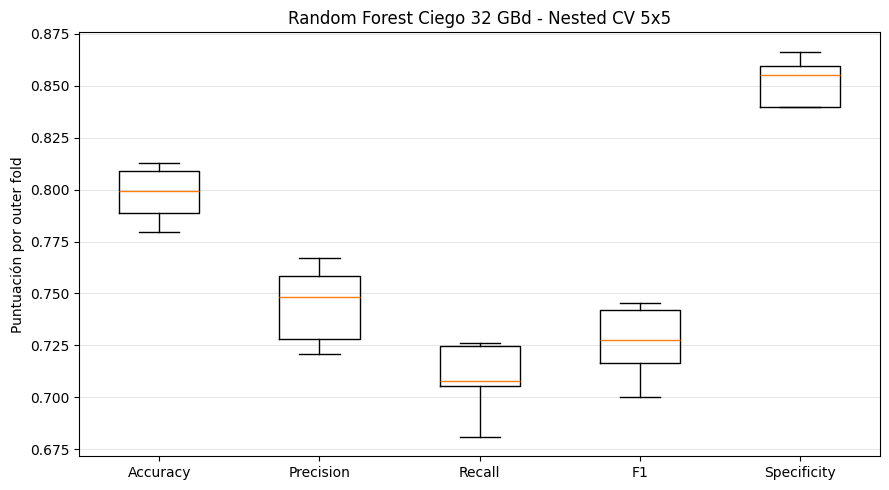


MÉTRICAS GLOBALES OUT-OF-FOLD (OOF)
OOF Accuracy:    0.7981
OOF Precision:   0.7445
OOF Recall:      0.7090
OOF F1:          0.7263
OOF Specificity: 0.8522

CLASSIFICATION REPORT OOF:
              precision    recall  f1-score   support

      NORMAL       0.83      0.85      0.84      5804
      ALARMA       0.74      0.71      0.73      3526

    accuracy                           0.80      9330
   macro avg       0.79      0.78      0.78      9330
weighted avg       0.80      0.80      0.80      9330


Matriz de confusión OOF:
[[4946  858]
 [1026 2500]]


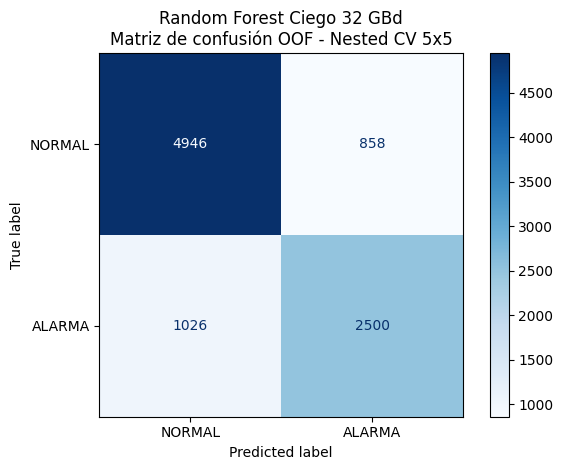


Predicciones OOF guardadas.

HIPERPARÁMETROS POR OUTER FOLD
 fold  max_depth max_features  min_samples_leaf  min_samples_split  n_estimators  inner_cv_best_f1
    1        NaN         sqrt                 1                  2           200          0.734196
    2       20.0         log2                 1                  5           200          0.726007
    3       20.0         sqrt                 2                 10           100          0.724805
    4        NaN         log2                 1                  5           100          0.726377
    5       20.0         log2                 1                 10           400          0.731174

TIEMPO DE INFERENCIA - OUTER CV
Inference Mean: 15.127 µs/muestra
Inference Std:  8.073 µs/muestra
Mediciones totales: 500
Tiempo por muestra dentro de un batch. Incluye RandomForest.predict().

ENTRENANDO MODELO FINAL - RF CIEGO

Mejores parámetros modelo final:
{'max_depth': None, 'max_features': 'log2', 'min_samples_leaf': 1, 'min_samples_

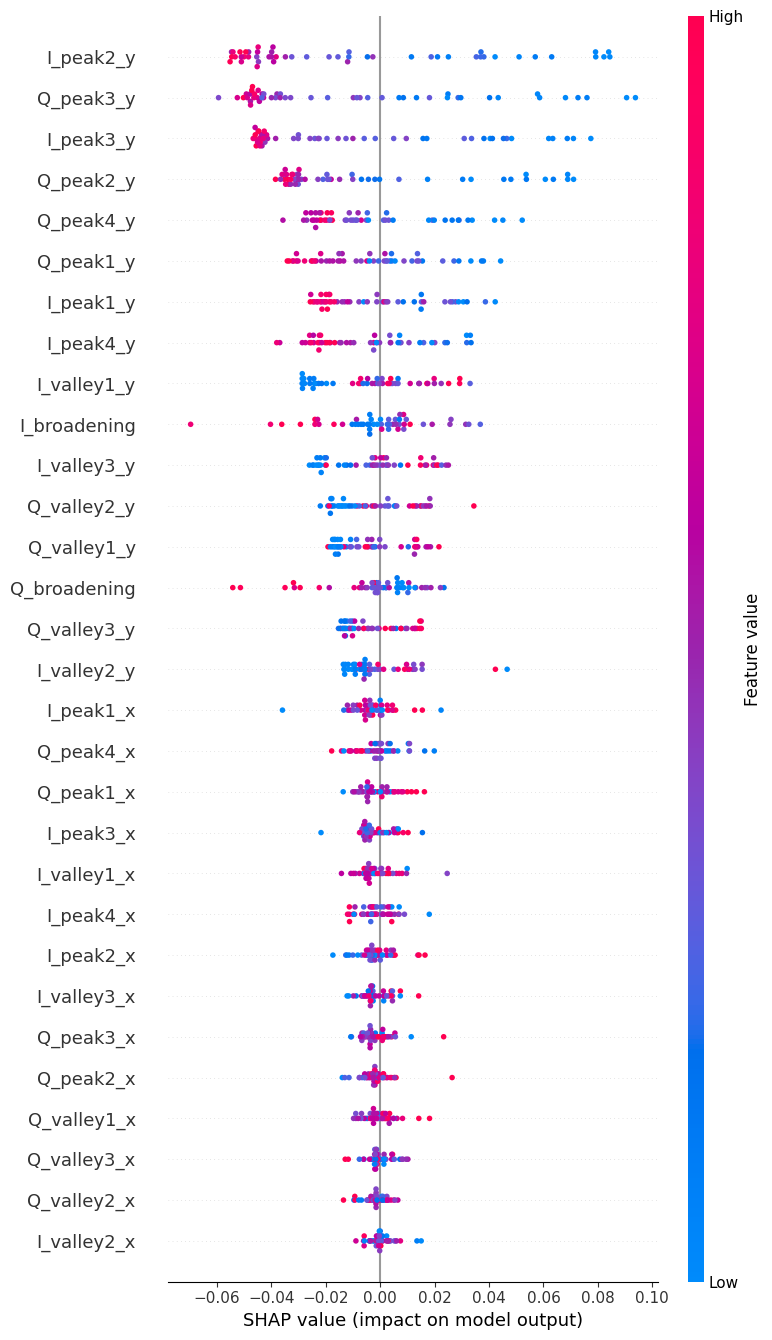

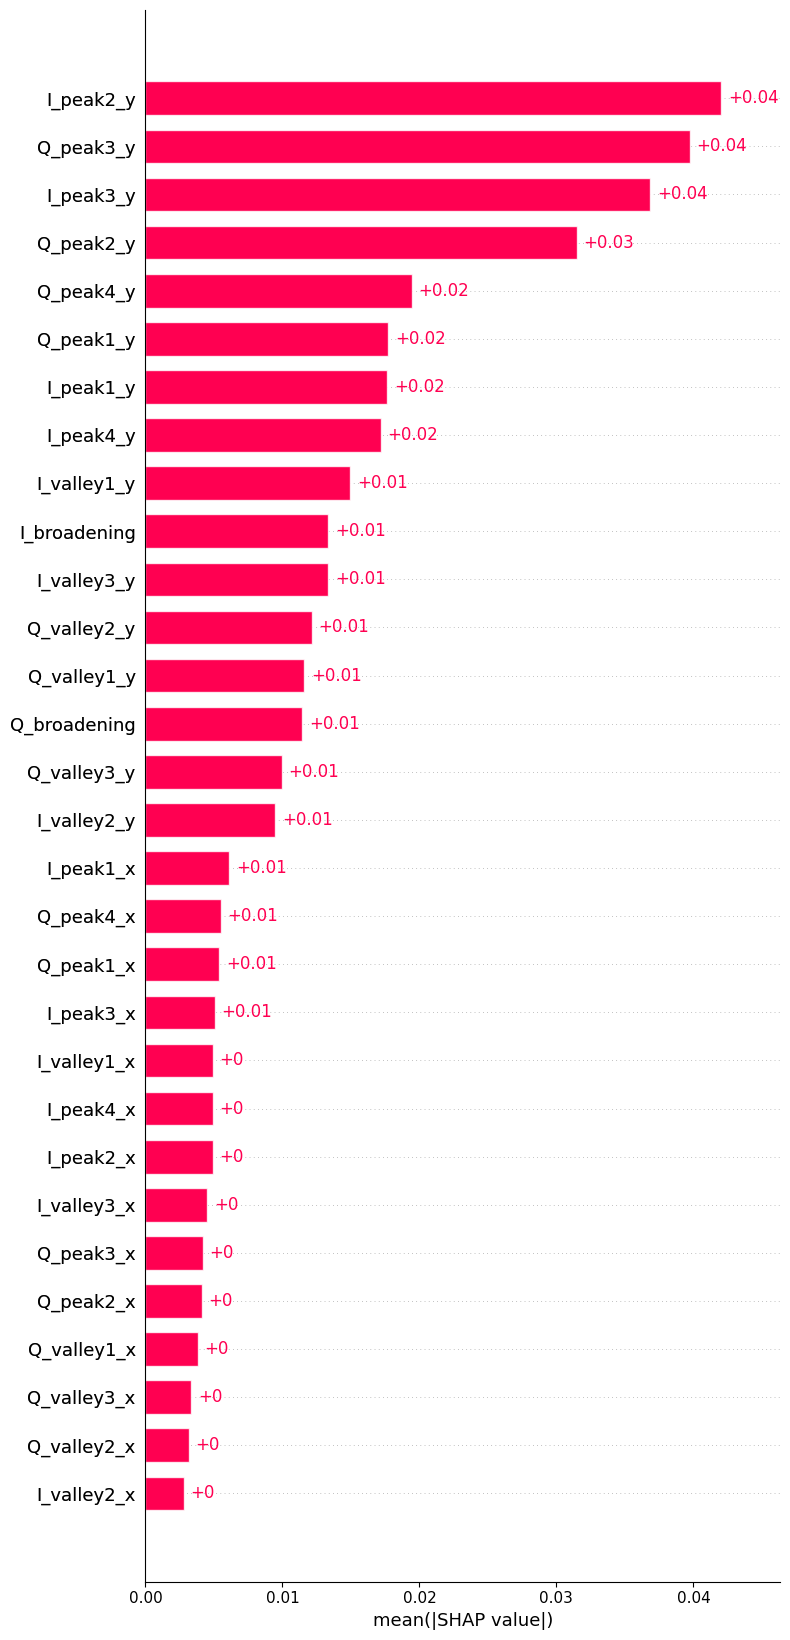

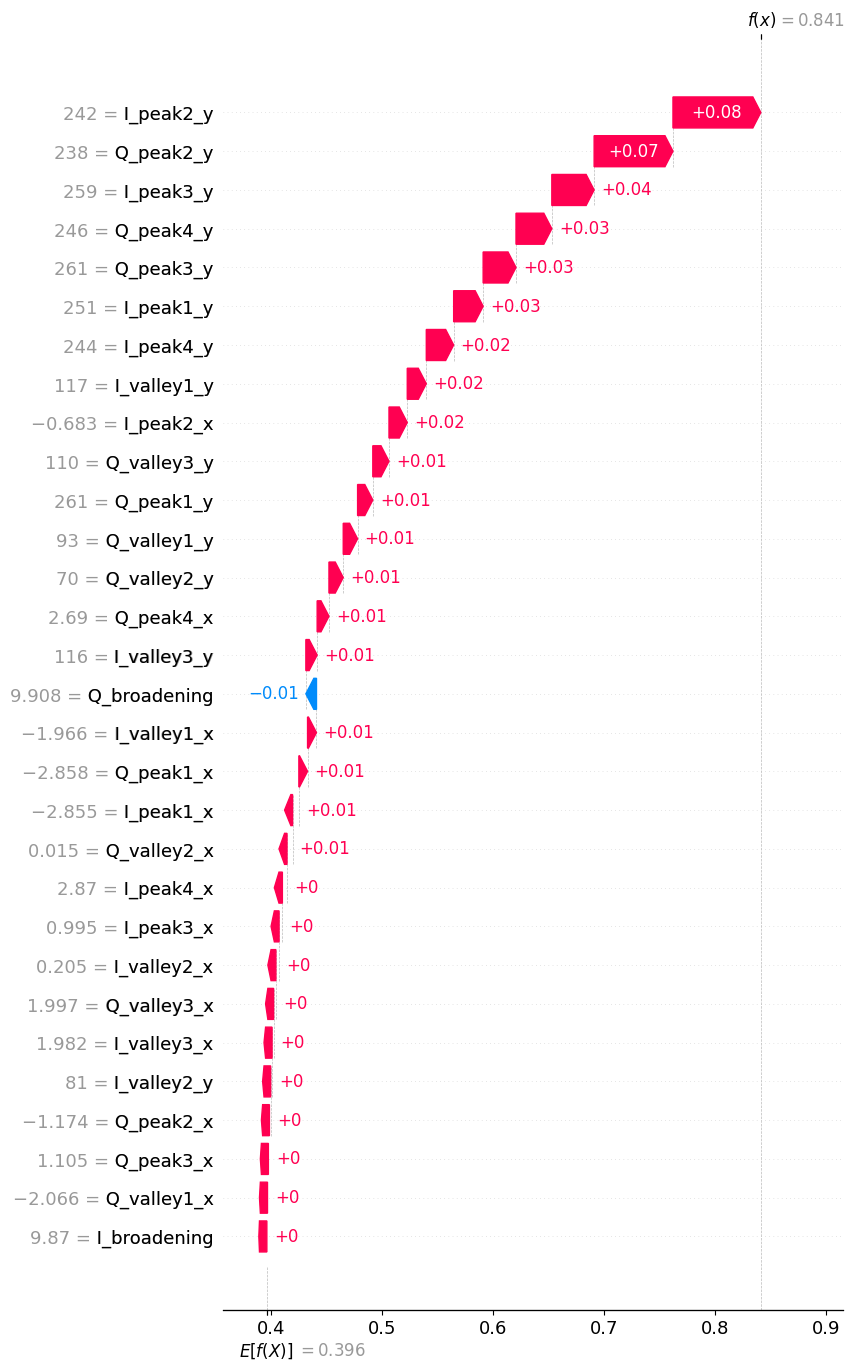


RESUMEN FINAL - RF CIEGO 32 GBd NESTED CV 5x5
Outer CV ACCURACY    : 0.7981 ± 0.0124
Outer CV PRECISION   : 0.7445 ± 0.0177
Outer CV RECALL      : 0.7090 ± 0.0165
Outer CV F1          : 0.7263 ± 0.0167
Outer CV SPECIFICITY : 0.8522 ± 0.0108

OOF Accuracy: 0.7981
OOF Precision: 0.7445
OOF Recall: 0.7090
OOF F1: 0.7263
OOF Specificity: 0.8522

Inference Mean: 15.127 µs/muestra
Inference Std: 8.073 µs/muestra

Archivos generados:
1. rf_osnr_32GBd_ciego_nested_outer_folds.csv
2. rf_osnr_32GBd_ciego_nested_oof_predictions.csv
3. rf_osnr_32GBd_ciego_nested_best_params.csv
4. rf_osnr_32GBd_ciego_nested_importancia_shap.csv

PROCESO COMPLETADO.


In [ ]:

"""
============================================================
CLASIFICACIÓN CIEGA OSNR 32 GBd - RANDOM FOREST
NESTED CROSS-VALIDATION 5x5 + PREDICCIONES OUTER-FOLD
MÉTRICAS, MATRIZ DE CONFUSIÓN, SHAP Y TIEMPO DE INFERENCIA
============================================================

CLASES:
    0 = NORMAL: OSNR > 23 dB
    1 = ALARMA: OSNR <= 23 dB

DATASET:
    30 características I/Q
    1 columna channel_sp (EXCLUIDA DEL MODELO)
    1 columna OSNR (target continuo)

MONITOREO CIEGO:
    - No se utiliza channel_sp como entrada.
    - Se utilizan exclusivamente las 30 características I/Q.
    - OSNR se utiliza para construir las etiquetas.

METODOLOGÍA:
    - Outer CV: StratifiedKFold, 5 folds
    - Inner CV: StratifiedKFold, 5 folds
    - GridSearchCV dentro de cada outer train
    - Predicciones OOF en los outer tests
    - Métricas por fold y métricas globales OOF
    - Tiempos de inferencia por outer fold
    - Modelo final entrenado con todos los datos
    - SHAP mediante TreeExplainer

IMPORTANTE:
    Esta implementación divide por filas.
    Si existen muestras del mismo escenario experimental,
    conviene considerar Nested CV agrupada por escenario.
"""

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap

from sklearn.model_selection import (
    StratifiedKFold,
    GridSearchCV
)

from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

# ============================================================
# 1. CONFIGURACIÓN GENERAL
# ============================================================

CSV_PATH = "matriz32GBd_clasifi_correct.csv"

THRESHOLD_DB = 23.0

SEED = 42

N_OUTER_FOLDS = 5
N_INNER_FOLDS = 5

N_REPETITIONS = 100

SHAP_BACKGROUND = 50
SHAP_EXPLAIN = 50

# ============================================================
# 2. NOMBRES DE LAS 30 CARACTERÍSTICAS
# ============================================================

# MONITOREO CIEGO:
# No se incluye "channel_sp" entre las características.

feature_names = (
    [f"I_peak{k}_x" for k in range(1, 5)] +
    [f"I_peak{k}_y" for k in range(1, 5)] +
    [f"Q_peak{k}_x" for k in range(1, 5)] +
    [f"Q_peak{k}_y" for k in range(1, 5)] +
    [f"I_valley{k}_x" for k in range(1, 4)] +
    [f"I_valley{k}_y" for k in range(1, 4)] +
    [f"Q_valley{k}_x" for k in range(1, 4)] +
    [f"Q_valley{k}_y" for k in range(1, 4)] +
    ["I_broadening", "Q_broadening"]
)

assert len(feature_names) == 30

# ============================================================
# 3. CARGAR Y VALIDAR DATASET
# ============================================================

matriz = pd.read_csv(
    CSV_PATH,
    header=None
)

# La matriz original tiene 32 columnas:
# 30 características I/Q + channel_sp + OSNR.

if matriz.shape[1] != 32:
    raise ValueError(
        f"Se esperaban 32 columnas; "
        f"se encontraron {matriz.shape[1]}"
    )

matriz = matriz.apply(
    pd.to_numeric,
    errors="raise"
)

if not np.isfinite(matriz.to_numpy()).all():
    raise ValueError(
        "El dataset contiene NaN o infinitos."
    )

# ------------------------------------------------------------
# 3.1 SELECCIÓN DE CARACTERÍSTICAS PARA MONITOREO CIEGO
# ------------------------------------------------------------

# Se utilizan únicamente las primeras 30 columnas.
# La columna 30 (channel_sp) queda excluida.
X = matriz.iloc[:, :30].copy()

X.columns = feature_names

# La última columna contiene el OSNR continuo.
y_osnr = matriz.iloc[:, 31].to_numpy()

# Clasificación binaria:
# NORMAL = 0, si OSNR > 23 dB
# ALARMA = 1, si OSNR <= 23 dB
y = (y_osnr <= THRESHOLD_DB).astype(int)

n_samples = len(y)

class_counts = np.bincount(
    y,
    minlength=2
)

if class_counts.min() < N_OUTER_FOLDS:
    raise ValueError(
        "No hay suficientes muestras por clase "
        "para los folds externos."
    )

print("=" * 65)
print("INFORMACIÓN DEL DATASET")
print("=" * 65)

print(f"Dataset: {CSV_PATH}")
print(f"Muestras: {n_samples}")
print(f"Características utilizadas: {X.shape[1]}")
print(f"NORMAL: {class_counts[0]}")
print(f"ALARMA: {class_counts[1]}")
print(f"Umbral OSNR: {THRESHOLD_DB} dB")

print(
    "\nMONITOREO CIEGO: "
    "channel_sp NO se utiliza como entrada."
)

print("\nCaracterísticas utilizadas:")

for i, feature in enumerate(feature_names, start=1):
    print(f"{i:2d}. {feature}")

# ============================================================
# 4. DEFINIR RANDOM FOREST Y GRID
# ============================================================

def build_model():
    """
    Construye un Random Forest nuevo.

    Random Forest no necesita StandardScaler,
    porque sus árboles realizan divisiones
    basadas en umbrales de las características.

    n_jobs=1 evita paralelismo interno del RF
    mientras GridSearchCV utiliza n_jobs=-1.
    """

    return RandomForestClassifier(
        random_state=SEED,
        n_jobs=1
    )


# Se conserva exactamente el grid original.

param_grid = {
    "n_estimators": [100, 200, 400],
    "max_depth": [None, 10, 20],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4],
    "max_features": ["sqrt", "log2"]
}

n_combinations = (
    len(param_grid["n_estimators"]) *
    len(param_grid["max_depth"]) *
    len(param_grid["min_samples_split"]) *
    len(param_grid["min_samples_leaf"]) *
    len(param_grid["max_features"])
)

print("\nCombinaciones de hiperparámetros:", n_combinations)

# ============================================================
# 5. CONFIGURAR OUTER CROSS-VALIDATION
# ============================================================

outer_cv = StratifiedKFold(
    n_splits=N_OUTER_FOLDS,
    shuffle=True,
    random_state=SEED
)

# Cada muestra recibirá una predicción
# cuando pertenezca al test de un outer fold.

oof_predictions = np.full(
    n_samples,
    -1,
    dtype=int
)

# Probabilidad de ALARMA para cada muestra OOF.
oof_probabilities = np.full(
    n_samples,
    np.nan,
    dtype=float
)

# Identificador del outer fold.
oof_fold = np.full(
    n_samples,
    -1,
    dtype=int
)

outer_results = []
outer_best_params = []
outer_inference_times = []

print("\n" + "=" * 65)
print("INICIANDO NESTED CV 5x5 - RF CIEGO 32 GBd")
print("=" * 65)

# ============================================================
# 6. BUCLE PRINCIPAL: OUTER CROSS-VALIDATION
# ============================================================

for fold, (train_idx, test_idx) in enumerate(
    outer_cv.split(X, y),
    start=1
):

    print("\n" + "=" * 65)
    print(f"OUTER FOLD {fold}/{N_OUTER_FOLDS}")
    print("=" * 65)

    # --------------------------------------------------------
    # 6.1 SEPARACIÓN EXTERNA
    # --------------------------------------------------------

    X_outer_train = X.iloc[train_idx]
    X_outer_test = X.iloc[test_idx]

    y_outer_train = y[train_idx]
    y_outer_test = y[test_idx]

    print(
        f"Outer Train: {len(X_outer_train)} muestras"
    )

    print(
        f"Outer Test:  {len(X_outer_test)} muestras"
    )

    # --------------------------------------------------------
    # 6.2 INNER CV: GRIDSEARCHCV
    # --------------------------------------------------------

    # Cada outer fold tiene su propia validación interna.
    inner_cv = StratifiedKFold(
        n_splits=N_INNER_FOLDS,
        shuffle=True,
        random_state=SEED + fold
    )

    search = GridSearchCV(
        estimator=build_model(),
        param_grid=param_grid,
        scoring="f1",
        cv=inner_cv,
        n_jobs=-1,
        refit=True,
        return_train_score=False
    )

    print("\nBuscando mejores hiperparámetros...")

    # El GridSearchCV recibe únicamente el outer train.
    # El outer test NO participa en la selección.
    search.fit(
        X_outer_train,
        y_outer_train
    )

    best_rf = search.best_estimator_

    print("\nMejores hiperparámetros:")
    print(search.best_params_)

    print(
        f"Inner CV Best F1: "
        f"{search.best_score_:.4f}"
    )

    outer_best_params.append({
        "fold": fold,
        **search.best_params_,
        "inner_cv_best_f1": search.best_score_
    })

    # --------------------------------------------------------
    # 6.3 PREDICCIONES OUTER-FOLD
    # --------------------------------------------------------

    # Predicción de clase.
    y_outer_pred = best_rf.predict(
        X_outer_test
    )

    # Probabilidad de pertenecer a ALARMA (clase 1).
    y_outer_proba = best_rf.predict_proba(
        X_outer_test
    )[:, 1]

    # Guardar las predicciones en el orden original.
    oof_predictions[test_idx] = y_outer_pred

    oof_probabilities[test_idx] = y_outer_proba

    oof_fold[test_idx] = fold

    # --------------------------------------------------------
    # 6.4 MÉTRICAS DEL OUTER FOLD
    # --------------------------------------------------------

    tn, fp, fn, tp = confusion_matrix(
        y_outer_test,
        y_outer_pred,
        labels=[0, 1]
    ).ravel()

    accuracy = accuracy_score(
        y_outer_test,
        y_outer_pred
    )

    precision = precision_score(
        y_outer_test,
        y_outer_pred,
        zero_division=0
    )

    recall = recall_score(
        y_outer_test,
        y_outer_pred,
        zero_division=0
    )

    f1 = f1_score(
        y_outer_test,
        y_outer_pred,
        zero_division=0
    )

    specificity = (
        tn / (tn + fp)
        if (tn + fp) > 0
        else np.nan
    )

    # --------------------------------------------------------
    # 6.5 TIEMPO DE INFERENCIA
    # --------------------------------------------------------

    # Warm-up antes de medir.
    _ = best_rf.predict(
        X_outer_test.iloc[
            :min(10, len(X_outer_test))
        ]
    )

    inference_times = np.empty(
        N_REPETITIONS
    )

    for rep in range(N_REPETITIONS):

        start = time.perf_counter()

        _ = best_rf.predict(
            X_outer_test
        )

        elapsed = (
            time.perf_counter() - start
        )

        inference_times[rep] = (
            elapsed / len(X_outer_test)
        )

    inference_mean_us = (
        inference_times.mean() * 1e6
    )

    inference_std_us = (
        inference_times.std() * 1e6
    )

    outer_inference_times.append(
        inference_times * 1e6
    )

    # --------------------------------------------------------
    # 6.6 GUARDAR RESULTADOS DEL FOLD
    # --------------------------------------------------------

    outer_results.append({
        "fold": fold,
        "n_train": len(train_idx),
        "n_test": len(test_idx),
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "specificity": specificity,
        "inference_mean_us": inference_mean_us,
        "inference_std_us": inference_std_us
    })

    print("\nMÉTRICAS OUTER FOLD:")

    print(f"Accuracy:    {accuracy:.4f}")
    print(f"Precision:   {precision:.4f}")
    print(f"Recall:      {recall:.4f}")
    print(f"F1:          {f1:.4f}")
    print(f"Specificity: {specificity:.4f}")

    print(
        f"Inference Mean: "
        f"{inference_mean_us:.3f} µs/muestra"
    )

    print(
        f"Inference Std:  "
        f"{inference_std_us:.3f} µs/muestra"
    )

# ============================================================
# 7. VALIDAR PREDICCIONES OOF
# ============================================================

if np.any(oof_predictions == -1):
    raise RuntimeError(
        "Existen muestras sin predicción OOF."
    )

if np.any(oof_fold == -1):
    raise RuntimeError(
        "Existen muestras sin outer fold asignado."
    )

if not np.isfinite(oof_probabilities).all():
    raise RuntimeError(
        "Existen probabilidades OOF inválidas."
    )

print("\nTodas las muestras tienen predicción OOF.")

# ============================================================
# 8. RESULTADOS POR OUTER FOLD
# ============================================================

results_df = pd.DataFrame(
    outer_results
)

print("\n" + "=" * 65)
print("RESULTADOS DE LOS 5 OUTER FOLDS")
print("=" * 65)

print(
    results_df.to_string(index=False)
)

results_df.to_csv(
    "rf_osnr_32GBd_ciego_nested_outer_folds.csv",
    index=False
)

# ============================================================
# 9. PROMEDIO ± DESVIACIÓN ESTÁNDAR OUTER CV
# ============================================================

print("\n" + "=" * 65)
print("OUTER CV - PROMEDIO ± DESVIACIÓN ESTÁNDAR")
print("=" * 65)

metrics = [
    "accuracy",
    "precision",
    "recall",
    "f1",
    "specificity"
]

for metric in metrics:

    values = results_df[
        metric
    ].to_numpy()

    print(
        f"{metric.upper():12s}: "
        f"{np.nanmean(values):.4f} ± "
        f"{np.nanstd(values):.4f}"
    )

# ============================================================
# 10. GRÁFICA DE MÉTRICAS OUTER CV
# ============================================================

plt.figure(figsize=(9, 5))

plt.boxplot(
    [
        results_df[m].values
        for m in metrics
    ],
    tick_labels=[
        "Accuracy",
        "Precision",
        "Recall",
        "F1",
        "Specificity"
    ]
)

plt.ylabel("Puntuación por outer fold")

plt.title(
    "Random Forest Ciego 32 GBd - Nested CV 5x5"
)

plt.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()
plt.show()
plt.close()

# ============================================================
# 11. MÉTRICAS GLOBALES OOF
# ============================================================

print("\n" + "=" * 65)
print("MÉTRICAS GLOBALES OUT-OF-FOLD (OOF)")
print("=" * 65)

tn, fp, fn, tp = confusion_matrix(
    y,
    oof_predictions,
    labels=[0, 1]
).ravel()

oof_accuracy = accuracy_score(
    y,
    oof_predictions
)

oof_precision = precision_score(
    y,
    oof_predictions,
    zero_division=0
)

oof_recall = recall_score(
    y,
    oof_predictions,
    zero_division=0
)

oof_f1 = f1_score(
    y,
    oof_predictions,
    zero_division=0
)

oof_specificity = (
    tn / (tn + fp)
    if (tn + fp) > 0
    else np.nan
)

print(
    f"OOF Accuracy:    {oof_accuracy:.4f}"
)

print(
    f"OOF Precision:   {oof_precision:.4f}"
)

print(
    f"OOF Recall:      {oof_recall:.4f}"
)

print(
    f"OOF F1:          {oof_f1:.4f}"
)

print(
    f"OOF Specificity: {oof_specificity:.4f}"
)

print("\nCLASSIFICATION REPORT OOF:")

print(
    classification_report(
        y,
        oof_predictions,
        labels=[0, 1],
        target_names=[
            "NORMAL",
            "ALARMA"
        ],
        zero_division=0
    )
)

# ============================================================
# 12. MATRIZ DE CONFUSIÓN OOF
# ============================================================

cm_oof = confusion_matrix(
    y,
    oof_predictions,
    labels=[0, 1]
)

print("\nMatriz de confusión OOF:")

print(cm_oof)

ConfusionMatrixDisplay(
    confusion_matrix=cm_oof,
    display_labels=[
        "NORMAL",
        "ALARMA"
    ]
).plot(
    cmap="Blues",
    values_format="d"
)

plt.title(
    "Random Forest Ciego 32 GBd\n"
    "Matriz de confusión OOF - Nested CV 5x5"
)

plt.tight_layout()
plt.show()
plt.close()

# ============================================================
# 13. GUARDAR PREDICCIONES OOF
# ============================================================

oof_df = pd.DataFrame({
    "sample_index": np.arange(n_samples),
    "outer_fold": oof_fold,
    "OSNR_dB": y_osnr,
    "true_class": y,
    "predicted_class": oof_predictions,
    "probability_alarm": oof_probabilities,
    "correct": (
        y == oof_predictions
    )
})

oof_df.to_csv(
    "rf_osnr_32GBd_ciego_nested_oof_predictions.csv",
    index=False
)

print("\nPredicciones OOF guardadas.")

# ============================================================
# 14. HIPERPARÁMETROS POR OUTER FOLD
# ============================================================

params_df = pd.DataFrame(
    outer_best_params
)

print("\n" + "=" * 65)
print("HIPERPARÁMETROS POR OUTER FOLD")
print("=" * 65)

print(
    params_df.to_string(index=False)
)

params_df.to_csv(
    "rf_osnr_32GBd_ciego_nested_best_params.csv",
    index=False
)

# ============================================================
# 15. TIEMPO DE INFERENCIA OUTER CV
# ============================================================

all_inference_times = np.concatenate(
    outer_inference_times
)

print("\n" + "=" * 65)
print("TIEMPO DE INFERENCIA - OUTER CV")
print("=" * 65)

print(
    f"Inference Mean: "
    f"{all_inference_times.mean():.3f} µs/muestra"
)

print(
    f"Inference Std:  "
    f"{all_inference_times.std():.3f} µs/muestra"
)

print(
    f"Mediciones totales: "
    f"{len(all_inference_times)}"
)

print(
    "Tiempo por muestra dentro de un batch. "
    "Incluye RandomForest.predict()."
)

# ============================================================
# 16. ENTRENAR MODELO FINAL CON TODOS LOS DATOS
# ============================================================

# Este modelo se utiliza para SHAP.
# NO se utiliza para calcular las métricas OOF.
#
# Se seleccionan nuevamente los hiperparámetros
# mediante GridSearchCV sobre todo el dataset.

print("\n" + "=" * 65)
print("ENTRENANDO MODELO FINAL - RF CIEGO")
print("=" * 65)

final_inner_cv = StratifiedKFold(
    n_splits=N_INNER_FOLDS,
    shuffle=True,
    random_state=SEED
)

final_search = GridSearchCV(
    estimator=build_model(),
    param_grid=param_grid,
    scoring="f1",
    cv=final_inner_cv,
    n_jobs=-1,
    refit=True
)

final_search.fit(X, y)

final_rf = final_search.best_estimator_

print("\nMejores parámetros modelo final:")
print(final_search.best_params_)

print(
    f"F1 GridSearch final: "
    f"{final_search.best_score_:.4f}"
)

# ============================================================
# 17. SHAP - TREEEXPLAINER
# ============================================================

# SHAP explica predict_proba[:, 1] del RF final.
#
# SHAP positivo:
#    aumenta la probabilidad de ALARMA.
#
# SHAP negativo:
#    disminuye la probabilidad de ALARMA.
#
# Las muestras explicadas pertenecen al dataset
# utilizado para entrenar el modelo final.
#
# Por tanto, este SHAP es descriptivo, NO OOF.
#
# MONITOREO CIEGO:
# SHAP considera únicamente las 30 características I/Q.
# channel_sp no participa en el cálculo.

print("\n" + "=" * 65)
print("CALCULANDO SHAP DEL MODELO FINAL")
print("=" * 65)

background = X.sample(
    n=min(SHAP_BACKGROUND, len(X)),
    random_state=SEED
)

explained = X.sample(
    n=min(SHAP_EXPLAIN, len(X)),
    random_state=SEED + 1
)

print(
    f"Background: {len(background)} muestras"
)

print(
    f"Muestras explicadas: {len(explained)}"
)

explainer = shap.TreeExplainer(
    final_rf,
    data=background,
    feature_perturbation="interventional",
    model_output="probability"
)

raw = explainer.shap_values(
    explained,
    check_additivity=False
)

# ============================================================
# 18. COMPATIBILIDAD CON DIFERENTES VERSIONES DE SHAP
# ============================================================

# SHAP puede devolver:
#
# 1. Lista:
#    [valores_clase_0, valores_clase_1]
#
# 2. Arreglo tridimensional:
#    (muestras, características, clases)
#
# Seleccionamos siempre la clase 1 = ALARMA.

if isinstance(raw, list):

    shap_values = np.asarray(
        raw[1]
    )

else:

    arr = np.asarray(raw)

    if (
        arr.ndim == 3
        and arr.shape[2] == 2
    ):

        shap_values = arr[:, :, 1]

    else:

        shap_values = arr

if shap_values.shape != explained.shape:
    raise ValueError(
        f"Forma SHAP inesperada: "
        f"{shap_values.shape}. "
        f"Se esperaba {explained.shape}."
    )

# Valor base correspondiente a ALARMA.
base = np.asarray(
    explainer.expected_value
)

base_alarm = float(
    base[1]
    if base.size == 2
    else base.item()
)

# ============================================================
# 19. IMPORTANCIA GLOBAL SHAP
# ============================================================

mean_abs = np.mean(
    np.abs(shap_values),
    axis=0
)

imp_df = pd.DataFrame({
    "feature": feature_names,
    "mean_abs_shap": mean_abs
})

imp_df = imp_df.sort_values(
    "mean_abs_shap",
    ascending=False
).reset_index(drop=True)

total = imp_df[
    "mean_abs_shap"
].sum()

if total > 0:

    imp_df["importance_percent"] = (
        100 *
        imp_df["mean_abs_shap"] /
        total
    )

else:

    imp_df["importance_percent"] = 0.0

print("\n30 CARACTERÍSTICAS ORDENADAS POR SHAP:")

print(
    imp_df.to_string(
        index=False,
        formatters={
            "mean_abs_shap": "{:.6f}".format,
            "importance_percent": "{:.2f}%".format
        }
    )
)

print(
    f"\nSuma de porcentajes: "
    f"{imp_df['importance_percent'].sum():.2f}%"
)

print("\nTOP 5 SHAP:")

print(
    imp_df.head(5).to_string(
        index=False
    )
)

imp_df.to_csv(
    "rf_osnr_32GBd_ciego_nested_importancia_shap.csv",
    index=False
)

# ============================================================
# 20. CREAR OBJETO SHAP EXPLANATION
# ============================================================

explanation = shap.Explanation(
    values=shap_values,
    base_values=np.full(
        len(explained),
        base_alarm
    ),
    data=explained.to_numpy(),
    feature_names=feature_names
)

# ============================================================
# 21. GRÁFICAS SHAP
# ============================================================

# Beeswarm
shap.plots.beeswarm(
    explanation,
    max_display=30,
    show=False
)

plt.tight_layout()
plt.show()
plt.close()

# Bar plot
shap.plots.bar(
    explanation,
    max_display=30,
    show=False
)

plt.tight_layout()
plt.show()
plt.close()

# Waterfall de la primera muestra explicada.
shap.plots.waterfall(
    explanation[0],
    max_display=30,
    show=False
)

plt.show()
plt.close()

# ============================================================
# 22. RESUMEN FINAL
# ============================================================

print("\n" + "=" * 65)
print("RESUMEN FINAL - RF CIEGO 32 GBd NESTED CV 5x5")
print("=" * 65)

for metric in metrics:

    values = results_df[
        metric
    ].to_numpy()

    print(
        f"Outer CV {metric.upper():12s}: "
        f"{np.nanmean(values):.4f} ± "
        f"{np.nanstd(values):.4f}"
    )

print(
    f"\nOOF Accuracy: "
    f"{oof_accuracy:.4f}"
)

print(
    f"OOF Precision: "
    f"{oof_precision:.4f}"
)

print(
    f"OOF Recall: "
    f"{oof_recall:.4f}"
)

print(
    f"OOF F1: "
    f"{oof_f1:.4f}"
)

print(
    f"OOF Specificity: "
    f"{oof_specificity:.4f}"
)

print(
    f"\nInference Mean: "
    f"{all_inference_times.mean():.3f} µs/muestra"
)

print(
    f"Inference Std: "
    f"{all_inference_times.std():.3f} µs/muestra"
)

print("\nArchivos generados:")

print("1. rf_osnr_32GBd_ciego_nested_outer_folds.csv")
print("2. rf_osnr_32GBd_ciego_nested_oof_predictions.csv")
print("3. rf_osnr_32GBd_ciego_nested_best_params.csv")
print("4. rf_osnr_32GBd_ciego_nested_importancia_shap.csv")

print("\nPROCESO COMPLETADO.")
